In [1]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
import hashlib, json, re, uuid
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, roc_auc_score

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")
COHORTS = {"GSE13213": (45, 15, 57), "GSE31210": (127, 20, 79),
           "GSE32863": (17, 22, 19), "GSE72094": (47, 154, 241)}
CLASSES = ("EGFR", "KRAS", "DWT")
MODELS = ("q_anchor", "q_static", "q_residual", "CORDIB_INTERACTIONS_OFF",
          "D_ONLY_6", "GENERIC_CONDITIONAL_6", "AFFINE_STACK_6",
          "ANCHOR_NONLINEAR_6", "TEMP_EQUAL_MEAN")
EXPECTED_28 = ("EQUAL_COHORT_MODEL_METRICS.csv", "PER_COHORT_MODEL_METRICS.csv",
               "PAIRED_NLL_COMPARISONS.csv", "PER_COHORT_PAIRED_COMPARISONS.csv",
               "MODEL_PREDICTIONS.csv", "FITTED_CONTROL_PARAMETERS.json",
               "AUDIT_PROTOCOL.json", "RUN_MANIFEST.json")
EXACT = {
    14: ROOT / "14_quantile_residual_transfer" / "20261023T160742Z_f9435239",
    28: ROOT / "28_matched_mechanism_comparison" / "20261024T062048Z_81cc728e"
}
HASH_LIMIT = 512 * 1024**2
TABLE_LIMIT = 128 * 1024**2
checks, schemas, predictions, aligned, metrics, npz_audit, inventory = [], [], [], [], [], [], []

def record(scope, status, detail):
    checks.append({"scope": scope, "status": status, "detail": str(detail)[:2000]})

def namekey(x):
    return re.sub(r"[^a-z0-9]", "", str(x).lower())

def field(df, *choices):
    by_key = defaultdict(list)
    for c in df.columns:
        by_key[namekey(c)].append(c)
    for alias in choices:
        matches = by_key.get(namekey(alias), [])
        if len(matches) == 1:
            return matches[0]
    return None

def sha256(path):
    dig = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(4 * 1024**2), b""):
            dig.update(block)
    return dig.hexdigest()

def label_name(value):
    if pd.isna(value):
        return None
    k = namekey(value)
    if k in {"egfr", "egfrmut", "egfrmutant", "mutegfr"}:
        return "EGFR"
    if k in {"kras", "krasmut", "krasmutant", "mutkras"}:
        return "KRAS"
    if k in {"dwt", "doublewt", "doublewildtype", "egfrkraswt", "wildtype", "wt"}:
        return "DWT"
    return None

def prob_fields(df, class_order):
    named = {
        "EGFR": field(df, "p_egfr", "prob_egfr", "proba_egfr", "egfr_prob", "egfr_probability", "p_egfr_mutant", "p_e"),
        "KRAS": field(df, "p_kras", "prob_kras", "proba_kras", "kras_prob", "kras_probability", "p_kras_mutant", "p_k"),
        "DWT": field(df, "p_dwt", "prob_dwt", "proba_dwt", "dwt_prob", "dwt_probability", "p_w", "p_wt")
    }
    if all(named.values()) and len(set(named.values())) == 3:
        return [named[c] for c in CLASSES], "named"
    generic = [field(df, f"p{i}", f"p_{i}", f"prob{i}", f"prob_{i}", f"proba{i}", f"probability{i}") for i in range(3)]
    if all(generic) and len(set(generic)) == 3:
        if class_order is None:
            return generic, "unmapped_numeric"
        return [generic[class_order.index(c)] for c in CLASSES], "protocol_mapped"
    return None, "missing"

def decode_labels(series, class_order):
    out = series.map(label_name)
    if out.notna().all():
        return out
    if class_order is not None:
        numeric = pd.to_numeric(series, errors="coerce")
        if numeric.notna().all() and numeric.isin([0, 1, 2]).all():
            return numeric.astype(int).map(dict(enumerate(class_order)))
    return None

def find_class_order(data):
    hits = []
    def walk(obj, depth=0):
        if depth > 8 or len(hits) > 20:
            return
        if isinstance(obj, dict):
            for k, v in obj.items():
                key = namekey(k)
                if key in {"classorder", "classes", "classlabels", "labelorder", "classnames"} and isinstance(v, list) and len(v) == 3:
                    seq = [label_name(t) for t in v]
                    if set(seq) == set(CLASSES):
                        hits.append(tuple(seq))
                if key in {"classtoindex", "labeltoindex"} and isinstance(v, dict):
                    pairs = {label_name(k2): v2 for k2, v2 in v.items()}
                    if set(pairs) == set(CLASSES) and set(pairs.values()) == {0, 1, 2}:
                        hits.append(tuple(next(k2 for k2, v2 in pairs.items() if v2 == i) for i in range(3)))
                if isinstance(v, (dict, list)):
                    walk(v, depth + 1)
        elif isinstance(obj, list):
            for value in obj[:30]:
                walk(value, depth + 1)
    walk(data)
    return set(hits)

def load_table(path, scope):
    if not path.is_file():
        return None
    if path.stat().st_size > TABLE_LIMIT:
        record(scope, "WARNING", "CSV exceeds configured read limit")
        return None
    try:
        df = pd.read_csv(path, low_memory=False)
        schemas.append({"path": str(path), "rows": len(df), "columns": json.dumps(list(df.columns), ensure_ascii=False)})
        return df
    except Exception as exc:
        record(scope, "FAIL", f"CSV unreadable: {type(exc).__name__}: {exc}")
        return None

if not ROOT.is_dir():
    raise FileNotFoundError(f"Project root not accessible on this computer: {ROOT}")
phase_pattern = re.compile(r"^(?:phase[_\s-]*)?(1[2-9]|2[0-8])(?:[_\s.-]|$)", re.I)
phase_roots = defaultdict(list)
for item in ROOT.iterdir():
    match = phase_pattern.match(item.name)
    if match and item.is_dir():
        phase_roots[int(match.group(1))].append(item)
record("phase_discovery", "PASS" if phase_roots else "FAIL", {k: [str(p) for p in v] for k, v in sorted(phase_roots.items())})
important_phases = {12, 14, 15, 16, 19, 20, 22, 23, 24, 25, 27, 28}
record("phase_coverage", "PASS" if important_phases.issubset(phase_roots) else "WARNING",
       f"Discovered={sorted(phase_roots)}; expected milestone roots not discovered={sorted(important_phases-set(phase_roots))}")

def select_run(phase, anchor):
    if EXACT[phase].is_dir():
        record(f"phase{phase}_primary", "PASS", str(EXACT[phase]))
        return EXACT[phase]
    candidates = sorted({p.parent for root in phase_roots[phase] for p in root.rglob(anchor) if p.is_file()})
    if len(candidates) == 1:
        record(f"phase{phase}_primary", "WARNING", f"Specified run absent; one candidate: {candidates[0]}")
        return candidates[0]
    record(f"phase{phase}_primary", "WARNING", f"Specified run absent; {len(candidates)} candidates: {candidates[:8]}")
    return None

run14 = select_run(14, "LOCO_PREDICTIONS.csv")
run28 = select_run(28, "MODEL_PREDICTIONS.csv")
for phase, roots in sorted(phase_roots.items()):
    for folder in roots:
        for p in folder.rglob("*"):
            if not p.is_file() or p.is_symlink():
                continue
            try:
                size = p.stat().st_size
                digest = sha256(p) if size <= HASH_LIMIT else None
                state = "HASHED" if digest is not None else "SKIPPED_LARGE"
                inventory.append({"phase": phase, "path": str(p), "bytes": size,
                                  "sha256": digest, "state": state})
            except Exception as exc:
                inventory.append({"phase": phase, "path": str(p), "bytes": None,
                                  "sha256": None, "state": f"ERROR:{type(exc).__name__}"})
record("input_integrity", "WARNING" if not inventory or any(r["state"] != "HASHED" for r in inventory) else "PASS",
       f"Files={len(inventory)}; SHA256={sum(r['state']=='HASHED' for r in inventory)}; unhashed/failed={sum(r['state']!='HASHED' for r in inventory)}")

if run14:
    phase14_csv = run14 / "LOCO_PREDICTIONS.csv"
    record("phase14_predictions", "PASS" if phase14_csv.is_file() else "FAIL", str(phase14_csv))
    phase14_data = load_table(phase14_csv, "phase14_csv")
    if phase14_data is not None:
        predictions.append(("phase14", phase14_data))
    expected_ck = [run14 / "checkpoints" / f"{c}_{m}.npz" for c in COHORTS for m in ("q_anchor", "q_static", "q_residual")]
    existing_ck = [p for p in expected_ck if p.is_file()]
    record("phase14_checkpoints", "PASS" if len(existing_ck)==len(expected_ck) else "WARNING",
           f"Documented checkpoints present={len(existing_ck)}/{len(expected_ck)}")
    for p in existing_ck:
        try:
            if p.stat().st_size > TABLE_LIMIT:
                raise ValueError("checkpoint exceeds audit read limit")
            with np.load(p, allow_pickle=False) as z:
                detail = {}
                for key in z.files:
                    arr = np.asarray(z[key])
                    finite = bool(np.isfinite(arr).all()) if arr.dtype.kind in "biufc" else None
                    detail[key] = {"shape": list(arr.shape), "dtype": str(arr.dtype), "finite": finite}
                    if finite is False:
                        raise ValueError(f"nonfinite numeric array: {key}")
            npz_audit.append({"path": str(p), "status": "PASS", "arrays": json.dumps(detail)})
        except Exception as exc:
            status = "WARNING" if "Object arrays cannot be loaded" in str(exc) or "exceeds audit read limit" in str(exc) else "FAIL"
            npz_audit.append({"path": str(p), "status": status, "arrays": f"{type(exc).__name__}: {exc}"})
    record("checkpoint_restore", "PASS" if len(existing_ck)==len(expected_ck) and all(r["status"]=="PASS" for r in npz_audit) else "WARNING",
           f"Restorable={sum(r['status']=='PASS' for r in npz_audit)}/{len(expected_ck)}; structural load only, not forward inference")
    oof = [run14 / "inner_oof" / f"{c}.npz" for c in COHORTS]
    record("phase14_inner_oof", "PASS" if all(p.is_file() for p in oof) else "WARNING",
           f"Present={sum(p.is_file() for p in oof)}/{len(oof)}")
    for p in oof:
        if not p.is_file():
            continue
        try:
            if p.stat().st_size > TABLE_LIMIT:
                raise ValueError("OOF NPZ exceeds audit read limit")
            with np.load(p, allow_pickle=False) as z:
                present = list(z.files)
                shapes = {k: list(z[k].shape) for k in present}
                bad = [k for k in present if z[k].dtype.kind in "biufc" and not np.isfinite(z[k]).all()]
            missing_keys = sorted(set(("rank_evidence", "oof_scores", "label", "source")) - set(present))
            status = "FAIL" if bad else ("WARNING" if missing_keys else "PASS")
            record("phase14_oof_arrays:"+p.name, status,
                   f"shapes={shapes}; missing documented keys={missing_keys}; nonfinite={bad}")
        except Exception as exc:
            status = "WARNING" if "Object arrays cannot be loaded" in str(exc) or "exceeds audit read limit" in str(exc) else "FAIL"
            record("phase14_oof_arrays:"+p.name, status, f"{type(exc).__name__}: {exc}")

source12 = [r["path"] for r in inventory if r["phase"] == 12 and any(
    token in r["path"].lower() for token in ("nested_oof", "outer_models", "calibrator"))]
record("phase12_model_artifacts", "PASS" if source12 else "WARNING",
       f"Matching Phase 12 artifact files={len(source12)}")

class_orders = set()
if run28:
    for filename in EXPECTED_28:
        p = run28 / filename
        record("phase28_file:" + filename, "PASS" if p.is_file() else "FAIL", str(p))
        if p.is_file() and p.suffix == ".csv":
            data = load_table(p, "phase28_csv:" + filename)
            if data is not None and filename == "MODEL_PREDICTIONS.csv":
                predictions.append(("phase28", data))
        elif p.is_file() and p.suffix == ".json":
            try:
                with p.open("r", encoding="utf-8") as handle:
                    obj = json.load(handle)
                class_orders |= find_class_order(obj)
                record("phase28_json:" + filename, "PASS", f"Parsed; root={type(obj).__name__}")
            except Exception as exc:
                record("phase28_json:" + filename, "FAIL", f"{type(exc).__name__}: {exc}")

class_order = next(iter(class_orders)) if len(class_orders) == 1 else None
record("class_mapping", "PASS" if class_order else "WARNING",
       f"Protocol-derived numeric encoding: {class_order}" if class_order else "No unique explicit numeric label order recovered; numeric labels not decoded")

for origin, df in predictions:
    model_col = field(df, "model", "model_name", "method")
    cohort_col = field(df, "cohort", "heldout_cohort", "test_cohort", "test_source", "target_cohort", "source", "study", "fold")
    label_col = field(df, "label", "true_label", "true_class", "y_true", "genotype", "mutation_state", "class_id", "y_encoded", "y", "target")
    id_col = field(df, "sample_id", "gsm", "gsm_id", "sample", "sampleid", "sample_index", "sample_key", "row_index", "row_id", "patient_id", "id")
    prob_cols, prob_mode = prob_fields(df, class_order)
    record(f"{origin}_schema", "PASS" if model_col and cohort_col and prob_cols else "WARNING",
           f"model={model_col}, cohort={cohort_col}, label={label_col}, sample={id_col}, probs={prob_cols}, probability_mode={prob_mode}")
    if not (model_col and cohort_col):
        continue
    data = df[df[cohort_col].astype(str).isin(COHORTS)].copy()
    if data.empty:
        record(f"{origin}_cohort_roster", "FAIL", "No recognized development cohort rows")
        continue
    observed_models = set(data[model_col].dropna().astype(str))
    if origin == "phase28":
        missing = sorted(set(MODELS) - observed_models)
        record("phase28_model_roster", "PASS" if not missing else "WARNING",
               f"Model names={sorted(observed_models)}; missing={missing}")
    if id_col:
        duplicates = int(data.duplicated([model_col, cohort_col, id_col]).sum())
        record(f"{origin}_within_model_id_duplicates", "PASS" if duplicates == 0 else "FAIL", f"Duplicates={duplicates}")
        if label_col:
            conflicting = int((data.groupby([cohort_col, id_col], dropna=False)[label_col].nunique(dropna=False) > 1).sum())
            record(f"{origin}_label_consistency", "PASS" if conflicting == 0 else "FAIL", f"Conflicting labels={conflicting}")
        if origin == "phase28" and "q_residual" in observed_models:
            for c in COHORTS:
                ref = data[(data[model_col]=="q_residual") & (data[cohort_col]==c)]
                ref_ids = ref[id_col].astype(str).tolist()
                for m in MODELS:
                    subset = data[(data[model_col]==m) & (data[cohort_col]==c)]
                    cur_ids = subset[id_col].astype(str).tolist()
                    status = "PASS" if ref_ids == cur_ids else ("WARNING" if Counter(ref_ids)==Counter(cur_ids) else "FAIL")
                    if status != "PASS":
                        aligned.append({"cohort": c, "model": m, "status": status,
                                        "reference_n": len(ref_ids), "model_n": len(cur_ids)})
            record("phase28_sample_alignment", "PASS" if not aligned else ("FAIL" if any(r["status"] == "FAIL" for r in aligned) else "WARNING"),
                   f"Nonidentical saved sample order/set for {len(aligned)} model-cohort pairs")
    else:
        record(f"{origin}_sample_identity", "WARNING", "No sample ID column; duplicate and cross-model order checks unavailable")
    if not prob_cols:
        continue
    matrix = data[prob_cols].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
    valid = (np.isfinite(matrix).all(axis=1) & (matrix >= -1e-8).all(axis=1) &
             (matrix <= 1+1e-8).all(axis=1) & (np.abs(matrix.sum(axis=1)-1) < 1e-6))
    record(f"{origin}_probabilities", "PASS" if valid.all() else "FAIL",
           f"Validated={int(valid.sum())}/{len(valid)}; {prob_mode}")
    if not valid.all() or label_col is None or prob_mode == "unmapped_numeric":
        continue
    label = decode_labels(data[label_col], class_order)
    if label is None:
        record(f"{origin}_label_validation", "WARNING", "Labels cannot be explicitly decoded; full class-count and metric checks withheld")
        continue
    if data[label_col].map(namekey).isin({"wt", "wildtype"}).any():
        record(f"{origin}_WT_semantics", "WARNING",
               "WT interpreted as DWT for numeric reconstruction only; both-gene testing requires Phase 29B provenance")
    data = data.assign(_validated_label=label.to_numpy())
    primary = data[data[model_col].astype(str) == "q_residual"]
    if len(primary):
        for cohort, expected in COHORTS.items():
            cut = primary[primary[cohort_col]==cohort]
            counts = tuple(int((cut._validated_label==cl).sum()) for cl in CLASSES)
            status = "PASS" if counts == expected and len(cut) == sum(expected) else "FAIL"
            record(f"{origin}_roster:{cohort}", status,
                   f"N={len(cut)}, EGFR/KRAS/DWT={counts}; expected={expected}")
        record(f"{origin}_development_total", "PASS" if len(primary)==843 else "FAIL", f"N={len(primary)}, expected=843")
        if id_col:
            repeated = int(primary.duplicated([cohort_col,id_col]).sum())
            record(f"{origin}_primary_unique_ids", "PASS" if repeated == 0 else "FAIL", f"Repeated sample IDs={repeated}")
            cross = (primary.groupby(id_col)[cohort_col].nunique() > 1).sum()
            record(f"{origin}_cross_cohort_gsm", "PASS" if cross==0 else "WARNING", f"IDs reused across cohorts={int(cross)}; patient-level matching requires provenance audit")
    for (model, cohort), sub in data.groupby([model_col,cohort_col], sort=False):
        if cohort not in COHORTS or set(sub._validated_label) != set(CLASSES):
            continue
        local_p = sub[prob_cols].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
        y = sub._validated_label.map({c:i for i,c in enumerate(CLASSES)}).to_numpy(dtype=int)
        nll = float(-np.log(np.clip(local_p[np.arange(len(y)),y], 1e-15, 1)).mean())
        f1 = float(f1_score(y, local_p.argmax(axis=1), labels=[0,1,2], average="macro", zero_division=0))
        auc = float(roc_auc_score(y, local_p, multi_class="ovr", labels=[0,1,2], average="macro"))
        brier = float(np.mean(np.sum((local_p-np.eye(3)[y])**2, axis=1)))
        metrics.append({"origin": origin, "model": str(model), "cohort": str(cohort),
                        "n": len(sub), "nll": nll, "macro_f1": f1, "macro_ovr_auroc": auc, "brier": brier})

if run28 and metrics:
    archive = load_table(run28 / "EQUAL_COHORT_MODEL_METRICS.csv", "phase28_metrics_reference")
    rec = pd.DataFrame([x for x in metrics if x["origin"]=="phase28"])
    if not rec.empty:
        means = rec.groupby("model", as_index=False)[["nll","macro_f1","macro_ovr_auroc","brier"]].mean()
        if archive is not None:
            model_col = field(archive, "model", "model_name", "method")
            match_aliases = {"nll": ("nll", "mean_nll", "equal_cohort_nll"),
                             "macro_f1": ("macro_f1", "mean_macro_f1", "f1_macro"),
                             "macro_ovr_auroc": ("macro_ovr_auroc", "macro_ovr_auc", "macro_auroc", "mean_macro_ovr_auroc", "auroc_macro_ovr"),
                             "brier": ("brier", "brier_score", "mean_brier")}
            comparable = 0
            bad = []
            if model_col:
                for _, row in means.iterrows():
                    rows = archive[archive[model_col].astype(str) == row["model"]]
                    if len(rows) != 1:
                        continue
                    for k, aliases in match_aliases.items():
                        col = field(archive, *aliases)
                        if col is not None:
                            val = pd.to_numeric(rows.iloc[0][col], errors="coerce")
                            if pd.notna(val):
                                comparable += 1
                                if abs(float(val)-float(row[k])) > 5e-4:
                                    bad.append(f"{row['model']}:{k} expected={val}, reproduced={row[k]:.6f}")
            complete = len(rec) == len(MODELS) * len(COHORTS) and comparable >= len(MODELS) * 4
            record("phase28_metric_reproduction", "FAIL" if bad else ("PASS" if complete else "WARNING"),
                   f"Compared={comparable}; cohort/model rows={len(rec)}; discrepant={len(bad)}; examples={bad[:6]}")
        if archive is None:
            record("phase28_metric_reproduction", "WARNING", "Archived equal-cohort metrics unavailable")
        for _, r in means.iterrows():
            metrics.append({"origin": "phase28_equal_cohort_recomputed", "model": r["model"],
                            "cohort": "EQUAL_COHORT_MEAN", "n": 843,
                            **{k: float(r[k]) for k in ["nll","macro_f1","macro_ovr_auroc","brier"]}})
else:
    record("phase28_metric_reproduction", "WARNING", "Saved predictions and unambiguous label/probability metadata required")

ext_candidates = []
for phase in (23, 24, 25, 27):
    ext_candidates.extend(Path(r["path"]) for r in inventory
                          if r["phase"]==phase and r["path"].lower().endswith((".csv", ".tsv"))
                          and any(s in r["path"].lower() for s in ("gse66863", "external", "locked")))
ext_validated = 0
for p in sorted(set(ext_candidates), key=str)[:40]:
    try:
        if p.stat().st_size > TABLE_LIMIT:
            continue
        ext = pd.read_csv(p, sep="\t" if p.suffix.lower()==".tsv" else ",", low_memory=False)
        id_col = field(ext, "sample_id", "gsm", "gsm_id", "sample", "sampleid", "sample_index", "sample_key", "row_index", "id")
        model_col = field(ext, "model", "model_name")
        cohort_col = field(ext, "cohort", "study", "source")
        if cohort_col:
            ext = ext[ext[cohort_col].astype(str)=="GSE66863"]
        if model_col and (ext[model_col].astype(str)=="q_residual").any():
            ext = ext[ext[model_col].astype(str)=="q_residual"]
        if id_col and len(ext):
            count = ext[id_col].nunique(dropna=False)
            if count == 114 and len(ext)==114:
                ext_validated += 1
                record("external_roster:"+p.name, "PASS", f"114 unique IDs in {p}")
                ext_prob_cols, _ = prob_fields(ext, class_order)
                if ext_prob_cols:
                    ep = ext[ext_prob_cols].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
                    good = (np.isfinite(ep).all(axis=1) & (ep >= -1e-8).all(axis=1) &
                            (ep <= 1+1e-8).all(axis=1) & (np.abs(ep.sum(axis=1)-1) < 1e-6))
                    record("external_probabilities:"+p.name, "PASS" if good.all() else "FAIL",
                           f"Valid={int(good.sum())}/114")
                label_col = field(ext, "label", "true_label", "y_true", "genotype", "y")
                if label_col:
                    decoded = decode_labels(ext[label_col], class_order)
                    if decoded is not None:
                        counts = tuple(int((decoded==c).sum()) for c in CLASSES)
                        record("external_classes:"+p.name, "PASS" if counts==(17,39,58) else "FAIL", f"Counts={counts}")
    except Exception as exc:
        record("external_candidate:"+p.name, "WARNING", f"{type(exc).__name__}: {exc}")
if not ext_validated:
    record("external_114", "WARNING", f"114 unique sample records not confirmed among {len(ext_candidates)} candidate CSV/TSV files")
external_npz = [Path(r["path"]) for r in inventory if r["phase"] in {23,24,25,27}
                and r["path"].lower().endswith(".npz")
                and any(s in r["path"].lower() for s in ("gse66863", "external", "locked"))]
for p in sorted(external_npz, key=str)[:30]:
    if p.stat().st_size > TABLE_LIMIT:
        record("external_npz:"+p.name, "WARNING", "File exceeds audit read limit")
        continue
    try:
        with np.load(p, allow_pickle=False) as z:
            shapes = {k: list(z[k].shape) for k in z.files}
            for k in z.files:
                arr = z[k]
                if arr.ndim == 2 and arr.shape == (114,3) and arr.dtype.kind in "biufc":
                    good = np.isfinite(arr).all() and (arr >= -1e-8).all() and (arr <= 1+1e-8).all() and np.allclose(arr.sum(axis=1), 1, atol=1e-6, rtol=0)
                    record("external_npz_simplex:"+p.name+":"+k, "PASS" if good else "FAIL", f"Shape={arr.shape}")
        record("external_npz:"+p.name, "PASS", f"Arrays={shapes}; unique sample IDs not established by dimensions alone")
    except Exception as exc:
        record("external_npz:"+p.name, "WARNING", f"{type(exc).__name__}: {exc}")
known_lock = "8dc5c7eda0a663145116d7481e155ac1877c28392eeb5090c895adb9fcff07f2"
lock_matches = [x["path"] for x in inventory if x["phase"]==23 and x["sha256"]==known_lock]
record("phase23_locked_sha256", "PASS" if lock_matches else "WARNING",
       lock_matches if lock_matches else "Exact file matching handed-off checksum not yet recovered")

run_dir = ROOT / "29_readonly_reproducibility_audit" / (datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8])
run_dir.mkdir(parents=True, exist_ok=False)
outputs = {
    "INPUT_FILE_MANIFEST.csv": pd.DataFrame(inventory),
    "SCHEMA_SUMMARY.csv": pd.DataFrame(schemas),
    "CHECKPOINT_RESTORE.csv": pd.DataFrame(npz_audit),
    "SAMPLE_ALIGNMENT_ISSUES.csv": pd.DataFrame(aligned),
    "METRIC_REPRODUCTION.csv": pd.DataFrame(metrics),
    "AUDIT_CHECKS.csv": pd.DataFrame(checks)
}
for filename, frame in outputs.items():
    frame.to_csv(run_dir / filename, index=False)
report = {"analysis": "Phase29A_read_only", "timestamp_utc": datetime.now(timezone.utc).isoformat(),
          "project_root": str(ROOT), "phase14": str(run14) if run14 else None,
          "phase28": str(run28) if run28 else None, "protocol_class_order": class_order,
          "statuses": dict(Counter(x["status"] for x in checks)),
          "source_archives_modified": False,
          "scope_note": "Checkpoint array restoration is not model forward-pass reproduction; label provenance and leakage need Phases 29B/29C."}
with (run_dir / "AUDIT_REPORT.json").open("w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False)
out_manifest = [{"file": p.name, "bytes": p.stat().st_size, "sha256": sha256(p)}
                for p in sorted(run_dir.iterdir()) if p.is_file()]
with (run_dir / "OUTPUT_MANIFEST.json").open("w", encoding="utf-8") as f:
    json.dump(out_manifest, f, indent=2)
print("PHASE29A: READ_ONLY_ARTIFACT_AUDIT_COMPLETE")
print("ROOT:", ROOT)
print("OUTPUT:", run_dir)
print("SOURCE_FILES:", len(inventory), "HASHED:", sum(r["state"]=="HASHED" for r in inventory))
print("CHECKS:", dict(Counter(r["status"] for r in checks)))
for r in checks:
    if r["status"] != "PASS":
        print(r["status"], r["scope"], "|", r["detail"][:280])
print("METRIC_ROWS:", len(metrics))
for row in metrics:
    if row["origin"] == "phase28_equal_cohort_recomputed" and row["model"] == "q_residual":
        print("CORDIB_DEVELOPMENT_RECOMPUTED:", {k: round(row[k], 6) for k in ("nll", "macro_f1", "macro_ovr_auroc", "brier")})

PHASE29A: READ_ONLY_ARTIFACT_AUDIT_COMPLETE
ROOT: D:\LUAD_DATAFIRST_METHOD_2026
OUTPUT: D:\LUAD_DATAFIRST_METHOD_2026\29_readonly_reproducibility_audit\20261024T171712Z_19b4172d
SOURCE_FILES: 215 HASHED: 215
CHECKS: {'PASS': 35, 'WARNING': 4}
WARNING class_mapping | No unique explicit numeric label order recovered; numeric labels not decoded
WARNING phase14_schema | model=model, cohort=None, label=true_class, sample=gsm, probs=['p_egfr', 'p_kras', 'p_dwt'], probability_mode=named
WARNING phase28_label_validation | Labels cannot be explicitly decoded; full class-count and metric checks withheld
WARNING phase28_metric_reproduction | Saved predictions and unambiguous label/probability metadata required
METRIC_ROWS: 0


In [2]:

from pathlib import Path
from datetime import datetime, timezone
from itertools import permutations
import hashlib
import json
import re
import uuid

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, roc_auc_score

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")

RUN14 = (
    ROOT / "14_quantile_residual_transfer"
    / "20261023T160742Z_f9435239"
)
RUN28 = (
    ROOT / "28_matched_mechanism_comparison"
    / "20261024T062048Z_81cc728e"
)

EXPECTED = {
    "GSE13213": (45, 15, 57),
    "GSE31210": (127, 20, 79),
    "GSE32863": (17, 22, 19),
    "GSE72094": (47, 154, 241),
}

CLASSES = ("EGFR", "KRAS", "DWT")
MODELS = (
    "q_anchor",
    "q_static",
    "q_residual",
    "CORDIB_INTERACTIONS_OFF",
    "D_ONLY_6",
    "GENERIC_CONDITIONAL_6",
    "AFFINE_STACK_6",
    "ANCHOR_NONLINEAR_6",
    "TEMP_EQUAL_MEAN",
)

files = {
    "phase14_predictions": RUN14 / "LOCO_PREDICTIONS.csv",
    "phase28_predictions": RUN28 / "MODEL_PREDICTIONS.csv",
    "phase28_metrics": RUN28 / "EQUAL_COHORT_MODEL_METRICS.csv",
}

missing = [
    f"{name}: {path}"
    for name, path in files.items()
    if not path.is_file()
]
if missing:
    raise FileNotFoundError(
        "Required archived files missing:\n" + "\n".join(missing)
    )


def norm(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())


def find_col(df, *names):
    keys = {}
    for col in df.columns:
        keys.setdefault(norm(col), []).append(col)
    for name in names:
        matches = keys.get(norm(name), [])
        if len(matches) == 1:
            return matches[0]
    return None


def named_class(value):
    if pd.isna(value):
        return None
    key = norm(value)
    if key in {"egfr", "egfrmut", "egfrmutant", "mutegfr"}:
        return "EGFR"
    if key in {"kras", "krasmut", "krasmutant", "mutkras"}:
        return "KRAS"
    if key in {
        "dwt", "doublewt", "doublewildtype", "egfrkraswt"
    }:
        return "DWT"
    return None


def sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(
            lambda: stream.read(4 * 1024 * 1024), b""
        ):
            digest.update(chunk)
    return digest.hexdigest()


def locate_cohort(df):
    col = find_col(
        df,
        "cohort", "heldout_cohort", "heldout",
        "held_out", "outer_cohort", "test_cohort",
        "test_source", "target_cohort", "source",
        "study", "fold",
    )
    if col is not None:
        if df[col].astype(str).isin(EXPECTED).any():
            return col

    matches = [
        col for col in df.columns
        if df[col].astype(str).isin(EXPECTED).sum()
        >= min(100, len(df))
    ]
    return matches[0] if len(matches) == 1 else None


def describe(df, name, model, cohort, label, sample):
    print(f"{name}: rows={len(df)}")
    print(f"{name}_COLUMNS: {list(df.columns)}")
    print(
        f"{name}_FIELDS: model={model}, cohort={cohort}, "
        f"label={label}, sample={sample}"
    )
    if label:
        print(
            f"{name}_LABEL_VALUES:",
            df[label].astype(str).value_counts().head(10).to_dict(),
        )
    if model:
        print(
            f"{name}_MODELS:",
            df[model].astype(str).value_counts().head(12).to_dict(),
        )


p14 = pd.read_csv(files["phase14_predictions"], low_memory=False)
p28 = pd.read_csv(files["phase28_predictions"], low_memory=False)
ref = pd.read_csv(files["phase28_metrics"], low_memory=False)

m14 = find_col(p14, "model", "model_name", "method")
c14 = locate_cohort(p14)
l14 = find_col(
    p14, "true_class", "true_label", "label",
    "y_true", "genotype",
)
id14 = find_col(
    p14, "gsm", "sample_id", "gsm_id",
    "sample", "sample_key", "id",
)

m28 = find_col(p28, "model", "model_name", "method")
c28 = locate_cohort(p28)
l28 = find_col(
    p28, "true_class", "true_label", "label",
    "y_true", "genotype", "y", "class_id",
)
id28 = find_col(
    p28, "gsm", "sample_id", "gsm_id",
    "sample", "sample_key", "id",
)

describe(p14, "PHASE14", m14, c14, l14, id14)
describe(p28, "PHASE28", m28, c28, l28, id28)
print("ARCHIVED_METRIC_COLUMNS:", list(ref.columns))

if not all((m28, c28, l28, id28)):
    raise ValueError(
        "Phase 28 schema incomplete; inspect the printed columns."
    )

if p28[[m28, c28, l28, id28]].isna().any().any():
    raise ValueError(
        "Missing model, cohort, label or sample identity."
    )

if not p28[c28].astype(str).isin(EXPECTED).all():
    raise ValueError("Unrecognized Phase 28 cohort identifiers.")

if p28.duplicated([m28, c28, id28]).any():
    raise ValueError(
        "Duplicate (model, cohort, sample) identifiers."
    )

aliases = {
    "EGFR": (
        "p_egfr", "prob_egfr", "proba_egfr",
        "egfr_prob", "p_egfr_mutant",
    ),
    "KRAS": (
        "p_kras", "prob_kras", "proba_kras",
        "kras_prob", "p_kras_mutant",
    ),
    "DWT": (
        "p_dwt", "prob_dwt", "proba_dwt",
        "dwt_prob", "p_wt", "p_w",
    ),
}
pr = {
    cls: find_col(p28, *names)
    for cls, names in aliases.items()
}

if not all(pr.values()) or len(set(pr.values())) != 3:
    raise ValueError(
        "Named probability columns unavailable; numeric probability "
        "columns require documented class-order evidence."
    )

matrix = p28[
    [pr[cls] for cls in CLASSES]
].apply(pd.to_numeric, errors="coerce").to_numpy(float)

valid = (
    np.isfinite(matrix).all(axis=1)
    & (matrix >= -1e-10).all(axis=1)
    & (matrix <= 1 + 1e-10).all(axis=1)
    & (np.abs(matrix.sum(axis=1) - 1) <= 1e-6)
)

if not valid.all():
    raise ValueError(
        f"Invalid probability rows: {(~valid).sum()}/{len(p28)}"
    )

base = p28[
    p28[m28].astype(str) == "q_residual"
].copy()

if len(base) != 843:
    raise ValueError(
        f"CoRDiB records={len(base)}, expected=843"
    )

if base[id28].duplicated().any():
    raise ValueError("CoRDiB sample IDs are not globally unique.")

reference_ids = set(
    zip(base[c28].astype(str), base[id28].astype(str))
)

for model in MODELS:
    subset = p28[p28[m28].astype(str) == model]

    if len(subset) != 843:
        raise ValueError(
            f"{model}: {len(subset)} records, expected 843"
        )

    current_ids = set(
        zip(subset[c28].astype(str), subset[id28].astype(str))
    )

    if current_ids != reference_ids:
        raise ValueError(
            f"Sample identity mismatch: {model}"
        )

label_records = p28[[c28, id28, l28]].copy()
label_records[l28] = label_records[l28].astype(str)

conflicts = (
    label_records.groupby([c28, id28])[l28]
    .nunique()
    .gt(1)
    .sum()
)

if conflicts:
    raise ValueError(
        f"Conflicting class labels across models: {conflicts}"
    )

source = None
mapping = {}

name_values = {
    str(value): named_class(value)
    for value in base[l28].unique()
}

if (
    len(name_values) == 3
    and set(name_values.values()) == set(CLASSES)
):
    mapping = name_values
    source = "EXPLICIT_PHASE28_TEXT_LABELS"

if not mapping and id14 and l14:
    text_labels = p14[[id14, l14]].copy()
    text_labels["class_name"] = (
        text_labels[l14].map(named_class)
    )
    text_labels = text_labels[
        text_labels["class_name"].notna()
    ].copy()
    text_labels[id14] = text_labels[id14].astype(str)

    if len(text_labels):
        inconsistent = (
            text_labels.groupby(id14)["class_name"]
            .nunique()
            .gt(1)
            .any()
        )

        if not inconsistent:
            text_labels = (
                text_labels[[id14, "class_name"]]
                .drop_duplicates(id14)
            )

            joined = base[[id28, l28]].copy()
            joined[id28] = joined[id28].astype(str)
            joined = joined.merge(
                text_labels,
                left_on=id28,
                right_on=id14,
                how="left",
                validate="one_to_one",
            )

            print(
                "PHASE14_TEXT_CROSSWALK:",
                int(joined.class_name.notna().sum()),
                "/", len(base),
            )

            if joined.class_name.notna().all():
                pairs = (
                    joined.groupby(l28)["class_name"]
                    .agg(lambda values: sorted(set(values)))
                    .to_dict()
                )

                if (
                    len(pairs) == 3
                    and all(len(v) == 1 for v in pairs.values())
                    and {v[0] for v in pairs.values()} == set(CLASSES)
                ):
                    mapping = {
                        str(code): value[0]
                        for code, value in pairs.items()
                    }
                    source = "EXPLICIT_PHASE14_TEXT_CROSSWALK"

if not mapping:
    observed = (
        base.groupby([l28, c28])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=list(EXPECTED), fill_value=0)
    )

    codes = [str(v) for v in observed.index]

    if len(codes) == 3:
        signatures = {
            str(code): tuple(
                int(v) for v in observed.loc[code].tolist()
            )
            for code in observed.index
        }

        class_signatures = {
            cls: tuple(
                EXPECTED[cohort][i]
                for cohort in EXPECTED
            )
            for i, cls in enumerate(CLASSES)
        }

        candidates = []

        for assignment in permutations(CLASSES):
            candidate = dict(zip(codes, assignment))

            if all(
                signatures[code] == class_signatures[cls]
                for code, cls in candidate.items()
            ):
                candidates.append(candidate)

        if len(candidates) == 1:
            mapping = candidates[0]
            source = "INFERRED_FROM_PREEXISTING_COHORT_CLASS_COUNTS"
            print(
                "MAPPING_STATUS: PROVISIONAL - "
                "source-level provenance remains unverified"
            )

    if not mapping:
        raise ValueError(
            "No unique class mapping established.\n"
            + observed.to_string()
        )

if base[l28].astype(str).map(norm).isin(
    {"wt", "wildtype"}
).any():
    print(
        "WARNING: WT semantics require double-wild-type "
        "provenance confirmation."
    )

print("LABEL_MAPPING_SOURCE:", source)
print("LABEL_MAPPING:", mapping)

p28["_decoded"] = (
    p28[l28].astype(str).map(mapping)
)

if p28["_decoded"].isna().any():
    raise ValueError("Unmapped Phase 28 class labels.")

for cohort, expected in EXPECTED.items():
    subset = p28[
        (p28[m28].astype(str) == "q_residual")
        & (p28[c28].astype(str) == cohort)
    ]

    counts = tuple(
        int((subset["_decoded"] == cls).sum())
        for cls in CLASSES
    )

    if counts != expected:
        raise ValueError(
            f"{cohort}: observed={counts}, expected={expected}"
        )

    print(
        "VALIDATED_ROSTER:",
        cohort,
        dict(zip(CLASSES, counts)),
    )

crosscheck = {
    "matched_samples": None,
    "max_probability_error": None,
    "label_mismatches": None,
}

if m14 and id14 and l14:
    old = p14[
        p14[m14].astype(str) == "q_residual"
    ].copy()

    pr14 = {
        cls: find_col(
            p14,
            f"p_{cls}",
            f"prob_{cls}",
            f"proba_{cls}",
            f"{cls}_prob",
        )
        for cls in CLASSES
    }

    if len(old) == 843 and all(pr14.values()):
        left = pd.DataFrame({
            "sid": old[id14].astype(str),
            "label14": old[l14].astype(str),
            **{
                f"p14_{cls}": pd.to_numeric(
                    old[pr14[cls]], errors="coerce"
                )
                for cls in CLASSES
            },
        })

        current = p28[
            p28[m28].astype(str) == "q_residual"
        ]

        right = pd.DataFrame({
            "sid": current[id28].astype(str),
            "cohort": current[c28].astype(str),
            "label28": current["_decoded"],
            **{
                f"p28_{cls}": pd.to_numeric(
                    current[pr[cls]], errors="coerce"
                )
                for cls in CLASSES
            },
        })

        if not left["sid"].duplicated().any():
            joined = left.merge(
                right,
                on="sid",
                how="inner",
                validate="one_to_one",
            )

            crosscheck["matched_samples"] = len(joined)

            if len(joined) == 843:
                pa = joined[
                    [f"p14_{cls}" for cls in CLASSES]
                ].to_numpy(float)

                pb = joined[
                    [f"p28_{cls}" for cls in CLASSES]
                ].to_numpy(float)

                if np.isfinite(pa).all():
                    crosscheck["max_probability_error"] = float(
                        np.max(np.abs(pa - pb))
                    )

                decoded14 = joined["label14"].map(
                    lambda value: named_class(value)
                    or mapping.get(value)
                )

                if decoded14.notna().all():
                    crosscheck["label_mismatches"] = int(
                        (decoded14 != joined["label28"]).sum()
                    )

print("PHASE14_28_CROSSCHECK:", crosscheck)

rows = []
class_index = {
    cls: i for i, cls in enumerate(CLASSES)
}

for (model, cohort), subset in p28.groupby(
    [m28, c28], sort=False
):
    y = (
        subset["_decoded"]
        .map(class_index)
        .to_numpy(dtype=int)
    )

    prob = subset[
        [pr[cls] for cls in CLASSES]
    ].to_numpy(float)

    nll = float(
        -np.log(
            np.clip(
                prob[np.arange(len(y)), y],
                1e-15,
                1.0,
            )
        ).mean()
    )

    f1 = float(
        f1_score(
            y,
            prob.argmax(axis=1),
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        )
    )

    auc = float(
        roc_auc_score(
            y,
            prob,
            labels=[0, 1, 2],
            multi_class="ovr",
            average="macro",
        )
    )

    brier = float(
        np.mean(
            np.sum(
                (prob - np.eye(3)[y]) ** 2,
                axis=1,
            )
        )
    )

    rows.append({
        "model": str(model),
        "cohort": str(cohort),
        "n": len(subset),
        "nll": nll,
        "macro_f1": f1,
        "macro_ovr_auroc": auc,
        "brier": brier,
    })

per_cohort = pd.DataFrame(rows)

metric_names = [
    "nll", "macro_f1",
    "macro_ovr_auroc", "brier",
]

equal = (
    per_cohort.groupby("model", as_index=False)[metric_names]
    .mean()
)

if len(per_cohort) != 36 or len(equal) != 9:
    raise ValueError(
        f"Incomplete metrics: cohort_rows={len(per_cohort)}, "
        f"model_means={len(equal)}"
    )

ref_model = find_col(
    ref, "model", "model_name", "method"
)

if (
    ref_model is None
    or ref[ref_model].astype(str).duplicated().any()
):
    raise ValueError(
        "Archived metric model identifiers are missing or duplicated."
    )

metric_aliases = {
    "nll": (
        "nll", "mean_nll", "equal_cohort_nll",
        "log_loss", "mean_log_loss",
    ),
    "macro_f1": (
        "macro_f1", "mean_macro_f1",
        "f1_macro", "mean_f1_macro",
    ),
    "macro_ovr_auroc": (
        "macro_ovr_auroc", "macro_ovr_auc",
        "macro_auroc", "mean_macro_ovr_auroc",
        "auroc_macro_ovr", "mean_macro_auroc",
        "mean_auroc_ovr", "macro_auc",
        "macro_auc_ovr",
    ),
    "brier": (
        "brier", "brier_score", "mean_brier",
        "mean_brier_score", "multiclass_brier",
    ),
}

comparisons = []

for _, row in equal.iterrows():
    saved_rows = ref[
        ref[ref_model].astype(str) == row["model"]
    ]

    for metric, aliases in metric_aliases.items():
        col = find_col(ref, *aliases)

        if len(saved_rows) != 1 or col is None:
            continue

        archived = pd.to_numeric(
            saved_rows.iloc[0][col],
            errors="coerce",
        )

        if pd.isna(archived):
            continue

        error = abs(
            float(row[metric]) - float(archived)
        )

        comparisons.append({
            "model": row["model"],
            "metric": metric,
            "recomputed": float(row[metric]),
            "archived": float(archived),
            "absolute_error": error,
            "status": (
                "PASS" if error <= 5e-4 else "FAIL"
            ),
        })

comparison = pd.DataFrame(comparisons)

if len(comparison) != 36:
    print(
        "WARNING: Incomplete archived metric comparison:",
        len(comparison), "/ 36",
    )

if (
    len(comparison)
    and (comparison["status"] == "FAIL").any()
):
    print("METRIC_DISCREPANCIES:")
    print(
        comparison[
            comparison["status"] == "FAIL"
        ].to_string(index=False)
    )

run_dir = (
    ROOT
    / "29_readonly_reproducibility_audit"
    / (
        "29A_label_metric_reconciliation_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)
run_dir.mkdir(parents=True, exist_ok=False)

per_cohort.to_csv(
    run_dir / "RECOMPUTED_COHORT_METRICS.csv",
    index=False,
)
equal.to_csv(
    run_dir / "RECOMPUTED_EQUAL_COHORT_METRICS.csv",
    index=False,
)
comparison.to_csv(
    run_dir / "METRIC_COMPARISON.csv",
    index=False,
)

audit = {
    "label_mapping_source": source,
    "label_mapping": mapping,
    "phase14_28_crosscheck": crosscheck,
    "metric_comparisons": len(comparison),
    "metric_failures": (
        int((comparison["status"] == "FAIL").sum())
        if len(comparison) else None
    ),
    "original_files_modified": False,
    "input_files": {
        name: {
            "path": str(path),
            "sha256": sha256(path),
        }
        for name, path in files.items()
    },
    "provenance_note": (
        "Count-inferred labels are provisional. "
        "Phase 29B must establish mutation-label provenance."
    ),
}

with (
    run_dir / "AUDIT_EVIDENCE.json"
).open("w", encoding="utf-8") as stream:
    json.dump(audit, stream, indent=2)

output_hashes = {
    path.name: sha256(path)
    for path in run_dir.iterdir()
    if path.is_file()
}

with (
    run_dir / "OUTPUT_MANIFEST.json"
).open("w", encoding="utf-8") as stream:
    json.dump(output_hashes, stream, indent=2)

passed = (
    int((comparison["status"] == "PASS").sum())
    if len(comparison) else 0
)
failed = (
    int((comparison["status"] == "FAIL").sum())
    if len(comparison) else 0
)

print("\nPHASE29A_LABEL_METRIC_RECONCILIATION_COMPLETE")
print("OUTPUT:", run_dir)
print("RECOMPUTED_COHORT_ROWS:", len(per_cohort))
print("RECOMPUTED_MODEL_MEANS:", len(equal))
print("METRIC_COMPARISONS:", len(comparison))
print("METRIC_PASS:", passed)
print("METRIC_FAIL:", failed)
print(
    "CORDIB_EQUAL_COHORT:",
    equal[
        equal["model"] == "q_residual"
    ].round(6).to_dict("records"),
)

PHASE14: rows=5901
PHASE14_COLUMNS: ['held_cohort', 'gsm', 'true_class', 'model', 'p_egfr', 'p_kras', 'p_dwt', 'predicted_class']
PHASE14_FIELDS: model=model, cohort=held_cohort, label=true_class, sample=gsm
PHASE14_LABEL_VALUES: {'2': 2772, '0': 1652, '1': 1477}
PHASE14_MODELS: {'raw128': 843, 'raw512': 843, 'cal_disagree_ood': 843, 'q_anchor': 843, 'q_static': 843, 'q_residual': 843, 'q_residual_guard': 843}
PHASE28: rows=7587
PHASE28_COLUMNS: ['cohort', 'gsm', 'true_class', 'model', 'p_egfr', 'p_kras', 'p_dwt']
PHASE28_FIELDS: model=model, cohort=cohort, label=true_class, sample=gsm
PHASE28_LABEL_VALUES: {'2': 3564, '0': 2124, '1': 1899}
PHASE28_MODELS: {'q_anchor': 843, 'q_static': 843, 'q_residual': 843, 'CORDIB_INTERACTIONS_OFF': 843, 'D_ONLY_6': 843, 'GENERIC_CONDITIONAL_6': 843, 'AFFINE_STACK_6': 843, 'ANCHOR_NONLINEAR_6': 843, 'TEMP_EQUAL_MEAN': 843}
ARCHIVED_METRIC_COLUMNS: ['model', 'nll', 'macro_f1', 'macro_auc', 'brier']
MAPPING_STATUS: PROVISIONAL - source-level provenanc

In [3]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import uuid

import numpy as np
import pandas as pd

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")

CMR = Path(
    r"D:\LUAD_CMR_2026\CELL03_DATA_20261021T090947_420335Z_d6aed8ec\cmr_gene_expression.npz"
)

GEO = (
    ROOT / "01_data_audit"
    / "20261023T115223Z_820fa53c"
    / "sample_metadata.csv"
)

PRED = (
    ROOT / "28_matched_mechanism_comparison"
    / "20261024T062048Z_81cc728e"
    / "MODEL_PREDICTIONS.csv"
)

CROSS_SOURCE = (
    ROOT / "04_actual_expression_audit"
    / "20261023T121910Z_dcc1bef0"
    / "CROSS_SOURCE_VALIDATION.json"
)

LABELS = {0: "EGFR", 1: "KRAS", 2: "DWT"}

EXPECTED = {
    "GSE13213": (45, 15, 57),
    "GSE31210": (127, 20, 79),
    "GSE32863": (17, 22, 19),
    "GSE72094": (47, 154, 241),
}


def digest(path):
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(
            lambda: stream.read(4 * 1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()


for path in (CMR, GEO, PRED):
    if not path.is_file():
        raise FileNotFoundError(path)

with np.load(CMR, allow_pickle=False) as archive:
    required = {"y", "cohort", "gsm", "patient_ids", "genes"}
    if not required.issubset(archive.files):
        raise ValueError(
            f"CMR keys missing: {sorted(required - set(archive.files))}"
        )

    y = archive["y"].astype(int)
    cohorts = archive["cohort"].astype(str)
    gsms = archive["gsm"].astype(str)
    patients = archive["patient_ids"].astype(str)
    gene_count = len(archive["genes"])

cmr = pd.DataFrame({
    "cohort": cohorts,
    "gsm": gsms,
    "label_code": y,
    "patient_id_cmr": patients,
})

for col in ("cohort", "gsm", "patient_id_cmr"):
    cmr[col] = cmr[col].str.strip()

cmr["cohort"] = cmr["cohort"].str.upper()
cmr["gsm"] = cmr["gsm"].str.upper()
cmr["class_name"] = cmr["label_code"].map(LABELS)

if (
    len(cmr) != 843
    or gene_count != 13016
    or cmr["class_name"].isna().any()
):
    raise ValueError("Unexpected original CMR schema")

if cmr.duplicated(["cohort", "gsm"]).any():
    raise ValueError("Duplicate CMR cohort/GSM records")

pred = pd.read_csv(PRED, low_memory=False)

required = {"cohort", "gsm", "true_class", "model"}
if not required.issubset(pred.columns):
    raise ValueError("Phase 28 prediction schema mismatch")

pred = pred.loc[
    pred["model"].eq("q_residual"),
    ["cohort", "gsm", "true_class"]
].copy()

pred["cohort"] = pred["cohort"].astype(str).str.strip().str.upper()
pred["gsm"] = pred["gsm"].astype(str).str.strip().str.upper()
pred["true_class"] = pd.to_numeric(
    pred["true_class"], errors="raise"
).astype(int)

if len(pred) != 843 or pred.duplicated(["cohort", "gsm"]).any():
    raise ValueError("Phase 28 sample roster mismatch")

alignment = cmr.merge(
    pred,
    on=["cohort", "gsm"],
    how="outer",
    indicator=True,
    validate="one_to_one",
)

if (
    len(alignment) != 843
    or not alignment["_merge"].eq("both").all()
    or not alignment["label_code"].eq(alignment["true_class"]).all()
):
    raise ValueError("CMR versus Phase 28 identity/label mismatch")

print("CMR_PHASE28_ALIGNMENT: PASS")
print("SAMPLES:", len(alignment))
print("GENES:", gene_count)
print("NUMERIC_MAPPING:", LABELS)

geo = pd.read_csv(GEO, dtype=str).fillna("")

required = {
    "cohort", "gsm", "histology", "egfr", "kras",
    "genotype_candidate", "egfr_evidence", "kras_evidence",
}

if not required.issubset(geo.columns):
    raise ValueError(
        f"GEO metadata fields missing: {sorted(required - set(geo.columns))}"
    )

geo["cohort"] = geo["cohort"].str.strip().str.upper()
geo["gsm"] = geo["gsm"].str.strip().str.upper()

if geo.duplicated(["cohort", "gsm"]).any():
    raise ValueError("Duplicate original GEO metadata records")

cols = [
    "cohort", "gsm", "histology",
    "egfr", "kras", "genotype_candidate",
    "egfr_evidence", "kras_evidence",
]

if "patient_id" in geo:
    cols.append("patient_id")

joined = cmr.merge(
    geo[cols],
    on=["cohort", "gsm"],
    how="left",
    indicator=True,
    validate="one_to_one",
)

joined["geo_record_present"] = joined["_merge"].eq("both")

for col in (
    "egfr", "kras", "histology",
    "genotype_candidate", "egfr_evidence", "kras_evidence",
):
    joined[col] = joined[col].fillna("").astype(str).str.strip()

joined["egfr"] = joined["egfr"].str.upper()
joined["kras"] = joined["kras"].str.upper()

conditions = [
    joined["egfr"].eq("MUT") & joined["kras"].eq("WT"),
    joined["egfr"].eq("WT") & joined["kras"].eq("MUT"),
    joined["egfr"].eq("WT") & joined["kras"].eq("WT"),
]

joined["geo_two_gene_class"] = np.select(
    conditions,
    ["EGFR", "KRAS", "DWT"],
    default="UNRESOLVED",
)

joined["both_evidence_fields"] = (
    joined["egfr_evidence"].ne("")
    & joined["kras_evidence"].ne("")
)

joined["two_gene_status_present"] = (
    joined["geo_two_gene_class"].ne("UNRESOLVED")
    & joined["both_evidence_fields"]
)

joined["class_concordant"] = (
    joined["two_gene_status_present"]
    & joined["geo_two_gene_class"].eq(joined["class_name"])
)

joined["histology_luad_reported"] = (
    joined["histology"].eq("LUAD_REPORTED")
)

joined["provenance_status"] = np.select(
    [
        ~joined["geo_record_present"],
        joined["class_concordant"]
        & joined["histology_luad_reported"],
        joined["class_concordant"],
        joined["two_gene_status_present"]
        & ~joined["class_concordant"],
    ],
    [
        "NOT_IN_ARCHIVED_GEO_AUDIT",
        "GEO_TWO_GENE_CONCORDANT_LUAD",
        "GEO_TWO_GENE_CONCORDANT_HISTOLOGY_UNRESOLVED",
        "GEO_TWO_GENE_DISCORDANT",
    ],
    default="GEO_MUTATION_EVIDENCE_INCOMPLETE",
)

report_rows = []

for cohort, expected in EXPECTED.items():
    part = joined[joined["cohort"].eq(cohort)]

    actual = tuple(
        int(part["class_name"].eq(cls).sum())
        for cls in ("EGFR", "KRAS", "DWT")
    )

    if actual != expected:
        raise ValueError(
            f"{cohort}: {actual}, expected {expected}"
        )

    report_rows.append({
        "cohort": cohort,
        "n": len(part),
        "geo_records": int(part["geo_record_present"].sum()),
        "two_gene_evidence": int(part["two_gene_status_present"].sum()),
        "concordant": int(part["class_concordant"].sum()),
        "discordant": int(
            part["provenance_status"]
            .eq("GEO_TWO_GENE_DISCORDANT").sum()
        ),
        "luad_and_concordant": int(
            (
                part["class_concordant"]
                & part["histology_luad_reported"]
            ).sum()
        ),
        "unresolved": int((~part["class_concordant"]).sum()),
    })

summary = pd.DataFrame(report_rows)

print("\nDEVELOPMENT_PROVENANCE:")
print(summary.to_string(index=False))

print("\nPROVENANCE_STATUS_COUNTS:")
print(joined["provenance_status"].value_counts().to_string())

missing_ids = {
    "", "NA", "N/A", "NAN", "NONE", "NULL",
    "UNKNOWN", "NOT AVAILABLE", "NOT REPORTED",
}

joined["patient_id_normalized"] = (
    joined["patient_id_cmr"].fillna("")
    .astype(str).str.strip().str.upper()
)

valid_patients = joined.loc[
    ~joined["patient_id_normalized"].isin(missing_ids)
].copy()

patient_groups = valid_patients.groupby("patient_id_normalized").agg(
    records=("gsm", "size"),
    cohort_count=("cohort", "nunique"),
).reset_index()

within_patient_duplicates = int(
    (patient_groups["records"] - 1).clip(lower=0).sum()
)

cross_cohort_patient_groups = int(
    patient_groups["cohort_count"].gt(1).sum()
)

print("\nPATIENT_IDENTIFIER_AUDIT:")
print("PATIENT_ID_PRESENT:", len(valid_patients))
print("UNIQUE_NONMISSING_IDS:", len(patient_groups))
print("ADDITIONAL_RECORDS_PER_REPEATED_ID:", within_patient_duplicates)
print("CROSS_COHORT_REPEATED_ID_GROUPS:", cross_cohort_patient_groups)
print("PATIENT_INDEPENDENCE: REQUIRES_IDENTIFIER_PROVENANCE")

external = geo.loc[
    geo["cohort"].eq("GSE66863")
].copy()

if len(external):
    calls = np.select(
        [
            external["egfr"].eq("MUT") & external["kras"].eq("WT"),
            external["egfr"].eq("WT") & external["kras"].eq("MUT"),
            external["egfr"].eq("WT") & external["kras"].eq("WT"),
        ],
        ["EGFR", "KRAS", "DWT"],
        default="UNRESOLVED",
    )

    ext_counts = pd.Series(calls).value_counts().to_dict()

    print("\nEXTERNAL_GEO_METADATA:")
    print("TOTAL:", len(external))
    print("TWO_GENE_CLASS_COUNTS:", ext_counts)
    print("ARCHIVED_LOCKED_PREDICTION_LINKAGE: NOT_TESTED_IN_THIS_CELL")

if CROSS_SOURCE.is_file():
    validation = json.loads(
        CROSS_SOURCE.read_text(encoding="utf-8")
    )

    print("\nORIGINAL_PHASE04_VALIDATION:")
    for field in (
        "label_map_inferred_from_GSE72094",
        "gse72094_label_comparisons",
        "gse72094_label_agreement",
        "geo_label_discordances",
        "came_raw_code_agreement",
        "assay_completeness_verified",
    ):
        print(field + ":", validation.get(field, "NOT_RECORDED"))

run = (
    ROOT / "29_mutation_label_provenance_audit"
    / (
        "29B_original_source_crosswalk_"
        + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
        + "_" + uuid.uuid4().hex[:8]
    )
)
run.mkdir(parents=True, exist_ok=False)

joined.drop(columns=["_merge"]).to_csv(
    run / "DEVELOPMENT_ORIGINAL_SOURCE_CROSSWALK.csv",
    index=False,
)

summary.to_csv(
    run / "COHORT_PROVENANCE_SUMMARY.csv",
    index=False,
)

manifest = {
    "phase": "29B_ORIGINAL_SOURCE_CROSSWALK",
    "development_samples": len(joined),
    "original_label_mapping": LABELS,
    "source_file_hashes": {
        str(path): digest(path)
        for path in (CMR, GEO, PRED)
    },
    "status": "PROVENANCE_PARTIALLY_VERIFIED",
    "scope": (
        "GEO sample-characteristic consistency and archived "
        "label alignment; independent assay and supplementary "
        "clinical evidence not yet established."
    ),
    "original_archives_modified": False,
}

with (
    run / "AUDIT_MANIFEST.json"
).open("w", encoding="utf-8") as stream:
    json.dump(manifest, stream, indent=2)

output_hashes = {
    path.name: digest(path)
    for path in run.iterdir()
    if path.is_file()
}

with (
    run / "OUTPUT_SHA256.json"
).open("w", encoding="utf-8") as stream:
    json.dump(output_hashes, stream, indent=2)

print("\nPHASE29B_ORIGINAL_SOURCE_CROSSWALK_COMPLETE")
print("OUTPUT:", run)
print("ORIGINAL_ARCHIVES_MODIFIED: False")

CMR_PHASE28_ALIGNMENT: PASS
SAMPLES: 843
GENES: 13016
NUMERIC_MAPPING: {0: 'EGFR', 1: 'KRAS', 2: 'DWT'}

DEVELOPMENT_PROVENANCE:
  cohort   n  geo_records  two_gene_evidence  concordant  discordant  luad_and_concordant  unresolved
GSE13213 117            0                  0           0           0                    0         117
GSE31210 226          226                  0           0           0                    0         226
GSE32863  58           58                 58          58           0                   58           0
GSE72094 442          442                442         442           0                  442           0

PROVENANCE_STATUS_COUNTS:
provenance_status
GEO_TWO_GENE_CONCORDANT_LUAD        500
GEO_MUTATION_EVIDENCE_INCOMPLETE    226
NOT_IN_ARCHIVED_GEO_AUDIT           117

PATIENT_IDENTIFIER_AUDIT:
PATIENT_ID_PRESENT: 843
UNIQUE_NONMISSING_IDS: 843
ADDITIONAL_RECORDS_PER_REPEATED_ID: 0
CROSS_COHORT_REPEATED_ID_GROUPS: 0
PATIENT_INDEPENDENCE: REQUIRES_IDENTIFIER_PRO

In [4]:

from pathlib import Path
from datetime import datetime, timezone
from urllib.request import Request, urlopen
from urllib.error import URLError, HTTPError
import csv
import hashlib
import io
import json
import re
import uuid

import numpy as np
import pandas as pd

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")
CMR = Path(
    r"D:\LUAD_CMR_2026"
    r"\CELL03_DATA_20261021T090947_420335Z_d6aed8ec"
    r"\cmr_gene_expression.npz"
)

FILENAME = "GSE13213_AD117_patient_info.txt"

URLS = [
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE13nnn/GSE13213/suppl/" + FILENAME,
    "https://www.ncbi.nlm.nih.gov/geo/download/"
    "?acc=GSE13213&format=file&file=" + FILENAME,
]


def digest(path):
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(
            lambda: stream.read(4 * 1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()


if not CMR.is_file():
    raise FileNotFoundError(CMR)

with np.load(CMR, allow_pickle=False) as z:
    needed = {"y", "cohort", "gsm", "patient_ids"}

    if not needed.issubset(z.files):
        raise ValueError(
            f"CMR identifiers missing: {sorted(needed - set(z.files))}"
        )

    roster = pd.DataFrame({
        "cohort": z["cohort"].astype(str),
        "gsm": z["gsm"].astype(str),
        "patient_id_cmr": z["patient_ids"].astype(str),
        "label_code": z["y"].astype(int),
    })

roster["cohort"] = (
    roster["cohort"].str.strip().str.upper()
)
roster["gsm"] = (
    roster["gsm"].str.strip().str.upper()
)

subset = roster.loc[
    roster["cohort"].eq("GSE13213")
].copy()

if (
    len(roster) != 843
    or len(subset) != 117
    or subset["gsm"].duplicated().any()
):
    raise ValueError("Unexpected frozen sample roster")

if subset["label_code"].value_counts().to_dict() != {
    0: 45, 1: 15, 2: 57
}:
    raise ValueError(
        "Unexpected GSE13213 genotype distribution"
    )

run = (
    ROOT
    / "29_mutation_label_provenance_audit"
    / (
        "29B_GSE13213_source_recovery_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

run.mkdir(parents=True, exist_ok=False)

search_roots = [
    ROOT,
    CMR.parents[1],
    Path(r"D:\LUAD_CAME_Method_2026"),
]

local_sources = []

for base in search_roots:
    if not base.is_dir():
        continue

    for path in base.rglob(FILENAME):
        if (
            path.is_file()
            and path.stat().st_size <= 150_000
        ):
            local_sources.append(path)

local_sources = list(
    dict.fromkeys(local_sources)
)

source = None
blob = None
errors = []

if local_sources:
    source = str(local_sources[0])
    blob = local_sources[0].read_bytes()

else:
    for url in URLS:
        try:
            req = Request(
                url,
                headers={
                    "User-Agent": "CoRDiB-provenance-audit/1.0",
                    "Accept": "text/plain",
                },
            )

            with urlopen(req, timeout=20) as response:
                incoming = response.read(150_001)

            if (
                len(incoming) > 150_000
                or not incoming
                or incoming[:100].lstrip().lower().startswith(
                    (b"<html", b"<!doctype")
                )
            ):
                raise ValueError(
                    "Unexpected source response"
                )

            blob, source = incoming, url
            break

        except (
            URLError,
            HTTPError,
            OSError,
            TimeoutError,
            ValueError,
        ) as exc:
            errors.append(
                f"{url} -> {type(exc).__name__}: "
                f"{str(exc)[:160]}"
            )

manifest = {
    "phase": "29B_GSE13213_ORIGINAL_GEO_SUPPLEMENT",
    "requested_urls": URLS,
    "source": source,
    "source_found": blob is not None,
    "errors": errors,
    "cmr_sha256": digest(CMR),
    "status": (
        "SOURCE_INSPECTION_ONLY_NOT_VERIFIED_CLASS_LINKAGE"
    ),
    "original_archives_modified": False,
}

subset.to_csv(
    run / "GSE13213_FROZEN_ROSTER.csv",
    index=False,
)

print("GSE13213_CMR_ROSTER: 117")
print(
    "LABEL_COUNTS:",
    subset["label_code"]
    .value_counts()
    .sort_index()
    .to_dict(),
)
print(
    "CMR_PATIENT_ID_EXAMPLES:",
    subset["patient_id_cmr"].head(5).tolist(),
)

if blob is not None:
    (run / FILENAME).write_bytes(blob)

    manifest["supplement_sha256"] = (
        hashlib.sha256(blob).hexdigest()
    )
    manifest["supplement_bytes"] = len(blob)

    decoded = blob.decode(
        "utf-8-sig",
        errors="replace",
    )

    lines = [
        line.strip()
        for line in decoded.splitlines()
        if line.strip()
    ]

    print("OFFICIAL_SUPPLEMENT: FOUND")
    print("SOURCE:", source)
    print(
        "BYTES:", len(blob),
        "NONEMPTY_LINES:", len(lines),
    )

    print("SOURCE_PREVIEW:")

    for line in lines[:12]:
        print("  ", line[:240])

    try:
        delimiter = csv.Sniffer().sniff(
            "\n".join(lines[:8]),
            delimiters="\t,;",
        ).delimiter

    except csv.Error:
        delimiter = (
            "\t"
            if any("\t" in line for line in lines[:8])
            else None
        )

    print("DETECTED_DELIMITER:", repr(delimiter))

    if delimiter:
        try:
            df = pd.read_csv(
                io.StringIO(decoded),
                sep=delimiter,
                dtype=str,
                on_bad_lines="warn",
            )

            print(
                "SUPPLEMENT_SHAPE:", df.shape
            )
            print(
                "SUPPLEMENT_COLUMNS:",
                list(df.columns),
            )

            print(
                "GENOTYPE_RELATED_COLUMNS:",
                [
                    c for c in df
                    if re.search(
                        r"egfr|kras|mutat|genotyp|"
                        r"patient|sample|id",
                        str(c),
                        re.I,
                    )
                ],
            )

            manifest["detected_columns"] = (
                list(df.columns)
            )
            manifest["parsed_rows"] = len(df)

        except (
            ValueError,
            pd.errors.ParserError,
        ) as exc:
            print(
                "SUPPLEMENT_TABULAR_PARSE_WARNING:",
                str(exc)[:200],
            )

else:
    print("OFFICIAL_SUPPLEMENT: NOT_RETRIEVED")
    print("NETWORK_ERRORS:", errors)
    print(
        "CANDIDATE_LOCAL_SOURCES:",
        [str(x) for x in local_sources],
    )

with (
    run / "SOURCE_INSPECTION_MANIFEST.json"
).open("w", encoding="utf-8") as f:
    json.dump(
        manifest,
        f,
        ensure_ascii=False,
        indent=2,
    )

outputs = {
    p.name: digest(p)
    for p in run.iterdir()
    if p.is_file()
}

with (
    run / "OUTPUT_SHA256.json"
).open("w", encoding="utf-8") as f:
    json.dump(outputs, f, indent=2)

print("OUTPUT:", run)
print(
    "BIOLOGICAL_LABEL_CONCORDANCE: NOT_YET_TESTED"
)
print(
    "PHASE29B_GSE13213_SOURCE_INSPECTION_COMPLETE"
)

GSE13213_CMR_ROSTER: 117
LABEL_COUNTS: {0: 45, 1: 15, 2: 57}
CMR_PATIENT_ID_EXAMPLES: ['GSE13213:Patient001', 'GSE13213:Patient002', 'GSE13213:Patient003', 'GSE13213:Patient004', 'GSE13213:Patient005']
OFFICIAL_SUPPLEMENT: FOUND
SOURCE: https://ftp.ncbi.nlm.nih.gov/geo/series/GSE13nnn/GSE13213/suppl/GSE13213_AD117_patient_info.txt
BYTES: 7806 NONEMPTY_LINES: 118
SOURCE_PREVIEW:
   Annotation	Cohort	Age	Sex	Histology	Smoking (BI)	TNM (Pathological)	Stage (Pathological )	Status	Survival (days)	Evidence of relapse	Site of relapse	EGFR status	K-ras Status	p53 Status
   AD001	dataset I	71	M	AD	1020	T2N0M0	IB	Dead	1326	Y	PM	Mut	Wt	Wt
   AD002	dataset I	49	F	AD	0	T1N0M0	IA	Alive	3275	N		Wt	Wt	Wt
   AD003	dataset I	51	F	AD	0	T2N2M0	IIIA	Dead	1687	Y	PM	Wt	Wt	Mut
   AD004	dataset I	51	F	AD	0	T1N1M0	IIA	Alive	3214	N		Wt	Wt	Wt
   AD005	dataset I	67	F	AD	0	T1N2M0	IIIA	Dead	1200	Y	PM	Mut	Wt	Mut
   AD006	dataset I	66	M	AD	100	T3N1M0	IIIA	Dead	223	Y	Brain	Mut	Wt	Wt
   AD007	dataset I	71	F	AD	0	T1N0M0	

In [5]:

from pathlib import Path
from datetime import datetime, timezone
from urllib.request import Request, urlopen
import csv
import gzip
import hashlib
import json
import re
import uuid

import numpy as np
import pandas as pd

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")
CMR = Path(
    r"D:\LUAD_CMR_2026"
    r"\CELL03_DATA_20261021T090947_420335Z_d6aed8ec"
    r"\cmr_gene_expression.npz"
)
SOURCE_DIR = ROOT / "29_mutation_label_provenance_audit"

MATRIX_URL = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE13nnn/GSE13213/matrix/"
    "GSE13213_series_matrix.txt.gz"
)
SUPPLEMENT_NAME = "GSE13213_AD117_patient_info.txt"
LABELS = {0: "EGFR", 1: "KRAS", 2: "DWT"}


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(4 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def normalize_key(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())


def mutation_status(value):
    value = normalize_key(value)
    if value in {"mut", "mutant", "mutated"}:
        return "MUT"
    if value in {"wt", "wildtype", "wildtyp"}:
        return "WT"
    return "UNRESOLVED"


def genotype(egfr, kras):
    if egfr == "MUT" and kras == "WT":
        return "EGFR"
    if egfr == "WT" and kras == "MUT":
        return "KRAS"
    if egfr == "WT" and kras == "WT":
        return "DWT"
    return "UNRESOLVED"


def numeric_id(value, pattern):
    match = re.search(pattern, str(value), re.I)
    return int(match.group(1)) if match else np.nan


sources = sorted(
    SOURCE_DIR.glob(
        "29B_GSE13213_source_recovery_*/"
        + SUPPLEMENT_NAME
    ),
    key=lambda p: p.stat().st_mtime,
    reverse=True,
)

if not CMR.is_file() or not sources:
    raise FileNotFoundError(
        "Original CMR or recovered GSE13213 supplement unavailable"
    )

supplement_path = sources[0]
supplement = pd.read_csv(
    supplement_path,
    sep="\t",
    dtype=str,
)

required = {
    "Annotation",
    "EGFR status",
    "K-ras Status",
    "Histology",
}

if not required.issubset(supplement.columns):
    raise ValueError(
        f"Missing supplement columns: "
        f"{sorted(required - set(supplement.columns))}"
    )

if len(supplement) != 117:
    raise ValueError(
        f"Unexpected supplement rows: {len(supplement)}"
    )

supplement["annotation_key"] = (
    supplement["Annotation"]
    .astype(str)
    .str.strip()
    .str.upper()
)

if supplement["annotation_key"].duplicated().any():
    raise ValueError("Duplicate supplement annotations")

supplement["supp_egfr"] = (
    supplement["EGFR status"].map(mutation_status)
)
supplement["supp_kras"] = (
    supplement["K-ras Status"].map(mutation_status)
)
supplement["supp_class"] = [
    genotype(e, k)
    for e, k in zip(
        supplement["supp_egfr"],
        supplement["supp_kras"],
    )
]

with np.load(CMR, allow_pickle=False) as z:
    for key in ("gsm", "cohort", "patient_ids", "y"):
        if key not in z.files:
            raise ValueError(f"CMR missing key: {key}")

    roster = pd.DataFrame({
        "cohort": z["cohort"].astype(str),
        "gsm": z["gsm"].astype(str),
        "patient_id": z["patient_ids"].astype(str),
        "label": z["y"].astype(int),
    })

cmr = roster.loc[
    roster["cohort"].str.upper().eq("GSE13213")
].copy()

cmr["gsm"] = cmr["gsm"].str.strip().str.upper()
cmr["cmr_class"] = cmr["label"].map(LABELS)

if (
    len(cmr) != 117
    or cmr["gsm"].duplicated().any()
    or cmr["cmr_class"].isna().any()
):
    raise ValueError("Invalid CMR GSE13213 roster")

request = Request(
    MATRIX_URL,
    headers={
        "User-Agent": "CoRDiB-provenance-validation/1.0"
    },
)

header_lines = []
total_bytes = 0
table_boundary_found = False

with urlopen(request, timeout=45) as response:
    with gzip.GzipFile(fileobj=response) as stream:
        for raw_line in stream:
            total_bytes += len(raw_line)

            if total_bytes > 12_000_000:
                raise ValueError(
                    "GEO metadata header exceeded safety limit"
                )

            line = raw_line.decode(
                "utf-8", errors="replace"
            ).rstrip("\r\n")

            if line.startswith("!series_matrix_table_begin"):
                table_boundary_found = True
                break

            header_lines.append(line)

            if len(header_lines) > 3000:
                raise ValueError(
                    "Unexpectedly large metadata header"
                )

if not table_boundary_found:
    raise ValueError(
        "GEO series-matrix metadata boundary not found"
    )

metadata_rows = {}

for line in header_lines:
    if not line.startswith("!Sample_"):
        continue

    fields = next(csv.reader([line], delimiter="\t"))

    if len(fields) < 2:
        continue

    key = fields[0].split(" = ", 1)[0].strip()
    metadata_rows.setdefault(key, []).append(
        [value.strip() for value in fields[1:]]
    )

accession_rows = metadata_rows.get(
    "!Sample_geo_accession", []
)
title_rows = metadata_rows.get(
    "!Sample_title", []
)

if len(accession_rows) != 1 or len(title_rows) != 1:
    raise ValueError(
        "GEO GSM accession/title metadata are not unique"
    )

accessions = accession_rows[0]
titles = title_rows[0]
n = len(accessions)

if n != 117 or len(titles) != n:
    raise ValueError(
        f"GEO metadata alignment failure: N={n}"
    )

characteristics = [dict() for _ in range(n)]

for values in metadata_rows.get(
    "!Sample_characteristics_ch1", []
):
    if len(values) != n:
        raise ValueError(
            "Misaligned GEO sample characteristics"
        )

    for i, value in enumerate(values):
        if ":" not in value:
            continue

        key, content = value.split(":", 1)
        characteristics[i][normalize_key(key)] = (
            content.strip()
        )

geo_records = []

for gsm, title, fields in zip(
    accessions, titles, characteristics
):
    geo_records.append({
        "gsm": gsm.strip().upper(),
        "geo_title": title,
        "geo_annotation": fields.get(
            "annotation", ""
        ).strip().upper(),
        "geo_egfr": mutation_status(
            fields.get("egfrstatus", "")
        ),
        "geo_kras": mutation_status(
            fields.get("krasstatus", "")
        ),
        "geo_histology": fields.get(
            "histology", ""
        ),
    })

geo = pd.DataFrame(geo_records)

if geo["gsm"].duplicated().any():
    raise ValueError("Duplicate GEO GSM accessions")

geo["geo_class"] = [
    genotype(e, k)
    for e, k in zip(
        geo["geo_egfr"], geo["geo_kras"]
    )
]

merged = cmr.merge(
    geo,
    on="gsm",
    how="left",
    validate="one_to_one",
    indicator="gsm_link",
)

merged = merged.merge(
    supplement[
        [
            "annotation_key",
            "Histology",
            "supp_egfr",
            "supp_kras",
            "supp_class",
        ]
    ],
    left_on="geo_annotation",
    right_on="annotation_key",
    how="left",
    validate="one_to_one",
)

merged["cmr_patient_number"] = (
    merged["patient_id"].map(
        lambda v: numeric_id(
            v, r"Patient\s*0*(\d+)$"
        )
    )
)

merged["geo_title_number"] = (
    merged["geo_title"].map(
        lambda v: numeric_id(
            v, r"Patient\s*0*(\d+)"
        )
    )
)

merged["geo_annotation_number"] = (
    merged["geo_annotation"].map(
        lambda v: numeric_id(
            v, r"AD\s*0*(\d+)$"
        )
    )
)

merged["supplement_number"] = (
    merged["annotation_key"].map(
        lambda v: numeric_id(
            v, r"AD\s*0*(\d+)$"
        )
    )
)

id_columns = [
    "cmr_patient_number",
    "geo_title_number",
    "geo_annotation_number",
    "supplement_number",
]

merged["patient_link_valid"] = (
    merged[id_columns].notna().all(axis=1)
    & merged[id_columns].nunique(axis=1).eq(1)
)

merged["supplement_concordant"] = (
    merged["cmr_class"].eq(merged["supp_class"])
    & merged["supp_class"].ne("UNRESOLVED")
)

merged["geo_concordant"] = (
    merged["cmr_class"].eq(merged["geo_class"])
    & merged["geo_class"].ne("UNRESOLVED")
)

merged["source_calls_concordant"] = (
    merged["supp_egfr"].eq(merged["geo_egfr"])
    & merged["supp_kras"].eq(merged["geo_kras"])
)

merged["adenocarcinoma_recorded"] = (
    merged["Histology"]
    .fillna("")
    .str.strip()
    .str.upper()
    .isin(["AD", "LUAD", "ADENOCARCINOMA"])
)

checks = {
    "cmr_samples": len(cmr),
    "geo_gsm_records": len(geo),
    "supplement_records": len(supplement),
    "gsm_linked": int(
        merged["gsm_link"].eq("both").sum()
    ),
    "supplement_annotation_linked": int(
        merged["annotation_key"].notna().sum()
    ),
    "patient_identifier_concordant": int(
        merged["patient_link_valid"].sum()
    ),
    "supplement_genotype_concordant": int(
        merged["supplement_concordant"].sum()
    ),
    "geo_genotype_concordant": int(
        merged["geo_concordant"].sum()
    ),
    "geo_supplement_call_concordant": int(
        merged["source_calls_concordant"].sum()
    ),
    "adenocarcinoma_recorded": int(
        merged["adenocarcinoma_recorded"].sum()
    ),
}

merged["fully_concordant"] = (
    merged["gsm_link"].eq("both")
    & merged["annotation_key"].notna()
    & merged["patient_link_valid"]
    & merged["supplement_concordant"]
    & merged["geo_concordant"]
    & merged["source_calls_concordant"]
    & merged["adenocarcinoma_recorded"]
)

checks["fully_concordant"] = int(
    merged["fully_concordant"].sum()
)

run = (
    SOURCE_DIR
    / (
        "29B_GSE13213_genotype_crosswalk_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)
run.mkdir(parents=True, exist_ok=False)

merged.to_csv(
    run / "GSE13213_SAMPLE_LEVEL_GENOTYPE_CROSSWALK.csv",
    index=False,
)

(run / "GEO_METADATA_HEADER.txt").write_text(
    "\n".join(header_lines) + "\n",
    encoding="utf-8",
)

fully_verified = checks["fully_concordant"] == 117

manifest = {
    "phase": "29B_GSE13213_GENOTYPE_CROSSWALK",
    "result": (
        "PASS" if fully_verified else "REQUIRES_REVIEW"
    ),
    "counts": checks,
    "supplement_class_counts": (
        supplement["supp_class"].value_counts().to_dict()
    ),
    "geo_class_counts": (
        geo["geo_class"].value_counts().to_dict()
    ),
    "source_files": {
        "cmr": {
            "path": str(CMR),
            "sha256": sha256(CMR),
        },
        "supplement": {
            "path": str(supplement_path),
            "sha256": sha256(supplement_path),
        },
        "geo_matrix_url": MATRIX_URL,
    },
    "original_archives_modified": False,
}

with (
    run / "CROSSWALK_MANIFEST.json"
).open("w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

output_hashes = {
    p.name: sha256(p)
    for p in run.iterdir()
    if p.is_file()
}

with (
    run / "OUTPUT_SHA256.json"
).open("w", encoding="utf-8") as f:
    json.dump(output_hashes, f, indent=2)

print("PHASE29B_GSE13213_CROSSWALK")
print("SOURCE_MATRIX:", MATRIX_URL)
print("GEO_METADATA_BYTES:", total_bytes)

for key, value in checks.items():
    print(f"{key.upper()}: {value}/117")

print(
    "SUPPLEMENT_CLASS_COUNTS:",
    supplement["supp_class"].value_counts().to_dict(),
)
print(
    "GEO_CLASS_COUNTS:",
    geo["geo_class"].value_counts().to_dict(),
)

if not fully_verified:
    print("\nDISCORDANT_OR_UNRESOLVED_SAMPLES:")
    print(
        merged.loc[
            ~merged["fully_concordant"],
            [
                "gsm",
                "patient_id",
                "geo_title",
                "geo_annotation",
                "annotation_key",
                "cmr_class",
                "geo_class",
                "supp_class",
                "patient_link_valid",
            ],
        ].head(20).to_string(index=False)
    )

print(
    "\nGSE13213_SOURCE_LEVEL_STATUS:",
    "PASS" if fully_verified else "REQUIRES_REVIEW",
)
print("OUTPUT:", run)
print("ORIGINAL_ARCHIVES_MODIFIED: False")

PHASE29B_GSE13213_CROSSWALK
SOURCE_MATRIX: https://ftp.ncbi.nlm.nih.gov/geo/series/GSE13nnn/GSE13213/matrix/GSE13213_series_matrix.txt.gz
GEO_METADATA_BYTES: 238014
CMR_SAMPLES: 117/117
GEO_GSM_RECORDS: 117/117
SUPPLEMENT_RECORDS: 117/117
GSM_LINKED: 117/117
SUPPLEMENT_ANNOTATION_LINKED: 117/117
PATIENT_IDENTIFIER_CONCORDANT: 117/117
SUPPLEMENT_GENOTYPE_CONCORDANT: 117/117
GEO_GENOTYPE_CONCORDANT: 117/117
GEO_SUPPLEMENT_CALL_CONCORDANT: 117/117
ADENOCARCINOMA_RECORDED: 117/117
FULLY_CONCORDANT: 117/117
SUPPLEMENT_CLASS_COUNTS: {'DWT': 57, 'EGFR': 45, 'KRAS': 15}
GEO_CLASS_COUNTS: {'DWT': 57, 'EGFR': 45, 'KRAS': 15}

GSE13213_SOURCE_LEVEL_STATUS: PASS
OUTPUT: D:\LUAD_DATAFIRST_METHOD_2026\29_mutation_label_provenance_audit\29B_GSE13213_genotype_crosswalk_20261024T180050Z_33722fce
ORIGINAL_ARCHIVES_MODIFIED: False


In [7]:

from pathlib import Path
from datetime import datetime, timezone
from urllib.request import Request, urlopen
from collections import Counter, defaultdict
import csv
import gzip
import hashlib
import json
import re
import uuid

import numpy as np
import pandas as pd

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")
CMR = Path(r"D:\LUAD_CMR_2026\CELL03_DATA_20261021T090947_420335Z_d6aed8ec\cmr_gene_expression.npz")
URL = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE31nnn/GSE31210/matrix/GSE31210_series_matrix.txt.gz"

LABELS = {0: "EGFR", 1: "KRAS", 2: "DWT"}
EXPECTED = {"EGFR": 127, "KRAS": 20, "DWT": 79}


def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(4 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def keynorm(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())


def patient_kh(value):
    match = re.search(r"\bKH\s*0*(\d+)\b", str(value), re.I)
    return f"KH{int(match.group(1))}" if match else None


def classify_alterations(values):
    values = list(dict.fromkeys(
        x.strip() for x in values if x and x.strip()
    ))

    if not values:
        return "UNRESOLVED", "NO_REPORTED_ALTERATION", ""

    assignments = []
    evidence = []
    unknown = []

    for raw in values:
        s = re.sub(
            r"\s+", " ",
            raw.lower().replace("−", "-").replace("–", "-")
        ).strip()

        if re.fullmatch(
            r"egfr\s+mutation\s*(?:\+|positive)", s
        ):
            assignments.append("EGFR")
            evidence.append("EGFR_MUTATION_REPORTED")

        elif re.fullmatch(
            r"kras\s+mutation\s*(?:\+|positive)", s
        ):
            assignments.append("KRAS")
            evidence.append("KRAS_MUTATION_REPORTED")

        elif re.fullmatch(
            r"egfr\s*/\s*kras\s*/\s*alk\s*"
            r"(?:-|negative|wild\s*type|wt)", s
        ):
            assignments.append("DWT")
            evidence.append("EGFR_KRAS_ALK_NEGATIVE_REPORTED")

        elif re.fullmatch(
            r"triple\s*[- ]?\s*negative"
            r"(?:\s+(?:group\s*)?[ab])?", s
        ):
            assignments.append("DWT")
            evidence.append("TRIPLE_NEGATIVE_REPORTED")

        elif (
            re.search(r"\b(?:eml4\s*[-/]\s*)?alk\b", s)
            and re.search(
                r"fusion|translocat|rearrang|mutation", s
            )
            and re.search(r"\+|\bpositive\b", s)
        ):
            assignments.append("DWT")
            evidence.append("ALK_POSITIVE_GROUP_INFERENCE")

        elif re.fullmatch(
            r"(?:egfr|kras)\s+mutation\s*"
            r"(?:-|negative|wt)", s
        ):
            evidence.append(
                "INDIVIDUAL_GENE_NEGATIVE_REPORTED"
            )

        else:
            unknown.append(raw)

    distinct = set(assignments)

    if len(distinct) > 1:
        return (
            "CONFLICT",
            "CONFLICTING_ALTERATION_RECORDS",
            " | ".join(unknown)
        )

    if len(distinct) == 1 and not unknown:
        return (
            next(iter(distinct)),
            ";".join(dict.fromkeys(evidence)),
            ""
        )

    if len(distinct) == 1:
        return (
            "UNRESOLVED",
            "UNRECOGNIZED_ADDITIONAL_ALTERATION",
            " | ".join(unknown)
        )

    return (
        "UNRESOLVED",
        "UNRECOGNIZED_ALTERATION",
        " | ".join(unknown)
    )


if not CMR.is_file():
    raise FileNotFoundError(CMR)

with np.load(CMR, allow_pickle=False) as f:
    required = {"cohort", "gsm", "patient_ids", "y"}

    if not required.issubset(f.files):
        raise ValueError(
            f"Missing CMR keys: "
            f"{sorted(required - set(f.files))}"
        )

    cmr = pd.DataFrame({
        "cohort": f["cohort"].astype(str),
        "gsm": f["gsm"].astype(str),
        "patient_id": f["patient_ids"].astype(str),
        "label_code": f["y"].astype(int),
    })

cmr = cmr[
    cmr["cohort"].str.strip().str.upper().eq("GSE31210")
].copy()

cmr["gsm"] = cmr["gsm"].str.strip().str.upper()
cmr["cmr_class"] = cmr["label_code"].map(LABELS)

if (
    len(cmr) != 226
    or cmr["gsm"].duplicated().any()
    or cmr["cmr_class"].value_counts().to_dict() != EXPECTED
):
    raise ValueError(
        "CMR GSE31210 roster or class counts invalid"
    )

header = []
header_bytes = 0
found_end = False

request = Request(
    URL,
    headers={"User-Agent": "CoRDiB-provenance/1.0"}
)

with urlopen(request, timeout=45) as response:
    with gzip.GzipFile(fileobj=response) as stream:
        for raw in stream:
            header_bytes += len(raw)

            if header_bytes > 12_000_000:
                raise ValueError(
                    "Unexpectedly large GEO header"
                )

            line = raw.decode(
                "utf-8", errors="replace"
            ).rstrip("\r\n")

            if line.startswith(
                "!series_matrix_table_begin"
            ):
                found_end = True
                break

            header.append(line)

if not found_end:
    raise ValueError(
        "GEO series matrix header boundary not found"
    )

sample_rows = defaultdict(list)

for line in header:
    if line.startswith("!Sample_"):
        values = next(
            csv.reader([line], delimiter="\t")
        )

        name = values[0].split(
            " = ", 1
        )[0].strip()

        sample_rows[name].append(
            [x.strip() for x in values[1:]]
        )


def single_row(name, n=None):
    entries = sample_rows.get(name, [])

    if (
        len(entries) != 1
        or (
            n is not None
            and len(entries[0]) != n
        )
    ):
        raise ValueError(
            f"Invalid GEO metadata field {name}: "
            f"{len(entries)} rows"
        )

    return entries[0]


accessions = single_row(
    "!Sample_geo_accession"
)

n = len(accessions)

if n != 246:
    raise ValueError(
        f"GSE31210 GEO expected 246 records, found {n}"
    )

titles = single_row(
    "!Sample_title", n
)
sources = single_row(
    "!Sample_source_name_ch1", n
)

characteristics = [
    defaultdict(list) for _ in range(n)
]

duplicate_keys = Counter()

for entry in sample_rows.get(
    "!Sample_characteristics_ch1", []
):
    if len(entry) != n:
        raise ValueError(
            "Misaligned GEO characteristics row"
        )

    for i, value in enumerate(entry):
        if ":" not in value:
            if value.strip():
                characteristics[i][
                    "unparsedcharacteristic"
                ].append(value.strip())
            continue

        key, val = value.split(":", 1)

        key = keynorm(key)
        val = val.strip()

        if not key:
            continue

        if characteristics[i][key]:
            duplicate_keys[key] += 1

        characteristics[i][key].append(val)

rows = []

for i, (gsm, title, source) in enumerate(
    zip(accessions, titles, sources)
):
    char = characteristics[i]

    mutations = char.get(
        "genealterationstatus", []
    )

    gene_class, evidence, unknown = (
        classify_alterations(mutations)
    )

    tissue_values = char.get(
        "tissue", []
    )

    tissue = " | ".join(
        dict.fromkeys(tissue_values)
    )

    tissue_source = (
        f"{tissue} | {source}"
    ).lower()

    is_normal = bool(
        re.search(
            r"\bnormal\b|non[- ]?tumou?r",
            tissue_source
        )
    )

    is_tumor = (
        bool(
            re.search(
                r"primary lung tumou?r",
                tissue_source
            )
        )
        and not is_normal
    )

    rows.append({
        "gsm": gsm.strip().upper(),
        "geo_title": title.strip(),
        "geo_source": source,
        "geo_tissue": tissue,
        "gene_alteration_status": " | ".join(
            dict.fromkeys(mutations)
        ),
        "geo_class": gene_class,
        "evidence_type": evidence,
        "unrecognized_status": unknown,
        "is_primary_lung_tumor": is_tumor,
        "is_normal": is_normal,
        "geo_kh_id": patient_kh(title),
        "characteristics_json": json.dumps(
            dict(char),
            ensure_ascii=False
        ),
    })

geo = pd.DataFrame(rows)

if geo["gsm"].duplicated().any():
    raise ValueError(
        "Duplicate GSM in original GEO metadata"
    )

joined = cmr.merge(
    geo,
    how="left",
    on="gsm",
    validate="one_to_one",
    indicator=True,
)

joined["cmr_kh_id"] = (
    joined["patient_id"].map(patient_kh)
)

joined["kh_comparable"] = (
    joined["cmr_kh_id"].notna()
    & joined["geo_kh_id"].notna()
)

joined["kh_match"] = (
    joined["kh_comparable"]
    & joined["cmr_kh_id"].eq(
        joined["geo_kh_id"]
    )
)

joined["genotype_match"] = (
    joined["cmr_class"].eq(
        joined["geo_class"]
    )
)

joined["source_concordant"] = (
    joined["_merge"].eq("both")
    & joined["is_primary_lung_tumor"].eq(True)
    & joined["genotype_match"]
    & (
        ~joined["kh_comparable"]
        | joined["kh_match"]
    )
)

excluded = geo.loc[
    ~geo["gsm"].isin(cmr["gsm"])
].copy()

checks = {
    "geo_samples": len(geo),
    "cmr_samples": len(cmr),
    "gsm_linked": int(
        joined["_merge"].eq("both").sum()
    ),
    "tumor_records": int(
        joined["is_primary_lung_tumor"]
        .eq(True).sum()
    ),
    "resolved_genotypes": int(
        joined["geo_class"]
        .isin(EXPECTED).sum()
    ),
    "genotype_concordant": int(
        joined["genotype_match"].sum()
    ),
    "source_concordant": int(
        joined["source_concordant"].sum()
    ),
    "kh_comparable": int(
        joined["kh_comparable"].sum()
    ),
    "kh_matching": int(
        joined["kh_match"].sum()
    ),
    "excluded_from_cmr": len(excluded),
    "excluded_normal": int(
        excluded["is_normal"].sum()
    ),
    "excluded_nontumor": int(
        (~excluded["is_primary_lung_tumor"]).sum()
    ),
    "duplicated_characteristic_values": (
        sum(duplicate_keys.values())
    ),
}

pass_all = (
    checks["geo_samples"] == 246
    and checks["source_concordant"] == 226
    and checks["excluded_from_cmr"] == 20
    and checks["excluded_nontumor"] == 20
    and joined["geo_class"]
    .value_counts().to_dict() == EXPECTED
)

run = (
    ROOT
    / "29_mutation_label_provenance_audit"
    / (
        "29B_GSE31210_GEO_crosswalk_corrected_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

run.mkdir(
    parents=True,
    exist_ok=False
)

joined.drop(
    columns=["_merge"]
).to_csv(
    run / "GSE31210_SAMPLE_LEVEL_CROSSWALK.csv",
    index=False
)

geo.to_csv(
    run / "GSE31210_ALL_GEO_SAMPLES.csv",
    index=False
)

(run / "GEO_METADATA_HEADER.txt").write_text(
    "\n".join(header) + "\n",
    encoding="utf-8"
)

manifest = {
    "source_url": URL,
    "cmr_sha256": sha256(CMR),
    "geo_header_sha256": hashlib.sha256(
        "\n".join(header).encode()
    ).hexdigest(),
    "counts": checks,
    "duplicate_characteristic_keys": (
        dict(duplicate_keys)
    ),
    "mutation_status_distribution": (
        geo["gene_alteration_status"]
        .value_counts().to_dict()
    ),
    "status": (
        "PASS_GSM_LEVEL"
        if pass_all
        else "REQUIRES_REVIEW"
    ),
    "note": (
        "GEO gene alteration group assignment is not "
        "independent per-gene assay verification; "
        "ALK-positive DWT is based on the source study "
        "definition. Patient independence requires "
        "separate audit."
    ),
    "original_archives_modified": False,
}

(run / "CROSSWALK_MANIFEST.json").write_text(
    json.dumps(
        manifest,
        indent=2
    ),
    encoding="utf-8"
)

output_hashes = {
    p.name: sha256(p)
    for p in run.iterdir()
    if p.is_file()
}

(run / "OUTPUT_SHA256.json").write_text(
    json.dumps(
        output_hashes,
        indent=2
    ),
    encoding="utf-8"
)

print("PHASE29B_GSE31210_GEO_CROSSWALK")
print("GEO_HEADER_BYTES:", header_bytes)

print(
    "REPEATED_CHARACTERISTIC_KEYS:",
    dict(duplicate_keys)
)

print(
    "GEO_ALTERATION_STATUS_COUNTS:",
    geo["gene_alteration_status"]
    .value_counts().to_dict()
)

print(
    "MATCHED_GEO_CLASS_COUNTS:",
    joined["geo_class"]
    .value_counts(dropna=False).to_dict()
)

for name, value in checks.items():
    print(
        name.upper() + ":",
        value
    )

print(
    "CMR_PATIENT_ID_EXAMPLES:",
    cmr["patient_id"].head(5).tolist()
)

print(
    "GEO_TITLE_EXAMPLES:",
    geo["geo_title"].head(5).tolist()
)

if not pass_all:
    print("DISCORDANT_OR_UNRESOLVED:")

    print(
        joined.loc[
            ~joined["source_concordant"],
            [
                "gsm",
                "patient_id",
                "geo_title",
                "cmr_class",
                "geo_class",
                "gene_alteration_status",
                "evidence_type",
                "geo_tissue",
            ]
        ].head(25).to_string(index=False)
    )

print(
    "SOURCE_LEVEL_STATUS:",
    "PASS_GSM_LEVEL"
    if pass_all
    else "REQUIRES_REVIEW"
)

print("OUTPUT:", run)
print("ORIGINAL_ARCHIVES_MODIFIED: False")

PHASE29B_GSE31210_GEO_CROSSWALK
GEO_HEADER_BYTES: 333743
REPEATED_CHARACTERISTIC_KEYS: {'monthsbeforerelapsecensor': 226}
GEO_ALTERATION_STATUS_COUNTS: {'EGFR mutation +': 127, 'EGFR/KRAS/ALK -': 68, 'KRAS mutation +': 20, '': 20, 'ALK-fusion +': 11}
MATCHED_GEO_CLASS_COUNTS: {'EGFR': 127, 'DWT': 79, 'KRAS': 20}
GEO_SAMPLES: 246
CMR_SAMPLES: 226
GSM_LINKED: 226
TUMOR_RECORDS: 226
RESOLVED_GENOTYPES: 226
GENOTYPE_CONCORDANT: 226
SOURCE_CONCORDANT: 226
KH_COMPARABLE: 226
KH_MATCHING: 226
EXCLUDED_FROM_CMR: 20
EXCLUDED_NORMAL: 20
EXCLUDED_NONTUMOR: 20
DUPLICATED_CHARACTERISTIC_VALUES: 226
CMR_PATIENT_ID_EXAMPLES: ['GSE31210:KH020', 'GSE31210:KH029', 'GSE31210:KH014', 'GSE31210:KH067', 'GSE31210:KH058']
GEO_TITLE_EXAMPLES: ['KH024', 'KH081', 'KH007', 'KH066', 'KH012']
SOURCE_LEVEL_STATUS: PASS_GSM_LEVEL
OUTPUT: D:\LUAD_DATAFIRST_METHOD_2026\29_mutation_label_provenance_audit\29B_GSE31210_GEO_crosswalk_corrected_20261024T181554Z_bf1735f0
ORIGINAL_ARCHIVES_MODIFIED: False


In [8]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import uuid

import numpy as np
import pandas as pd
from scipy.special import expit
from scipy.stats import rankdata

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")
CMR = Path(r"D:\LUAD_CMR_2026\CELL03_DATA_20261021T090947_420335Z_d6aed8ec\cmr_gene_expression.npz")
P12 = ROOT / "12_multiresolution_ood_evidence" / "20261023T151555Z_638a3c88"
P14 = ROOT / "14_quantile_residual_transfer" / "20261023T160742Z_f9435239"

COHORTS = ("GSE13213", "GSE31210", "GSE32863", "GSE72094")
COUNTS = {"GSE13213": 117, "GSE31210": 226, "GSE32863": 58, "GSE72094": 442}

REQUIRED = [
    CMR,
    P12 / "RUN_MANIFEST.json",
    P12 / "PROTOCOL.json",
    P12 / "LOCO_PREDICTIONS.csv",
    P14 / "LOCO_PREDICTIONS.csv",
]
REQUIRED += [P12 / "nested_oof" / f"{c}.npz" for c in COHORTS]
REQUIRED += [P14 / "inner_oof" / f"{c}.npz" for c in COHORTS]
REQUIRED += [
    P12 / "outer_models" / f"{c}_lr{r}.npz"
    for c in COHORTS for r in (128, 512)
]

missing = [str(p) for p in REQUIRED if not p.is_file()]
if missing:
    raise FileNotFoundError("\n".join(missing))


def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(4 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


checks = []


def record(item, status, detail, evidence=""):
    checks.append({
        "check": item,
        "status": status,
        "detail": detail,
        "evidence": str(evidence),
    })


with np.load(CMR, allow_pickle=False) as z:
    needed = {"X", "y", "cohort", "gsm", "genes", "patient_ids"}

    if not needed.issubset(z.files):
        raise ValueError(
            f"CMR keys missing: {sorted(needed - set(z.files))}"
        )

    X = np.asarray(z["X"], dtype=np.float32)
    y = np.asarray(z["y"], dtype=np.int64)
    cohort = np.char.upper(np.char.strip(z["cohort"].astype(str)))
    gsm = np.char.upper(np.char.strip(z["gsm"].astype(str)))
    genes = np.char.upper(np.char.strip(z["genes"].astype(str)))
    patients = np.char.strip(z["patient_ids"].astype(str))

if X.shape != (843, 13016) or not np.isfinite(X).all():
    raise ValueError("CMR expression matrix mismatch")

if set(cohort) != set(COHORTS) or set(y) != {0, 1, 2}:
    raise ValueError("CMR cohort/label values mismatch")

if len(set(zip(cohort, gsm))) != 843 or len(set(genes)) != 13016:
    raise ValueError("Duplicate sample IDs or gene symbols")

for c, n in COUNTS.items():
    if int(np.sum(cohort == c)) != n:
        raise ValueError(f"Unexpected CMR cohort size: {c}")

record(
    "CMR_ROSTER",
    "PASS",
    "843 distinct cohort/GSM records; 13,016 genes",
    CMR,
)

manifest = json.loads(
    (P12 / "RUN_MANIFEST.json").read_text(encoding="utf-8")
)
protocol = json.loads(
    (P12 / "PROTOCOL.json").read_text(encoding="utf-8")
)

original_hash = sha256(CMR)

record(
    "CMR_SOURCE_HASH",
    "PASS" if manifest.get("source_sha256") == original_hash else "FAIL",
    "Phase12 recorded source SHA-256 matches CMR"
    if manifest.get("source_sha256") == original_hash
    else "Phase12 source SHA-256 differs from current CMR",
    P12 / "RUN_MANIFEST.json",
)

manifest_files = manifest.get("artifacts", [])
invalid_manifest = []

for item in manifest_files:
    rel = item.get("path", "")
    file = ROOT / rel

    if not file.is_file() or sha256(file) != item.get("sha256"):
        invalid_manifest.append(rel)

record(
    "PHASE12_MANIFEST",
    "PASS" if manifest_files and not invalid_manifest else "FAIL",
    f"{len(manifest_files) - len(invalid_manifest)}/{len(manifest_files)} manifest entries match checksums",
    P12 / "RUN_MANIFEST.json",
)

strategy = str(protocol.get("oof_strategy", "")).lower()

record(
    "PHASE12_PROTOCOL",
    "PASS" if "other two outer training cohorts" in strategy else "WARNING",
    f"OOF strategy stated: {strategy[:150]}",
    P12 / "PROTOCOL.json",
)

patient_count = len(set(patients))

record(
    "PATIENT_ID_UNIQUENESS",
    "PASS" if patient_count == 843 else "WARNING",
    f"{patient_count}/843 unique identifiers; linkage beyond study-origin IDs not independently established",
    CMR,
)

record(
    "CROSS_STUDY_PATIENT_INDEPENDENCE",
    "WARNING",
    "Cohort-prefixed patient IDs cannot independently exclude specimen reuse under different identifiers",
    CMR,
)

ranks = np.empty(X.shape, dtype=np.float32)

for start in range(0, len(y), 16):
    end = min(start + 16, len(y))
    ranks[start:end] = (
        rankdata(
            X[start:end],
            axis=1,
            method="average",
        ).astype(np.float32) - 1
    ) / (X.shape[1] - 1)

del X


def select_orders(indices):
    chosen = {}

    for contrast in ("EGFR", "KRAS"):
        effects = []

        for c in sorted(set(cohort[indices])):
            idx = indices[cohort[indices] == c]
            r = ranks[idx]
            labels = y[idx]

            if contrast == "EGFR":
                positive = r[labels == 0]
                negative = r[labels != 0]
            else:
                positive = r[labels == 1]
                negative = r[labels == 2]

            effect = (
                positive.mean(axis=0)
                - negative.mean(axis=0)
            ) / np.maximum(r.std(axis=0), 0.04)

            effects.append(effect)

        effect = np.stack(effects)

        agreement = (
            np.abs(np.sign(effect).sum(axis=0))
            / len(effects)
        )

        strength = (
            np.abs(np.median(effect, axis=0))
            * (0.2 + 0.8 * agreement)
        )

        chosen[contrast] = np.argsort(
            -strength,
            kind="stable",
        )

    return chosen


p12 = pd.read_csv(
    P12 / "LOCO_PREDICTIONS.csv",
    low_memory=False,
)

expected_cols = {
    "held_cohort", "gsm", "true_class", "model",
    "p_egfr", "p_kras", "p_dwt",
}

if not expected_cols.issubset(p12.columns):
    raise ValueError(
        f"Phase12 prediction columns missing: "
        f"{sorted(expected_cols - set(p12.columns))}"
    )

p12["held_cohort"] = (
    p12["held_cohort"].astype(str).str.upper().str.strip()
)
p12["gsm"] = (
    p12["gsm"].astype(str).str.upper().str.strip()
)

folds = []

for held in COHORTS:
    training = np.flatnonzero(cohort != held)
    testing = np.flatnonzero(cohort == held)

    expected_train = {
        (str(cohort[i]), str(gsm[i])): int(y[i])
        for i in training
    }

    orders = select_orders(training)

    nested_path = P12 / "nested_oof" / f"{held}.npz"

    with np.load(nested_path, allow_pickle=False) as z:
        names = set(z.files)
        needed_oof = {
            "gsm", "cohort", "label",
            "oof_scores", "source_insample_scores",
        }

        if not needed_oof.issubset(names):
            raise ValueError(
                f"Phase12 nested OOF keys for {held}: {names}"
            )

        nid = np.char.upper(
            np.char.strip(z["gsm"].astype(str))
        )
        src = np.char.upper(
            np.char.strip(z["cohort"].astype(str))
        )
        lbl = z["label"].astype(int)
        oof = np.asarray(z["oof_scores"], dtype=np.float64)
        insample = np.asarray(
            z["source_insample_scores"],
            dtype=np.float64,
        )

    identity = list(zip(src, nid))

    src_valid = (
        len(identity) == len(training)
        and len(set(identity)) == len(training)
        and set(src) == set(COHORTS) - {held}
        and held not in set(src)
        and set(identity) == set(expected_train)
        and all(
            int(label) == expected_train.get(key, -999)
            for key, label in zip(identity, lbl)
        )
    )

    record(
        f"OOF_PARTITION_{held}",
        "PASS" if src_valid else "FAIL",
        f"training={len(identity)}; "
        f"heldout_in_OOF={int(np.sum(src == held))}; "
        f"unique_keys={len(set(identity))}",
        nested_path,
    )

    if (
        oof.shape != (len(training), 4)
        or insample.shape != oof.shape
        or not (
            np.isfinite(oof).all()
            and np.isfinite(insample).all()
        )
    ):
        raise ValueError(
            f"Malformed Phase12 scores: {held}"
        )

    gap = float(np.mean(np.abs(oof - insample)))

    record(
        f"OOF_VS_INSAMPLE_{held}",
        "PASS" if gap > 1e-6 else "WARNING",
        f"Mean absolute score difference={gap:.6g}; "
        "nonidentity supports distinct score sources, "
        "not independent proof of fitting partitions",
        nested_path,
    )

    phase14_path = P14 / "inner_oof" / f"{held}.npz"

    with np.load(phase14_path, allow_pickle=False) as z:
        required14 = {
            "rank_evidence", "oof_scores",
            "label", "source",
        }

        if not required14.issubset(z.files):
            raise ValueError(
                f"Phase14 OOF keys missing for {held}"
            )

        x14 = np.asarray(
            z["rank_evidence"],
            dtype=np.float64,
        )
        oof14 = np.asarray(
            z["oof_scores"],
            dtype=np.float64,
        )
        source14 = np.char.upper(
            np.char.strip(z["source"].astype(str))
        )
        label14 = z["label"].astype(int)

    same14 = (
        np.array_equal(source14, src)
        and np.array_equal(label14, lbl)
        and np.array_equal(oof14, oof)
    )

    record(
        f"PHASE14_OOF_REUSE_{held}",
        "PASS" if same14 else "FAIL",
        "Phase14 labels, source order and raw OOF evidence match Phase12"
        if same14
        else "Phase14 differs from Phase12 OOF",
        phase14_path,
    )

    if (
        x14.shape != oof.shape
        or not np.isfinite(x14).all()
    ):
        raise ValueError(
            f"Malformed Phase14 quantile evidence: {held}"
        )

    quantile = np.empty_like(oof)

    for source_name in np.unique(src):
        ix = np.flatnonzero(src == source_name)

        for j in range(4):
            u = (
                rankdata(oof[ix, j], method="average")
                - 0.5
            ) / len(ix)

            u = np.clip(u, 1e-5, 1 - 1e-5)

            quantile[ix, j] = (
                np.log(u) - np.log1p(-u)
            ) / 2.5

    rank_error = float(
        np.max(np.abs(quantile - x14))
    )

    record(
        f"PHASE14_LABEL_FREE_RANK_{held}",
        "PASS" if rank_error <= 1e-10 else "FAIL",
        f"Rank evidence replay maximum absolute difference={rank_error:.3e}",
        phase14_path,
    )

    for resolution in (128, 512):
        state_path = (
            P12 / "outer_models"
            / f"{held}_lr{resolution}.npz"
        )

        with np.load(state_path, allow_pickle=False) as z:
            required_state = {
                "gene_indices", "genes", "mu", "sd",
                "e_coef", "k_coef",
                "e_intercept", "k_intercept",
            }

            if not required_state.issubset(z.files):
                raise ValueError(
                    f"Missing checkpoint keys: {state_path}"
                )

            idx = np.asarray(
                z["gene_indices"], dtype=int
            )
            selected_genes = np.asarray(
                z["genes"]
            ).astype(str)
            mu = np.asarray(z["mu"])
            sd = np.asarray(z["sd"])
            ecoef = np.asarray(
                z["e_coef"], dtype=np.float64
            ).ravel()
            kcoef = np.asarray(
                z["k_coef"], dtype=np.float64
            ).ravel()
            eb = float(
                np.asarray(z["e_intercept"]).ravel()[0]
            )
            kb = float(
                np.asarray(z["k_intercept"]).ravel()[0]
            )

        expected_idx = np.sort(
            np.unique(
                np.r_[
                    orders["EGFR"][:resolution],
                    orders["KRAS"][:resolution],
                ]
            )
        )

        feature_equal = (
            np.array_equal(idx, expected_idx)
            and np.array_equal(
                selected_genes,
                genes[idx],
            )
        )

        record(
            f"TRAIN_ONLY_FEATURES_{held}_{resolution}",
            "PASS" if feature_equal else "FAIL",
            f"saved_features={len(idx)}, "
            f"predicted_features={len(expected_idx)}, "
            f"exact_indices={np.array_equal(idx, expected_idx)}",
            state_path,
        )

        if not feature_equal or np.any(sd <= 0):
            folds.append({
                "held": held,
                "resolution": resolution,
                "selected_genes": len(idx),
                "feature_match": feature_equal,
                "max_mu_error": None,
                "max_sd_error": None,
                "raw_probability_error": None,
            })
            continue

        train_rank = ranks[training][:, idx]

        mu_true = train_rank.mean(axis=0)
        sd_true = np.maximum(
            train_rank.std(axis=0),
            0.05,
        )

        muerr = float(
            np.max(np.abs(mu_true - mu))
        )
        sderr = float(
            np.max(np.abs(sd_true - sd))
        )

        scaling_pass = (
            muerr <= 2e-5
            and sderr <= 2e-5
        )

        record(
            f"TRAIN_ONLY_SCALING_{held}_{resolution}",
            "PASS" if scaling_pass else "FAIL",
            f"mu_max_error={muerr:.3e}; "
            f"sd_max_error={sderr:.3e}",
            state_path,
        )

        xt = np.tanh(
            (
                ranks[testing][:, idx] - mu
            ) / (2.0 * sd)
        ).astype(np.float32)

        pe = expit(xt @ ecoef + eb)
        pk = expit(xt @ kcoef + kb)

        prob = np.column_stack((
            pe,
            (1.0 - pe) * pk,
            (1.0 - pe) * (1.0 - pk),
        ))

        saved = p12.loc[
            (p12["held_cohort"] == held)
            & (p12["model"] == f"raw{resolution}"),
            [
                "gsm", "true_class",
                "p_egfr", "p_kras", "p_dwt",
            ],
        ].copy()

        if (
            saved["gsm"].duplicated().any()
            or len(saved) != len(testing)
        ):
            raise ValueError(
                f"Phase12 raw predictions missing/duplicated "
                f"for {held}/{resolution}"
            )

        saved = (
            saved.set_index("gsm")
            .reindex(gsm[testing])
        )

        if (
            saved.isna().any().any()
            or not np.array_equal(
                saved["true_class"].to_numpy(dtype=int),
                y[testing],
            )
        ):
            raise ValueError(
                f"Phase12 GSM/label alignment fails "
                f"for {held}/{resolution}"
            )

        proberr = float(
            np.max(
                np.abs(
                    saved[
                        ["p_egfr", "p_kras", "p_dwt"]
                    ].to_numpy(float) - prob
                )
            )
        )

        record(
            f"HELDOUT_REPLAY_{held}_{resolution}",
            "PASS" if proberr <= 1e-4 else "FAIL",
            "Saved vs independently recomputed probabilities: "
            f"max_err={proberr:.3e}",
            state_path,
        )

        folds.append({
            "held": held,
            "resolution": resolution,
            "selected_genes": len(idx),
            "feature_match": feature_equal,
            "max_mu_error": muerr,
            "max_sd_error": sderr,
            "raw_probability_error": proberr,
        })

record(
    "INNER_OOF_FIT_ORIGIN",
    "WARNING",
    "Saved OOF source partitions and independent scores are "
    "consistent; establishing training-call provenance requires "
    "executable original Phase12 source/fit logs",
    P12 / "PROTOCOL.json",
)

record(
    "HYPERPARAMETER_SELECTION",
    "WARNING",
    "Development cohorts were historically inspected; "
    "original model-selection chronology cannot be independently "
    "reconstructed from predictions",
    P12 / "PROTOCOL.json",
)

record(
    "EXTERNAL_PRELABEL_LOCK",
    "WARNING",
    "Frozen external prediction timestamp and checksum require "
    "separate Phase23 source-to-lock verification",
    P14 / "RUN_MANIFEST.json",
)

run = (
    ROOT / "29_leakage_integrity_audit"
    / (
        "29C_source_partition_audit_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

run.mkdir(
    parents=True,
    exist_ok=False,
)

report = pd.DataFrame(checks)

report.to_csv(
    run / "AUDIT_CHECKS.csv",
    index=False,
)

pd.DataFrame(folds).to_csv(
    run / "CHECKPOINT_REPLAY.csv",
    index=False,
)

available_errors = [
    r["raw_probability_error"]
    for r in folds
    if r["raw_probability_error"] is not None
]

max_error = (
    float(max(available_errors))
    if available_errors
    else None
)

summary = {
    "phase": "29C_SOURCE_PARTITION_AND_LEAKAGE_SCREEN",
    "status_counts": {
        str(k): int(v)
        for k, v in report[
            "status"
        ].value_counts().items()
    },
    "max_raw_probability_error": max_error,
    "input_sha256": {
        str(p): sha256(p)
        for p in REQUIRED
    },
    "original_files_modified": False,
    "scope": (
        "Artifact-level evidence and training-only "
        "feature/scaling replay; not final certification "
        "of absence of leakage"
    ),
}

(run / "AUDIT_MANIFEST.json").write_text(
    json.dumps(
        summary,
        indent=2,
        allow_nan=False,
    ),
    encoding="utf-8",
)

output_hashes = {
    p.name: sha256(p)
    for p in run.iterdir()
    if p.is_file()
}

(run / "OUTPUT_SHA256.json").write_text(
    json.dumps(
        output_hashes,
        indent=2,
    ),
    encoding="utf-8",
)

print("PHASE29C_SOURCE_PARTITION_AUDIT_COMPLETE")
print("CHECKS:", summary["status_counts"])

print(
    "NESTED_OOF_ROWS:",
    {c: 843 - COUNTS[c] for c in COHORTS},
)

print(
    "MAX_RAW_PROBABILITY_REPLAY_ERROR:",
    f"{max_error:.3e}"
    if max_error is not None
    else "NOT_AVAILABLE",
)

print("PER_FOLD_CHECKPOINT_REPLAY:")
print(
    pd.DataFrame(folds)
    .round(7)
    .to_string(index=False)
)

if (report["status"] == "FAIL").any():
    print("FAILED_CHECKS:")
    print(
        report.loc[
            report["status"] == "FAIL",
            ["check", "detail"],
        ].to_string(index=False)
    )

print("REMAINING_WARNINGS:")
print(
    report.loc[
        report["status"] == "WARNING",
        ["check", "detail"],
    ].to_string(index=False)
)

print("OUTPUT:", run)
print("ORIGINAL_ARCHIVES_MODIFIED: False")

PHASE29C_SOURCE_PARTITION_AUDIT_COMPLETE
CHECKS: {'PASS': 45, 'WARNING': 4}
NESTED_OOF_ROWS: {'GSE13213': 726, 'GSE31210': 617, 'GSE32863': 785, 'GSE72094': 401}
MAX_RAW_PROBABILITY_REPLAY_ERROR: 5.242e-07
PER_FOLD_CHECKPOINT_REPLAY:
    held  resolution  selected_genes  feature_match  max_mu_error  max_sd_error  raw_probability_error
GSE13213         128             253           True           0.0           0.0           2.000000e-07
GSE13213         512             970           True           0.0           0.0           5.000000e-07
GSE31210         128             249           True           0.0           0.0           3.000000e-07
GSE31210         512             978           True           0.0           0.0           3.000000e-07
GSE32863         128             248           True           0.0           0.0           2.000000e-07
GSE32863         512             968           True           0.0           0.0           4.000000e-07
GSE72094         128             252         

In [9]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import uuid
import warnings

import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")
CMR = Path(r"D:\LUAD_CMR_2026\CELL03_DATA_20261021T090947_420335Z_d6aed8ec\cmr_gene_expression.npz")
P12 = ROOT / "12_multiresolution_ood_evidence" / "20261023T151555Z_638a3c88"

COHORTS = ("GSE13213", "GSE31210", "GSE32863", "GSE72094")
COHORT_COUNTS = {
    "GSE13213": 117,
    "GSE31210": 226,
    "GSE32863": 58,
    "GSE72094": 442,
}
SEED = 20261023
RESOLUTIONS = (128, 512)


def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(4 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def source_weights(labels, domains):
    out = np.zeros(len(labels), dtype=np.float64)
    for source in sorted(set(domains.tolist())):
        for value in (0, 1):
            mask = (domains == source) & (labels == value)
            if mask.sum() < 10:
                raise ValueError(
                    f"Insufficient contrast support: {source}/{value}"
                )
            out[mask] = 1.0 / mask.sum()
    out *= len(out) / out.sum()
    return out


if not CMR.is_file():
    raise FileNotFoundError(CMR)

nested = {
    held: P12 / "nested_oof" / f"{held}.npz"
    for held in COHORTS
}

missing = [
    str(p) for p in nested.values() if not p.is_file()
]
if missing:
    raise FileNotFoundError(
        "Missing archived OOF: " + "; ".join(missing)
    )

with np.load(CMR, allow_pickle=False) as z:
    required = {"X", "y", "cohort", "gsm"}
    if not required.issubset(z.files):
        raise ValueError(
            f"Missing CMR arrays: {sorted(required - set(z.files))}"
        )

    expr = np.asarray(z["X"], dtype=np.float32)
    labels = np.asarray(z["y"], dtype=np.int64)
    cohorts = np.char.upper(
        np.char.strip(z["cohort"].astype(str))
    )
    gsms = np.char.upper(
        np.char.strip(z["gsm"].astype(str))
    )

if expr.shape != (843, 13016) or not np.isfinite(expr).all():
    raise ValueError(
        f"Invalid CMR expression matrix: {expr.shape}"
    )

if set(cohorts) != set(COHORTS) or set(labels) != {0, 1, 2}:
    raise ValueError("Invalid cohort labels")

if len(set(zip(cohorts, gsms))) != 843:
    raise ValueError("Duplicate CMR cohort-GSM keys")

for held, size in COHORT_COUNTS.items():
    if (cohorts == held).sum() != size:
        raise ValueError(
            f"Unexpected cohort size for {held}"
        )

rank_matrix = np.empty_like(expr, dtype=np.float32)

for lo in range(0, len(expr), 12):
    hi = min(lo + 12, len(expr))
    rank_matrix[lo:hi] = (
        rankdata(
            expr[lo:hi],
            axis=1,
            method="average"
        ).astype(np.float32) - 1.0
    ) / (expr.shape[1] - 1)

del expr


def select_orders(train):
    sources = sorted(set(cohorts[train].tolist()))

    if len(sources) != 2:
        raise ValueError(
            "Nested fitting must use exactly two source cohorts"
        )

    outcome = {}

    for contrast in ("EGFR", "KRAS"):
        effects = []

        for source in sources:
            ix = train[cohorts[train] == source]
            r = rank_matrix[ix]
            y = labels[ix]

            if contrast == "EGFR":
                pos, neg = r[y == 0], r[y != 0]
            else:
                pos, neg = r[y == 1], r[y == 2]

            if min(len(pos), len(neg)) < 10:
                raise ValueError(
                    f"Insufficient {contrast} class support for {source}"
                )

            effects.append(
                (pos.mean(axis=0) - neg.mean(axis=0))
                / np.maximum(r.std(axis=0), 0.04)
            )

        e = np.stack(effects)
        agree = (
            np.abs(np.sign(e).sum(axis=0))
            / len(sources)
        )

        strength = (
            np.abs(np.median(e, axis=0))
            * (0.2 + 0.8 * agree)
        )

        outcome[contrast] = np.argsort(
            -strength,
            kind="stable"
        )

    return outcome


results = []
partition_rows = []

with threadpool_limits(limits=2):
    for outer_held in COHORTS:
        outer_train = np.flatnonzero(
            cohorts != outer_held
        )

        pth = nested[outer_held]

        with np.load(pth, allow_pickle=False) as z:
            required = {
                "gsm", "cohort", "label", "oof_scores"
            }

            if not required.issubset(z.files):
                raise ValueError(
                    f"Missing nested OOF data: {outer_held}"
                )

            saved_gsm = np.char.upper(
                np.char.strip(z["gsm"].astype(str))
            )
            saved_cohort = np.char.upper(
                np.char.strip(z["cohort"].astype(str))
            )
            saved_label = np.asarray(
                z["label"], dtype=np.int64
            )
            saved_oof = np.asarray(
                z["oof_scores"], dtype=np.float64
            )

        if not (
            np.array_equal(saved_gsm, gsms[outer_train])
            and np.array_equal(
                saved_cohort, cohorts[outer_train]
            )
            and np.array_equal(
                saved_label, labels[outer_train]
            )
            and saved_oof.shape == (len(outer_train), 4)
            and np.isfinite(saved_oof).all()
        ):
            raise ValueError(
                f"Original nested OOF ordering/labels invalid: {outer_held}"
            )

        for inner_held in sorted(set(cohorts[outer_train])):
            target_mask = (
                cohorts[outer_train] == inner_held
            )

            inner_test = outer_train[target_mask]
            inner_train = outer_train[~target_mask]

            if set(cohorts[inner_train]) & {
                outer_held, inner_held
            }:
                raise ValueError(
                    "Source-held-out partition leakage"
                )

            if len(inner_test) != COHORT_COUNTS[inner_held]:
                raise ValueError(
                    f"Unexpected inner held-out sample count: {inner_held}"
                )

            orders = select_orders(inner_train)

            partition_rows.append({
                "outer_held": outer_held,
                "inner_held": inner_held,
                "fitting_sources": ";".join(
                    sorted(set(cohorts[inner_train]))
                ),
                "fit_n": len(inner_train),
                "prediction_n": len(inner_test),
                "outer_labels_in_fit": int(
                    np.sum(
                        cohorts[inner_train] == outer_held
                    )
                ),
                "inner_labels_in_fit": int(
                    np.sum(
                        cohorts[inner_train] == inner_held
                    )
                ),
            })

            ytrain = labels[inner_train]
            not_egfr = ytrain != 0

            for resolution in RESOLUTIONS:
                selected = np.sort(
                    np.unique(
                        np.r_[
                            orders["EGFR"][:resolution],
                            orders["KRAS"][:resolution],
                        ]
                    )
                )

                train_r = rank_matrix[inner_train][
                    :, selected
                ]

                mu = train_r.mean(axis=0)
                sd = np.maximum(
                    train_r.std(axis=0), 0.05
                )

                xt = np.tanh(
                    (train_r - mu) / (2.0 * sd)
                ).astype(np.float32)

                test_r = rank_matrix[inner_test][
                    :, selected
                ]

                xv = np.tanh(
                    (test_r - mu) / (2.0 * sd)
                ).astype(np.float32)

                tasks = (
                    (
                        "EGFR",
                        0 if resolution == 128 else 1,
                        xt,
                        (ytrain == 0).astype(int),
                        cohorts[inner_train],
                    ),
                    (
                        "KRAS",
                        2 if resolution == 128 else 3,
                        xt[not_egfr],
                        (ytrain[not_egfr] == 1).astype(int),
                        cohorts[inner_train][not_egfr],
                    ),
                )

                for contrast, j, used, binary, domains in tasks:
                    model = LogisticRegression(
                        C=0.2,
                        solver="lbfgs",
                        max_iter=400,
                        random_state=SEED,
                    )

                    with warnings.catch_warnings(
                        record=True
                    ) as caught:
                        warnings.simplefilter(
                            "always", ConvergenceWarning
                        )

                        model.fit(
                            used,
                            binary,
                            sample_weight=source_weights(
                                binary, domains
                            ),
                        )

                    predicted = model.decision_function(xv)
                    reference = saved_oof[target_mask, j]

                    err = np.abs(predicted - reference)
                    maximum = float(np.max(err))

                    conv = sum(
                        issubclass(
                            w.category, ConvergenceWarning
                        )
                        for w in caught
                    )

                    status = (
                        "PASS"
                        if maximum <= 1e-3
                        else (
                            "WARNING"
                            if maximum <= 1e-2
                            else "FAIL"
                        )
                    )

                    if conv and status == "PASS":
                        status = "WARNING"

                    results.append({
                        "outer_held": outer_held,
                        "inner_held": inner_held,
                        "resolution": resolution,
                        "contrast": contrast,
                        "selected_gene_union": len(selected),
                        "training_n": len(inner_train),
                        "prediction_n": len(inner_test),
                        "max_abs_logit_error": maximum,
                        "mean_abs_logit_error": float(
                            np.mean(err)
                        ),
                        "optimizer_iterations": int(
                            model.n_iter_[0]
                        ),
                        "convergence_warnings": conv,
                        "status": status,
                    })

        outer_errors = [
            row["max_abs_logit_error"]
            for row in results
            if row["outer_held"] == outer_held
        ]

        print(
            "OUTER_OOF_REPLAY:",
            outer_held,
            "comparisons=", len(outer_errors),
            "max_error=", f"{max(outer_errors):.3e}"
        )

result = pd.DataFrame(results)
parts = pd.DataFrame(partition_rows)

if len(result) != 48 or len(parts) != 12:
    raise ValueError(
        f"Incomplete audit: {len(result)} channel comparisons, "
        f"{len(parts)} source folds"
    )

run = (
    ROOT / "29_leakage_integrity_audit"
    / (
        "29C_inner_OOF_independent_replay_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

run.mkdir(parents=True, exist_ok=False)

result.to_csv(
    run / "INNER_OOF_CHANNEL_REPLAY.csv",
    index=False
)

parts.to_csv(
    run / "INNER_OOF_PARTITIONS.csv",
    index=False
)

manifest = {
    "phase": "29C2_INDEPENDENT_SOURCE_HELDOUT_OOF_REPLAY",
    "method": (
        "Recompute Phase12 two-source feature selection, "
        "normalization, weighted logistic fits and held-source logits"
    ),
    "tolerance_pass": 1e-3,
    "tolerance_warning": 1e-2,
    "source_partitions": int(len(parts)),
    "replayed_contrast_resolution_predictions": int(
        len(result)
    ),
    "check_counts": {
        str(k): int(v)
        for k, v in result.status.value_counts().items()
    },
    "max_abs_logit_error": float(
        result.max_abs_logit_error.max()
    ),
    "original_inputs": {
        str(p): sha256(p)
        for p in [CMR, *nested.values()]
    },
    "original_archives_modified": False,
    "scope": (
        "Independent numerical OOF fitting reconstruction; "
        "not evidence of historical hyperparameter independence "
        "or cross-study patient identity"
    ),
}

(run / "RUN_MANIFEST.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8"
)

(run / "OUTPUT_SHA256.json").write_text(
    json.dumps(
        {
            p.name: sha256(p)
            for p in run.iterdir()
            if p.is_file()
        },
        indent=2,
    ),
    encoding="utf-8"
)

print("\nPHASE29C_INNER_OOF_REPLAY_COMPLETE")
print(
    "PARTITIONS:", len(parts),
    "CHANNEL_COMPARISONS:", len(result)
)
print("STATUS_COUNTS:", manifest["check_counts"])
print(
    "MAX_ABS_LOGIT_ERROR:",
    f"{manifest['max_abs_logit_error']:.3e}"
)
print(
    "CONVERGENCE_WARNINGS:",
    int(result.convergence_warnings.sum())
)
print(
    "PER_OUTER_MAX_ERROR:",
    {
        str(k): float(v)
        for k, v in result.groupby(
            "outer_held"
        ).max_abs_logit_error.max().items()
    }
)
print("FAILED_OR_WARNED:")
print(
    result.loc[
        result.status != "PASS",
        [
            "outer_held", "inner_held",
            "resolution", "contrast",
            "max_abs_logit_error",
            "convergence_warnings", "status",
        ],
    ].to_string(index=False)
)
print("OUTPUT:", run)
print("ORIGINAL_ARCHIVES_MODIFIED: False")

OUTER_OOF_REPLAY: GSE13213 comparisons= 12 max_error= 1.144e-05
OUTER_OOF_REPLAY: GSE31210 comparisons= 12 max_error= 6.914e-06
OUTER_OOF_REPLAY: GSE32863 comparisons= 12 max_error= 8.821e-06
OUTER_OOF_REPLAY: GSE72094 comparisons= 12 max_error= 7.629e-06

PHASE29C_INNER_OOF_REPLAY_COMPLETE
PARTITIONS: 12 CHANNEL_COMPARISONS: 48
STATUS_COUNTS: {'PASS': 48}
MAX_ABS_LOGIT_ERROR: 1.144e-05
CONVERGENCE_WARNINGS: 0
PER_OUTER_MAX_ERROR: {'GSE13213': 1.1444091796875e-05, 'GSE31210': 6.9141387939453125e-06, 'GSE32863': 8.821487426757812e-06, 'GSE72094': 7.62939453125e-06}
FAILED_OR_WARNED:
Empty DataFrame
Columns: [outer_held, inner_held, resolution, contrast, max_abs_logit_error, convergence_warnings, status]
Index: []
OUTPUT: D:\LUAD_DATAFIRST_METHOD_2026\29_leakage_integrity_audit\29C_inner_OOF_independent_replay_20261024T190313Z_476bfd42
ORIGINAL_ARCHIVES_MODIFIED: False


In [10]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import uuid

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, roc_auc_score

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")
P19 = ROOT / "19_exact_source_base_refit" / "20261023T190611Z_a22f33e7"
P23 = ROOT / "23_external_prediction_lock" / "20261023T200343Z_0abb47df"
P24 = ROOT / "24_locked_external_label_validation" / "20261023T201758Z_8a4f4ab4"
CACHE = ROOT / "21_external_gene_eligibility" / "public_geo_cache"

LOCK_SHA = "8dc5c7eda0a663145116d7481e155ac1877c28392eeb5090c895adb9fcff07f2"
PROB = ["p_egfr", "p_kras", "p_dwt"]

frozen = P23 / "FROZEN_EXTERNAL_PREDICTIONS_UNSCORED.csv"
metadata = P23 / "GEO_PUBLIC_SAMPLE_METADATA.csv"
receipt_file = P23 / "FROZEN_PREDICTION_RECEIPT.json"
manifest23_file = P23 / "RUN_MANIFEST.json"

scored_file = P24 / "SCORED_FROZEN_EXTERNAL_PREDICTIONS.csv"
provenance_file = P24 / "GSM_GENOTYPE_PROVENANCE.csv"
audit24_file = P24 / "LABEL_PROVENANCE_AUDIT.json"
manifest24_file = P24 / "RUN_MANIFEST.json"

required = [
    frozen, metadata, receipt_file, manifest23_file,
    scored_file, provenance_file, audit24_file, manifest24_file,
]

missing = [str(p) for p in required if not p.is_file()]

if missing:
    raise FileNotFoundError(
        "Missing archived evidence:\n" + "\n".join(missing)
)

hash_cache = {}


def digest(path):
    path = Path(path)
    if path not in hash_cache:
        h = hashlib.sha256()
        with path.open("rb") as f:
            for block in iter(lambda: f.read(4 * 1024 * 1024), b""):
                h.update(block)
        hash_cache[path] = h.hexdigest()
    return hash_cache[path]


def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))


checks = []


def record(name, status, detail):
    checks.append({
        "check": name,
        "status": status,
        "detail": detail,
    })


receipt = read_json(receipt_file)
manifest23 = read_json(manifest23_file)
manifest24 = read_json(manifest24_file)
audit24 = read_json(audit24_file)

actual_sha = digest(frozen)

if actual_sha != LOCK_SHA:
    raise RuntimeError(
        f"FROZEN_PREDICTION_SHA256_MISMATCH: {actual_sha}"
    )

if receipt.get("prediction_file_sha256") != LOCK_SHA:
    raise RuntimeError(
        "Phase23 receipt does not authenticate frozen predictions"
    )

record("FROZEN_PREDICTION_HASH", "PASS", actual_sha)

expected_status = (
    "ASSAY_ADAPTED_EXTERNAL_PREDICTIONS_FROZEN_UNSCORED"
)

record(
    "PHASE23_RECEIPT_STATUS",
    "PASS" if receipt.get("status") == expected_status else "FAIL",
    str(receipt.get("status")),
)

declared_unscored = (
    receipt.get("external_validation_performed") is False
    and receipt.get("external_labels_read_for_scoring") is False
)

record(
    "PHASE23_UNSCORED_DECLARATION",
    "PASS" if declared_unscored else "WARNING",
    "Receipt declares predictions unscored; historical access is not independently witnessed",
)

inputs23 = manifest23.get("input_checksums", {})

if not isinstance(inputs23, dict) or not inputs23:
    record(
        "PHASE23_INPUT_HASH_CHAIN",
        "FAIL",
        "Original input checksum registry unavailable",
    )
else:
    bad = []

    for path_string, expected in inputs23.items():
        p = Path(path_string)

        if not p.is_file() or digest(p) != expected:
            bad.append(path_string)

    record(
        "PHASE23_INPUT_HASH_CHAIN",
        "PASS" if not bad else "FAIL",
        f"matched={len(inputs23)-len(bad)}/{len(inputs23)}; mismatches={bad[:5]}",
    )

outputs23 = manifest23.get("output_checksums", {})

if not isinstance(outputs23, dict) or not outputs23:
    record(
        "PHASE23_OUTPUT_HASH_CHAIN",
        "FAIL",
        "Original output checksum registry unavailable",
    )
else:
    bad = [
        name
        for name, expected in outputs23.items()
        if not (P23 / name).is_file()
        or digest(P23 / name) != expected
    ]

    mandatory = {
        frozen.name,
        metadata.name,
        receipt_file.name,
    }

    valid = (
        not bad
        and mandatory.issubset(outputs23)
    )

    record(
        "PHASE23_OUTPUT_HASH_CHAIN",
        "PASS" if valid else "FAIL",
        f"matched={len(outputs23)-len(bad)}/{len(outputs23)}; mismatches={bad}",
    )

checkpoint_registry = {
    "FINAL_lr128.npz": (
        P19 / "FINAL_lr128.npz",
        receipt.get("model_checksums", {}).get("FINAL_lr128.npz"),
    ),
    "FINAL_lr512.npz": (
        P19 / "FINAL_lr512.npz",
        receipt.get("model_checksums", {}).get("FINAL_lr512.npz"),
    ),
    "FINAL_META_MODEL.npz": (
        P19 / "FINAL_META_MODEL.npz",
        receipt.get("meta_checksum"),
    ),
    "GSE66863_series_matrix.txt.gz": (
        CACHE / "GSE66863_series_matrix.txt.gz",
        receipt.get("matrix_checksum"),
    ),
    "GPL14550_probe_gene_map.tsv": (
        CACHE / "GPL14550_probe_gene_map.tsv",
        receipt.get("annotation_checksum"),
    ),
}

for name, (path, expected) in checkpoint_registry.items():
    valid = (
        path.is_file()
        and isinstance(expected, str)
        and digest(path) == expected
    )

    record(
        "LOCKED_INPUT_" + name,
        "PASS" if valid else "FAIL",
        "Checksum matches Phase23 receipt"
        if valid else f"Missing or changed: {path}",
    )

pred = pd.read_csv(
    frozen,
    dtype={"gsm": str, "cohort": str},
)

meta = pd.read_csv(
    metadata,
    dtype=str,
    keep_default_na=False,
)

scored = pd.read_csv(
    scored_file,
    dtype={"gsm": str, "cohort": str},
)

prov = pd.read_csv(
    provenance_file,
    dtype={"gsm": str},
)

for df, name in (
    (pred, "frozen"),
    (meta, "metadata"),
    (scored, "scored"),
    (prov, "provenance"),
):
    if (
        "gsm" not in df
        or df["gsm"].isna().any()
        or df["gsm"].astype(str).duplicated().any()
    ):
        raise ValueError(
            f"Invalid GSM identifiers: {name}"
        )

    df["gsm"] = (
        df["gsm"].astype(str).str.strip().str.upper()
    )

if not set(
    PROB + ["cohort", "predicted_class", "max_probability"]
).issubset(pred.columns):
    raise ValueError("Phase23 prediction schema mismatch")

if not set(
    PROB + ["true_class", "predicted_class", "cohort"]
).issubset(scored.columns):
    raise ValueError("Phase24 scored prediction schema mismatch")

truth_columns = (
    "true_class",
    "true_class_name",
    "label",
    "egfr_status",
    "kras_status",
    "label_status",
)

unscored_only = not any(
    col in pred.columns for col in truth_columns
)

record(
    "FROZEN_FILE_WITHOUT_TRUTH_COLUMNS",
    "PASS" if unscored_only else "FAIL",
    f"columns={list(pred.columns)}",
)

roster_valid = (
    len(pred) == 121
    and len(meta) == 121
    and len(prov) == 121
    and len(scored) == 114
    and set(pred.gsm) == set(meta.gsm)
    and set(pred.gsm) == set(prov.gsm)
    and set(scored.gsm).issubset(set(pred.gsm))
    and set(pred.cohort) == {"GSE66863"}
)

record(
    "EXTERNAL_121_TO_114_GSM_LINKAGE",
    "PASS" if roster_valid else "FAIL",
    f"locked={len(pred)}, metadata={len(meta)}, "
    f"provenance={len(prov)}, scored={len(scored)}",
)

p = pred[PROB].to_numpy(dtype=float)

simplex_valid = (
    np.isfinite(p).all()
    and np.all(p >= 0)
    and np.all(p <= 1)
    and np.max(np.abs(p.sum(axis=1) - 1)) <= 1e-10
)

hard = pd.to_numeric(
    pred["predicted_class"], errors="coerce"
).to_numpy(dtype=float)

hard_valid = (
    np.isfinite(hard).all()
    and np.array_equal(
        hard.astype(int),
        p.argmax(axis=1),
    )
)

max_prob_error = float(
    np.max(
        np.abs(
            pd.to_numeric(
                pred["max_probability"],
                errors="coerce",
            ).to_numpy(dtype=float)
            - p.max(axis=1)
        )
    )
)

record(
    "FROZEN_PROBABILITY_SIMPLEX",
    "PASS" if (
        simplex_valid
        and hard_valid
        and max_prob_error <= 1e-10
    ) else "FAIL",
    f"simplex={simplex_valid}, argmax={hard_valid}, "
    f"max_probability_error={max_prob_error:.3e}",
)

s = scored[PROB].to_numpy(dtype=float)

scored_simplex = (
    np.isfinite(s).all()
    and np.max(np.abs(s.sum(axis=1) - 1)) <= 1e-10
)

original = pred.set_index("gsm").reindex(scored.gsm)

if original[PROB].notna().all().all():
    probability_error = float(
        np.max(
            np.abs(
                s - original[PROB].to_numpy(dtype=float)
            )
        )
    )
else:
    probability_error = float("inf")

hard_match = (
    original["predicted_class"].notna().all()
    and np.array_equal(
        scored["predicted_class"].to_numpy(dtype=int),
        original["predicted_class"].to_numpy(dtype=int),
    )
)

record(
    "PHASE24_USES_UNCHANGED_LOCKED_PROBABILITIES",
    "PASS" if (
        scored_simplex
        and probability_error <= 1e-12
        and hard_match
    ) else "FAIL",
    f"max_probability_change={probability_error:.3e}; "
    f"hard_prediction_match={hard_match}",
)

if not {"label_status", "label"}.issubset(prov.columns):
    raise ValueError(
        "Phase24 genotype provenance fields missing"
    )

eligible = prov.loc[
    prov["label_status"].eq("ELIGIBLE")
].copy()

statuses = prov["label_status"].value_counts().to_dict()

label_map = (
    eligible.set_index("gsm")["label"]
    .reindex(scored.gsm)
)

truth = pd.to_numeric(
    scored["true_class"],
    errors="coerce",
)

label_link_valid = (
    len(eligible) == 114
    and set(eligible.gsm) == set(scored.gsm)
    and label_map.notna().all()
    and truth.notna().all()
    and np.array_equal(
        pd.to_numeric(label_map).to_numpy(dtype=int),
        truth.to_numpy(dtype=int),
    )
    and set(truth.to_numpy(dtype=int)) == {0, 1, 2}
)

record(
    "LABEL_ELIGIBILITY_AND_MAPPING",
    "PASS" if (
        label_link_valid
        and statuses.get(
            "INCOMPLETE_OR_CONFLICTING_GENOTYPE", 0
        ) == 7
    ) else "FAIL",
    f"counts={statuses}; eligible={len(eligible)}",
)

class_counts = truth.value_counts().sort_index().to_dict()

record(
    "GSE66863_ELIGIBLE_CLASS_COUNTS",
    "PASS" if class_counts == {
        0: 17, 1: 39, 2: 58
    } else "FAIL",
    str(class_counts),
)

if label_link_valid and scored_simplex:
    y = truth.to_numpy(dtype=int)

    metrics = {
        "accuracy": float(
            np.mean(s.argmax(axis=1) == y)
        ),
        "macro_f1": float(
            f1_score(
                y,
                s.argmax(axis=1),
                labels=[0, 1, 2],
                average="macro",
                zero_division=0,
            )
        ),
        "nll": float(
            -np.log(
                np.clip(
                    s[np.arange(len(y)), y],
                    1e-15,
                    1,
                )
            ).mean()
        ),
        "macro_ovr_auroc": float(
            np.mean([
                roc_auc_score(
                    (y == j).astype(int),
                    s[:, j],
                )
                for j in range(3)
            ])
        ),
    }

    archived = audit24.get("metrics", {})

    differences = {
        name: abs(
            metrics[name]
            - float(archived.get(name, np.nan))
        )
        for name in metrics
    }

    metrics_match = all(
        np.isfinite(value) and value <= 1e-10
        for value in differences.values()
    )

    record(
        "PHASE24_EXTERNAL_METRICS_REPLAY",
        "PASS" if metrics_match else "FAIL",
        f"recomputed={metrics}; differences={differences}",
    )

else:
    metrics = {}

    record(
        "PHASE24_EXTERNAL_METRICS_REPLAY",
        "FAIL",
        "Required probability/label conditions not met",
    )

lock_referenced = (
    manifest24.get("locked_prediction_sha256")
    == audit24.get("frozen_prediction_sha256")
    == LOCK_SHA
    and manifest24.get("metadata_sha256")
    == digest(metadata)
)

record(
    "PHASE24_REFERENCES_PHASE23_LOCK",
    "PASS" if lock_referenced else "FAIL",
    f"lock_reference_matches={lock_referenced}",
)

outputs24 = manifest24.get("outputs_sha256", {})

if isinstance(outputs24, dict) and outputs24:
    bad24 = [
        name
        for name, expected in outputs24.items()
        if not (P24 / name).is_file()
        or digest(P24 / name) != expected
    ]

    record(
        "PHASE24_OUTPUT_HASH_CHAIN",
        "PASS" if not bad24 else "FAIL",
        f"matched={len(outputs24)-len(bad24)}/{len(outputs24)}; "
        f"mismatches={bad24[:5]}",
    )

else:
    record(
        "PHASE24_OUTPUT_HASH_CHAIN",
        "FAIL",
        "Phase24 output checksum registry missing",
    )


def parse_utc(value):
    try:
        dt = datetime.fromisoformat(
            str(value).replace("Z", "+00:00")
        )
        return (
            dt.astimezone(timezone.utc)
            if dt.tzinfo is not None
            else None
        )
    except (TypeError, ValueError):
        return None


t23 = parse_utc(
    manifest23.get("created_utc")
)
t24 = parse_utc(
    manifest24.get("timestamp_utc")
)

chronological = (
    t23 is not None
    and t24 is not None
    and t23 < t24
)

record(
    "REPORTED_LOCK_BEFORE_SCORING_CHRONOLOGY",
    "PASS" if chronological else "WARNING",
    f"lock_utc={t23}; scoring_utc={t24}; "
    "archived timestamps are not independently notarized",
)

mutation_field = "Sample_characteristics_ch1"

genotype_available = (
    mutation_field in meta.columns
    and meta[mutation_field].str.contains(
        r"EGFR|KRAS",
        case=False,
        regex=True,
    ).any()
)

record(
    "UNSEEN_EXTERNAL_LABELS_CLAIM",
    "WARNING",
    (
        "Phase23 metadata contains mutation-status text; "
        "absence of historical outcome inspection cannot be independently established"
        if genotype_available
        else "No independently verified historical blindness record"
    ),
)

record(
    "HISTORICAL_EXTERNAL_EXPOSURE",
    "WARNING",
    "GSE66863 labels were inspected in Phase24; later model comparisons are post-exposure",
)

record(
    "TRANSDUCTIVE_BATCH_DEPENDENCE",
    "WARNING",
    "Unlabeled target-cohort quantile transformation does not establish single-patient inference",
)

report = pd.DataFrame(checks)

if report["status"].eq("FAIL").any():
    print("PHASE29C_EXTERNAL_LOCK_FAILED_CHECKS:")
    print(
        report.loc[
            report["status"].eq("FAIL"),
            ["check", "detail"],
        ].to_string(index=False)
    )
    raise RuntimeError(
        "External lock integrity audit failed; existing archives unchanged"
    )

run = (
    ROOT
    / "29_leakage_integrity_audit"
    / (
        "29C_external_lock_integrity_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

run.mkdir(parents=True, exist_ok=False)

report.to_csv(
    run / "EXTERNAL_LOCK_INTEGRITY_CHECKS.csv",
    index=False,
)

summary = {
    "phase": "29C_EXTERNAL_FROZEN_PREDICTION_LOCK_AUDIT",
    "status_counts": {
        str(k): int(v)
        for k, v in report["status"].value_counts().items()
    },
    "phase23_prediction_sha256": actual_sha,
    "recorded_lock_utc": (
        t23.isoformat() if t23 else None
    ),
    "recorded_scoring_utc": (
        t24.isoformat() if t24 else None
    ),
    "phase24_reproduced_metrics": metrics,
    "phase24_eligible_class_counts": {
        str(k): int(v)
        for k, v in class_counts.items()
    },
    "locked_to_scored_max_probability_change": (
        probability_error
    ),
    "original_archives_modified": False,
    "limitations": (
        "Timestamps are not independently notarized. "
        "Phase23 GEO metadata contains genotype fields. "
        "Prospective blindness cannot be certified."
    ),
}

(run / "AUDIT_MANIFEST.json").write_text(
    json.dumps(
        summary,
        indent=2,
        allow_nan=False,
    ),
    encoding="utf-8",
)

(run / "OUTPUT_SHA256.json").write_text(
    json.dumps(
        {
            p.name: digest(p)
            for p in run.iterdir()
            if p.is_file()
        },
        indent=2,
    ),
    encoding="utf-8",
)

print("PHASE29C_EXTERNAL_LOCK_AUDIT_COMPLETE")
print("CHECKS:", summary["status_counts"])
print("PHASE23_SHA256:", actual_sha)
print("LOCK_RECORDED_UTC:", summary["recorded_lock_utc"])
print("SCORING_RECORDED_UTC:", summary["recorded_scoring_utc"])
print(
    "LOCKED_SAMPLES:", len(pred),
    "SCORED_ELIGIBLE:", len(scored),
    "EXCLUDED:", len(pred) - len(scored),
)
print(
    "MAX_LOCKED_TO_SCORED_PROBABILITY_DIFFERENCE:",
    f"{probability_error:.3e}",
)
print("RECOMPUTED_EXTERNAL_METRICS:", metrics)
print("WARNINGS:")
print(
    report.loc[
        report["status"].eq("WARNING"),
        ["check", "detail"],
    ].to_string(index=False)
)
print("OUTPUT:", run)
print("ORIGINAL_ARCHIVES_MODIFIED: False")

PHASE29C_EXTERNAL_LOCK_AUDIT_COMPLETE
CHECKS: {'PASS': 20, 'WARNING': 3}
PHASE23_SHA256: 8dc5c7eda0a663145116d7481e155ac1877c28392eeb5090c895adb9fcff07f2
LOCK_RECORDED_UTC: 2026-10-23T20:03:43.404517+00:00
SCORING_RECORDED_UTC: 2026-10-23T20:18:15.562062+00:00
LOCKED_SAMPLES: 121 SCORED_ELIGIBLE: 114 EXCLUDED: 7
MAX_LOCKED_TO_SCORED_PROBABILITY_DIFFERENCE: 1.110e-16
RECOMPUTED_EXTERNAL_METRICS: {'accuracy': 0.6666666666666666, 'macro_f1': 0.6554801729532912, 'nll': 0.7961324339895267, 'macro_ovr_auroc': 0.8657469410052481}
WARNINGS:
                        check                                                                                                                       detail
 UNSEEN_EXTERNAL_LABELS_CLAIM Phase23 metadata contains mutation-status text; absence of historical outcome inspection cannot be independently established
 HISTORICAL_EXTERNAL_EXPOSURE                                         GSE66863 labels were inspected in Phase24; later model comparisons are post-expos

In [11]:

from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
import hashlib
import json
import uuid

import numpy as np
import pandas as pd
from scipy.stats import rankdata
from threadpoolctl import threadpool_limits

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")
CMR = Path(r"D:\LUAD_CMR_2026\CELL03_DATA_20261021T090947_420335Z_d6aed8ec\cmr_gene_expression.npz")
P23 = ROOT / "23_external_prediction_lock" / "20261023T200343Z_0abb47df"

FROZEN = P23 / "FROZEN_EXTERNAL_PREDICTIONS_UNSCORED.csv"
METADATA = P23 / "GEO_PUBLIC_SAMPLE_METADATA.csv"

LOCK_SHA = "8dc5c7eda0a663145116d7481e155ac1877c28392eeb5090c895adb9fcff07f2"
COHORTS = ("GSE13213", "GSE31210", "GSE32863", "GSE72094")


def filehash(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(4 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


for path in (CMR, FROZEN, METADATA):
    if not path.is_file():
        raise FileNotFoundError(path)

if filehash(FROZEN) != LOCK_SHA:
    raise RuntimeError(
        "External frozen prediction hash changed; aborting"
    )

with np.load(CMR, allow_pickle=False) as z:
    needed = {"X", "cohort", "gsm", "patient_ids", "y", "genes"}

    if not needed.issubset(z.files):
        raise ValueError(
            f"Missing CMR arrays: {sorted(needed - set(z.files))}"
        )

    X = np.asarray(z["X"], dtype=np.float32)
    cohort = np.char.upper(
        np.char.strip(z["cohort"].astype(str))
    )
    gsm = np.char.upper(
        np.char.strip(z["gsm"].astype(str))
    )
    patient = np.char.strip(
        z["patient_ids"].astype(str)
    )
    y = np.asarray(z["y"], dtype=int)
    genes = np.char.upper(
        np.char.strip(z["genes"].astype(str))
    )

if X.shape != (843, 13016) or not np.isfinite(X).all():
    raise ValueError(
        f"Unexpected CMR expression shape/values: {X.shape}"
    )

if (
    set(cohort) != set(COHORTS)
    or len(set(gsm)) != 843
    or len(set(genes)) != 13016
):
    raise ValueError(
        "Unexpected development cohort/GSM/gene IDs"
    )

if len(set(zip(cohort, patient))) != 843:
    raise ValueError(
        "Repeated patient ID within its source cohort"
    )

if set(y) != {0, 1, 2}:
    raise ValueError("Unexpected class codes")

locked = pd.read_csv(
    FROZEN, dtype={"gsm": str}
)
meta = pd.read_csv(
    METADATA, dtype=str, keep_default_na=False
)

for frame, label in (
    (locked, "locked"),
    (meta, "metadata"),
):
    if "gsm" not in frame:
        raise ValueError(
            f"{label} lacks GSM"
        )

    frame["gsm"] = (
        frame["gsm"].str.strip().str.upper()
    )

    if (
        frame["gsm"].isna().any()
        or frame["gsm"].duplicated().any()
    ):
        raise ValueError(
            f"Duplicate or invalid {label} GSM identifiers"
        )

if (
    len(locked) != 121
    or len(meta) != 121
    or set(locked.gsm) != set(meta.gsm)
):
    raise ValueError(
        "Phase23 external metadata/locked roster misalignment"
    )

shared_gsm = sorted(
    set(gsm) & set(locked.gsm)
)

source_patient = pd.DataFrame({
    "cohort": cohort,
    "gsm": gsm,
    "patient_id": patient,
    "label_code": y,
})

source_patient["patient_token"] = (
    source_patient["patient_id"]
    .str.replace(r"^[^:]+:", "", regex=True)
    .str.upper()
)

suffix_groups = (
    source_patient.groupby(
        "patient_token"
    )["cohort"].nunique()
)

local_suffix_reuse = int(
    (suffix_groups > 1).sum()
)

identical = defaultdict(list)

for i in range(len(gsm)):
    h = hashlib.sha256(
        np.ascontiguousarray(X[i]).tobytes()
    ).hexdigest()

    identical[h].append(i)

exact_pairs = []

for indexes in identical.values():
    if len(indexes) < 2:
        continue

    for a in range(len(indexes)):
        for b in range(a + 1, len(indexes)):
            i, j = indexes[a], indexes[b]

            if cohort[i] != cohort[j]:
                exact_pairs.append((i, j))

R = np.empty(X.shape, dtype=np.float32)

for i in range(len(X)):
    ranks = rankdata(
        X[i], method="average"
    ).astype(np.float32)

    ranks -= ranks.mean()

    norm = float(np.linalg.norm(ranks))

    if not np.isfinite(norm) or norm == 0:
        raise ValueError(
            f"Constant/invalid expression fingerprint: {gsm[i]}"
        )

    R[i] = ranks / norm

del X

with threadpool_limits(limits=2):
    correlation = R @ R.T

del R

ii, jj = np.triu_indices(
    len(gsm), 1
)

mask = cohort[ii] != cohort[jj]

ii, jj = ii[mask], jj[mask]

rho = correlation[ii, jj]

if not np.isfinite(rho).all():
    raise ValueError(
        "Nonfinite fingerprint similarities"
    )

thresholds = (0.99, 0.995, 0.999)

flag_counts = {
    f"rho_ge_{t}": int(np.sum(rho >= t))
    for t in thresholds
}

top_positions = np.argsort(
    -rho, kind="stable"
)[:25]

top_pairs = pd.DataFrame([
    {
        "cohort_a": str(cohort[ii[k]]),
        "gsm_a": str(gsm[ii[k]]),
        "patient_id_a": str(patient[ii[k]]),
        "cohort_b": str(cohort[jj[k]]),
        "gsm_b": str(gsm[jj[k]]),
        "patient_id_b": str(patient[jj[k]]),
        "spearman_rho": float(rho[k]),
        "same_mutation_class": bool(
            y[ii[k]] == y[jj[k]]
        ),
        "review_flag": bool(
            rho[k] >= 0.995
        ),
    }
    for k in top_positions
])

external_sample_titles = [
    c for c in meta.columns
    if c.lower() == "sample_title"
]

external_titles_present = 0

if external_sample_titles:
    external_titles_present = int(
        meta[
            external_sample_titles[0]
        ].str.strip().ne("").sum()
    )

checks = [
    {
        "check": "FROZEN_EXTERNAL_HASH",
        "status": "PASS",
        "detail": "Expected Phase23 SHA-256 matched",
    },
    {
        "check": "DEVELOPMENT_GSM_UNIQUENESS",
        "status": "PASS",
        "detail": f"{len(set(gsm))}/843 distinct GSM accessions",
    },
    {
        "check": "DEVELOPMENT_VS_EXTERNAL_GSM",
        "status": "PASS" if not shared_gsm else "FAIL",
        "detail": f"{len(shared_gsm)} shared GSM accession(s)",
    },
    {
        "check": "CMR_SOURCE_LOCAL_PATIENT_IDS",
        "status": "PASS",
        "detail": "843 distinct cohort-scoped patient identifiers",
    },
    {
        "check": "EXACT_CROSS_COHORT_EXPRESSION_DUPLICATES",
        "status": "PASS" if not exact_pairs else "WARNING",
        "detail": (
            f"{len(exact_pairs)} identical expression pairs "
            "across different cohorts"
        ),
    },
    {
        "check": "NEAR_DUPLICATE_FINGERPRINT_SCREEN",
        "status": (
            "PASS"
            if flag_counts["rho_ge_0.995"] == 0
            else "WARNING"
        ),
        "detail": (
            f"cross-cohort pairs: {flag_counts}"
        ),
    },
    {
        "check": "GLOBAL_PATIENT_INDEPENDENCE",
        "status": "WARNING",
        "detail": (
            "Study-local patient IDs and expression correlation "
            "cannot prove absence of shared individuals"
        ),
    },
    {
        "check": "EXTERNAL_EXPRESSION_REUSE",
        "status": "WARNING",
        "detail": (
            "External transcriptome fingerprint overlap not "
            "assessed; GSM overlap alone is insufficient"
        ),
    },
    {
        "check": "HISTORICAL_MODEL_SELECTION",
        "status": "WARNING",
        "detail": (
            "Development and external outcomes historically "
            "exposed; no untouched test claim"
        ),
    },
]

report = pd.DataFrame(checks)

run = (
    ROOT
    / "29_leakage_integrity_audit"
    / (
        "29C_cross_study_identity_screen_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

run.mkdir(
    parents=True, exist_ok=False
)

report.to_csv(
    run / "IDENTITY_SCREEN_CHECKS.csv",
    index=False,
)

top_pairs.to_csv(
    run / "TOP_CROSS_COHORT_EXPRESSION_SIMILARITIES.csv",
    index=False,
)

if exact_pairs:
    pd.DataFrame([
        {
            "gsm_a": str(gsm[i]),
            "cohort_a": str(cohort[i]),
            "gsm_b": str(gsm[j]),
            "cohort_b": str(cohort[j]),
        }
        for i, j in exact_pairs
    ]).to_csv(
        run / "EXACT_DUPLICATE_CANDIDATES.csv",
        index=False,
    )

summary = {
    "phase": "29C4_CROSS_STUDY_IDENTITY_SCREEN",
    "development_samples": len(gsm),
    "external_locked_samples": len(locked),
    "cross_cohort_expression_pair_count": len(rho),
    "shared_gsm_development_external": len(shared_gsm),
    "exact_cross_cohort_expression_pairs": len(exact_pairs),
    "cross_cohort_rank_correlation_flags": flag_counts,
    "max_cross_cohort_spearman_rho": float(
        np.max(rho)
    ),
    "source_local_patient_suffixes_in_multiple_cohorts": (
        local_suffix_reuse
    ),
    "external_sample_titles_available": (
        external_titles_present
    ),
    "status_counts": {
        str(k): int(v)
        for k, v in report.status.value_counts().items()
    },
    "source_hashes": {
        str(path): filehash(path)
        for path in (CMR, FROZEN, METADATA)
    },
    "scope": (
        "Exploratory ID and expression similarity screen only; "
        "no conclusive cross-study patient-identity verification, "
        "and no external expression fingerprint comparison."
    ),
    "original_files_modified": False,
}

(
    run / "AUDIT_MANIFEST.json"
).write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8",
)

(
    run / "OUTPUT_SHA256.json"
).write_text(
    json.dumps(
        {
            p.name: filehash(p)
            for p in run.iterdir()
            if p.is_file()
        },
        indent=2,
    ),
    encoding="utf-8",
)

print("PHASE29C_CROSS_STUDY_IDENTITY_SCREEN_COMPLETE")
print("CHECKS:", summary["status_counts"])

print(
    "DEVELOPMENT_SAMPLES:", len(gsm),
    "EXTERNAL_LOCKED:", len(locked)
)

print(
    "SHARED_GSM_DEVELOPMENT_EXTERNAL:",
    len(shared_gsm)
)

print(
    "EXACT_CROSS_COHORT_EXPRESSION_PAIRS:",
    len(exact_pairs)
)

print(
    "CROSS_COHORT_SPEARMAN_RHO_MAX:",
    round(float(np.max(rho)), 6)
)

print(
    "CROSS_COHORT_RANK_CORRELATION_FLAGS:",
    flag_counts
)

print(
    "SOURCE_LOCAL_PATIENT_SUFFIX_COLLISIONS:",
    local_suffix_reuse
)

print("TOP_10_CROSS_COHORT_SIMILARITIES:")

print(
    top_pairs[
        [
            "cohort_a",
            "gsm_a",
            "cohort_b",
            "gsm_b",
            "spearman_rho",
            "review_flag",
        ]
    ].head(10).to_string(index=False)
)

print(
    "PATIENT_INDEPENDENCE_STATUS:",
    "NOT_INDEPENDENTLY_CERTIFIED"
)

print("OUTPUT:", run)
print("ORIGINAL_FILES_MODIFIED: False")

PHASE29C_CROSS_STUDY_IDENTITY_SCREEN_COMPLETE
CHECKS: {'PASS': 6, 'WARNING': 3}
DEVELOPMENT_SAMPLES: 843 EXTERNAL_LOCKED: 121
SHARED_GSM_DEVELOPMENT_EXTERNAL: 0
EXACT_CROSS_COHORT_EXPRESSION_PAIRS: 0
CROSS_COHORT_SPEARMAN_RHO_MAX: 0.716582
CROSS_COHORT_RANK_CORRELATION_FLAGS: {'rho_ge_0.99': 0, 'rho_ge_0.995': 0, 'rho_ge_0.999': 0}
SOURCE_LOCAL_PATIENT_SUFFIX_COLLISIONS: 0
TOP_10_CROSS_COHORT_SIMILARITIES:
cohort_a     gsm_a cohort_b      gsm_b  spearman_rho  review_flag
GSE31210 GSM773607 GSE72094 GSM1854848      0.716582        False
GSE31210 GSM773564 GSE72094 GSM1855167      0.716436        False
GSE31210 GSM773707 GSE72094 GSM1854851      0.716374        False
GSE31210 GSM773622 GSE72094 GSM1855169      0.716116        False
GSE31210 GSM773581 GSE72094 GSM1854827      0.715446        False
GSE31210 GSM773668 GSE72094 GSM1854851      0.714922        False
GSE31210 GSM773711 GSE72094 GSM1855162      0.714528        False
GSE31210 GSM773625 GSE72094 GSM1854845      0.714343        Fa

In [12]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import uuid

import numpy as np
import pandas as pd
from scipy.special import expit
from scipy.stats import rankdata
from sklearn.metrics import f1_score

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")
P14 = ROOT / "14_quantile_residual_transfer" / "20261023T160742Z_f9435239"
P15 = ROOT / "15_residual_mechanism_validation" / "20261023T162612Z_29518c78"
P16 = ROOT / "16_source_referenced_residual" / "20261023T170912Z_6ddabbc0"

COHORTS = ("GSE13213", "GSE31210", "GSE32863", "GSE72094")
COUNTS = {
    "GSE13213": 117,
    "GSE31210": 226,
    "GSE32863": 58,
    "GSE72094": 442,
}
PCOLS = ["p_egfr", "p_kras", "p_dwt"]
SEED = 20261023
TOL = 1e-8


def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()


def probs_to_logits(prob):
    ep = np.clip(prob[:, 0], 1e-12, 1 - 1e-12)
    kp = np.clip(prob[:, 1], 1e-12, 1)
    wp = np.clip(prob[:, 2], 1e-12, 1)

    return np.column_stack((
        np.log(ep / (1 - ep)),
        np.log(kp / wp),
    ))


def to_quantiles(raw, group):
    out = np.empty_like(raw, dtype=np.float64)

    for g in np.unique(group):
        pos = np.flatnonzero(group == g)

        if len(pos) < 25:
            raise ValueError(
                f"Batch too small: {g}, n={len(pos)}"
            )

        for j in range(raw.shape[1]):
            u = (
                rankdata(
                    raw[pos, j],
                    method="average",
                ) - 0.5
            ) / len(pos)

            u = np.clip(u, 1e-5, 1 - 1e-5)

            out[pos, j] = (
                np.log(u) - np.log1p(-u)
            ) / 2.5

    return out


def residual_probability(quantile, state):
    a = quantile[:, (0, 2)]
    d = quantile[:, (1, 3)] - a

    features = np.stack((
        d,
        d * np.tanh(1.5 * a),
        np.tanh(2.0 * d) * (
            1.0 - np.tanh(a) ** 2
        ),
    ), axis=2)

    logits = (
        state["bias"]
        + np.logaddexp(
            0.0, state["raw_scale"]
        ) * a
    )

    correction = np.einsum(
        "nhk,hk->nh",
        features,
        state["weights"],
    )

    logits += (
        state["guard_lambda"]
        * 1.5
        * np.tanh(correction / 1.5)
    )

    ep = expit(logits[:, 0])
    kp = expit(logits[:, 1])

    return np.column_stack((
        ep,
        (1 - ep) * kp,
        (1 - ep) * (1 - kp),
    ))


def metric_pair(y, prob):
    nll = float(
        -np.log(
            np.clip(
                prob[np.arange(len(y)), y],
                1e-15,
                1,
            )
        ).mean()
    )

    macro_f1 = float(
        f1_score(
            y,
            prob.argmax(axis=1),
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        )
    )

    return nll, macro_f1


def verify_manifest(folder):
    path = folder / "RUN_MANIFEST.json"

    manifest = json.loads(
        path.read_text(encoding="utf-8")
    )

    entries = manifest.get("outputs", [])
    mismatches = []

    for item in entries:
        filepath = folder / item["path"]

        if (
            not filepath.is_file()
            or file_sha256(filepath) != item["sha256"]
        ):
            mismatches.append(item["path"])

    return len(entries), mismatches


def load_stress(path):
    df = pd.read_csv(path)

    required = {
        "held_cohort",
        "scenario",
        "repeat",
        "model",
        "delta_nll",
        "delta_macro_f1",
        "changed_predictions",
        "mean_abs_probability_change",
    }

    if not required.issubset(df):
        raise ValueError(
            f"Missing stress columns: {path}: "
            f"{sorted(required - set(df))}"
        )

    df["held_cohort"] = (
        df["held_cohort"]
        .str.upper()
        .str.strip()
    )

    df["repeat"] = pd.to_numeric(
        df["repeat"],
        errors="raise",
    ).astype(int)

    key = [
        "held_cohort",
        "scenario",
        "repeat",
        "model",
    ]

    if df.duplicated(key).any():
        raise ValueError(
            f"Duplicate stress scenarios: {path}"
        )

    return df.set_index(key)


input_paths = [
    P14 / "LOCO_PREDICTIONS.csv",
    P15 / "BATCH_STRESS.csv",
    P16 / "BATCH_STRESS.csv",
    P15 / "EQUAL_COHORT_SUMMARY.csv",
    P16 / "EQUAL_COHORT_SUMMARY.csv",
    P15 / "RUN_MANIFEST.json",
    P16 / "RUN_MANIFEST.json",
]

input_paths += [
    P14 / "checkpoints"
    / f"{c}_q_residual.npz"
    for c in COHORTS
]

missing_files = [
    str(p)
    for p in input_paths
    if not p.is_file()
]

if missing_files:
    raise FileNotFoundError(
        "Missing source artifacts:\n"
        + "\n".join(missing_files)
    )

checks = []


def record(name, status, detail):
    checks.append({
        "check": name,
        "status": status,
        "detail": detail,
    })


for phase, folder in (
    ("PHASE15", P15),
    ("PHASE16", P16),
):
    count, errors = verify_manifest(folder)

    record(
        f"{phase}_MANIFEST_OUTPUT_HASHES",
        "PASS" if count > 0 and not errors else "FAIL",
        f"matched={count-len(errors)}/{count}; "
        f"mismatches={errors[:5]}",
    )

p14 = pd.read_csv(
    P14 / "LOCO_PREDICTIONS.csv"
)

for col in PCOLS:
    p14[col] = pd.to_numeric(
        p14[col],
        errors="raise",
    )

p14["held_cohort"] = (
    p14["held_cohort"]
    .astype(str)
    .str.upper()
    .str.strip()
)

p14["gsm"] = (
    p14["gsm"]
    .astype(str)
    .str.upper()
    .str.strip()
)

if p14.duplicated(
    ["held_cohort", "gsm", "model"]
).any():
    raise ValueError(
        "Duplicate Phase14 cohort/GSM/model keys"
    )

p15 = load_stress(
    P15 / "BATCH_STRESS.csv"
)

p16 = load_stress(
    P16 / "BATCH_STRESS.csv"
)

summary15 = pd.read_csv(
    P15 / "EQUAL_COHORT_SUMMARY.csv"
).set_index("model")

summary16 = pd.read_csv(
    P16 / "EQUAL_COHORT_SUMMARY.csv"
).set_index("model")

expected_scenarios = {
    "random_half",
    "egfr_sorted_half",
    "kras_sorted_half",
}

if (
    set(
        p15.index.get_level_values("scenario")
    ) != expected_scenarios
):
    raise ValueError(
        "Unexpected Phase15 stress scenarios"
    )

replays = []
expected_keys = set()

for fold_index, held in enumerate(COHORTS):
    models = {}

    for model in (
        "raw128",
        "raw512",
        "q_residual",
    ):
        frame = p14.loc[
            (p14.held_cohort == held)
            & (p14.model == model)
        ]

        frame = (
            frame.sort_values("gsm")
            .reset_index(drop=True)
        )

        if (
            len(frame) != COUNTS[held]
            or frame["gsm"].duplicated().any()
        ):
            raise ValueError(
                f"Invalid sample roster: "
                f"{held}/{model}"
            )

        models[model] = frame

    baseline = models["raw128"]

    for model in (
        "raw512",
        "q_residual",
    ):
        if not (
            baseline.gsm.equals(
                models[model].gsm
            )
            and baseline.true_class.equals(
                models[model].true_class
            )
        ):
            raise ValueError(
                f"Sample alignment mismatch: "
                f"{held}/{model}"
            )

    y = baseline.true_class.to_numpy(
        dtype=int
    )

    a = probs_to_logits(
        models["raw128"][
            PCOLS
        ].to_numpy(float)
    )

    b = probs_to_logits(
        models["raw512"][
            PCOLS
        ].to_numpy(float)
    )

    raw = np.column_stack((
        a[:, 0],
        b[:, 0],
        a[:, 1],
        b[:, 1],
    ))

    checkpoint = (
        P14 / "checkpoints"
        / f"{held}_q_residual.npz"
    )

    with np.load(
        checkpoint,
        allow_pickle=False,
    ) as f:
        state = {
            k: np.asarray(
                f[k],
                dtype=np.float64,
            )
            for k in (
                "bias",
                "raw_scale",
                "weights",
            )
        }

        state["guard_lambda"] = float(
            np.asarray(
                f["guard_lambda"]
            ).item()
        )

    if (
        state["bias"].shape != (2,)
        or state["raw_scale"].shape != (2,)
        or state["weights"].shape != (2, 3)
    ):
        raise ValueError(
            f"Invalid q_residual checkpoint: {held}"
        )

    full_quantile = to_quantiles(
        raw,
        np.zeros(len(y), dtype=int),
    )

    old_p = residual_probability(
        full_quantile,
        state,
    )

    archived_p = models["q_residual"][
        PCOLS
    ].to_numpy(float)

    full_error = float(
        np.max(
            np.abs(old_p - archived_p)
        )
    )

    record(
        f"FULL_BATCH_REPLAY_{held}",
        "PASS" if full_error <= TOL else "FAIL",
        f"max_probability_error={full_error:.3e}",
    )

    old_nll, old_f1 = metric_pair(
        y, old_p
    )

    configurations = []

    for repeat in range(10):
        permutation = np.random.default_rng(
            SEED
            + 101 * fold_index
            + repeat
        ).permutation(len(y))

        group = np.zeros(
            len(y),
            dtype=int,
        )

        group[
            permutation[len(y) // 2:]
        ] = 1

        configurations.append((
            "random_half",
            repeat,
            group,
        ))

    for channel, scenario in (
        (0, "egfr_sorted_half"),
        (2, "kras_sorted_half"),
    ):
        order = np.argsort(
            raw[:, channel],
            kind="stable",
        )

        group = np.zeros(
            len(y),
            dtype=int,
        )

        group[
            order[len(y) // 2:]
        ] = 1

        configurations.append((
            scenario,
            0,
            group,
        ))

    for scenario, repeat, group in configurations:
        new_quantile = to_quantiles(
            raw,
            group,
        )

        new_p = residual_probability(
            new_quantile,
            state,
        )

        new_nll, new_f1 = metric_pair(
            y,
            new_p,
        )

        calculated = {
            "delta_nll": new_nll - old_nll,
            "delta_macro_f1": new_f1 - old_f1,
            "mean_abs_probability_change": float(
                np.mean(
                    np.abs(new_p - old_p)
                )
            ),
            "changed_predictions": int(
                np.sum(
                    new_p.argmax(axis=1)
                    != old_p.argmax(axis=1)
                )
            ),
        }

        key = (
            held,
            scenario,
            repeat,
            "q_residual",
        )

        expected_keys.add(key)

        for phase, archive in (
            ("PHASE15", p15),
            ("PHASE16", p16),
        ):
            if key not in archive.index:
                replays.append({
                    "phase": phase,
                    "held_cohort": held,
                    "scenario": scenario,
                    "repeat": repeat,
                    "status": "FAIL",
                    "max_metric_error": None,
                    **calculated,
                })
                continue

            saved = archive.loc[key]

            metric_error = max(
                abs(
                    float(saved[k])
                    - calculated[k]
                )
                for k in (
                    "delta_nll",
                    "delta_macro_f1",
                    "mean_abs_probability_change",
                )
            )

            count_match = (
                int(
                    saved["changed_predictions"]
                )
                == calculated["changed_predictions"]
            )

            batch_key = (
                "min_batch_n"
                if phase == "PHASE15"
                else "batch_min_n"
            )

            batch_match = (
                batch_key in saved.index
                and int(saved[batch_key])
                == int(
                    np.bincount(group).min()
                )
            )

            status = (
                "PASS"
                if (
                    metric_error <= TOL
                    and count_match
                    and batch_match
                )
                else "FAIL"
            )

            replays.append({
                "phase": phase,
                "held_cohort": held,
                "scenario": scenario,
                "repeat": repeat,
                "status": status,
                "max_metric_error": metric_error,
                "count_match": count_match,
                "batch_match": batch_match,
                **calculated,
            })

    print(
        "FOLD_REPLAY:",
        held,
        "full_batch_error=",
        f"{full_error:.3e}",
    )

for phase, archive in (
    ("PHASE15", p15),
    ("PHASE16", p16),
):
    observed = {
        k
        for k in archive.index
        if k[3] == "q_residual"
    }

    record(
        f"{phase}_Q_RESIDUAL_SCENARIO_ROSTER",
        (
            "PASS"
            if observed == expected_keys
            else "FAIL"
        ),
        f"expected={len(expected_keys)}, "
        f"observed={len(observed)}, "
        f"absent={len(expected_keys-observed)}, "
        f"unexpected={len(observed-expected_keys)}",
    )

replays = pd.DataFrame(replays)

for phase in (
    "PHASE15",
    "PHASE16",
):
    sample = replays.loc[
        replays.phase == phase
    ]

    passed = int(
        sample.status.eq("PASS").sum()
    )

    record(
        f"{phase}_STRESS_NUMERICAL_REPLAY",
        (
            "PASS"
            if (
                len(sample) == 48
                and passed == 48
            )
            else "FAIL"
        ),
        f"passed={passed}/{len(sample)}; "
        f"max_metric_error="
        f"{sample.max_metric_error.max():.3e}",
    )

summary_match = all(
    abs(
        float(
            summary15.loc[
                "q_residual", metric
            ]
        )
        - float(
            summary16.loc[
                "q_residual", metric
            ]
        )
    ) <= TOL
    for metric in (
        "nll",
        "macro_f1",
    )
)

record(
    "PHASE15_16_UNCHANGED_ORIGINAL_BASELINE",
    (
        "PASS"
        if summary_match
        else "FAIL"
    ),
    "Archived q_residual NLL and macro-F1 "
    "consistent across both phases",
)

sensitivity = (
    replays.loc[
        replays.phase == "PHASE15"
    ]
    .groupby(
        ["scenario", "held_cohort"],
        as_index=False,
    )
    .agg(
        delta_nll=(
            "delta_nll", "mean"
        ),
        delta_macro_f1=(
            "delta_macro_f1", "mean"
        ),
        changed_predictions=(
            "changed_predictions", "mean"
        ),
    )
)

equal_cohort = (
    sensitivity.groupby(
        "scenario",
        as_index=False,
    )
    .agg(
        equal_cohort_delta_nll=(
            "delta_nll", "mean"
        ),
        equal_cohort_delta_macro_f1=(
            "delta_macro_f1", "mean"
        ),
        mean_changed_predictions_per_cohort=(
            "changed_predictions", "mean"
        ),
    )
)

alternative = summary16.loc[
    [
        "q_residual",
        "ref0_residual",
        "ref50_residual",
        "ref50_consistency",
    ],
    ["nll", "macro_f1"],
].copy()

checks_df = pd.DataFrame(checks)

manifest = {
    "phase": "29C5_TRANSDUCTIVE_BATCH_STRESS_REPLAY",
    "status_counts": {
        str(k): int(v)
        for k, v in (
            checks_df.status.value_counts().items()
        )
    },
    "replay_comparisons": len(replays),
    "worst_absolute_metric_difference": float(
        replays.max_metric_error.max()
    ),
    "source_sha256": {
        str(p): file_sha256(p)
        for p in input_paths
    },
    "source_scoped": (
        "Development-only Phase14/15/16; "
        "no retraining or external labels"
    ),
    "limitations": [
        "Score-sorted splits are composition stress tests, not independent validation",
        "Target empirical CDF requires an unlabeled target batch",
        "Phase16 alternatives are exploratory; original CoRDiB remains unchanged",
    ],
    "original_files_modified": False,
}

run = (
    ROOT
    / "29_leakage_integrity_audit"
    / (
        "29C_batch_stress_replay_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

run.mkdir(
    parents=True,
    exist_ok=False,
)

checks_df.to_csv(
    run / "REPLAY_CHECKS.csv",
    index=False,
)

replays.to_csv(
    run / "REPLAYED_BATCH_STRESS.csv",
    index=False,
)

sensitivity.to_csv(
    run / "PER_COHORT_STRESS_SUMMARY.csv",
    index=False,
)

equal_cohort.to_csv(
    run / "EQUAL_COHORT_STRESS_SUMMARY.csv",
    index=False,
)

alternative.to_csv(
    run / "PHASE16_ALTERNATIVE_FULL_BATCH_METRICS.csv"
)

(run / "AUDIT_MANIFEST.json").write_text(
    json.dumps(
        manifest,
        indent=2,
        allow_nan=False,
    ),
    encoding="utf-8",
)

(run / "OUTPUT_SHA256.json").write_text(
    json.dumps(
        {
            p.name: file_sha256(p)
            for p in run.iterdir()
            if p.is_file()
        },
        indent=2,
    ),
    encoding="utf-8",
)

print("\nPHASE29C_BATCH_STRESS_REPLAY_COMPLETE")
print("CHECKS:", manifest["status_counts"])

print(
    "SCENARIO_REPLAY:",
    len(replays),
    "PASSED:",
    int(replays.status.eq("PASS").sum()),
)

print(
    "MAX_STRESS_METRIC_REPLAY_ERROR:",
    f"{manifest['worst_absolute_metric_difference']:.3e}",
)

print(
    "ORIGINAL_CORDIB_FULL_BATCH:",
    summary15.loc[
        "q_residual",
        ["nll", "macro_f1"],
    ].to_dict(),
)

print("EQUAL_COHORT_STRESS:")
print(
    equal_cohort.round(5).to_string(index=False)
)

print("PHASE16_FULL_BATCH_TRADEOFF:")
print(
    alternative.round(5).to_string()
)

if checks_df.status.eq("FAIL").any():
    print("FAILED_CHECKS:")
    print(
        checks_df.loc[
            checks_df.status.eq("FAIL")
        ].to_string(index=False)
    )

print("OUTPUT:", run)
print("ORIGINAL_FILES_MODIFIED: False")

FOLD_REPLAY: GSE13213 full_batch_error= 1.665e-16
FOLD_REPLAY: GSE31210 full_batch_error= 2.220e-16
FOLD_REPLAY: GSE32863 full_batch_error= 2.220e-16
FOLD_REPLAY: GSE72094 full_batch_error= 2.220e-16

PHASE29C_BATCH_STRESS_REPLAY_COMPLETE
CHECKS: {'PASS': 11}
SCENARIO_REPLAY: 96 PASSED: 96
MAX_STRESS_METRIC_REPLAY_ERROR: 7.216e-16
ORIGINAL_CORDIB_FULL_BATCH: {'nll': 0.9092707550834408, 'macro_f1': 0.545245145356344}
EQUAL_COHORT_STRESS:
        scenario  equal_cohort_delta_nll  equal_cohort_delta_macro_f1  mean_changed_predictions_per_cohort
egfr_sorted_half                 0.16405                     -0.09108                                 77.5
kras_sorted_half                 0.16326                     -0.07668                                 55.5
     random_half                 0.00302                     -0.01641                                  7.2
PHASE16_FULL_BATCH_TRADEOFF:
                       nll  macro_f1
model                               
q_residual         0.90927  

In [14]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import uuid

import numpy as np
import pandas as pd

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")
CMR = Path(r"D:\LUAD_CMR_2026\CELL03_DATA_20261021T090947_420335Z_d6aed8ec\cmr_gene_expression.npz")

GEO = ROOT / "01_data_audit" / "20261023T115223Z_820fa53c" / "sample_metadata.csv"
P15 = ROOT / "15_residual_mechanism_validation" / "20261023T162612Z_29518c78" / "EQUAL_COHORT_SUMMARY.csv"

P28_ROOT = ROOT / "28_matched_mechanism_comparison" / "20261024T062048Z_81cc728e"
P28_METRICS = P28_ROOT / "EQUAL_COHORT_MODEL_METRICS.csv"
P28_PAIRED = P28_ROOT / "PAIRED_NLL_COMPARISONS.csv"

P23 = ROOT / "23_external_prediction_lock" / "20261023T200343Z_0abb47df" / "FROZEN_EXTERNAL_PREDICTIONS_UNSCORED.csv"

B = ROOT / "29_mutation_label_provenance_audit"
C = ROOT / "29_leakage_integrity_audit"

P132 = B / "29B_GSE13213_genotype_crosswalk_20261024T180050Z_33722fce" / "GSE13213_SAMPLE_LEVEL_GENOTYPE_CROSSWALK.csv"
P312 = B / "29B_GSE31210_GEO_crosswalk_corrected_20261024T181554Z_bf1735f0" / "GSE31210_SAMPLE_LEVEL_CROSSWALK.csv"

A1 = C / "29C_source_partition_audit_20261024T182200Z_0a2be2fe" / "AUDIT_MANIFEST.json"
A2 = C / "29C_inner_OOF_independent_replay_20261024T190313Z_476bfd42" / "RUN_MANIFEST.json"
A3 = C / "29C_external_lock_integrity_20261024T191104Z_0964c0a9" / "AUDIT_MANIFEST.json"
A4 = C / "29C_cross_study_identity_screen_20261024T191943Z_32605332" / "AUDIT_MANIFEST.json"
A5 = C / "29C_batch_stress_replay_20261024T192408Z_f3f8b6dc" / "AUDIT_MANIFEST.json"

S = A5.parent / "EQUAL_COHORT_STRESS_SUMMARY.csv"
ALT = A5.parent / "PHASE16_ALTERNATIVE_FULL_BATCH_METRICS.csv"
REPLAY = A5.parent / "REPLAYED_BATCH_STRESS.csv"

INPUTS = [
    CMR, GEO, P15, P28_METRICS, P28_PAIRED, P23,
    P132, P312, A1, A2, A3, A4, A5, S, ALT, REPLAY
]

missing = [str(p) for p in INPUTS if not p.is_file()]

if missing:
    raise FileNotFoundError(
        "Missing archived evidence:\n" + "\n".join(missing)
)


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for part in iter(
            lambda: f.read(4 * 1024 * 1024), b""
        ):
            h.update(part)
    return h.hexdigest()


with np.load(CMR, allow_pickle=False) as z:
    cmr = pd.DataFrame({
        "cohort": z["cohort"].astype(str),
        "gsm": z["gsm"].astype(str),
        "code": z["y"].astype(int),
    })

cmr["cohort"] = cmr["cohort"].str.upper().str.strip()
cmr["gsm"] = cmr["gsm"].str.upper().str.strip()
cmr["class"] = cmr["code"].map({
    0: "EGFR",
    1: "KRAS",
    2: "DWT",
})

EXPECTED_N = {
    "GSE13213": 117,
    "GSE31210": 226,
    "GSE32863": 58,
    "GSE72094": 442,
}

if (
    len(cmr) != 843
    or cmr[["cohort", "gsm"]].duplicated().any()
    or cmr["class"].isna().any()
    or cmr["cohort"].value_counts().to_dict() != EXPECTED_N
):
    raise ValueError("CMR sample roster or labels changed")

rows = []

for cohort, path, flag, description in [
    (
        "GSE13213",
        P132,
        "fully_concordant",
        "GEO GSM, patient ID, clinical supplement and EGFR/KRAS status",
    ),
    (
        "GSE31210",
        P312,
        "source_concordant",
        "GEO GSM, KH patient ID, study alteration-group classification",
    ),
]:
    df = pd.read_csv(path)
    df["gsm"] = df["gsm"].astype(str).str.upper().str.strip()

    selected = cmr[
        cmr["cohort"].eq(cohort)
    ].set_index("gsm")

    flag_ok = (
        df[flag].astype(str).str.lower().eq("true")
    )

    merged = (
        df.set_index("gsm")
        .reindex(selected.index)
    )

    valid = (
        len(df) == EXPECTED_N[cohort]
        and df["gsm"].is_unique
        and set(df["gsm"]) == set(selected.index)
        and flag_ok.all()
        and merged["cmr_class"].eq(
            selected["class"]
        ).all()
        and merged["geo_class"].eq(
            selected["class"]
        ).all()
    )

    if not valid:
        raise ValueError(
            f"GEO provenance changed for {cohort}"
        )

    rows.append({
        "cohort": cohort,
        "n": len(df),
        "concordant": int(flag_ok.sum()),
        "discordant": int((~flag_ok).sum()),
        "source_evidence": description,
    })

geo = pd.read_csv(GEO, dtype=str).fillna("")
geo["cohort"] = geo["cohort"].str.upper().str.strip()
geo["gsm"] = geo["gsm"].str.upper().str.strip()

for cohort in ("GSE32863", "GSE72094"):
    selected = cmr.loc[
        cmr["cohort"].eq(cohort),
        ["gsm", "class"],
    ]

    match = geo[
        geo["cohort"].eq(cohort)
    ].merge(
        selected,
        on="gsm",
        how="inner",
        validate="one_to_one",
    )

    eg = match["egfr"].str.strip().str.upper()
    kr = match["kras"].str.strip().str.upper()

    assigned = np.select(
        [
            eg.eq("MUT") & kr.eq("WT"),
            eg.eq("WT") & kr.eq("MUT"),
            eg.eq("WT") & kr.eq("WT"),
        ],
        ["EGFR", "KRAS", "DWT"],
        default="UNRESOLVED",
    )

    valid = (
        len(match) == EXPECTED_N[cohort]
        and set(match["gsm"]) == set(selected["gsm"])
        and np.array_equal(
            assigned,
            match["class"].to_numpy(),
        )
    )

    if not valid:
        raise ValueError(
            f"Original GEO EGFR/KRAS calls changed for {cohort}"
        )

    rows.append({
        "cohort": cohort,
        "n": len(match),
        "concordant": len(match),
        "discordant": 0,
        "source_evidence": "GEO sample-level EGFR and KRAS fields",
    })

provenance = pd.DataFrame(rows)

if provenance["concordant"].sum() != 843:
    raise ValueError("Source-level provenance incomplete")

m1, m2, m3, m4, m5 = [
    json.loads(p.read_text(encoding="utf-8"))
    for p in (A1, A2, A3, A4, A5)
]

stages = [
    (
        "Training-only features, scaling, and outer checkpoint replay",
        m1["status_counts"], 45, 4,
    ),
    (
        "Independent nested held-source-out OOF reconstruction",
        m2["check_counts"], 48, 0,
    ),
    (
        "Frozen external prediction-lock verification",
        m3["status_counts"], 20, 3,
    ),
    (
        "Development cross-study identity screen",
        m4["status_counts"], 6, 3,
    ),
    (
        "Archived batch-composition stress replay",
        m5["status_counts"], 11, 0,
    ),
]

audit = []

for name, outcomes, n_pass, n_warning in stages:
    counts = {
        s: int(outcomes.get(s, 0))
        for s in ("PASS", "WARNING", "FAIL")
    }

    if counts != {
        "PASS": n_pass,
        "WARNING": n_warning,
        "FAIL": 0,
    }:
        raise ValueError(
            f"Archived audit status changed: {name}: {counts}"
        )

    audit.append({
        "audit_component": name,
        "pass": n_pass,
        "warning": n_warning,
        "fail": 0,
    })

audit = pd.DataFrame(audit)

LOCK = "8dc5c7eda0a663145116d7481e155ac1877c28392eeb5090c895adb9fcff07f2"

if (
    sha256(P23) != LOCK
    or m3["phase23_prediction_sha256"] != LOCK
):
    raise ValueError(
        "External prediction lock SHA-256 mismatch"
    )

if (
    int(m2["source_partitions"]) != 12
    or int(m2["replayed_contrast_resolution_predictions"]) != 48
    or int(m5["replay_comparisons"]) != 96
    or int(m4["shared_gsm_development_external"]) != 0
    or int(m4["exact_cross_cohort_expression_pairs"]) != 0
):
    raise ValueError(
        "Archived Phase29C invariant changed"
    )

performance = pd.read_csv(P15)

if not {
    "model", "nll", "macro_f1"
}.issubset(performance.columns):
    raise ValueError(
        f"Phase15 metrics columns: {list(performance.columns)}"
    )

performance = (
    performance
    .set_index("model")
    .loc[
        ["q_anchor", "q_static", "q_residual"],
        ["nll", "macro_f1"],
    ]
    .reset_index()
)

cordib = (
    performance
    .set_index("model")
    .loc["q_residual"]
)

if not (
    abs(
        float(cordib["nll"]) - 0.9092707550834408
    ) <= 1e-8
    and abs(
        float(cordib["macro_f1"]) - 0.545245145356344
    ) <= 1e-8
):
    raise ValueError(
        "Original Phase15 CoRDiB performance changed"
    )

matched = pd.read_csv(P28_METRICS)

if (
    "macro_auc" in matched.columns
    and "macro_ovr_auroc" not in matched.columns
):
    matched = matched.rename(
        columns={
            "macro_auc": "macro_ovr_auroc"
        }
    )

elif {
    "macro_auc",
    "macro_ovr_auroc",
}.issubset(matched.columns):

    if not np.allclose(
        matched["macro_auc"],
        matched["macro_ovr_auroc"],
        atol=1e-12,
    ):
        raise ValueError(
            "Inconsistent AUROC columns in Phase28"
        )

    matched = matched.drop(
        columns=["macro_auc"]
    )

matched_required = {
    "model",
    "nll",
    "macro_f1",
    "macro_ovr_auroc",
    "brier",
}

MODELS = {
    "q_anchor",
    "q_static",
    "q_residual",
    "CORDIB_INTERACTIONS_OFF",
    "D_ONLY_6",
    "GENERIC_CONDITIONAL_6",
    "AFFINE_STACK_6",
    "ANCHOR_NONLINEAR_6",
    "TEMP_EQUAL_MEAN",
}

valid_matched = (
    matched_required.issubset(matched.columns)
    and len(matched) == 9
    and set(matched["model"]) == MODELS
    and not matched["model"].duplicated().any()
)

if not valid_matched:
    raise ValueError(
        "Phase28 schema/models invalid: "
        f"rows={len(matched)}, "
        f"columns={list(matched.columns)}"
    )

if not np.isfinite(
    matched[
        [
            "nll",
            "macro_f1",
            "macro_ovr_auroc",
            "brier",
        ]
    ].to_numpy(float)
).all():
    raise ValueError(
        "Nonfinite values in Phase28 metrics"
    )

matched = matched[
    [
        "model",
        "nll",
        "macro_f1",
        "macro_ovr_auroc",
        "brier",
    ]
].copy()

phase28_cordib = (
    matched
    .set_index("model")
    .loc["q_residual"]
)

if abs(
    float(phase28_cordib["nll"])
    - float(cordib["nll"])
) > 1e-8:
    raise ValueError(
        "Phase15/Phase28 original CoRDiB metrics differ"
    )

paired = pd.read_csv(P28_PAIRED)

paired_required = {
    "comparator",
    "mean_equal_cohort_nll_gain",
    "bootstrap_ci_low",
    "bootstrap_ci_high",
    "cohorts_gain_positive",
    "jackknife_min",
    "jackknife_max",
}

if (
    not paired_required.issubset(paired.columns)
    or set(paired["comparator"]) != MODELS - {"q_residual"}
    or len(paired) != 8
):
    raise ValueError(
        "Phase28 paired comparison schema invalid: "
        f"{list(paired.columns)}"
    )

paired = paired[
    [
        "comparator",
        "mean_equal_cohort_nll_gain",
        "bootstrap_ci_low",
        "bootstrap_ci_high",
        "cohorts_gain_positive",
        "jackknife_min",
        "jackknife_max",
    ]
].copy()

static_comparison = (
    paired
    .set_index("comparator")
    .loc["q_static"]
)

stress = pd.read_csv(S)

scenarios = {
    "random_half",
    "egfr_sorted_half",
    "kras_sorted_half",
}

required_stress = {
    "scenario",
    "equal_cohort_delta_nll",
    "equal_cohort_delta_macro_f1",
    "mean_changed_predictions_per_cohort",
}

if (
    not required_stress.issubset(stress.columns)
    or len(stress) != 3
    or set(stress["scenario"]) != scenarios
):
    raise ValueError(
        "Batch-stress summary schema invalid: "
        f"{list(stress.columns)}"
    )

stress = (
    stress
    .set_index("scenario")
    .loc[
        [
            "random_half",
            "egfr_sorted_half",
            "kras_sorted_half",
        ]
    ]
    .reset_index()
)

replay = pd.read_csv(REPLAY)

if (
    len(replay) != 96
    or not replay["status"].eq("PASS").all()
):
    raise ValueError(
        "Batch-stress replay comparison changed"
    )

alternative = pd.read_csv(ALT)

if (
    "Unnamed: 0" in alternative.columns
    and "model" not in alternative.columns
):
    alternative = alternative.rename(
        columns={
            "Unnamed: 0": "model"
        }
    )

if not {
    "model", "nll", "macro_f1"
}.issubset(alternative.columns):
    raise ValueError(
        f"Phase16 alternative schema invalid: {list(alternative.columns)}"
    )

alternative = alternative[
    ["model", "nll", "macro_f1"]
].copy()

external = m3["phase24_reproduced_metrics"]

if not {
    "accuracy",
    "macro_f1",
    "nll",
    "macro_ovr_auroc",
}.issubset(external):
    raise ValueError(
        "External metrics missing from Phase29C audit"
    )

if int(
    m4["cross_cohort_rank_correlation_flags"]["rho_ge_0.99"]
) != 0:
    raise ValueError(
        "Unexpected development near-duplicates"
    )

run = (
    ROOT
    / "29_manuscript_evidence_consolidation"
    / (
        "29D_consolidated_evidence_corrected_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

run.mkdir(
    parents=True,
    exist_ok=False,
)

outputs = [
    (
        "TABLE_01_GEO_LABEL_PROVENANCE.csv",
        provenance,
    ),
    (
        "TABLE_02_REPRODUCIBILITY_AUDIT.csv",
        audit,
    ),
    (
        "TABLE_03_DEVELOPMENT_LOCO_PERFORMANCE.csv",
        performance,
    ),
    (
        "TABLE_04_MATCHED_MECHANISM_CONTROLS.csv",
        matched,
    ),
    (
        "TABLE_05_BATCH_STRESS.csv",
        stress,
    ),
    (
        "TABLE_06_REFERENCE_MODEL_TRADEOFF.csv",
        alternative,
    ),
    (
        "TABLE_07_PAIRED_NLL_COMPARISONS.csv",
        paired,
    ),
]

for filename, frame in outputs:
    frame.to_csv(
        run / filename,
        index=False,
    )

s = stress.set_index("scenario")


def svalue(scenario, metric):
    return float(
        s.loc[scenario, metric]
    )


methods = (
    "We analyzed 843 tumor samples from four lung "
    "adenocarcinoma transcriptomic cohorts: "
    "GSE13213 (n=117), GSE31210 (n=226), "
    "GSE32863 (n=58), and GSE72094 (n=442). "
    "Source-level class labels were cross-checked against "
    "original GEO metadata and available clinical annotations. "
    "For GSE31210, 11 ALK-fusion-positive samples were "
    "assigned to the EGFR/KRAS double-wild-type category "
    "under the source study alteration-group definition; "
    "individual per-gene negative assays were not separately "
    "recovered. Training-only gene selection, normalization, "
    "and outer held-cohort checkpoint predictions were "
    "independently replayed. We reconstructed 12 nested "
    "source-held-out partitions across the four outer folds "
    "(48 contrast-resolution score comparisons), verified "
    "the Phase23 external prediction lock and Phase24 "
    "unchanged scoring, and independently reconstructed "
    "96 archived batch-composition stress-metric comparisons. "
    "The method employs transductive target-batch quantile "
    "normalization. These forensic audits did not retrain "
    "or retune any archived publication model."
)

results = (
    f"Source genotype-group labels agreed in "
    f"{int(provenance.concordant.sum())}/843 development samples. "
    f"All 48 nested OOF comparisons reproduced "
    f"(maximum absolute logit error "
    f"{float(m2['max_abs_logit_error']):.3g}), "
    f"and all 96 batch-stress metric comparisons reproduced "
    f"(maximum difference "
    f"{float(m5['worst_absolute_metric_difference']):.3g}). "
    f"CoRDiB achieved equal-cohort NLL "
    f"{float(cordib['nll']):.6f}, "
    f"macro-F1 {float(cordib['macro_f1']):.6f}, "
    f"and macro-OvR AUROC "
    f"{float(phase28_cordib['macro_ovr_auroc']):.6f}. "
    f"The paired equal-cohort NLL gain relative to q_static "
    f"was {float(static_comparison['mean_equal_cohort_nll_gain']):+.5f} "
    f"(exploratory within-cohort stratified bootstrap 95% CI "
    f"[{float(static_comparison['bootstrap_ci_low']):+.5f}, "
    f"{float(static_comparison['bootstrap_ci_high']):+.5f}]); "
    "this interval includes zero. "
    f"Random half-batch partitioning yielded mean "
    f"equal-cohort NLL change "
    f"{svalue('random_half', 'equal_cohort_delta_nll'):+.5f} "
    f"and macro-F1 change "
    f"{svalue('random_half', 'equal_cohort_delta_macro_f1'):+.5f}. "
    f"EGFR-score-sorted half-batches yielded changes "
    f"{svalue('egfr_sorted_half', 'equal_cohort_delta_nll'):+.5f} "
    f"NLL and "
    f"{svalue('egfr_sorted_half', 'equal_cohort_delta_macro_f1'):+.5f} "
    f"macro-F1; KRAS-score-sorted half-batches yielded "
    f"{svalue('kras_sorted_half', 'equal_cohort_delta_nll'):+.5f} "
    f"NLL and "
    f"{svalue('kras_sorted_half', 'equal_cohort_delta_macro_f1'):+.5f} "
    "macro-F1. No development-to-external GSM overlap or "
    "exact cross-cohort development expression duplicates "
    "were detected. Among 114 genotype-eligible GSE66863 "
    "cases from 121 frozen predictions, external accuracy "
    f"was {float(external['accuracy']):.4f}, "
    f"macro-F1 {float(external['macro_f1']):.4f}, "
    f"NLL {float(external['nll']):.4f}, and "
    f"macro-OvR AUROC "
    f"{float(external['macro_ovr_auroc']):.4f}."
)

limitations = (
    "Source-record concordance is not independent "
    "laboratory assay validation. Patient independence "
    "across different studies was not independently "
    "certified; external transcriptome fingerprint overlap "
    "was not tested. The method depends on unlabeled "
    "target-batch composition and is not an inductive "
    "single-patient classifier. Adversarial score-sorted "
    "batches caused substantial deterioration. While "
    "external predictions were frozen before their recorded "
    "scoring, source metadata containing mutation information "
    "was accessible at the lock stage, so prospective label "
    "blindness cannot be established. External labels were "
    "exposed in Phase24 and later comparisons are "
    "post-exposure/exploratory. The development cohorts "
    "also had historical outcome exposure; matched comparator "
    "improvements with bootstrap intervals crossing zero "
    "must not be described as statistically established "
    "superiority. Claims of methodological novelty require "
    "separate literature evaluation."
)

text_out = (
    "# CoRDiB: Evidence-backed manuscript draft\n\n"
    "## Methods\n\n"
    + methods
    + "\n\n## Results\n\n"
    + results
    + "\n\n## Limitations\n\n"
    + limitations
    + "\n"
)

(
    run / "MANUSCRIPT_METHODS_RESULTS_LIMITATIONS.md"
).write_text(
    text_out,
    encoding="utf-8",
)

manifest = {
    "phase": "29D_FROZEN_EVIDENCE_CONSOLIDATION_CORRECTED",
    "development_samples": 843,
    "source_label_concordant": int(
        provenance.concordant.sum()
    ),
    "audit_stages": audit.to_dict("records"),
    "external_lock_sha256": LOCK,
    "phase28_original_auc_column": "macro_auc",
    "phase28_output_auc_column": "macro_ovr_auroc",
    "input_sha256": {
        str(p): sha256(p)
        for p in INPUTS
    },
    "model_retrained": False,
    "original_archives_modified": False,
}

(
    run / "EVIDENCE_MANIFEST.json"
).write_text(
    json.dumps(
        manifest,
        indent=2,
    ),
    encoding="utf-8",
)

(
    run / "OUTPUT_SHA256.json"
).write_text(
    json.dumps(
        {
            p.name: sha256(p)
            for p in run.iterdir()
            if p.is_file()
        },
        indent=2,
    ),
    encoding="utf-8",
)

print("PHASE29D_CONSOLIDATED_EVIDENCE_COMPLETE")

print(
    "DEVELOPMENT_LABELS:",
    int(provenance.concordant.sum()),
    "/843",
)

print("AUDIT_STAGES:")
print(audit.to_string(index=False))

print(
    "PHASE28_SCHEMA_NORMALIZED:",
    "macro_auc -> macro_ovr_auroc",
)

print("MATCHED_MECHANISM_MODELS:", len(matched))
print("PAIRED_COMPARATORS:", len(paired))

print("MATCHED_MECHANISM_METRICS:")
print(
    matched.round(5).to_string(index=False)
)

print(
    "CORDIB_VS_STATIC_PAIRED_NLL_GAIN:",
    {
        "mean": float(
            static_comparison["mean_equal_cohort_nll_gain"]
        ),
        "ci_low": float(
            static_comparison["bootstrap_ci_low"]
        ),
        "ci_high": float(
            static_comparison["bootstrap_ci_high"]
        ),
    },
)

print(
    "BATCH_SCENARIO_COMPARISONS:",
    len(replay),
    "PASS:",
    int(replay.status.eq("PASS").sum()),
)

print("EQUAL_COHORT_BATCH_STRESS:")
print(
    stress.round(5).to_string(index=False)
)

print("OUTPUT:", run)
print("ORIGINAL_ARCHIVES_MODIFIED: False")

PHASE29D_CONSOLIDATED_EVIDENCE_COMPLETE
DEVELOPMENT_LABELS: 843 /843
AUDIT_STAGES:
                                             audit_component  pass  warning  fail
Training-only features, scaling, and outer checkpoint replay    45        4     0
       Independent nested held-source-out OOF reconstruction    48        0     0
                Frozen external prediction-lock verification    20        3     0
                     Development cross-study identity screen     6        3     0
                    Archived batch-composition stress replay    11        0     0
PHASE28_SCHEMA_NORMALIZED: macro_auc -> macro_ovr_auroc
MATCHED_MECHANISM_MODELS: 9
PAIRED_COMPARATORS: 8
MATCHED_MECHANISM_METRICS:
                  model     nll  macro_f1  macro_ovr_auroc   brier
               q_anchor 0.92097   0.52502          0.80660 0.56848
               q_static 0.91314   0.52567          0.81001 0.56231
             q_residual 0.90927   0.54525          0.81064 0.55901
CORDIB_INTERACTIONS_OFF 

In [15]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import uuid

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")

P28 = (
    ROOT
    / "28_matched_mechanism_comparison"
    / "20261024T062048Z_81cc728e"
)

P29D = (
    ROOT
    / "29_manuscript_evidence_consolidation"
    / "29D_consolidated_evidence_corrected_20261024T193139Z_197e033c"
)

METRICS = P29D / "TABLE_04_MATCHED_MECHANISM_CONTROLS.csv"
PAIRED = P29D / "TABLE_07_PAIRED_NLL_COMPARISONS.csv"
SOURCE = P28 / "PER_COHORT_PAIRED_COMPARISONS.csv"
STRESS = P29D / "TABLE_05_BATCH_STRESS.csv"
LOCK = P29D / "EVIDENCE_MANIFEST.json"

INPUTS = [METRICS, PAIRED, SOURCE, STRESS, LOCK]

for path in INPUTS:
    if not path.is_file():
        raise FileNotFoundError(path)


def sha256(path):
    h = hashlib.sha256()

    with Path(path).open("rb") as stream:
        for part in iter(
            lambda: stream.read(4 * 1024 * 1024),
            b"",
        ):
            h.update(part)

    return h.hexdigest()


matched = pd.read_csv(METRICS)
paired = pd.read_csv(PAIRED)
source = pd.read_csv(SOURCE)
stress = pd.read_csv(STRESS)

manifest = json.loads(
    LOCK.read_text(encoding="utf-8")
)

MODELS = {
    "q_anchor",
    "q_static",
    "q_residual",
    "CORDIB_INTERACTIONS_OFF",
    "D_ONLY_6",
    "GENERIC_CONDITIONAL_6",
    "AFFINE_STACK_6",
    "ANCHOR_NONLINEAR_6",
    "TEMP_EQUAL_MEAN",
}

COHORTS = (
    "GSE13213",
    "GSE31210",
    "GSE32863",
    "GSE72094",
)

COUNTS = {
    "GSE13213": 117,
    "GSE31210": 226,
    "GSE32863": 58,
    "GSE72094": 442,
}

metric_columns = {
    "model",
    "nll",
    "macro_f1",
    "macro_ovr_auroc",
    "brier",
}

paired_columns = {
    "comparator",
    "mean_equal_cohort_nll_gain",
    "bootstrap_ci_low",
    "bootstrap_ci_high",
    "cohorts_gain_positive",
    "jackknife_min",
    "jackknife_max",
}

source_columns = {
    "cohort",
    "comparator",
    "n",
    "nll_gain_cordib",
    "macro_f1_gain_cordib",
}

stress_columns = {
    "scenario",
    "equal_cohort_delta_nll",
    "equal_cohort_delta_macro_f1",
    "mean_changed_predictions_per_cohort",
}

if (
    not metric_columns.issubset(matched.columns)
    or set(matched.model) != MODELS
    or len(matched) != 9
):
    raise ValueError("Matched-model metrics invalid")

if (
    not paired_columns.issubset(paired.columns)
    or set(paired.comparator) != MODELS - {"q_residual"}
    or len(paired) != 8
):
    raise ValueError("Paired comparisons invalid")

if (
    not source_columns.issubset(source.columns)
    or len(source) != 32
):
    raise ValueError("Cohort-level comparisons invalid")

if (
    not stress_columns.issubset(stress.columns)
    or len(stress) != 3
):
    raise ValueError("Batch-stress summary invalid")

if (
    manifest.get("source_label_concordant") != 843
    or manifest.get("model_retrained") is not False
):
    raise ValueError("Phase29D evidence manifest invalid")

for frame, columns in (
    (matched, ["model"]),
    (paired, ["comparator"]),
    (source, ["cohort", "comparator"]),
    (stress, ["scenario"]),
):
    if frame.duplicated(columns).any():
        raise ValueError(
            f"Duplicate records for keys: {columns}"
        )

if (
    set(source.cohort) != set(COHORTS)
    or set(source.comparator) != MODELS - {"q_residual"}
    or source.groupby("comparator").size().ne(4).any()
):
    raise ValueError(
        "Incomplete source-held-out comparisons"
    )

if not (
    source.n == source.cohort.map(COUNTS)
).all():
    raise ValueError(
        "Cohort sample counts do not match original roster"
    )

source_means = (
    source.groupby("comparator")
    .nll_gain_cordib.mean()
)

archived_means = (
    paired.set_index("comparator")
    .mean_equal_cohort_nll_gain
)

source_error = float(
    (source_means - archived_means).abs().max()
)

if source_error > 1e-10:
    raise ValueError(
        f"Paired gain mismatch: {source_error:.3e}"
    )

cordib_nll = float(
    matched.set_index("model")
    .loc["q_residual", "nll"]
)

metric_gains = (
    matched.set_index("model").nll
    - cordib_nll
)

metric_error = float(
    (
        metric_gains.drop("q_residual")
        - archived_means
    ).abs().max()
)

if metric_error > 1e-10:
    raise ValueError(
        f"Equal-cohort NLL mismatch: {metric_error:.3e}"
    )

all_models = (
    matched.merge(
        paired,
        how="left",
        left_on="model",
        right_on="comparator",
        validate="one_to_one",
    )
    .drop(columns="comparator")
)

all_models["nll_gain_vs_cordib"] = (
    all_models["nll"] - cordib_nll
)

main_models = [
    "q_residual",
    "AFFINE_STACK_6",
    "GENERIC_CONDITIONAL_6",
    "q_static",
    "CORDIB_INTERACTIONS_OFF",
]

main_table = (
    all_models.set_index("model")
    .loc[main_models]
    .reset_index()
)

names = {
    "AFFINE_STACK_6": "Affine stack (6)",
    "GENERIC_CONDITIONAL_6": "Generic conditional (6)",
    "q_static": "Static residual",
    "CORDIB_INTERACTIONS_OFF": "Interaction terms off",
    "D_ONLY_6": "Difference-only (6)",
    "q_anchor": "Anchor only",
    "ANCHOR_NONLINEAR_6": "Anchor nonlinear (6)",
}

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "svg.fonttype": "none",
})

BLUE = "#245A82"
GRAY = "#758391"
RED = "#A54238"

RUN = (
    ROOT / "30_manuscript_figures"
    / (
        "30A_frozen_results_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

RUN.mkdir(parents=True, exist_ok=False)


def save_figure(fig, filename):
    fig.savefig(
        RUN / f"{filename}.tiff",
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    fig.savefig(
        RUN / f"{filename}.svg",
        bbox_inches="tight",
        facecolor="white",
    )

    plt.close(fig)


# Figure 2: paired model comparisons

order = [
    "AFFINE_STACK_6",
    "GENERIC_CONDITIONAL_6",
    "q_static",
    "CORDIB_INTERACTIONS_OFF",
    "D_ONLY_6",
    "q_anchor",
    "ANCHOR_NONLINEAR_6",
]

p = paired.set_index("comparator").loc[order]

values = p["mean_equal_cohort_nll_gain"].to_numpy(float)
lower = p["bootstrap_ci_low"].to_numpy(float)
upper = p["bootstrap_ci_high"].to_numpy(float)

fig, ax = plt.subplots(figsize=(8.2, 5.1))

for i, (value, lo, hi) in enumerate(
    zip(values, lower, upper)
):
    ax.plot(
        [lo, hi], [i, i],
        lw=2.1,
        color=GRAY,
        solid_capstyle="round",
    )

    ax.plot(
        [lo, lo],
        [i - 0.08, i + 0.08],
        lw=1.4,
        color=GRAY,
    )

    ax.plot(
        [hi, hi],
        [i - 0.08, i + 0.08],
        lw=1.4,
        color=GRAY,
    )

    ax.scatter(
        value, i,
        s=51,
        color=BLUE,
        zorder=3,
    )

ax.axvline(
    0,
    lw=1.2,
    color=RED,
    ls="--",
)

ax.set_yticks(
    np.arange(len(order)),
    [names[m] for m in order],
)

ax.invert_yaxis()

ax.set_xlabel(
    "Paired equal-cohort NLL gain: "
    "comparator minus CoRDiB"
)

ax.set_title(
    "Conditional residual: exploratory matched comparisons",
    loc="left",
    fontsize=11,
)

ax.grid(axis="x", alpha=0.18)

fig.text(
    0.03,
    0.01,
    "Intervals: paired within-cohort class-stratified "
    "bootstrap; four historically exposed development cohorts.",
    fontsize=7.6,
)

fig.tight_layout(rect=(0, 0.055, 1, 1))

save_figure(
    fig,
    "FIG_02_Matched_Mechanism_Paired_NLL",
)


# Figure 3: cohort-level heterogeneity

selected = [
    "q_static",
    "AFFINE_STACK_6",
    "GENERIC_CONDITIONAL_6",
    "CORDIB_INTERACTIONS_OFF",
]

cohort_matrix = (
    source.pivot(
        index="cohort",
        columns="comparator",
        values="nll_gain_cordib",
    )
    .loc[list(COHORTS), selected]
)

scale = max(
    0.012,
    float(
        np.max(
            np.abs(cohort_matrix.to_numpy(float))
        )
    ),
)

fig, ax = plt.subplots(figsize=(8.5, 3.9))

im = ax.imshow(
    cohort_matrix.to_numpy(float),
    cmap="PuOr",
    norm=TwoSlopeNorm(
        vcenter=0,
        vmin=-scale,
        vmax=scale,
    ),
    aspect="auto",
)

ax.set_xticks(
    range(len(selected)),
    [names[m] for m in selected],
    rotation=25,
    ha="right",
)

ax.set_yticks(
    range(len(COHORTS)),
    COHORTS,
)

for i in range(len(COHORTS)):
    for j in range(len(selected)):
        value = float(
            cohort_matrix.iloc[i, j]
        )

        ax.text(
            j,
            i,
            f"{value:+.4f}",
            ha="center",
            va="center",
            fontsize=9,
            color=(
                "black"
                if abs(value) < scale * 0.65
                else "white"
            ),
        )

cb = fig.colorbar(
    im,
    ax=ax,
    fraction=0.04,
    pad=0.02,
)

cb.set_label(
    "Comparator NLL minus CoRDiB NLL"
)

ax.set_title(
    "Source-held-out NLL gains: "
    "positive values favor CoRDiB",
    loc="left",
    fontsize=11,
)

fig.tight_layout()

save_figure(
    fig,
    "FIG_03_Cohortwise_Mechanism_NLL_Gains",
)


# Figure 4: batch-composition sensitivity

scenario_order = [
    "random_half",
    "egfr_sorted_half",
    "kras_sorted_half",
]

scenario_names = [
    "Random half-batches",
    "EGFR-score-sorted halves",
    "KRAS-score-sorted halves",
]

st = (
    stress.set_index("scenario")
    .loc[scenario_order]
)

values = (
    st["equal_cohort_delta_nll"]
    .to_numpy(float)
)

fig, ax = plt.subplots(figsize=(7.6, 3.65))

positions = np.arange(3)

ax.barh(
    positions,
    values,
    height=0.5,
    color=[GRAY, RED, RED],
)

ax.invert_yaxis()

ax.set_yticks(
    positions,
    scenario_names,
)

for i, value in enumerate(values):
    ax.text(
        value + max(values) * 0.012,
        i,
        f"+{value:.5f}",
        va="center",
        fontsize=9,
    )

ax.set_xlim(
    0,
    max(values) * 1.18,
)

ax.set_xlabel(
    "Change in equal-cohort NLL vs full batch "
    "(higher is worse)"
)

ax.set_title(
    "Target-batch composition sensitivity",
    loc="left",
    fontsize=11,
)

ax.grid(axis="x", alpha=0.15)
fig.tight_layout()

save_figure(
    fig,
    "FIG_04_Batch_Composition_Delta_NLL",
)


# Manuscript tables

main_table.to_csv(
    RUN / "MAIN_TABLE_02_Matched_Mechanism_Comparison.csv",
    index=False,
)

all_models.to_csv(
    RUN / "SUPP_TABLE_S4_All_Nine_Mechanisms.csv",
    index=False,
)

source.to_csv(
    RUN / "SUPP_TABLE_S5_Cohortwise_Paired_Gains.csv",
    index=False,
)

stress.to_csv(
    RUN / "SUPP_TABLE_S6_Batch_Stress.csv",
    index=False,
)


# Figure captions

captions = """
# Manuscript figure captions

## Figure 2. Matched mechanistic comparisons of CoRDiB

Points indicate mean equal-cohort paired NLL improvement
of CoRDiB relative to the indicated comparator.
Horizontal intervals indicate 95% paired within-cohort,
class-stratified bootstrap intervals. Positive differences
favor CoRDiB. Uncertainty is conditional on four
historically exposed development cohorts and does not
establish independent cross-cohort generalization.

## Figure 3. Heterogeneity of paired NLL gains

Each cell reports the difference in multiclass NLL
between the comparator and CoRDiB within a held-out
development cohort. Positive values favor CoRDiB.
The analysis is exploratory and uses the four
previously exposed development domains.

## Figure 4. Transductive batch-composition stress

Bars show the equal-cohort mean NLL deterioration after
partitioning the unlabeled target batch into random
or score-sorted halves. Fitted model parameters remain
unchanged. Score-sorted conditions represent adversarial
batch-composition shifts, not independent validation cohorts.
CoRDiB requires an unlabeled target-batch empirical score
distribution.
""".strip()

(
    RUN / "FIGURE_CAPTIONS.md"
).write_text(
    captions + "\n",
    encoding="utf-8",
)

summary = {
    "phase": "30A_MANUSCRIPT_FIGURES_FROZEN_EXPLORATORY",
    "verified_models": len(matched),
    "comparators": len(paired),
    "cohorts": list(COHORTS),
    "max_paired_replay_error": source_error,
    "max_metric_to_paired_gain_error": metric_error,
    "cordib_nll": cordib_nll,
    "claim_status": (
        "Exploratory previously-exposed LOCO; "
        "no statistically established superiority"
    ),
    "model_retrained": False,
    "original_archives_modified": False,
    "source_sha256": {
        str(p): sha256(p)
        for p in INPUTS
    },
}

(
    RUN / "EVIDENCE_MANIFEST.json"
).write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8",
)

(
    RUN / "OUTPUT_SHA256.json"
).write_text(
    json.dumps(
        {
            p.name: sha256(p)
            for p in RUN.iterdir()
            if p.is_file()
        },
        indent=2,
    ),
    encoding="utf-8",
)

print("PHASE30A_MANUSCRIPT_FIGURES_COMPLETE")
print("SOURCE_CHECK: PASS")
print(
    "MATCHED_MODELS:", len(matched),
    "PAIRED_COMPARATORS:", len(paired),
)
print(
    "MAX_COHORT_TO_PAIRED_GAIN_ERROR:",
    f"{source_error:.3e}",
)
print(
    "MAX_METRIC_TO_PAIRED_GAIN_ERROR:",
    f"{metric_error:.3e}",
)

print("SELECTED_MAIN_TABLE:")
print(
    main_table[
        [
            "model",
            "nll",
            "macro_f1",
            "macro_ovr_auroc",
            "nll_gain_vs_cordib",
        ]
    ].round(5).to_string(index=False)
)

print("COHORTWISE_NLL_GAINS:")
print(
    cohort_matrix.round(5).to_string()
)

print("BATCH_STRESS:")
print(
    st[
        [
            "equal_cohort_delta_nll",
            "equal_cohort_delta_macro_f1",
        ]
    ].round(5).to_string()
)

print("FIGURES: 3 TIFF 300 DPI + 3 SVG")
print("OUTPUT:", RUN)
print("ORIGINAL_ARCHIVES_MODIFIED: False")

PHASE30A_MANUSCRIPT_FIGURES_COMPLETE
SOURCE_CHECK: PASS
MATCHED_MODELS: 9 PAIRED_COMPARATORS: 8
MAX_COHORT_TO_PAIRED_GAIN_ERROR: 8.327e-17
MAX_METRIC_TO_PAIRED_GAIN_ERROR: 2.220e-16
SELECTED_MAIN_TABLE:
                  model     nll  macro_f1  macro_ovr_auroc  nll_gain_vs_cordib
             q_residual 0.90927   0.54525          0.81064             0.00000
         AFFINE_STACK_6 0.91097   0.54448          0.81057             0.00170
  GENERIC_CONDITIONAL_6 0.91304   0.54065          0.80895             0.00377
               q_static 0.91314   0.52567          0.81001             0.00387
CORDIB_INTERACTIONS_OFF 0.91346   0.51998          0.81037             0.00419
COHORTWISE_NLL_GAINS:
comparator  q_static  AFFINE_STACK_6  GENERIC_CONDITIONAL_6  CORDIB_INTERACTIONS_OFF
cohort                                                                              
GSE13213     0.00675         0.00405                0.00735                  0.00646
GSE31210     0.00608         0.00729          

In [16]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import uuid

import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")

P28 = ROOT / "28_matched_mechanism_comparison" / "20261024T062048Z_81cc728e"
P29 = ROOT / "29_manuscript_evidence_consolidation" / "29D_consolidated_evidence_corrected_20261024T193139Z_197e033c"
P30A = ROOT / "30_manuscript_figures" / "30A_frozen_results_20261024T193626Z_b94c7f4c"

SOURCES = {
    "per_cohort": P28 / "PER_COHORT_PAIRED_COMPARISONS.csv",
    "paired": P28 / "PAIRED_NLL_COMPARISONS.csv",
    "models": P29 / "TABLE_04_MATCHED_MECHANISM_CONTROLS.csv",
    "figure_manifest": P30A / "EVIDENCE_MANIFEST.json",
}

COHORTS = (
    "GSE13213",
    "GSE31210",
    "GSE32863",
    "GSE72094",
)

EXPECTED_N = {
    "GSE13213": 117,
    "GSE31210": 226,
    "GSE32863": 58,
    "GSE72094": 442,
}

COMPARATORS = (
    "q_anchor",
    "q_static",
    "CORDIB_INTERACTIONS_OFF",
    "D_ONLY_6",
    "GENERIC_CONDITIONAL_6",
    "AFFINE_STACK_6",
    "ANCHOR_NONLINEAR_6",
    "TEMP_EQUAL_MEAN",
)


def digest(path):
    h = hashlib.sha256()

    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(4 * 1024 * 1024),
            b"",
        ):
            h.update(block)

    return h.hexdigest()


missing = [
    str(path)
    for path in SOURCES.values()
    if not path.is_file()
]

if missing:
    raise FileNotFoundError(
        "Missing archived input:\n"
        + "\n".join(missing)
    )

src = pd.read_csv(SOURCES["per_cohort"])
pair = pd.read_csv(SOURCES["paired"])
models = pd.read_csv(SOURCES["models"])

fig_manifest = json.loads(
    SOURCES["figure_manifest"].read_text(
        encoding="utf-8"
    )
)

requirements = (
    (
        "source",
        src,
        {
            "cohort",
            "comparator",
            "n",
            "nll_gain_cordib",
            "macro_f1_gain_cordib",
        },
    ),
    (
        "paired",
        pair,
        {
            "comparator",
            "mean_equal_cohort_nll_gain",
            "bootstrap_ci_low",
            "bootstrap_ci_high",
            "cohorts_gain_positive",
            "jackknife_min",
            "jackknife_max",
        },
    ),
    (
        "models",
        models,
        {
            "model",
            "nll",
            "macro_f1",
        },
    ),
)

for name, frame, columns in requirements:
    if not columns.issubset(frame.columns):
        raise ValueError(
            f"{name} missing columns: "
            f"{sorted(columns - set(frame.columns))}"
        )

if (
    len(src) != 32
    or src.duplicated(
        ["cohort", "comparator"]
    ).any()
    or set(src.cohort) != set(COHORTS)
    or set(src.comparator) != set(COMPARATORS)
    or src.groupby(
        "comparator"
    ).size().ne(4).any()
    or not (
        src.n == src.cohort.map(EXPECTED_N)
    ).all()
):
    raise ValueError(
        "Cohort-comparator roster mismatch"
    )

if (
    len(pair) != 8
    or pair.comparator.duplicated().any()
    or set(pair.comparator) != set(COMPARATORS)
):
    raise ValueError(
        "Paired-comparison roster mismatch"
    )

if not set(COMPARATORS).union({
    "q_residual"
}).issubset(set(models.model)):
    raise ValueError(
        "Matched model list incomplete"
    )

if not np.isfinite(
    src[
        [
            "nll_gain_cordib",
            "macro_f1_gain_cordib",
        ]
    ].to_numpy(float)
).all():
    raise ValueError(
        "Nonfinite source-level gains"
    )

if fig_manifest.get("model_retrained") is not False:
    raise ValueError(
        "Phase30A recorded unexpected retraining"
    )

pm = pair.set_index("comparator")
mm = models.set_index("model")

cordib = mm.loc["q_residual"]

summary = []
influence = []

max_errors = {
    "nll_mean": 0.0,
    "f1_mean": 0.0,
    "jackknife": 0.0,
}

for comparator in COMPARATORS:

    subset = (
        src.loc[
            src.comparator.eq(comparator)
        ]
        .set_index("cohort")
        .loc[list(COHORTS)]
    )

    gains = subset[
        "nll_gain_cordib"
    ].to_numpy(float)

    f1gains = subset[
        "macro_f1_gain_cordib"
    ].to_numpy(float)

    jackknife = np.array([
        np.delete(gains, i).mean()
        for i in range(4)
    ])

    mean_gain = float(gains.mean())
    mean_f1 = float(f1gains.mean())

    archived = pm.loc[comparator]

    err_nll = abs(
        mean_gain
        - float(
            archived.mean_equal_cohort_nll_gain
        )
    )

    err_f1 = abs(
        mean_f1
        - float(
            cordib.macro_f1
            - mm.loc[
                comparator,
                "macro_f1",
            ]
        )
    )

    err_jk = max(
        abs(
            float(jackknife.min())
            - float(archived.jackknife_min)
        ),
        abs(
            float(jackknife.max())
            - float(archived.jackknife_max)
        ),
    )

    max_errors["nll_mean"] = max(
        max_errors["nll_mean"],
        err_nll,
    )

    max_errors["f1_mean"] = max(
        max_errors["f1_mean"],
        err_f1,
    )

    max_errors["jackknife"] = max(
        max_errors["jackknife"],
        err_jk,
    )

    positive = int(
        (gains > 0).sum()
    )

    if positive != int(
        archived.cohorts_gain_positive
    ):
        raise ValueError(
            f"Positive-cohort count mismatch: "
            f"{comparator}"
        )

    summary.append({
        "comparator": comparator,
        "equal_cohort_nll_gain": mean_gain,
        "equal_cohort_macro_f1_gain": mean_f1,
        "n_cohorts_favoring_cordib": positive,
        "cohort_gain_min": float(gains.min()),
        "cohort_gain_max": float(gains.max()),
        "leave_one_cohort_out_min": float(
            jackknife.min()
        ),
        "leave_one_cohort_out_max": float(
            jackknife.max()
        ),
        "leave_one_cohort_out_sign_reversal": bool(
            jackknife.min() <= 0 <= jackknife.max()
        ),
        "within_cohort_bootstrap_ci_low": float(
            archived.bootstrap_ci_low
        ),
        "within_cohort_bootstrap_ci_high": float(
            archived.bootstrap_ci_high
        ),
        "bootstrap_ci_includes_zero": bool(
            float(archived.bootstrap_ci_low) <= 0
            <= float(archived.bootstrap_ci_high)
        ),
        "most_unfavorable_cohort": COHORTS[
            int(np.argmin(gains))
        ],
        "most_favorable_cohort": COHORTS[
            int(np.argmax(gains))
        ],
    })

    for i, excluded in enumerate(COHORTS):
        remaining_nll = float(
            jackknife[i]
        )

        remaining_f1 = float(
            np.delete(f1gains, i).mean()
        )

        influence.append({
            "comparator": comparator,
            "excluded_cohort": excluded,
            "excluded_cohort_nll_gain": float(
                gains[i]
            ),
            "remaining_three_cohort_nll_gain": remaining_nll,
            "remaining_three_cohort_f1_gain": remaining_f1,
            "reverses_full_four_cohort_sign": bool(
                np.sign(remaining_nll)
                != np.sign(mean_gain)
            ),
        })

if any(
    error > 1e-10
    for error in max_errors.values()
):
    raise ValueError(
        f"Archived metrics inconsistent: {max_errors}"
    )

summary = pd.DataFrame(summary)
influence = pd.DataFrame(influence)

figures = []

figure_names = (
    "FIG_02_Matched_Mechanism_Paired_NLL",
    "FIG_03_Cohortwise_Mechanism_NLL_Gains",
    "FIG_04_Batch_Composition_Delta_NLL",
)

for stem in figure_names:

    tiff = P30A / f"{stem}.tiff"
    svg = P30A / f"{stem}.svg"

    files_present = (
        tiff.is_file()
        and svg.is_file()
    )

    dimensions = None
    dpi = None
    valid_export = False

    if files_present:

        with Image.open(tiff) as im:
            dimensions = list(im.size)

            dpi = [
                float(value)
                for value in im.info.get(
                    "dpi", (0, 0)
                )
            ]

            valid_export = (
                im.format == "TIFF"
                and min(im.size) >= 700
                and len(dpi) == 2
                and all(
                    abs(d - 300) <= 2
                    for d in dpi
                )
                and svg.stat().st_size > 500
            )

    figures.append({
        "figure": stem,
        "files_present": files_present,
        "tiff_dimensions": dimensions,
        "tiff_dpi": dpi,
        "tiff_svg_export_check": (
            "PASS" if valid_export else "WARNING"
        ),
        "actual_visual_inspection": "NOT_PERFORMED",
    })

run = (
    ROOT
    / "30_manuscript_figures"
    / (
        "30B_cohort_influence_audit_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

run.mkdir(
    parents=True,
    exist_ok=False,
)

summary.to_csv(
    run / "TABLE_08_COHORT_HETEROGENEITY.csv",
    index=False,
)

influence.to_csv(
    run / "TABLE_09_DROP_ONE_COHORT_INFLUENCE.csv",
    index=False,
)

pd.DataFrame(figures).to_csv(
    run / "FIGURE_EXPORT_CHECKS.csv",
    index=False,
)

focus = summary.set_index("comparator")

affine = focus.loc["AFFINE_STACK_6"]
static = focus.loc["q_static"]

report = (
    "# Cohort sensitivity and manuscript interpretation\n\n"
    "All four source-held-out development cohorts were "
    "historically exposed during method development. "
    "Drop-one-cohort calculations assess study influence "
    "on the equal-cohort aggregate; they are not new "
    "external validation or model refitting.\n\n"
    f"Relative to AFFINE_STACK_6, CoRDiB achieved "
    f"an equal-cohort NLL gain of "
    f"{affine.equal_cohort_nll_gain:+.5f}. "
    f"Per-cohort gains ranged from "
    f"{affine.cohort_gain_min:+.5f} to "
    f"{affine.cohort_gain_max:+.5f}. "
    "Omitting one cohort from the aggregate "
    "yielded mean gains between "
    f"{affine.leave_one_cohort_out_min:+.5f} "
    f"and {affine.leave_one_cohort_out_max:+.5f}. "
    "The direction changed according to the omitted "
    "cohort, arguing against a consistent "
    "advantage over the affine comparator.\n\n"
    f"Relative to q_static, the equal-cohort NLL gain "
    f"was {static.equal_cohort_nll_gain:+.5f}; "
    f"{int(static.n_cohorts_favoring_cordib)}/4 "
    "cohorts favored CoRDiB. "
    "The archived within-cohort bootstrap interval "
    "was "
    f"[{static.within_cohort_bootstrap_ci_low:+.5f}, "
    f"{static.within_cohort_bootstrap_ci_high:+.5f}], "
    "which includes zero. This interval is conditional "
    "on the observed cohorts and does not quantify "
    "between-cohort generalization uncertainty.\n\n"
    "Unlabeled target-batch quantile dependence, "
    "score-sorted batch sensitivity, and historical "
    "outcome exposure remain important limitations. "
    "Superior generalization has not been established.\n"
)

(
    run / "MANUSCRIPT_COHORT_HETEROGENEITY.md"
).write_text(
    report,
    encoding="utf-8",
)

manifest = {
    "phase": "30B_COHORT_INFLUENCE_AUDIT",
    "max_archived_replay_errors": max_errors,
    "total_source_comparator_pairs": len(src),
    "drop_one_cohort_comparisons": len(influence),
    "figure_export_checks": figures,
    "model_retrained": False,
    "external_labels_used": False,
    "original_archives_modified": False,
    "source_sha256": {
        str(path): digest(path)
        for path in SOURCES.values()
    },
}

(
    run / "EVIDENCE_MANIFEST.json"
).write_text(
    json.dumps(
        manifest,
        indent=2,
    ),
    encoding="utf-8",
)

(
    run / "OUTPUT_SHA256.json"
).write_text(
    json.dumps(
        {
            path.name: digest(path)
            for path in run.iterdir()
            if path.is_file()
        },
        indent=2,
    ),
    encoding="utf-8",
)

print("PHASE30B_COHORT_INFLUENCE_AUDIT_COMPLETE")

print(
    "SOURCE_MODEL_PAIRS:", len(src),
    "DROP_ONE_COMPARISONS:", len(influence),
)

print(
    "MAX_ARCHIVED_REPLAY_ERRORS:",
    max_errors,
)

print("KEY_MODEL_STABILITY:")

print(
    summary.loc[
        summary.comparator.isin([
            "q_static",
            "AFFINE_STACK_6",
            "GENERIC_CONDITIONAL_6",
            "CORDIB_INTERACTIONS_OFF",
        ]),
        [
            "comparator",
            "n_cohorts_favoring_cordib",
            "equal_cohort_nll_gain",
            "cohort_gain_min",
            "cohort_gain_max",
            "leave_one_cohort_out_min",
            "leave_one_cohort_out_max",
            "leave_one_cohort_out_sign_reversal",
            "bootstrap_ci_includes_zero",
        ],
    ].round(6).to_string(index=False)
)

print("AFFINE_STACK_DROP_ONE:")

print(
    influence.loc[
        influence.comparator.eq("AFFINE_STACK_6"),
        [
            "excluded_cohort",
            "remaining_three_cohort_nll_gain",
        ],
    ].round(6).to_string(index=False)
)

print(
    "FIGURE_EXPORT_CHECKS:",
    {
        item["figure"]: item["tiff_svg_export_check"]
        for item in figures
    },
)

print("OUTPUT:", run)
print("ORIGINAL_ARCHIVES_MODIFIED: False")

PHASE30B_COHORT_INFLUENCE_AUDIT_COMPLETE
SOURCE_MODEL_PAIRS: 32 DROP_ONE_COMPARISONS: 32
MAX_ARCHIVED_REPLAY_ERRORS: {'nll_mean': 8.326672684688674e-17, 'f1_mean': 1.1796119636642288e-16, 'jackknife': 1.3530843112619095e-16}
KEY_MODEL_STABILITY:
             comparator  n_cohorts_favoring_cordib  equal_cohort_nll_gain  cohort_gain_min  cohort_gain_max  leave_one_cohort_out_min  leave_one_cohort_out_max  leave_one_cohort_out_sign_reversal  bootstrap_ci_includes_zero
               q_static                          3               0.003865        -0.001077         0.006746                  0.002905                  0.005513                               False                        True
CORDIB_INTERACTIONS_OFF                          3               0.004191        -0.001623         0.006463                  0.003434                  0.006129                               False                        True
  GENERIC_CONDITIONAL_6                          3               0.003769        -

In [17]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import uuid

import numpy as np
import pandas as pd

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")
CMR = Path(r"D:\LUAD_CMR_2026\CELL03_DATA_20261021T090947_420335Z_d6aed8ec\cmr_gene_expression.npz")

P28 = ROOT / "28_matched_mechanism_comparison" / "20261024T062048Z_81cc728e"
P29 = ROOT / "29_manuscript_evidence_consolidation" / "29D_consolidated_evidence_corrected_20261024T193139Z_197e033c"
P30A = ROOT / "30_manuscript_figures" / "30A_frozen_results_20261024T193626Z_b94c7f4c"
P30B = ROOT / "30_manuscript_figures" / "30B_cohort_influence_audit_20261024T194115Z_eb918610"
P29C = ROOT / "29_leakage_integrity_audit" / "29C_external_lock_integrity_20261024T191104Z_0964c0a9"

LOCK = ROOT / "23_external_prediction_lock" / "20261023T200343Z_0abb47df" / "FROZEN_EXTERNAL_PREDICTIONS_UNSCORED.csv"
LOCK_SHA = "8dc5c7eda0a663145116d7481e155ac1877c28392eeb5090c895adb9fcff07f2"

COHORTS = ("GSE13213", "GSE31210", "GSE32863", "GSE72094")
EXPECTED_N = (117, 226, 58, 442)

PATHS = {
    "cohort_source": P29 / "TABLE_01_GEO_LABEL_PROVENANCE.csv",
    "audits": P29 / "TABLE_02_REPRODUCIBILITY_AUDIT.csv",
    "models": P29 / "TABLE_04_MATCHED_MECHANISM_CONTROLS.csv",
    "paired": P29 / "TABLE_07_PAIRED_NLL_COMPARISONS.csv",
    "stress": P29 / "TABLE_05_BATCH_STRESS.csv",
    "heterogeneity": P30B / "TABLE_08_COHORT_HETEROGENEITY.csv",
    "influence": P30B / "TABLE_09_DROP_ONE_COHORT_INFLUENCE.csv",
    "figures": P30B / "FIGURE_EXPORT_CHECKS.csv",
    "cohort_comparisons": P28 / "PER_COHORT_PAIRED_COMPARISONS.csv",
    "external": P29C / "AUDIT_MANIFEST.json",
    "phase30b": P30B / "EVIDENCE_MANIFEST.json",
    "figure_hashes": P30A / "OUTPUT_SHA256.json",
    "consolidated_manifest": P29 / "EVIDENCE_MANIFEST.json",
    "external_lock": LOCK,
    "cmr": CMR,
}

missing = [
    str(p) for p in PATHS.values()
    if not p.is_file()
]

if missing:
    raise FileNotFoundError(
        "Missing evidence:\n" + "\n".join(missing)
    )


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(4 * 1024 * 1024),
            b"",
        ):
            h.update(block)
    return h.hexdigest()


def load_json(path):
    return json.loads(
        path.read_text(encoding="utf-8")
    )


def require_columns(df, columns, label):
    missing = set(columns) - set(df.columns)
    if missing:
        raise ValueError(
            f"{label}: missing columns {sorted(missing)}"
        )


frames = {
    key: pd.read_csv(path)
    for key, path in PATHS.items()
    if key in {
        "cohort_source",
        "audits",
        "models",
        "paired",
        "stress",
        "heterogeneity",
        "influence",
        "figures",
        "cohort_comparisons",
    }
}

source = frames["cohort_source"]
audits = frames["audits"]
models = frames["models"]
paired = frames["paired"]
stress = frames["stress"]
heterogeneity = frames["heterogeneity"]
influence = frames["influence"]
figure_checks = frames["figures"]
cohort_comparisons = frames["cohort_comparisons"]

external = load_json(PATHS["external"])
phase30b = load_json(PATHS["phase30b"])
figure_hashes = load_json(PATHS["figure_hashes"])
consolidated = load_json(PATHS["consolidated_manifest"])

require_columns(
    models,
    ["model", "nll", "macro_f1", "macro_ovr_auroc", "brier"],
    "Model metrics",
)
require_columns(
    paired,
    [
        "comparator",
        "mean_equal_cohort_nll_gain",
        "bootstrap_ci_low",
        "bootstrap_ci_high",
    ],
    "Paired metrics",
)
require_columns(
    heterogeneity,
    [
        "comparator",
        "equal_cohort_nll_gain",
        "n_cohorts_favoring_cordib",
        "leave_one_cohort_out_min",
        "leave_one_cohort_out_max",
    ],
    "Cohort heterogeneity",
)
require_columns(
    influence,
    [
        "comparator",
        "excluded_cohort",
        "remaining_three_cohort_nll_gain",
    ],
    "Cohort influence",
)
require_columns(
    stress,
    [
        "scenario",
        "equal_cohort_delta_nll",
        "equal_cohort_delta_macro_f1",
    ],
    "Batch stress",
)

if not (
    len(models) == 9
    and models.model.is_unique
    and len(paired) == 8
    and paired.comparator.is_unique
    and len(heterogeneity) == 8
    and len(influence) == 32
    and len(cohort_comparisons) == 32
    and source.concordant.sum() == 843
    and consolidated["source_label_concordant"] == 843
):
    raise ValueError(
        "Archived evidence roster mismatch"
    )

if not (
    audits["fail"].sum() == 0
    and external["status_counts"].get("FAIL", 0) == 0
):
    raise ValueError(
        "Archived audit failure detected"
    )

errors = phase30b["max_archived_replay_errors"]

if any(
    not np.isfinite(float(v)) or float(v) > 1e-10
    for v in errors.values()
):
    raise ValueError(
        f"Phase30B replay errors exceed tolerance: {errors}"
    )

if sha256(LOCK) != LOCK_SHA:
    raise ValueError(
        "Phase23 external prediction lock mismatch"
    )

figure_stems = (
    "FIG_02_Matched_Mechanism_Paired_NLL",
    "FIG_03_Cohortwise_Mechanism_NLL_Gains",
    "FIG_04_Batch_Composition_Delta_NLL",
)

if (
    len(figure_checks) != 3
    or not figure_checks.tiff_svg_export_check.eq("PASS").all()
    or set(figure_checks.figure) != set(figure_stems)
):
    raise ValueError(
        "Figure technical QA incomplete"
    )

figure_paths = []

for stem in figure_stems:
    for ext in ("tiff", "svg"):
        path = P30A / f"{stem}.{ext}"

        if (
            not path.is_file()
            or figure_hashes.get(path.name) != sha256(path)
        ):
            raise ValueError(
                f"Figure checksum mismatch: {path}"
            )

        figure_paths.append(path)

with np.load(CMR, allow_pickle=False) as z:
    cmr_cohort = np.char.upper(
        np.char.strip(z["cohort"].astype(str))
    )
    cmr_y = np.asarray(z["y"], dtype=int)

if (
    len(cmr_y) != 843
    or set(cmr_cohort) != set(COHORTS)
    or set(cmr_y) != {0, 1, 2}
):
    raise ValueError(
        "Development roster mismatch"
    )

counts = pd.crosstab(
    pd.Series(cmr_cohort, name="cohort"),
    pd.Series(cmr_y, name="class"),
).reindex(
    index=list(COHORTS),
    columns=[0, 1, 2],
    fill_value=0,
)

counts = counts.rename(
    columns={
        0: "EGFR_mutant",
        1: "KRAS_mutant",
        2: "EGFR_KRAS_double_WT",
    }
)

counts["total"] = counts.sum(axis=1)

if counts["total"].tolist() != list(EXPECTED_N):
    raise ValueError(
        "Development class-count mismatch"
    )

counts["source_label_concordant"] = (
    source.set_index("cohort")
    .reindex(COHORTS)["concordant"]
    .to_numpy(dtype=int)
)

counts.loc["Total"] = counts.sum()

counts = counts.reset_index()

m = models.set_index("model")
p = paired.set_index("comparator")
h = heterogeneity.set_index("comparator")
s = stress.set_index("scenario")

original = m.loc["q_residual"]
static = p.loc["q_static"]
affine = p.loc["AFFINE_STACK_6"]

core_comparators = [
    "q_static",
    "AFFINE_STACK_6",
    "GENERIC_CONDITIONAL_6",
    "CORDIB_INTERACTIONS_OFF",
]

for comparator in core_comparators:
    ci = p.loc[comparator]

    if not (
        float(ci.bootstrap_ci_low) <= 0
        <= float(ci.bootstrap_ci_high)
    ):
        raise ValueError(
            f"Unexpected paired CI status: {comparator}"
        )

    gain_replay = (
        float(m.loc[comparator, "nll"])
        - float(original.nll)
    )

    if abs(
        gain_replay
        - float(ci.mean_equal_cohort_nll_gain)
    ) > 1e-10:
        raise ValueError(
            f"Paired comparison mismatch: {comparator}"
        )

affine_loo = influence.loc[
    influence.comparator.eq("AFFINE_STACK_6")
].copy()

affine_reversals = int(
    (
        affine_loo.remaining_three_cohort_nll_gain
        .to_numpy(float)
        < 0
    ).sum()
)

if (
    affine_reversals != 2
    or len(affine_loo) != 4
    or float(
        h.loc[
            "q_static",
            "leave_one_cohort_out_min",
        ]
    ) <= 0
):
    raise ValueError(
        "Cohort influence results changed"
    )

affine_source = (
    cohort_comparisons.loc[
        cohort_comparisons.comparator.eq("AFFINE_STACK_6")
    ]
    .set_index("cohort")
    .reindex(COHORTS)
)

if affine_source.nll_gain_cordib.isna().any():
    raise ValueError(
        "Incomplete cohort-level affine comparison"
    )

external_metrics = external["phase24_reproduced_metrics"]

external_classes = external["phase24_eligible_class_counts"]

eligible_n = sum(
    int(value)
    for value in external_classes.values()
)

locked_n = len(
    pd.read_csv(
        LOCK,
        usecols=["gsm"],
    )
)

if (locked_n, eligible_n) != (121, 114):
    raise ValueError(
        "External sample eligibility changed"
    )

primary_models = [
    "q_residual",
    "AFFINE_STACK_6",
    "GENERIC_CONDITIONAL_6",
    "q_static",
    "CORDIB_INTERACTIONS_OFF",
]

main_models = (
    models.set_index("model")
    .loc[primary_models]
    .reset_index()
)

main_models["nll_gain_vs_cordib"] = (
    main_models.nll - float(original.nll)
)

main_models["paired_95ci_low"] = (
    main_models.model.map(
        p.bootstrap_ci_low
    )
)

main_models["paired_95ci_high"] = (
    main_models.model.map(
        p.bootstrap_ci_high
    )
)


def num(value, digits=5):
    return f"{float(value):.{digits}f}"


def signed(value, digits=5):
    return f"{float(value):+.{digits}f}"


def stress_line(scenario):
    row = s.loc[scenario]

    return (
        f"ΔNLL {signed(row.equal_cohort_delta_nll)} "
        f"and Δmacro-F1 "
        f"{signed(row.equal_cohort_delta_macro_f1)}"
    )


results_text = f"""# Results

## Study population and genotype provenance

The development dataset contained 843 lung adenocarcinoma tumor samples across four GEO studies: GSE13213 (n=117), GSE31210 (n=226), GSE32863 (n=58), and GSE72094 (n=442). The three reported genotype categories comprised {int((cmr_y == 0).sum())} EGFR-mutant, {int((cmr_y == 1).sum())} KRAS-mutant, and {int((cmr_y == 2).sum())} EGFR/KRAS double-wild-type samples. Archived mutation-group assignments were concordant with study-level GEO metadata or original supplementary evidence for all 843 samples. Among GSE31210 double-wild-type samples, 11 belonged to the study-defined ALK-fusion-positive alteration group; independent negative EGFR and KRAS assay records were not recovered for those 11 samples.

## Cross-cohort performance and matched mechanisms

In four-cohort leave-one-cohort-out development evaluation, the bounded conditional residual model (CoRDiB; q_residual) achieved equal-cohort NLL {num(original.nll,6)}, macro-F1 {num(original.macro_f1,6)}, macro one-vs-rest AUROC {num(original.macro_ovr_auroc,6)}, and multiclass Brier score {num(original.brier,6)}. Of nine matched model variants, CoRDiB had the lowest NLL and highest macro-F1, although the highest AUROC was achieved by a different comparator.

Relative to the static residual comparator, CoRDiB achieved mean paired NLL gain {signed(static.mean_equal_cohort_nll_gain,6)} (exploratory within-cohort bootstrap 95% CI {signed(static.bootstrap_ci_low,6)} to {signed(static.bootstrap_ci_high,6)}). Relative to the six-parameter affine stack, the gain was {signed(affine.mean_equal_cohort_nll_gain,6)} (95% CI {signed(affine.bootstrap_ci_low,6)} to {signed(affine.bootstrap_ci_high,6)}). These intervals contain zero, and the observed differences do not establish statistical superiority. Uncertainty intervals condition on the four observed development cohorts.

## Between-cohort heterogeneity and study influence

CoRDiB achieved lower NLL than each of the four principal comparators in three of four held-out cohorts, but effect sizes varied. Against the affine stack, the NLL difference ranged from {signed(affine_source.nll_gain_cordib.min(),5)} to {signed(affine_source.nll_gain_cordib.max(),5)}. Omitting a single development cohort reversed the direction of the mean affine-stack comparison in {affine_reversals} of four leave-one-cohort-out sensitivity calculations. In contrast, the mean NLL gain over the static residual comparator remained positive across all four leave-one-cohort-out aggregations. These findings indicate cohort-dependent relative performance rather than a uniform improvement across studies.

## Unlabeled target-batch composition sensitivity

Keeping the fitted model unchanged, random half-batch partitioning produced equal-cohort mean {stress_line("random_half")}. EGFR-score-sorted partitioning produced {stress_line("egfr_sorted_half")}, and KRAS-score-sorted partitioning produced {stress_line("kras_sorted_half")}. The larger deterioration under score-sorted compositions highlights sensitivity to the unlabeled target-score distribution.

## External prediction-lock verification

A frozen GSE66863 prediction file contained {locked_n} samples, of which {eligible_n} met archived genotype-eligibility criteria. The unchanged eligible predictions yielded accuracy {num(external_metrics["accuracy"],4)}, macro-F1 {num(external_metrics["macro_f1"],4)}, NLL {num(external_metrics["nll"],4)}, and macro one-vs-rest AUROC {num(external_metrics["macro_ovr_auroc"],4)}. The prediction-file checksum and its recorded creation-before-scoring chronology were reproducible. However, mutation-status information was accessible in source metadata at the prediction-lock stage; these outcomes therefore cannot be characterized as independently certified prospective label-blind validation.

## Reproducibility assessment

Source-level annotation concordance was verified for 843/843 development samples. Eight outer checkpoint predictions and the training-only feature selection and scaling were independently reproduced. All 48 nested source-held-out contrast-resolution logits and all 96 batch-stress metric comparisons were reproduced within the archived numerical tolerances. No exact cross-cohort development expression duplicates or near-identical rank-correlation fingerprints were detected, although cross-study patient identity could not be independently established.
"""

discussion_text = f"""# Discussion

## Principal interpretation

CoRDiB combines frozen hierarchical transcriptomic evidence with a bounded conditional residual correction informed by differences between two feature resolutions. The mechanism produced the lowest aggregate NLL and highest aggregate macro-F1 among nine evaluated variants, consistent with a potentially useful corrective contribution. However, the gain over the strong affine-stack comparator was only {signed(affine.mean_equal_cohort_nll_gain,6)} NLL, and its paired bootstrap interval included zero. The present data therefore support a reproducible and exploratory mechanism comparison, not conclusive superiority of the conditional residual architecture.

## Domain heterogeneity

Relative performance depended on the held-out study. The strongest adverse affine-stack comparison occurred in GSE32863, whereas the most favorable occurred in GSE72094. Drop-one-cohort analysis showed that the aggregate affine-stack advantage changed direction when either of two development cohorts was omitted. These results constrain any assertion of stable benefit across assay platforms or study populations. With only four development cohorts, within-study bootstrap intervals do not measure uncertainty from sampling new study domains.

## Batch-dependent inference

A key design limitation is the requirement for an unlabeled target batch to estimate an empirical score distribution. CoRDiB is thus a transductive batch-inference method, not a validated inductive single-patient classifier. Random partitioning had a modest average effect on NLL, but score-sorted partitions caused substantially larger degradation. The contrast between random and deliberately shifted batch compositions is particularly relevant for clinical deployment, where referral patterns, prevalence, and specimen selection may change the target-score distribution.

## External evidence and historical exposure

The archived GSE66863 predictions were unchanged between the recorded lock and scoring operations, supporting computational integrity of the reported evaluation. This does not prove prospective blindness: original GEO metadata containing mutation information were already available when the predictions were locked. Subsequent comparisons performed after inspection of external outcomes must also be considered exploratory. Future claims of generalization require a new, outcome-unseen cohort, prespecified eligibility, immutable code and prediction locks, and verified subject independence.

## Methodological and clinical limitations

Source-level alteration-group agreement does not establish independent laboratory confirmation of each EGFR and KRAS assay. In particular, 11 GSE31210 ALK-positive cases were assigned to the EGFR/KRAS double-wild-type group on the basis of the original study grouping. Cross-study identity checks excluded exact GSM overlap and highly similar development expression fingerprints but could not independently confirm subject-level nonoverlap, and external expression fingerprints were not included in that screen. Development cohorts and their outcomes were historically exposed. Moreover, the observed performance differences are small, comparator-dependent, and insufficient to justify clinical diagnostic claims.

## Implications for further evaluation

The next scientifically consequential step is not additional exploratory retuning against the same exposed cohorts. Priority should be given to genuinely new source-held-out or prospectively collected data, verified mutation-assay completeness, subject-level linkage, prespecified competing methods, and evaluation under realistic changes in unlabeled batch composition. Methodological novelty should be assessed separately against the relevant published conditional-calibration, stacking, and interaction-model literature.
"""

figure_text = """# Proposed Figure and Table Placement

## Main Figure 1 — CoRDiB architecture and LOCO validation workflow

Status: NOT GENERATED. Requires an accurate editable schematic showing source-held-out training, two-resolution base evidence, target-batch empirical quantile transformation, frozen anchor, bounded conditional residual, and three-class probability construction. Do not draw a single-patient inductive workflow.

## Main Figure 2 — Matched mechanistic comparisons

Points show mean paired equal-cohort NLL gain relative to CoRDiB (comparator NLL minus CoRDiB NLL). Horizontal intervals show exploratory paired, class-stratified within-cohort bootstrap 95% intervals. Positive differences favor CoRDiB. Intervals condition on four historically exposed development cohorts.

## Main Figure 3 — Cohort-specific NLL gain heterogeneity

Signed values represent comparator NLL minus CoRDiB NLL in individual source-held-out cohorts; positive values favor CoRDiB. Cohort-specific losses must remain visible alongside improvements. Comparisons are exploratory and historically exposed.

## Main Figure 4 — Unlabeled batch-composition sensitivity

Bars depict equal-cohort mean NLL change when the target cohort is repartitioned into random or score-sorted halves, holding model parameters constant. Positive change means deterioration. Score-sorted partitions deliberately stress target-score distribution dependence and do not represent an independent external validation cohort.

## Main Table 1

Development cohort sizes and reported EGFR-mutant, KRAS-mutant and EGFR/KRAS double-wild-type counts, with source-level annotation concordance. Note the 11 ALK-positive GSE31210 cases in the double-wild-type group.

## Main Table 2

CoRDiB and four principal matched mechanisms: NLL, macro-F1, macro-OvR AUROC, multiclass Brier score, and exploratory paired NLL intervals.

## Supplementary evidence

Full nine-model metrics; all eight paired comparisons; 32 cohort-comparator effects; leave-one-cohort-out influence; five reproducibility audit categories; archived batch-stress sensitivity; source-level genotype provenance; and external prediction-lock provenance.

## Figure status

Figures 2–4: archived TIFF/SVG exports passed checksum and technical checks. Final visual inspection against the destination journal's requirements is not yet certified. Figure 1 remains pending.
"""

gaps = pd.DataFrame([
    {
        "item": "Architecture schematic",
        "status": "PENDING",
        "action": "Prepare and visually verify Figure 1 from frozen implementation",
    },
    {
        "item": "Figure 2–4 final visual inspection",
        "status": "PENDING",
        "action": "Inspect actual local TIFF/SVG files at publication scale",
    },
    {
        "item": "New genuinely outcome-unseen external cohort",
        "status": "NOT_AVAILABLE",
        "action": "Do not claim prospective-blind validation",
    },
    {
        "item": "Cross-study patient identity",
        "status": "NOT_CERTIFIED",
        "action": "Disclose incomplete subject linkage",
    },
    {
        "item": "Per-gene assay completeness",
        "status": "PARTIAL",
        "action": "Disclose study-defined ALK-positive group classification",
    },
    {
        "item": "Independent methodological novelty assessment",
        "status": "PENDING",
        "action": "Complete literature-level comparison before novelty claims",
    },
    {
        "item": "Clinical single-patient inference",
        "status": "NOT_VALIDATED",
        "action": "Describe the method as transductive batch inference",
    },
])

content_map = pd.DataFrame([
    ["Main Table 1", "MAIN_TABLE_01_COHORT_COUNTS.csv", "CREATED"],
    ["Main Table 2", "MAIN_TABLE_02_MATCHED_MECHANISMS.csv", "CREATED"],
    ["Main Figure 1", "Architecture/workflow schematic", "PENDING"],
    ["Main Figure 2", str(figure_paths[0]), "TECHNICAL_QA_PASS"],
    ["Main Figure 3", str(figure_paths[2]), "TECHNICAL_QA_PASS"],
    ["Main Figure 4", str(figure_paths[4]), "TECHNICAL_QA_PASS"],
    ["Supplementary", "SUPP_TABLE_ALL_NINE_MODELS.csv", "CREATED"],
    ["Supplementary", "SUPP_TABLE_EIGHT_PAIRED_COMPARISONS.csv", "CREATED"],
    ["Supplementary", "SUPP_TABLE_COHORT_INFLUENCE.csv", "CREATED"],
    ["Supplementary", "SUPP_TABLE_REPRODUCIBILITY_AUDIT.csv", "CREATED"],
    ["Supplementary", "SUPP_TABLE_BATCH_STRESS.csv", "CREATED"],
], columns=["placement", "artifact", "status"])

RUN = (
    ROOT
    / "30_manuscript_figures"
    / (
        "30C_manuscript_results_discussion_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

RUN.mkdir(parents=True, exist_ok=False)

counts.to_csv(
    RUN / "MAIN_TABLE_01_COHORT_COUNTS.csv",
    index=False,
)

main_models.to_csv(
    RUN / "MAIN_TABLE_02_MATCHED_MECHANISMS.csv",
    index=False,
)

models.to_csv(
    RUN / "SUPP_TABLE_ALL_NINE_MODELS.csv",
    index=False,
)

paired.to_csv(
    RUN / "SUPP_TABLE_EIGHT_PAIRED_COMPARISONS.csv",
    index=False,
)

influence.to_csv(
    RUN / "SUPP_TABLE_COHORT_INFLUENCE.csv",
    index=False,
)

audits.to_csv(
    RUN / "SUPP_TABLE_REPRODUCIBILITY_AUDIT.csv",
    index=False,
)

stress.to_csv(
    RUN / "SUPP_TABLE_BATCH_STRESS.csv",
    index=False,
)

gaps.to_csv(
    RUN / "EVIDENCE_GAPS_AND_SUBMISSION_CHECKLIST.csv",
    index=False,
)

content_map.to_csv(
    RUN / "MANUSCRIPT_CONTENT_MAP.csv",
    index=False,
)

for filename, content in [
    ("MANUSCRIPT_RESULTS_DRAFT.md", results_text),
    ("MANUSCRIPT_DISCUSSION_DRAFT.md", discussion_text),
    ("FIGURE_CAPTIONS_AND_PLACEMENT.md", figure_text),
]:
    (RUN / filename).write_text(
        content.strip() + "\n",
        encoding="utf-8",
    )

manifest = {
    "phase": "30C_FROZEN_EVIDENCE_MANUSCRIPT_ORGANIZATION",
    "development_n": 843,
    "source_group_concordance": 843,
    "matched_models": len(models),
    "paired_comparators": len(paired),
    "affine_drop_one_sign_reversals": affine_reversals,
    "external_predictions_locked": locked_n,
    "external_genotype_eligible": eligible_n,
    "figure_exports_verified": len(figure_paths),
    "figure_1_status": "NOT_GENERATED",
    "visual_qa": "NOT_INDEPENDENTLY_CERTIFIED",
    "model_retrained": False,
    "new_inferential_tests": False,
    "original_archives_modified": False,
    "input_sha256": {
        str(path): sha256(path)
        for path in list(PATHS.values()) + figure_paths
    },
}

(RUN / "EVIDENCE_MANIFEST.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8",
)

(RUN / "OUTPUT_SHA256.json").write_text(
    json.dumps(
        {
            path.name: sha256(path)
            for path in RUN.iterdir()
            if path.is_file()
        },
        indent=2,
    ),
    encoding="utf-8",
)

print("PHASE30C_MANUSCRIPT_PACKAGE_COMPLETE")
print("SOURCE_CHECK: PASS")
print("MODEL_RETRAINED: False")
print("NEW_INFERENTIAL_TESTS: False")
print("MAIN_COHORT_TABLE:")
print(counts.to_string(index=False))
print("MAIN_MODEL_TABLE:")
print(main_models.round(6).to_string(index=False))
print("AFFINE_DROP_ONE_SIGN_REVERSALS:", affine_reversals, "/4")
print("EXTERNAL_LOCKED:", locked_n, "ELIGIBLE:", eligible_n)
print("FIGURE_EXPORTS_VERIFIED:", len(figure_paths), "files")
print("FIGURE_1_STATUS: PENDING")
print("MANUSCRIPT_DRAFTS: RESULTS, DISCUSSION, FIGURE_CAPTIONS")
print("MAIN_TABLES: 2")
print("SUPPLEMENTARY_TABLES: 5")
print("OUTPUT:", RUN)
print("ORIGINAL_ARCHIVES_MODIFIED: False")

PHASE30C_MANUSCRIPT_PACKAGE_COMPLETE
SOURCE_CHECK: PASS
MODEL_RETRAINED: False
NEW_INFERENTIAL_TESTS: False
MAIN_COHORT_TABLE:
  cohort  EGFR_mutant  KRAS_mutant  EGFR_KRAS_double_WT  total  source_label_concordant
GSE13213           45           15                   57    117                      117
GSE31210          127           20                   79    226                      226
GSE32863           17           22                   19     58                       58
GSE72094           47          154                  241    442                      442
   Total          236          211                  396    843                      843
MAIN_MODEL_TABLE:
                  model      nll  macro_f1  macro_ovr_auroc    brier  nll_gain_vs_cordib  paired_95ci_low  paired_95ci_high
             q_residual 0.909271  0.545245         0.810636 0.559010            0.000000              NaN               NaN
         AFFINE_STACK_6 0.910974  0.544481         0.810569 0.559537           

PHASE30D_FIGURE01_ARCHITECTURE_COMPLETE
SOURCE_PROTOCOL_AND_CHECKPOINTS: PASS
OUTER_Q_RESIDUAL_PREDICTIONS: 843
GUARD_LAMBDAS: {'GSE13213': 1.0, 'GSE31210': 1.0, 'GSE32863': 1.0, 'GSE72094': 1.0}
CORRECTION_BOUND: 1.5
TIFF_SIZE: (3780, 2323)
TIFF_DPI: (300.0, 300.0)
EDITABLE_SVG_TEXT: PASS
FIGURE_1_STATUS: CREATED_TECHNICAL_QA_PASS
OUTPUT: D:\LUAD_DATAFIRST_METHOD_2026\30_manuscript_figures\30D_figure01_architecture_20261024T195206Z_f5fb2d07
ORIGINAL_ARCHIVES_MODIFIED: False


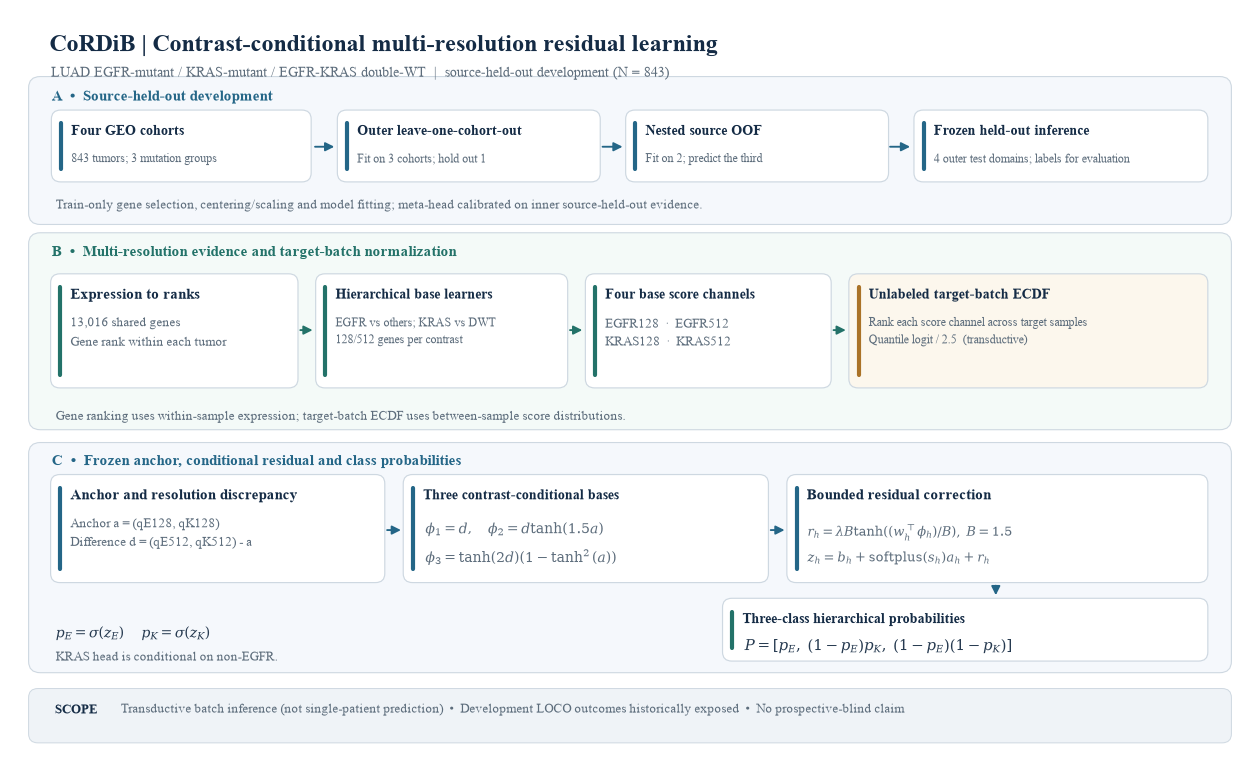

In [18]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import uuid

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from PIL import Image

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")
CMR = Path(
    r"D:\LUAD_CMR_2026"
    r"\CELL03_DATA_20261021T090947_420335Z_d6aed8ec"
    r"\cmr_gene_expression.npz"
)

P12 = ROOT / "12_multiresolution_ood_evidence" / "20261023T151555Z_638a3c88"
P14 = ROOT / "14_quantile_residual_transfer" / "20261023T160742Z_f9435239"
P30C = (
    ROOT / "30_manuscript_figures"
    / "30C_manuscript_results_discussion_20261024T194456Z_bd4ac00b"
)

COHORTS = (
    "GSE13213",
    "GSE31210",
    "GSE32863",
    "GSE72094",
)

EXPECTED = {
    "GSE13213": 117,
    "GSE31210": 226,
    "GSE32863": 58,
    "GSE72094": 442,
}

INPUTS = [
    CMR,
    P12 / "PROTOCOL.json",
    P14 / "PROTOCOL.json",
    P14 / "LOCO_PREDICTIONS.csv",
    P30C / "MAIN_TABLE_01_COHORT_COUNTS.csv",
    P30C / "MANUSCRIPT_CONTENT_MAP.csv",
]

CHECKPOINTS = [
    P14 / "checkpoints" / f"{c}_q_residual.npz"
    for c in COHORTS
]

INPUTS += CHECKPOINTS

missing = [str(p) for p in INPUTS if not p.is_file()]

if missing:
    raise FileNotFoundError(
        "Missing archived evidence:\n" + "\n".join(missing)
)


def sha256(path):
    h = hashlib.sha256()

    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(4 * 1024 * 1024),
            b"",
        ):
            h.update(block)

    return h.hexdigest()


with np.load(CMR, allow_pickle=False) as z:
    required = {"genes", "cohort", "y"}

    if not required.issubset(z.files):
        raise ValueError("CMR arrays missing")

    gene_n = len(z["genes"])
    cohort = np.char.upper(
        np.char.strip(z["cohort"].astype(str))
    )
    labels = np.asarray(z["y"], dtype=int)

observed = {
    c: int(np.sum(cohort == c))
    for c in COHORTS
}

if (
    gene_n != 13016
    or len(labels) != 843
    or set(labels) != {0, 1, 2}
    or observed != EXPECTED
):
    raise ValueError("CMR roster or gene schema mismatch")

protocol12 = json.loads(
    (P12 / "PROTOCOL.json").read_text(encoding="utf-8")
)

protocol14 = json.loads(
    (P14 / "PROTOCOL.json").read_text(encoding="utf-8")
)

if (
    "other two outer training cohorts"
    not in str(protocol12.get("oof_strategy", "")).lower()
):
    raise ValueError("Unexpected Phase12 OOF strategy")

if (
    "transductive"
    not in str(protocol14.get("mode", "")).lower()
    or "bounded three-basis"
    not in str(
        protocol14.get("models", {}).get("q_residual", "")
    ).lower()
):
    raise ValueError("Phase14 method definition mismatch")

BOUND = float(
    protocol14.get("correction_cap_per_head", np.nan)
)

if not np.isclose(BOUND, 1.5):
    raise ValueError("Unexpected residual correction bound")

guard_lambdas = {}

for held, path in zip(COHORTS, CHECKPOINTS):
    with np.load(path, allow_pickle=False) as state:
        required = {
            "weights", "raw_scale", "bias", "guard_lambda"
        }

        if not required.issubset(state.files):
            raise ValueError(f"Checkpoint fields missing: {held}")

        weights = np.asarray(
            state["weights"], dtype=float
        )
        scale = np.asarray(
            state["raw_scale"], dtype=float
        )
        bias = np.asarray(
            state["bias"], dtype=float
        )
        lam = float(
            np.asarray(state["guard_lambda"]).item()
        )

        valid = (
            weights.shape == (2, 3)
            and scale.shape == (2,)
            and bias.shape == (2,)
            and np.isfinite(weights).all()
            and np.isfinite(scale).all()
            and np.isfinite(bias).all()
            and np.isfinite(lam)
            and 0 <= lam <= 1
        )

        if not valid:
            raise ValueError(
                f"Invalid bounded residual checkpoint: {held}"
            )

        guard_lambdas[held] = lam

pred = pd.read_csv(
    P14 / "LOCO_PREDICTIONS.csv",
    usecols=[
        "held_cohort",
        "gsm",
        "true_class",
        "model",
        "p_egfr",
        "p_kras",
        "p_dwt",
    ],
)

pred = pred.loc[
    pred["model"].eq("q_residual")
].copy()

pred["held_cohort"] = (
    pred["held_cohort"]
    .astype(str)
    .str.upper()
    .str.strip()
)

pred["gsm"] = (
    pred["gsm"]
    .astype(str)
    .str.upper()
    .str.strip()
)

probabilities = pred[
    ["p_egfr", "p_kras", "p_dwt"]
].to_numpy(dtype=float)

valid_predictions = (
    len(pred) == 843
    and not pred.duplicated(
        ["held_cohort", "gsm"]
    ).any()
    and pred["held_cohort"].value_counts().to_dict() == EXPECTED
    and np.isfinite(probabilities).all()
    and (probabilities >= -1e-9).all()
    and (probabilities <= 1 + 1e-9).all()
    and np.max(
        np.abs(probabilities.sum(axis=1) - 1)
    ) <= 1e-6
)

if not valid_predictions:
    raise ValueError(
        "Archived CoRDiB predictions failed validation"
    )

counts = pd.read_csv(
    P30C / "MAIN_TABLE_01_COHORT_COUNTS.csv"
)

source_counts = (
    counts.loc[counts["cohort"].ne("Total")]
    .set_index("cohort")
)

if (
    {
        c: int(source_counts.loc[c, "total"])
        for c in COHORTS
    } != EXPECTED
    or int(
        counts.loc[
            counts["cohort"].eq("Total"),
            "total",
        ].iloc[0]
    ) != 843
):
    raise ValueError("Phase30C cohort totals mismatch")

content_map = pd.read_csv(
    P30C / "MANUSCRIPT_CONTENT_MAP.csv"
)

if (
    not {
        "placement", "artifact", "status"
    }.issubset(content_map.columns)
    or content_map["placement"]
    .eq("Main Figure 1").sum() != 1
):
    raise ValueError("Manuscript content map invalid")


NAVY = "#142B45"
INK = "#263A50"
MUTED = "#5D6D7C"
BLUE = "#246687"
TEAL = "#237269"
AMBER = "#AA7227"
WHITE = "#FFFFFF"
LIGHT = "#F5F8FC"
GREENBG = "#F4FAF8"
WARMBG = "#FCF7ED"
BORDER = "#CED8E1"

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "dejavuserif",
    "svg.fonttype": "none",
    "font.size": 10,
})

fig, ax = plt.subplots(
    figsize=(16, 9.8),
    facecolor="white",
)

ax.set_xlim(0, 16)
ax.set_ylim(0, 10)
ax.axis("off")


def txt(x, y, value, **kwargs):
    kwargs.setdefault("color", INK)
    ax.text(
        x, y, value,
        va="top",
        ha="left",
        **kwargs,
    )


def band(y, h, color):
    ax.add_patch(
        FancyBboxPatch(
            (0.30, y),
            15.4,
            h,
            boxstyle=(
                "round,pad=0.06,rounding_size=0.15"
            ),
            facecolor=color,
            edgecolor=BORDER,
            lw=0.8,
            zorder=0,
        )
    )


def node(
    x, y, w, h,
    title, description,
    accent=BLUE,
    fill=WHITE,
    title_fs=11,
    desc_fs=9.5,
):
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            w, h,
            boxstyle=(
                "round,pad=0.016,rounding_size=0.12"
            ),
            facecolor=fill,
            edgecolor=BORDER,
            lw=0.85,
            zorder=2,
        )
    )

    ax.plot(
        [x + 0.11, x + 0.11],
        [y + 0.16, y + h - 0.16],
        color=accent,
        lw=3,
        solid_capstyle="round",
        zorder=3,
    )

    txt(
        x + 0.24,
        y + h - 0.18,
        title,
        fontsize=title_fs,
        fontweight="bold",
        color=NAVY,
        zorder=4,
    )

    if description:
        txt(
            x + 0.24,
            y + h - 0.52,
            description,
            fontsize=desc_fs,
            color=MUTED,
            linespacing=1.55,
            zorder=4,
        )


def arrow(x1, y1, x2, y2, color=BLUE):
    ax.add_patch(
        FancyArrowPatch(
            (x1, y1),
            (x2, y2),
            arrowstyle="-|>",
            mutation_scale=13,
            linewidth=1.35,
            color=color,
            shrinkA=2,
            shrinkB=2,
            zorder=3,
        )
    )


txt(
    0.51, 9.66,
    "CoRDiB | Contrast-conditional multi-resolution residual learning",
    fontsize=17,
    color=NAVY,
    fontweight="bold",
)

txt(
    0.53, 9.24,
    "LUAD EGFR-mutant / KRAS-mutant / EGFR-KRAS double-WT  |  "
    "source-held-out development (N = 843)",
    fontsize=10,
    color=MUTED,
)

band(7.21, 1.84, LIGHT)

txt(
    0.54, 8.93,
    "A  •  Source-held-out development",
    fontsize=11.1,
    fontweight="bold",
    color=BLUE,
)

development_nodes = [
    (
        0.55, 3.32,
        "Four GEO cohorts",
        "843 tumors; 3 mutation groups",
    ),
    (
        4.24, 3.36,
        "Outer leave-one-cohort-out",
        "Fit on 3 cohorts; hold out 1",
    ),
    (
        7.96, 3.36,
        "Nested source OOF",
        "Fit on 2; predict the third",
    ),
    (
        11.68, 3.76,
        "Frozen held-out inference",
        "4 outer test domains; labels for evaluation",
    ),
]

for x, w, title, description in development_nodes:
    node(
        x, 7.73, w, 0.92,
        title, description,
        title_fs=10.1,
        desc_fs=8.75,
    )

for left, right in [
    (3.90, 4.22),
    (7.61, 7.94),
    (11.32, 11.65),
]:
    arrow(
        left, 8.18,
        right, 8.18,
    )

txt(
    0.59, 7.48,
    "Train-only gene selection, centering/scaling and model fitting; "
    "meta-head calibrated on inner source-held-out evidence.",
    fontsize=9,
    color=MUTED,
)

band(4.49, 2.49, GREENBG)

txt(
    0.54, 6.87,
    "B  •  Multi-resolution evidence and target-batch normalization",
    fontsize=11.1,
    fontweight="bold",
    color=TEAL,
)

node(
    0.54, 5.00, 3.16, 1.48,
    "Expression to ranks",
    "13,016 shared genes\nGene rank within each tumor",
    accent=TEAL,
    title_fs=10.8,
    desc_fs=9.2,
)

node(
    3.96, 5.00, 3.22, 1.48,
    "Hierarchical base learners",
    "EGFR vs others; KRAS vs DWT\n"
    "128/512 genes per contrast",
    accent=TEAL,
    title_fs=10.2,
    desc_fs=8.85,
)

node(
    7.44, 5.00, 3.14, 1.48,
    "Four base score channels",
    "EGFR128  ·  EGFR512\n"
    "KRAS128  ·  KRAS512",
    accent=TEAL,
    title_fs=10.3,
    desc_fs=9.1,
)

node(
    10.84, 5.00, 4.60, 1.48,
    "Unlabeled target-batch ECDF",
    "Rank each score channel across target samples\n"
    "Quantile logit / 2.5  (transductive)",
    accent=AMBER,
    fill=WARMBG,
    title_fs=10.25,
    desc_fs=8.9,
)

for left, right in [
    (3.71, 3.94),
    (7.19, 7.42),
    (10.59, 10.82),
]:
    arrow(
        left, 5.75,
        right, 5.75,
        color=TEAL,
    )

txt(
    0.59, 4.68,
    "Gene ranking uses within-sample expression; "
    "target-batch ECDF uses between-sample score distributions.",
    fontsize=9,
    color=MUTED,
)

band(1.27, 2.93, LIGHT)

txt(
    0.54, 4.10,
    "C  •  Frozen anchor, conditional residual and class probabilities",
    fontsize=11.1,
    fontweight="bold",
    color=BLUE,
)

node(
    0.54, 2.42, 4.28, 1.40,
    "Anchor and resolution discrepancy",
    "Anchor a = (qE128, qK128)\n"
    "Difference d = (qE512, qK512) - a",
    title_fs=10.5,
    desc_fs=9.5,
)

node(
    5.09, 2.42, 4.68, 1.40,
    "Three contrast-conditional bases",
    "",
    title_fs=10.4,
)

txt(
    5.36, 3.20,
    r"$\phi_1=d,\quad \phi_2=d\tanh(1.5a)$",
    fontsize=10.1,
    color=MUTED,
)

txt(
    5.36, 2.85,
    r"$\phi_3=\tanh(2d)(1-\tanh^2(a))$",
    fontsize=10.1,
    color=MUTED,
)

node(
    10.04, 2.42, 5.40, 1.40,
    "Bounded residual correction",
    "",
    title_fs=10.5,
)

txt(
    10.29, 3.18,
    r"$r_h=\lambda B\tanh((w_h^\top\phi_h)/B),\;B=1.5$",
    fontsize=9.35,
    color=MUTED,
)

txt(
    10.29, 2.82,
    r"$z_h=b_h+\mathrm{softplus}(s_h)a_h+r_h$",
    fontsize=9.7,
    color=MUTED,
)

arrow(4.83, 3.10, 5.08, 3.10)
arrow(9.78, 3.10, 10.03, 3.10)

node(
    9.21, 1.38, 6.23, 0.80,
    "Three-class hierarchical probabilities",
    "",
    accent=TEAL,
    title_fs=9.9,
)

txt(
    9.48, 1.66,
    r"$P=[p_E,\;(1-p_E)p_K,\;(1-p_E)(1-p_K)]$",
    fontsize=10.7,
    color=INK,
)

arrow(
    12.72, 2.40,
    12.72, 2.20,
)

txt(
    0.59, 1.82,
    r"$p_E=\sigma(z_E)$     $p_K=\sigma(z_K)$",
    fontsize=10,
    color=INK,
)

txt(
    0.59, 1.49,
    "KRAS head is conditional on non-EGFR.",
    fontsize=9,
    color=MUTED,
)

ax.add_patch(
    FancyBboxPatch(
        (0.30, 0.34),
        15.4, 0.60,
        boxstyle=(
            "round,pad=0.06,rounding_size=0.12"
        ),
        facecolor="#EFF3F7",
        edgecolor=BORDER,
        lw=0.7,
        zorder=0,
    )
)

txt(
    0.58, 0.79,
    "SCOPE",
    fontsize=9.3,
    fontweight="bold",
    color=NAVY,
)

txt(
    1.43, 0.80,
    "Transductive batch inference (not single-patient prediction)  •  "
    "Development LOCO outcomes historically exposed  •  "
    "No prospective-blind claim",
    fontsize=9.12,
    color=MUTED,
)

RUN = (
    ROOT / "30_manuscript_figures"
    / (
        "30D_figure01_architecture_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

RUN.mkdir(
    parents=True,
    exist_ok=False,
)

SVG = RUN / "FIG_01_CoRDiB_Architecture.svg"
TIFF = RUN / "FIG_01_CoRDiB_Architecture.tiff"
PNG = RUN / "FIG_01_CoRDiB_Architecture_preview.png"

fig.savefig(
    SVG,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    TIFF,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    PNG,
    dpi=170,
    bbox_inches="tight",
    facecolor="white",
)

with Image.open(TIFF) as im:
    dimensions = im.size
    dpi = tuple(
        float(value)
        for value in im.info.get(
            "dpi", (0, 0)
        )
    )

svg_text = SVG.read_text(
    encoding="utf-8"
)

if (
    min(dimensions) < 1000
    or len(dpi) != 2
    or any(abs(d - 300) > 2 for d in dpi)
    or "<text" not in svg_text
):
    raise RuntimeError(
        "Figure 1 technical export verification failed"
    )

caption = (
    "Figure 1. CoRDiB source-held-out development and "
    "contrast-conditional bounded residual learning. "
    "(A) Four GEO cohorts undergo outer leave-one-cohort-out "
    "evaluation. Inner source-held-out evidence is used "
    "for meta-head training, while feature selection and "
    "scaling are confined to outer training cohorts. "
    "(B) Within-tumor transcriptomic ranks feed "
    "hierarchical EGFR-versus-non-EGFR and "
    "KRAS-versus-double-WT logistic heads at 128- and "
    "512-gene resolutions. Four raw scores are transformed "
    "using empirical distributions of the unlabeled target "
    "batch. (C) The lower-resolution anchor and "
    "resolution discrepancy enter three conditional basis "
    "functions and a bounded residual correction. "
    "Hierarchical logits yield probabilities for "
    "EGFR-mutant, KRAS-mutant, and EGFR/KRAS "
    "double-wild-type classes. The method is transductive "
    "and requires an unlabeled target batch. "
    "The figure depicts exploratory development evaluation, "
    "not prospectively blinded external validation."
)

(RUN / "FIG_01_CAPTION.md").write_text(
    caption + "\n",
    encoding="utf-8",
)

updated_map = content_map.copy()

mask = updated_map["placement"].eq(
    "Main Figure 1"
)

updated_map.loc[mask, "artifact"] = str(SVG)
updated_map.loc[mask, "status"] = (
    "CREATED_TECHNICAL_QA_PASS"
)

updated_map.to_csv(
    RUN / "MANUSCRIPT_CONTENT_MAP_UPDATED.csv",
    index=False,
)

manifest = {
    "phase": "30D_FROZEN_CORDIB_ARCHITECTURE_FIGURE",
    "confirmed_cohorts": EXPECTED,
    "development_n": 843,
    "shared_genes": gene_n,
    "checkpoint_guard_lambdas": guard_lambdas,
    "correction_cap_per_head": BOUND,
    "tiff_dimensions": dimensions,
    "tiff_dpi": dpi,
    "svg_editable_text": True,
    "model_retrained": False,
    "original_archives_modified": False,
    "input_sha256": {
        str(path): sha256(path)
        for path in INPUTS
    },
}

(RUN / "EVIDENCE_MANIFEST.json").write_text(
    json.dumps(
        manifest,
        indent=2,
    ),
    encoding="utf-8",
)

(RUN / "OUTPUT_SHA256.json").write_text(
    json.dumps(
        {
            path.name: sha256(path)
            for path in RUN.iterdir()
            if path.is_file()
        },
        indent=2,
    ),
    encoding="utf-8",
)

print("PHASE30D_FIGURE01_ARCHITECTURE_COMPLETE")
print("SOURCE_PROTOCOL_AND_CHECKPOINTS: PASS")
print("OUTER_Q_RESIDUAL_PREDICTIONS:", len(pred))
print("GUARD_LAMBDAS:", guard_lambdas)
print("CORRECTION_BOUND:", BOUND)
print("TIFF_SIZE:", dimensions)
print("TIFF_DPI:", dpi)
print("EDITABLE_SVG_TEXT: PASS")
print("FIGURE_1_STATUS: CREATED_TECHNICAL_QA_PASS")
print("OUTPUT:", RUN)
print("ORIGINAL_ARCHIVES_MODIFIED: False")

plt.show()

In [19]:

from pathlib import Path
from datetime import datetime, timezone
from urllib.request import Request, urlopen
import hashlib
import json
import uuid

import numpy as np
import pandas as pd
from scipy.stats import rankdata, hypergeom
from statsmodels.stats.multitest import multipletests
from threadpoolctl import threadpool_limits

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")
CMR = Path(r"D:\LUAD_CMR_2026\CELL03_DATA_20261021T090947_420335Z_d6aed8ec\cmr_gene_expression.npz")
P12 = ROOT / "12_multiresolution_ood_evidence" / "20261023T151555Z_638a3c88"

REF_DIR = ROOT / "00_reference_gene_sets"
GMT = REF_DIR / "h.all.v2026.2.Hs.symbols.gmt"
GMT_URL = (
    "https://data.broadinstitute.org/gsea-msigdb/"
    "msigdb/release/2026.2.Hs/"
    "h.all.v2026.2.Hs.symbols.gmt"
)

COHORTS = (
    "GSE13213",
    "GSE31210",
    "GSE32863",
    "GSE72094",
)
CONTRASTS = ("EGFR_vs_nonEGFR", "KRAS_vs_DWT")
RESOLUTIONS = (128, 512)
N_PERM = 999
SEED = 20261025


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


artifacts = [
    P12 / "outer_models" / f"{held}_lr{k}.npz"
    for held in COHORTS
    for k in RESOLUTIONS
]

if not CMR.is_file() or not all(p.is_file() for p in artifacts):
    raise FileNotFoundError(
        "CMR or archived Phase12 checkpoints missing"
    )

REF_DIR.mkdir(parents=True, exist_ok=True)

if not GMT.is_file():
    try:
        request = Request(
            GMT_URL,
            headers={"User-Agent": "Mozilla/5.0"},
        )

        with urlopen(request, timeout=25) as stream:
            data = stream.read(200_000)

        if not 20000 <= len(data) <= 150000:
            raise ValueError("Unexpected reference GMT length")

        GMT.write_bytes(data)

    except Exception as exc:
        raise RuntimeError(
            "Place the official MSigDB human Hallmark GMT at "
            f"{GMT}. Official source: {GMT_URL}. "
            f"Download failure: {type(exc).__name__}: {exc}"
        ) from exc

pathways = {}

for line in GMT.read_text(encoding="utf-8-sig").splitlines():
    fields = line.rstrip("\n").split("\t")

    if len(fields) >= 12:
        pathways[fields[0].strip()] = {
            s.upper().strip()
            for s in fields[2:]
            if s.strip()
        }

if (
    not 45 <= len(pathways) <= 55
    or not all(n.startswith("HALLMARK_") for n in pathways)
):
    raise ValueError(
        f"Invalid Hallmark GMT: {len(pathways)} gene sets"
    )

with np.load(CMR, allow_pickle=False) as z:
    required = {"X", "genes", "cohort", "y", "gsm"}

    if not required.issubset(z.files):
        raise ValueError(
            f"Missing CMR arrays: {required - set(z.files)}"
        )

    X = np.asarray(z["X"], dtype=np.float32)
    genes = np.char.upper(
        np.char.strip(z["genes"].astype(str))
    )
    cohorts = np.char.upper(
        np.char.strip(z["cohort"].astype(str))
    )
    y = np.asarray(z["y"], dtype=np.int8)
    gsm = np.char.upper(
        np.char.strip(z["gsm"].astype(str))
    )

if (
    X.shape != (843, 13016)
    or not np.isfinite(X).all()
    or len(set(genes)) != 13016
    or set(cohorts) != set(COHORTS)
    or set(y.tolist()) != {0, 1, 2}
    or len(set(gsm)) != 843
):
    raise ValueError(
        "Development matrix or source labels invalid"
    )

R = np.empty(X.shape, dtype=np.float32)

for start in range(0, len(y), 12):
    end = min(start + 12, len(y))

    R[start:end] = (
        rankdata(
            X[start:end],
            axis=1,
            method="average",
        ).astype(np.float32) - 1
    ) / (X.shape[1] - 1)

del X

universe = set(genes.tolist())
gene_map = {g: i for i, g in enumerate(genes)}

cohort_ix = {
    c: np.flatnonzero(cohorts == c)
    for c in COHORTS
}

source_effect = {
    name: np.empty(
        (4, len(genes)),
        dtype=np.float32,
    )
    for name in CONTRASTS
}

for ci, cohort in enumerate(COHORTS):
    ix = cohort_ix[cohort]
    r = R[ix]
    z = y[ix]

    sd = np.maximum(r.std(axis=0), 0.04)

    for contrast in CONTRASTS:
        pos = z == (
            0 if contrast == "EGFR_vs_nonEGFR" else 1
        )

        neg = (
            (z != 0)
            if contrast == "EGFR_vs_nonEGFR"
            else (z == 2)
        )

        if min(int(pos.sum()), int(neg.sum())) < 10:
            raise ValueError(
                f"Insufficient class support: {cohort}, {contrast}"
            )

        source_effect[contrast][ci] = (
            r[pos].mean(axis=0)
            - r[neg].mean(axis=0)
        ) / sd

selection = {
    c: {
        128: np.zeros(len(genes), dtype=np.uint8),
        512: np.zeros(len(genes), dtype=np.uint8),
    }
    for c in CONTRASTS
}

coef_abs_128 = {
    c: np.zeros(
        (4, len(genes)),
        dtype=np.float32,
    )
    for c in CONTRASTS
}

checkpoint_results = []

for fold, held in enumerate(COHORTS):
    train_sources = [
        ci
        for ci, c in enumerate(COHORTS)
        if c != held
    ]

    orders = {}

    for contrast in CONTRASTS:
        e = source_effect[contrast][train_sources]

        agreement = (
            np.abs(np.sign(e).sum(axis=0)) / 3
        )

        strength = (
            np.abs(np.median(e, axis=0))
            * (0.2 + 0.8 * agreement)
        )

        orders[contrast] = np.argsort(
            -strength,
            kind="stable",
        )

    for k in RESOLUTIONS:
        expected = np.sort(
            np.unique(
                np.r_[
                    orders[CONTRASTS[0]][:k],
                    orders[CONTRASTS[1]][:k],
                ]
            )
        )

        file = (
            P12 / "outer_models"
            / f"{held}_lr{k}.npz"
        )

        with np.load(file, allow_pickle=False) as state:
            for field in (
                "gene_indices",
                "e_coef",
                "k_coef",
                "genes",
            ):
                if field not in state.files:
                    raise ValueError(
                        f"Checkpoint missing {field}: {file}"
                    )

            saved = np.asarray(
                state["gene_indices"],
                dtype=int,
            )

            stored_genes = np.char.upper(
                np.char.strip(
                    state["genes"].astype(str)
                )
            )

            if (
                not np.array_equal(expected, saved)
                or not np.array_equal(
                    genes[saved],
                    stored_genes,
                )
            ):
                raise ValueError(
                    f"Training-only feature mask differs: {held}, {k}"
                )

            if k == 128:
                for contrast, key in [
                    (CONTRASTS[0], "e_coef"),
                    (CONTRASTS[1], "k_coef"),
                ]:
                    coefs = np.asarray(
                        state[key],
                        dtype=float,
                    ).ravel()

                    if (
                        len(coefs) != len(saved)
                        or not np.isfinite(coefs).all()
                    ):
                        raise ValueError(
                            f"Invalid model coefficients: {file}"
                        )

                    coef_abs_128[contrast][fold, saved] = (
                        np.abs(coefs)
                    )

        for contrast in CONTRASTS:
            selection[contrast][k][
                orders[contrast][:k]
            ] += 1

        checkpoint_results.append({
            "outer_held": held,
            "resolution": k,
            "selected_union": len(saved),
            "feature_match": True,
            "checkpoint_sha256": sha256(file),
        })

records = []

for contrast in CONTRASTS:
    effects = source_effect[contrast]

    med_coef = np.median(
        coef_abs_128[contrast],
        axis=0,
    )

    pos_sign = np.sum(
        effects > 0, axis=0
    )
    neg_sign = np.sum(
        effects < 0, axis=0
    )

    agree = np.maximum(
        pos_sign, neg_sign
    )

    avg_effect = effects.mean(axis=0)

    for j, gene in enumerate(genes):
        records.append({
            "contrast": contrast,
            "gene": gene,
            "selected_128_folds": int(
                selection[contrast][128][j]
            ),
            "selected_512_folds": int(
                selection[contrast][512][j]
            ),
            "sources_same_effect_direction": int(
                agree[j]
            ),
            "mean_source_standardized_rank_effect": float(
                avg_effect[j]
            ),
            "median_absolute_128_head_coefficient_including_zero": float(
                med_coef[j]
            ),
            "GSE13213_effect": float(effects[0, j]),
            "GSE31210_effect": float(effects[1, j]),
            "GSE32863_effect": float(effects[2, j]),
            "GSE72094_effect": float(effects[3, j]),
        })

genes_df = pd.DataFrame(records)

genes_df["stable_candidate"] = (
    (genes_df.selected_128_folds >= 3)
    & (genes_df.sources_same_effect_direction >= 3)
)

scored_sets = []

for name, members in sorted(pathways.items()):
    ids = np.array(
        [
            gene_map[g]
            for g in sorted(members & universe)
        ],
        dtype=int,
    )

    if len(ids) >= 10:
        scored_sets.append((name, ids))

if len(scored_sets) < 45:
    raise ValueError(
        "Insufficient gene-symbol overlap with MSigDB Hallmark"
    )

S = np.empty(
    (len(y), len(scored_sets)),
    dtype=np.float32,
)

for j, (_, ids) in enumerate(scored_sets):
    S[:, j] = R[:, ids].mean(axis=1)

rng = np.random.default_rng(SEED)

permutation_rows = []
permutation_effects = {}

with threadpool_limits(limits=2):
    for contrast in CONTRASTS:
        obs_sources = []
        perm_sources = []

        for cohort in COHORTS:
            ix = cohort_ix[cohort]

            eligible = (
                np.ones(len(ix), dtype=bool)
                if contrast == "EGFR_vs_nonEGFR"
                else y[ix] != 0
            )

            z = y[ix][eligible]
            ss = S[ix][eligible].astype(np.float64)

            pos = z == (
                0 if contrast == "EGFR_vs_nonEGFR" else 1
            )

            npos = int(pos.sum())
            nneg = int((~pos).sum())

            if min(npos, nneg) < 10:
                raise ValueError(
                    f"Insufficient pathway contrast size: "
                    f"{cohort}, {contrast}"
                )

            sd = np.maximum(
                ss.std(axis=0, ddof=1),
                1e-6,
            )

            obs = (
                ss[pos].mean(axis=0)
                - ss[~pos].mean(axis=0)
            ) / sd

            obs_sources.append(obs)

            order = np.argsort(
                rng.random((N_PERM, len(z))),
                axis=1,
            )[:, :npos]

            Pm = np.zeros(
                (N_PERM, len(z)),
                dtype=np.float64,
            )

            Pm[
                np.arange(N_PERM)[:, None],
                order,
            ] = 1.0

            sum_pos = Pm @ ss

            perm = (
                sum_pos / npos
                - (ss.sum(axis=0) - sum_pos) / nneg
            ) / sd

            perm_sources.append(perm)

        obs_sources = np.stack(obs_sources)

        test_stat = obs_sources.mean(axis=0)

        perm_mean = np.mean(
            np.stack(perm_sources, axis=0),
            axis=0,
        )

        pval = (
            1
            + (
                np.abs(perm_mean)
                >= np.abs(test_stat)[None, :]
            ).sum(axis=0)
        ) / (N_PERM + 1)

        permutation_effects[contrast] = (
            obs_sources,
            test_stat,
            pval,
        )

        for j, (name, ids) in enumerate(scored_sets):
            source_signs = np.sign(
                obs_sources[:, j]
            )

            permutation_rows.append({
                "contrast": contrast,
                "hallmark": name,
                "mapped_gene_count": int(len(ids)),
                "equal_cohort_standardized_effect": float(
                    test_stat[j]
                ),
                "sources_same_effect_direction": int(
                    max(
                        (source_signs > 0).sum(),
                        (source_signs < 0).sum(),
                    )
                ),
                "permutation_p": float(pval[j]),
                **{
                    f"{c}_effect": float(
                        obs_sources[ci, j]
                    )
                    for ci, c in enumerate(COHORTS)
                },
            })

pathway_df = pd.DataFrame(
    permutation_rows
)

pathway_df["fdr_bh_all_contrasts"] = (
    multipletests(
        pathway_df["permutation_p"],
        method="fdr_bh",
    )[1]
)

pathway_df = pathway_df.sort_values(
    [
        "fdr_bh_all_contrasts",
        "permutation_p",
        "hallmark",
    ]
)

ora_rows = []

for contrast in CONTRASTS:
    stable = set(
        genes_df.loc[
            (genes_df.contrast == contrast)
            & genes_df.stable_candidate,
            "gene",
        ]
    )

    n = len(stable)

    for hallmark, ids in scored_sets:
        members = set(genes[ids])
        overlap = sorted(stable & members)

        p = (
            float(
                hypergeom.sf(
                    len(overlap) - 1,
                    len(universe),
                    len(members),
                    n,
                )
            )
            if n
            else 1.0
        )

        ora_rows.append({
            "contrast": contrast,
            "hallmark": hallmark,
            "measured_gene_universe": len(universe),
            "stable_gene_query_size": n,
            "pathway_measured_genes": len(members),
            "observed_overlap": len(overlap),
            "overlap_genes": ";".join(overlap),
            "hypergeometric_p": p,
        })

ora_df = pd.DataFrame(ora_rows)

ora_df["fdr_bh_all_contrasts"] = (
    multipletests(
        ora_df.hypergeometric_p,
        method="fdr_bh",
    )[1]
)

ora_df = ora_df.sort_values(
    [
        "fdr_bh_all_contrasts",
        "hypergeometric_p",
    ]
)

run = (
    ROOT
    / "32_biological_interpretation"
    / (
        "BIOLOGY_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

run.mkdir(
    parents=True,
    exist_ok=False,
)

genes_df.to_csv(
    run / "GENE_CONTRAST_SELECTION_AND_SOURCE_EFFECTS.csv",
    index=False,
)

genes_df.loc[
    genes_df.stable_candidate
].sort_values(
    [
        "contrast",
        "selected_128_folds",
        "median_absolute_128_head_coefficient_including_zero",
    ],
    ascending=[True, False, False],
).to_csv(
    run / "STABLE_MODEL_GENE_CANDIDATES.csv",
    index=False,
)

pathway_df.to_csv(
    run / "HALLMARK_COHORT_STRATIFIED_PERMUTATION.csv",
    index=False,
)

ora_df.to_csv(
    run / "STABLE_GENES_HALLMARK_ORA.csv",
    index=False,
)

pd.DataFrame(checkpoint_results).to_csv(
    run / "MODEL_FEATURE_REPLAY_AUDIT.csv",
    index=False,
)

report = {
    "phase": "EXPLORATORY_BIOLOGICAL_INTERPRETATION",
    "development_n": int(len(y)),
    "source_cohorts": list(COHORTS),
    "contrasts": list(CONTRASTS),
    "selection_rule": (
        "Top-k per contrast in each 3-source outer training "
        "fold, exact original Phase12 selection formula"
    ),
    "candidate_rule": (
        "Selected among top128 in >=3/4 outer folds "
        "and same signed rank effect in >=3/4 original studies"
    ),
    "pathway_activity": (
        "Per-sample mean within-transcriptome ranks of "
        "curated Hallmark genes, cohort-standardized mean "
        "contrast, equal-cohort aggregation"
    ),
    "pathway_significance": (
        "999 source-stratified label permutations preserving "
        "contrast group sizes, two-sided, BH over both "
        "contrasts and all tested pathways"
    ),
    "ora_background": (
        "All 13016 measured CMR gene symbols"
    ),
    "gene_set_url": GMT_URL,
    "gene_set_sha256": sha256(GMT),
    "gene_set_count": len(pathways),
    "pathways_analyzed": len(scored_sets),
    "permutations": N_PERM,
    "seed": SEED,
    "stable_gene_counts": {
        name: int(
            (
                (genes_df.contrast == name)
                & genes_df.stable_candidate
            ).sum()
        )
        for name in CONTRASTS
    },
    "pathways_fdr_lt_005": int(
        (pathway_df.fdr_bh_all_contrasts < 0.05).sum()
    ),
    "ora_fdr_lt_005": int(
        (ora_df.fdr_bh_all_contrasts < 0.05).sum()
    ),
    "training_only_checkpoint_feature_replays": len(
        checkpoint_results
    ),
    "new_inferential_tests": True,
    "historically_exposed_development": True,
    "model_retrained": False,
    "external_labels_used": False,
    "original_archives_modified": False,
    "input_sha256": {
        str(p): sha256(p)
        for p in [CMR, *artifacts]
    },
}

(
    run / "BIOLOGICAL_AUDIT_MANIFEST.json"
).write_text(
    json.dumps(
        report,
        indent=2,
    ),
    encoding="utf-8",
)

(
    run / "OUTPUT_SHA256.json"
).write_text(
    json.dumps(
        {
            p.name: sha256(p)
            for p in run.iterdir()
            if p.is_file()
        },
        indent=2,
    ),
    encoding="utf-8",
)

print("BIOLOGICAL_ANALYSIS_COMPLETE")
print("SOURCE_CHECK: PASS")
print(
    "OUTER_FEATURE_REPLAYS:",
    len(checkpoint_results),
    "/8",
)
print(
    "HALLMARK_SETS:",
    len(scored_sets),
    "PERMUTATIONS:",
    N_PERM,
)
print(
    "STABLE_128_GENES:",
    report["stable_gene_counts"],
)
print(
    "PATHWAY_ACTIVITY_FDR_LT_0.05:",
    report["pathways_fdr_lt_005"],
)
print(
    "MODEL_GENE_ORA_FDR_LT_0.05:",
    report["ora_fdr_lt_005"],
)

print("TOP_HALLMARK_ACTIVITY:")
print(
    pathway_df[
        [
            "contrast",
            "hallmark",
            "equal_cohort_standardized_effect",
            "sources_same_effect_direction",
            "permutation_p",
            "fdr_bh_all_contrasts",
        ]
    ].head(12).round(5).to_string(index=False)
)

print("TOP_MODEL_SELECTED_GENES:")
print(
    genes_df.loc[
        genes_df.stable_candidate
    ].sort_values(
        [
            "selected_128_folds",
            "median_absolute_128_head_coefficient_including_zero",
        ],
        ascending=False,
    )[
        [
            "contrast",
            "gene",
            "selected_128_folds",
            "sources_same_effect_direction",
            "mean_source_standardized_rank_effect",
        ]
    ].head(12).round(5).to_string(index=False)
)

print("TOP_GENE_SET_ORA:")
print(
    ora_df[
        [
            "contrast",
            "hallmark",
            "stable_gene_query_size",
            "observed_overlap",
            "hypergeometric_p",
            "fdr_bh_all_contrasts",
        ]
    ].head(8).round(5).to_string(index=False)
)

print("OUTPUT:", run)
print("MODEL_RETRAINED: False")
print("ORIGINAL_ARCHIVES_MODIFIED: False")

BIOLOGICAL_ANALYSIS_COMPLETE
SOURCE_CHECK: PASS
OUTER_FEATURE_REPLAYS: 8 /8
HALLMARK_SETS: 50 PERMUTATIONS: 999
STABLE_128_GENES: {'EGFR_vs_nonEGFR': 58, 'KRAS_vs_DWT': 37}
PATHWAY_ACTIVITY_FDR_LT_0.05: 19
MODEL_GENE_ORA_FDR_LT_0.05: 0
TOP_HALLMARK_ACTIVITY:
       contrast                                 hallmark  equal_cohort_standardized_effect  sources_same_effect_direction  permutation_p  fdr_bh_all_contrasts
EGFR_vs_nonEGFR            HALLMARK_BILE_ACID_METABOLISM                           0.47132                              4          0.001               0.00769
EGFR_vs_nonEGFR                      HALLMARK_DNA_REPAIR                          -0.39096                              4          0.001               0.00769
EGFR_vs_nonEGFR                     HALLMARK_E2F_TARGETS                          -0.38310                              4          0.001               0.00769
EGFR_vs_nonEGFR          HALLMARK_ESTROGEN_RESPONSE_LATE                          -0.38144               

PHASE32B_BIOLOGICAL_FIGURES_COMPLETE
BIOLOGICAL_COUNTS_VERIFIED: {'EGFR_vs_nonEGFR': 58, 'KRAS_vs_DWT': 37}
HALLMARK_FDR_LT_005: {'EGFR_vs_nonEGFR': 16, 'KRAS_vs_DWT': 3}
ORA_FDR_LT_005: 0
FEATURE_CHECKPOINTS_VERIFIED: 8
MAIN_FIGURE: FIG03_Biological_Interpretation
SUPP_FIGURE: FIGS1_Gene_Selection_Jaccard
TIFF: 300 DPI | SVG: Editable | PNG: Preview
SUPPLEMENTARY_TABLES_ADDED: 1
MODEL_RETRAINED: False
ORIGINAL_ARCHIVES_MODIFIED: False
OUTPUT: D:\LUAD_DATAFIRST_METHOD_2026\32_biological_interpretation\FIGURES_BIOLOGY_20261024T202336Z_382f0135


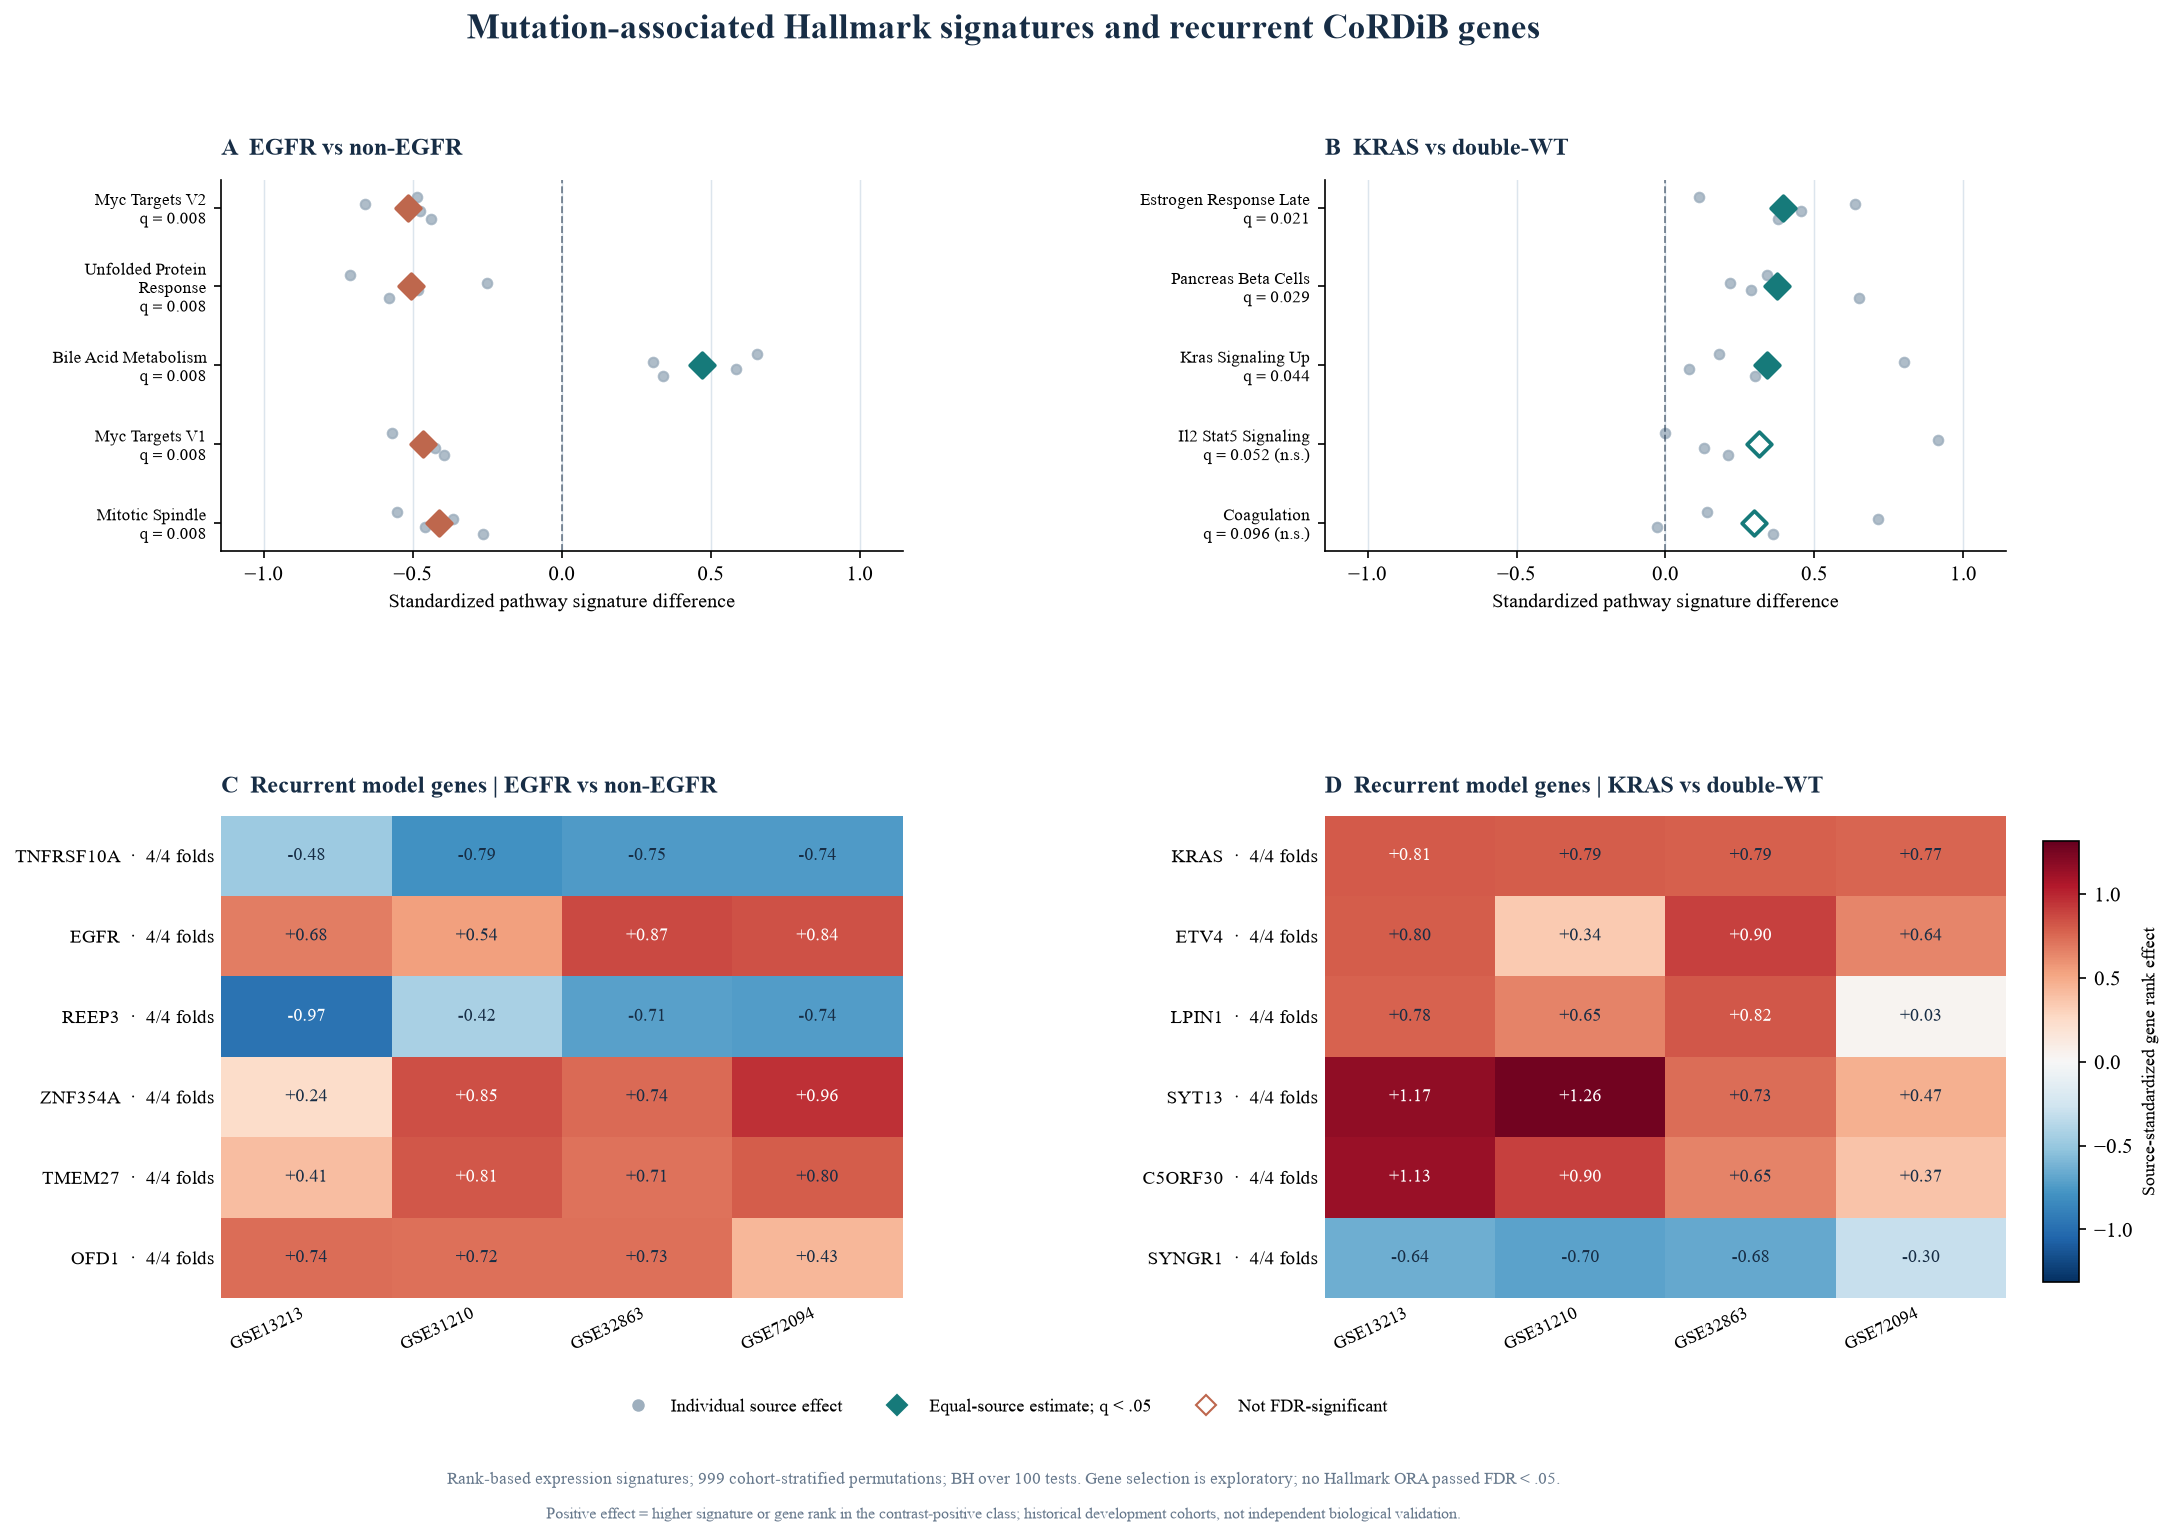

In [20]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import uuid
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from PIL import Image
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Image as IPythonImage

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")

BIO = (
    ROOT / "32_biological_interpretation"
    / "BIOLOGY_20261024T201747Z_c879da1d"
)

P12 = (
    ROOT / "12_multiresolution_ood_evidence"
    / "20261023T151555Z_638a3c88"
)

COHORTS = (
    "GSE13213", "GSE31210",
    "GSE32863", "GSE72094"
)

CONTRASTS = (
    "EGFR_vs_nonEGFR",
    "KRAS_vs_DWT"
)

LABELS = {
    "EGFR_vs_nonEGFR": "EGFR vs non-EGFR",
    "KRAS_vs_DWT": "KRAS vs double-WT"
}

SELECT_PATHWAYS = 5
SELECT_GENES = 6

FILES = {
    "pathways": BIO / "HALLMARK_COHORT_STRATIFIED_PERMUTATION.csv",
    "genes": BIO / "STABLE_MODEL_GENE_CANDIDATES.csv",
    "ora": BIO / "STABLE_GENES_HALLMARK_ORA.csv",
    "feature_check": BIO / "MODEL_FEATURE_REPLAY_AUDIT.csv",
    "manifest": BIO / "BIOLOGICAL_AUDIT_MANIFEST.json"
}

CHECKPOINTS = {
    (h, k): P12 / "outer_models" / f"{h}_lr{k}.npz"
    for h in COHORTS
    for k in (128, 512)
}

for file in [*FILES.values(), *CHECKPOINTS.values()]:
    if not file.is_file():
        raise FileNotFoundError(file)


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


pathways = pd.read_csv(FILES["pathways"])
genes = pd.read_csv(FILES["genes"])
ora = pd.read_csv(FILES["ora"])
check = pd.read_csv(FILES["feature_check"])

manifest = json.loads(
    FILES["manifest"].read_text(encoding="utf-8")
)

required_pathways = {
    "contrast", "hallmark",
    "equal_cohort_standardized_effect",
    "sources_same_effect_direction",
    "permutation_p",
    "fdr_bh_all_contrasts"
} | {f"{c}_effect" for c in COHORTS}

required_genes = {
    "contrast", "gene",
    "selected_128_folds",
    "sources_same_effect_direction",
    "mean_source_standardized_rank_effect",
    "median_absolute_128_head_coefficient_including_zero"
} | {f"{c}_effect" for c in COHORTS}

required_ora = {
    "contrast", "hallmark",
    "hypergeometric_p",
    "fdr_bh_all_contrasts"
}

for tag, frame, required in [
    ("pathways", pathways, required_pathways),
    ("genes", genes, required_genes),
    ("ora", ora, required_ora)
]:
    if not required.issubset(frame.columns):
        raise ValueError(
            f"{tag} missing fields: "
            f"{sorted(required - set(frame.columns))}"
        )

    key = "gene" if tag == "genes" else "hallmark"

    if frame[["contrast", key]].duplicated().any():
        raise ValueError(f"Duplicate {tag} keys")

if (
    set(pathways.contrast) != set(CONTRASTS)
    or len(pathways) != 100
    or len(ora) != 100
    or set(genes.contrast) != set(CONTRASTS)
    or len(check) != 8
):
    raise ValueError("Biological analysis roster mismatch")

if not (
    check.feature_match.astype(str)
    .str.lower().eq("true").all()
):
    raise ValueError("Feature replay audit mismatch")

pathway_q = multipletests(
    pathways.permutation_p.to_numpy(float),
    method="fdr_bh"
)[1]

if not np.allclose(
    pathway_q,
    pathways.fdr_bh_all_contrasts.to_numpy(float),
    atol=1e-10,
    rtol=1e-8
):
    raise ValueError("Hallmark FDR mismatch")

ora_q = multipletests(
    ora.hypergeometric_p.to_numpy(float),
    method="fdr_bh"
)[1]

if not np.allclose(
    ora_q,
    ora.fdr_bh_all_contrasts.to_numpy(float),
    atol=1e-10,
    rtol=1e-8
):
    raise ValueError("ORA FDR mismatch")

stable_counts = {
    c: int((genes.contrast == c).sum())
    for c in CONTRASTS
}

sig_counts = {
    c: int(
        (
            (pathways.contrast == c)
            & (pathways.fdr_bh_all_contrasts < 0.05)
        ).sum()
    )
    for c in CONTRASTS
}

if stable_counts != {
    "EGFR_vs_nonEGFR": 58,
    "KRAS_vs_DWT": 37
}:
    raise ValueError("Stable gene counts changed")

if sum(sig_counts.values()) != 19:
    raise ValueError("Hallmark significance count changed")

if int((ora.fdr_bh_all_contrasts < 0.05).sum()) != 0:
    raise ValueError("Unexpected significant Hallmark ORA")

if stable_counts != {
    k: int(v)
    for k, v in manifest["stable_gene_counts"].items()
}:
    raise ValueError("Biological manifest mismatch")

if manifest["training_only_checkpoint_feature_replays"] != 8:
    raise ValueError("Incomplete training-feature replay audit")

selected_sets = {}

for (cohort, k), path in CHECKPOINTS.items():
    with np.load(path, allow_pickle=False) as z:
        if "gene_indices" not in z.files:
            raise ValueError(f"Missing gene indices: {path}")

        ids = np.asarray(z["gene_indices"], dtype=int)

        if (
            len(ids) != len(np.unique(ids))
            or len(ids) < k
            or len(ids) > 2 * k
        ):
            raise ValueError(
                f"Invalid saved gene union: {path}"
            )

        selected_sets[(cohort, k)] = set(ids.tolist())

RUN = (
    ROOT / "32_biological_interpretation"
    / (
        "FIGURES_BIOLOGY_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

RUN.mkdir(parents=True, exist_ok=False)

COLOR = {
    "ink": "#172D45",
    "muted": "#65778B",
    "grid": "#DCE5ED",
    "teal": "#167A7A",
    "rust": "#BE674D",
    "grey": "#9EAFBE"
}

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 10.3,
    "axes.titlesize": 11.5,
    "axes.labelsize": 9.4,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "svg.fonttype": "none",
    "savefig.facecolor": "white"
})

figure_records = []


def save_figure(fig, name, caption, placement):
    fig.savefig(
        RUN / f"{name}.svg",
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        RUN / f"{name}.tiff",
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        RUN / f"{name}.png",
        dpi=150,
        bbox_inches="tight",
        facecolor="white"
    )

    with Image.open(RUN / f"{name}.tiff") as im:
        dpi = im.info.get("dpi", (0, 0))

        if (
            min(im.size) < 950
            or any(abs(float(d) - 300) > 2 for d in dpi)
        ):
            raise RuntimeError(f"TIFF export failed: {name}")

    svg = (
        RUN / f"{name}.svg"
    ).read_text(encoding="utf-8")

    if "<text" not in svg:
        raise RuntimeError(
            f"Editable SVG text missing: {name}"
        )

    figure_records.append({
        "figure": name,
        "placement": placement,
        "caption": caption
    })

    plt.close(fig)


pathway_choice = []

for contrast in CONTRASTS:
    group = pathways.loc[
        pathways.contrast.eq(contrast)
    ].copy()

    group["abs_effect"] = (
        group.equal_cohort_standardized_effect.abs()
    )

    group["significant"] = (
        group.fdr_bh_all_contrasts < 0.05
    )

    group = group.sort_values(
        ["significant", "fdr_bh_all_contrasts", "abs_effect"],
        ascending=[False, True, False],
        kind="stable"
    )

    pathway_choice.append(
        group.head(SELECT_PATHWAYS).copy()
    )

gene_choice = []

for contrast in CONTRASTS:
    group = genes.loc[
        genes.contrast.eq(contrast)
    ].copy()

    group = group.sort_values(
        [
            "selected_128_folds",
            "sources_same_effect_direction",
            "median_absolute_128_head_coefficient_including_zero"
        ],
        ascending=[False, False, False],
        kind="stable"
    )

    gene_choice.append(
        group.head(SELECT_GENES).copy()
    )

all_pathway_effects = []

for sub in pathway_choice:
    all_pathway_effects.extend(
        sub.equal_cohort_standardized_effect.to_numpy(float)
    )

    for cohort in COHORTS:
        all_pathway_effects.extend(
            sub[f"{cohort}_effect"].to_numpy(float)
        )

pathway_bound = max(
    0.5,
    float(np.max(np.abs(all_pathway_effects))) * 1.25
)

all_gene_effects = [
    float(value)
    for group in gene_choice
    for cohort in COHORTS
    for value in group[f"{cohort}_effect"]
]

gene_bound = max(
    0.65,
    float(np.max(np.abs(all_gene_effects))) * 1.04
)


# MAIN FIGURE 3

fig, axes = plt.subplots(
    2, 2,
    figsize=(16.3, 10.5),
    gridspec_kw={
        "height_ratios": [1.0, 1.30],
        "hspace": 0.62,
        "wspace": 0.62
    }
)

fig.suptitle(
    "Mutation-associated Hallmark signatures "
    "and recurrent CoRDiB genes",
    x=0.5,
    y=0.985,
    fontsize=17,
    color=COLOR["ink"],
    fontweight="bold"
)

for ci, contrast in enumerate(CONTRASTS):
    ax = axes[0, ci]

    sub = (
        pathway_choice[ci]
        .iloc[::-1]
        .reset_index(drop=True)
    )

    for j, row in sub.iterrows():
        source_effects = np.array([
            float(row[f"{c}_effect"])
            for c in COHORTS
        ])

        mean = float(
            row.equal_cohort_standardized_effect
        )

        significant = (
            float(row.fdr_bh_all_contrasts) < 0.05
        )

        ax.scatter(
            source_effects,
            np.full(4, j) + np.linspace(-0.14, 0.14, 4),
            s=21,
            color=COLOR["grey"],
            alpha=0.82,
            zorder=2
        )

        point_color = (
            COLOR["teal"]
            if mean >= 0
            else COLOR["rust"]
        )

        ax.scatter(
            [mean],
            [j],
            marker="D",
            s=70,
            facecolor=(
                point_color
                if significant
                else "white"
            ),
            edgecolor=point_color,
            linewidth=1.8,
            zorder=5
        )

    tick_labels = []

    for _, row in sub.iterrows():
        name = (
            row.hallmark
            .replace("HALLMARK_", "")
            .replace("_", " ")
            .title()
        )

        name = textwrap.fill(
            name,
            24,
            break_long_words=False
        )

        q = float(row.fdr_bh_all_contrasts)

        tick_labels.append(
            f"{name}\nq = {q:.3f}"
            if q < 0.05
            else f"{name}\nq = {q:.3f} (n.s.)"
        )

    ax.set_yticks(
        range(len(sub)),
        tick_labels,
        fontsize=8.3
    )

    ax.set_xlim(
        -pathway_bound,
        pathway_bound
    )

    ax.axvline(
        0,
        color=COLOR["ink"],
        lw=0.9,
        ls="--",
        alpha=0.55
    )

    ax.set_xlabel(
        "Standardized pathway signature difference"
    )

    ax.set_title(
        ("A" if ci == 0 else "B")
        + "  " + LABELS[contrast],
        loc="left",
        color=COLOR["ink"],
        fontweight="bold",
        pad=12
    )

    ax.grid(
        axis="x",
        color=COLOR["grid"],
        lw=0.7
    )

    ax.set_axisbelow(True)

    if sig_counts[contrast] == 0:
        ax.text(
            0.5, 1.035,
            "No Hallmark association passes FDR < 0.05",
            transform=ax.transAxes,
            ha="center",
            fontsize=8.1,
            color=COLOR["rust"]
        )

for ci, contrast in enumerate(CONTRASTS):
    ax = axes[1, ci]

    sub = gene_choice[ci].reset_index(drop=True)

    matrix = sub[
        [f"{c}_effect" for c in COHORTS]
    ].to_numpy(float)

    im = ax.imshow(
        matrix,
        cmap="RdBu_r",
        vmin=-gene_bound,
        vmax=gene_bound,
        aspect="auto",
        interpolation="nearest"
    )

    ax.set_yticks(
        range(len(sub)),
        [
            f"{row.gene}  ·  "
            f"{int(row.selected_128_folds)}/4 folds"
            for _, row in sub.iterrows()
        ],
        fontsize=9
    )

    ax.set_xticks(
        range(4),
        COHORTS,
        rotation=25,
        ha="right",
        fontsize=8.8
    )

    for i in range(matrix.shape[0]):
        for j in range(4):
            value = matrix[i, j]

            ax.text(
                j, i,
                f"{value:+.2f}",
                fontsize=8.6,
                ha="center",
                va="center",
                color=(
                    "white"
                    if abs(value) > 0.61 * gene_bound
                    else COLOR["ink"]
                )
            )

    ax.set_title(
        ("C" if ci == 0 else "D")
        + "  Recurrent model genes | "
        + LABELS[contrast],
        loc="left",
        color=COLOR["ink"],
        fontweight="bold",
        pad=11
    )

    ax.tick_params(length=0)

    for side in ax.spines.values():
        side.set_visible(False)

fig.subplots_adjust(
    left=0.18,
    right=0.91,
    bottom=0.17,
    top=0.88,
    wspace=0.65,
    hspace=0.62
)

cax = fig.add_axes([
    0.925, 0.18, 0.015, 0.28
])

cb = fig.colorbar(
    im,
    cax=cax
)

cb.set_label(
    "Source-standardized gene rank effect",
    fontsize=8.6
)

legend = [
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=COLOR["grey"],
        markeredgecolor="none",
        markersize=6,
        label="Individual source effect"
    ),
    Line2D(
        [0], [0],
        marker="D",
        color="none",
        markerfacecolor=COLOR["teal"],
        markeredgecolor=COLOR["teal"],
        markersize=7,
        label="Equal-source estimate; q < .05"
    ),
    Line2D(
        [0], [0],
        marker="D",
        color="none",
        markerfacecolor="white",
        markeredgecolor=COLOR["rust"],
        markersize=7,
        label="Not FDR-significant"
    )
]

fig.legend(
    handles=legend,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.085),
    ncol=3,
    frameon=False,
    fontsize=8.7
)

fig.text(
    0.5, 0.052,
    "Rank-based expression signatures; 999 cohort-stratified "
    "permutations; BH over 100 tests. Gene selection is exploratory; "
    "no Hallmark ORA passed FDR < .05.",
    ha="center",
    fontsize=8.3,
    color=COLOR["muted"]
)

fig.text(
    0.5, 0.030,
    "Positive effect = higher signature or gene rank in the "
    "contrast-positive class; historical development cohorts, "
    "not independent biological validation.",
    ha="center",
    fontsize=7.8,
    color=COLOR["muted"]
)

save_figure(
    fig,
    "MAIN_FIG03_Biological_Interpretation",
    (
        "Exploratory Hallmark expression signatures "
        "and recurrent model-selected genes; "
        "no significant Hallmark gene-set ORA."
    ),
    "MAIN"
)


# SUPPLEMENTARY FIGURE S1

fig, axs = plt.subplots(
    1, 2,
    figsize=(11, 4.6),
    sharex=True,
    sharey=True
)

for ax, k in zip(axs, (128, 512)):
    similarity = np.zeros(
        (4, 4),
        dtype=float
    )

    for i, a in enumerate(COHORTS):
        for j, b in enumerate(COHORTS):
            sa = selected_sets[(a, k)]
            sb = selected_sets[(b, k)]

            similarity[i, j] = (
                len(sa & sb) / len(sa | sb)
            )

    ax.imshow(
        similarity,
        cmap="Blues",
        vmin=0,
        vmax=1,
        aspect="equal"
    )

    ax.set_xticks(
        range(4),
        COHORTS,
        rotation=27,
        ha="right",
        fontsize=8.6
    )

    ax.set_yticks(
        range(4),
        COHORTS,
        fontsize=8.6
    )

    for i in range(4):
        for j in range(4):
            value = similarity[i, j]

            ax.text(
                j, i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=9,
                color=(
                    "white"
                    if value > 0.65
                    else COLOR["ink"]
                )
            )

    ax.set_title(
        f"{k}-gene-per-contrast feature unions",
        loc="left",
        fontsize=11,
        color=COLOR["ink"],
        pad=11
    )

    ax.tick_params(length=0)

fig.suptitle(
    "Cross-fold overlap of model-selected features",
    fontsize=15,
    color=COLOR["ink"],
    fontweight="bold",
    y=0.99
)

fig.text(
    0.5, 0.01,
    "Jaccard similarity of saved training-only feature masks; "
    "descriptive selection stability, not pathway enrichment.",
    ha="center",
    fontsize=8.5,
    color=COLOR["muted"]
)

fig.tight_layout(
    rect=[0.015, 0.05, 0.98, 0.93]
)

save_figure(
    fig,
    "SUPP_FIG_S1_Gene_Selection_Jaccard",
    (
        "Jaccard overlap of training-only selected feature "
        "unions at 128 and 512 genes per contrast."
    ),
    "SUPPLEMENTARY"
)


# BIOLOGICAL SUPPLEMENTARY DATA

selected_pathways = (
    pd.concat(
        pathway_choice,
        ignore_index=True
    )
    .drop(columns=["abs_effect", "significant"])
)

selected_genes = pd.concat(
    gene_choice,
    ignore_index=True
)

selected_pathways.to_csv(
    RUN / "FIG03_PLOTTED_HALLMARK_DATA.csv",
    index=False
)

selected_genes.to_csv(
    RUN / "FIG03_PLOTTED_GENE_DATA.csv",
    index=False
)

full_biology = pathways.merge(
    ora.drop(
        columns=["fdr_bh_all_contrasts"]
    ).rename(
        columns={
            "hypergeometric_p": "ora_hypergeometric_p"
        }
    ),
    on=["contrast", "hallmark"],
    how="left",
    validate="one_to_one"
)

full_biology = full_biology.rename(
    columns={
        "fdr_bh_all_contrasts": "signature_fdr_bh"
    }
)

full_biology = full_biology.merge(
    ora[
        [
            "contrast",
            "hallmark",
            "fdr_bh_all_contrasts"
        ]
    ].rename(
        columns={
            "fdr_bh_all_contrasts": "ora_fdr_bh"
        }
    ),
    on=["contrast", "hallmark"],
    validate="one_to_one"
)

full_biology.to_csv(
    RUN / "SUPP_TABLE_S2_HALLMARK_SIGNATURE_AND_ORA.csv",
    index=False
)

genes.to_csv(
    RUN / "DATA_STABLE_MODEL_SELECTED_GENES.csv",
    index=False
)

captions = """
Main Figure 3. Exploratory mutation-associated expression
signatures and recurrent model-selected genes. Panels A–B show
rank-based Hallmark expression signature differences for EGFR
versus non-EGFR and KRAS versus EGFR/KRAS double-WT across
four development cohorts. Grey points represent cohort-level
standardized contrasts; diamonds represent equally weighted
cohort means. Filled diamonds indicate BH-FDR < 0.05 across
100 tests. Open diamonds are not FDR-significant. Panels C–D
display recurrent model-selected genes and source-standardized
rank effects. No Hallmark overrepresentation test of stable
model-selected genes was significant after FDR correction.
These associations are exploratory and do not establish causal
pathway activation or independently validated biomarkers.

Supplementary Figure S1. Jaccard similarity between saved
outer-fold feature unions at 128 and 512 genes per contrast.
These comparisons describe model-selection stability rather
than biological enrichment.
""".strip()

(
    RUN / "FIGURE_CAPTIONS.md"
).write_text(
    captions + "\n",
    encoding="utf-8"
)

pd.DataFrame(
    figure_records
).to_csv(
    RUN / "FIGURE_INDEX.csv",
    index=False
)

run_manifest = {
    "phase": "32B_BIOLOGICAL_FIGURE_REPRODUCTION",
    "stable_model_gene_counts": stable_counts,
    "significant_hallmark_count_by_contrast": sig_counts,
    "hallmark_signature_tests": len(pathways),
    "significant_hallmark_ora_tests": 0,
    "main_figures_created": 1,
    "supplementary_figures_created": 1,
    "outer_checkpoints_read_only": 8,
    "model_retrained": False,
    "new_statistical_tests": False,
    "historical_development_exposure": True,
    "input_hashes": {
        str(p): sha256(p)
        for p in [
            *FILES.values(),
            *CHECKPOINTS.values()
        ]
    }
}

(
    RUN / "RUN_MANIFEST.json"
).write_text(
    json.dumps(
        run_manifest,
        indent=2
    ),
    encoding="utf-8"
)

(
    RUN / "OUTPUT_SHA256.json"
).write_text(
    json.dumps(
        {
            p.name: sha256(p)
            for p in RUN.iterdir()
            if p.is_file()
        },
        indent=2
    ),
    encoding="utf-8"
)

print("PHASE32B_BIOLOGICAL_FIGURES_COMPLETE")
print("BIOLOGICAL_COUNTS_VERIFIED:", stable_counts)
print("HALLMARK_FDR_LT_005:", sig_counts)
print("ORA_FDR_LT_005:", 0)
print("FEATURE_CHECKPOINTS_VERIFIED:", len(selected_sets))
print("MAIN_FIGURE: FIG03_Biological_Interpretation")
print("SUPP_FIGURE: FIGS1_Gene_Selection_Jaccard")
print("TIFF: 300 DPI | SVG: Editable | PNG: Preview")
print("SUPPLEMENTARY_TABLES_ADDED: 1")
print("MODEL_RETRAINED: False")
print("ORIGINAL_ARCHIVES_MODIFIED: False")
print("OUTPUT:", RUN)

display(
    IPythonImage(
        filename=str(
            RUN / "MAIN_FIG03_Biological_Interpretation.png"
        )
    )
)

FIG01_SCIENTIFIC_REVISION_COMPLETE
SOURCE_CHECK: PASS
BRANCHES: 4 | OUTPUT_CLASSES: 3 | EVIDENCE_STREAMS: 3
BIOLOGY: EGFR=58, KRAS=37, HALLMARK=19, ORA=0
FIGURE_TIFF_DPI: (300.0, 300.0)
PIXELS: (5027, 2824)
ORIGINAL_ARCHIVES_MODIFIED: False
OUTPUT: D:\LUAD_DATAFIRST_METHOD_2026\33_submission_display_items\FIG01_SCIENTIFIC_REVISION_20261024T210553Z_475fc9c7


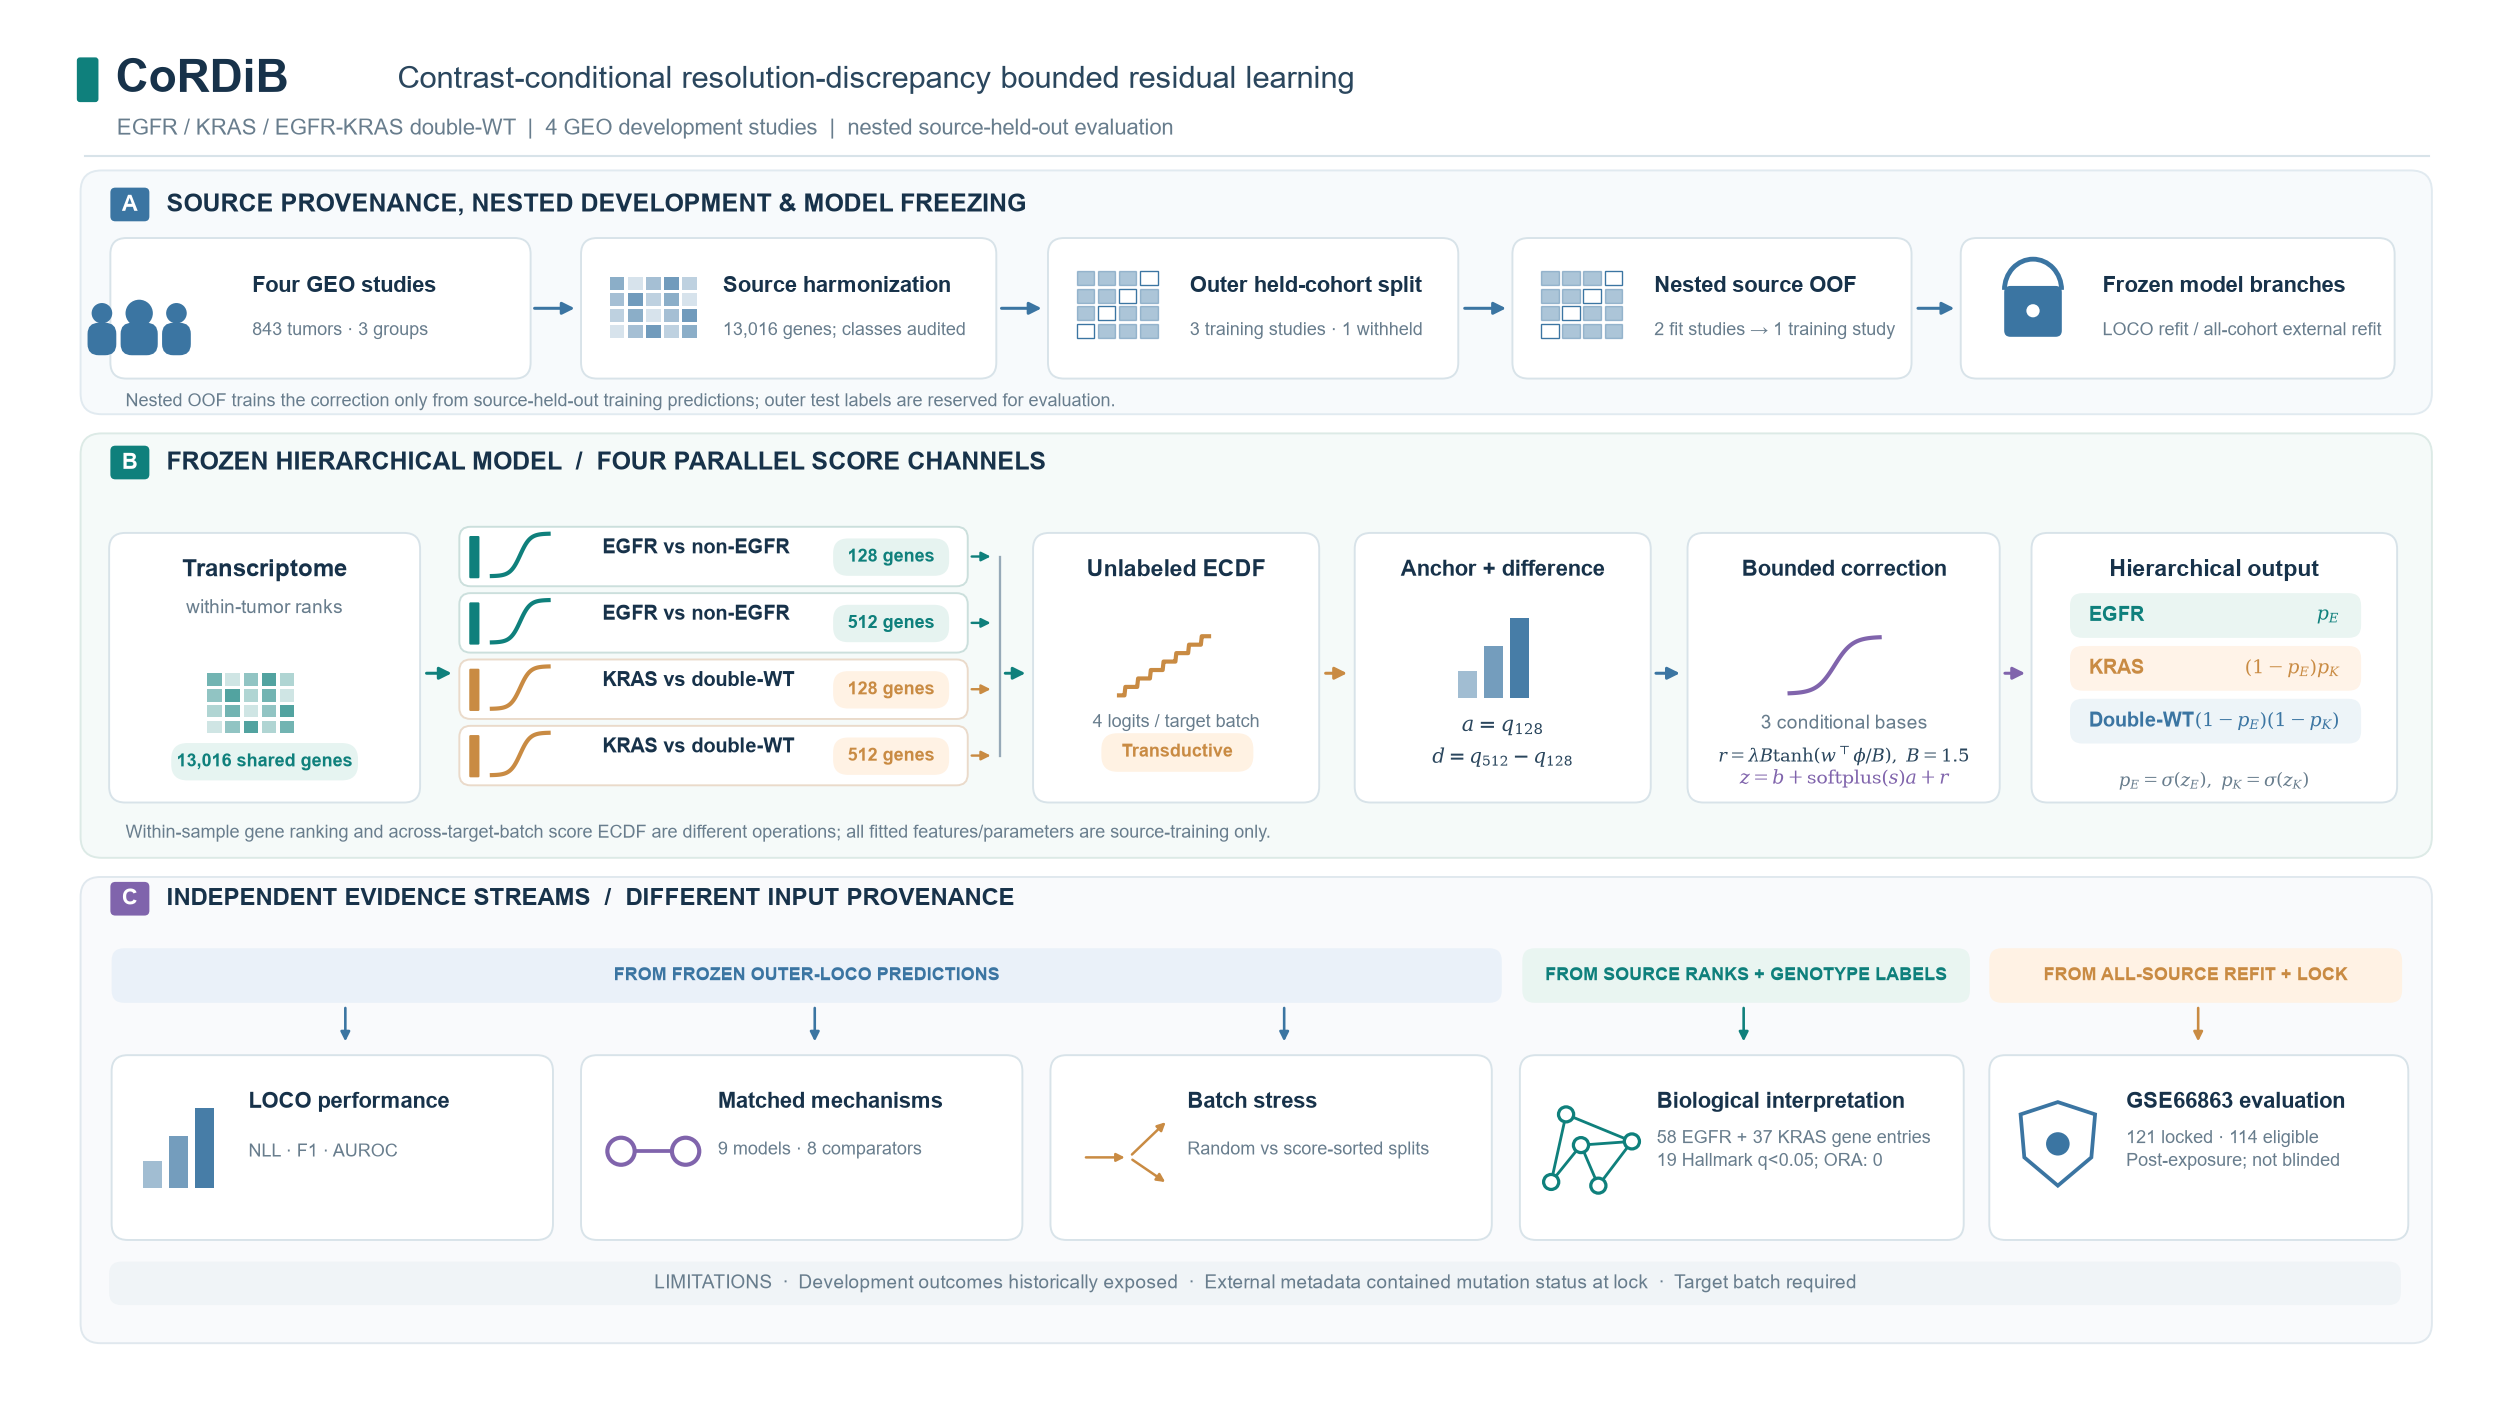

In [25]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import uuid

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import (
    FancyBboxPatch, FancyArrowPatch,
    Rectangle, Circle, Arc
)
from PIL import Image
from IPython.display import display, Image as IPImage

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")

CMR = Path(
    r"D:\LUAD_CMR_2026"
    r"\CELL03_DATA_20261021T090947_420335Z_d6aed8ec"
    r"\cmr_gene_expression.npz"
)

P12 = ROOT / "12_multiresolution_ood_evidence" / "20261023T151555Z_638a3c88"
P14 = ROOT / "14_quantile_residual_transfer" / "20261023T160742Z_f9435239"
BIO = ROOT / "32_biological_interpretation" / "BIOLOGY_20261024T201747Z_c879da1d"
P23 = ROOT / "23_external_prediction_lock" / "20261023T200343Z_0abb47df"
P24 = ROOT / "24_locked_external_label_validation" / "20261023T201758Z_8a4f4ab4"
P28 = ROOT / "28_matched_mechanism_comparison" / "20261024T062048Z_81cc728e"

COHORTS = (
    "GSE13213",
    "GSE31210",
    "GSE32863",
    "GSE72094"
)

COUNTS = {
    "GSE13213": 117,
    "GSE31210": 226,
    "GSE32863": 58,
    "GSE72094": 442
}

LOCK_SHA = (
    "8dc5c7eda0a663145116d7481e155ac1877c28392eeb5090c895adb9fcff07f2"
)

INPUTS = [
    CMR,
    P12 / "PROTOCOL.json",
    P14 / "PROTOCOL.json",
    P14 / "LOCO_PREDICTIONS.csv",
    BIO / "BIOLOGICAL_AUDIT_MANIFEST.json",
    P23 / "FROZEN_EXTERNAL_PREDICTIONS_UNSCORED.csv",
    P24 / "SCORED_FROZEN_EXTERNAL_PREDICTIONS.csv",
    P28 / "EQUAL_COHORT_MODEL_METRICS.csv",
    *[
        P12 / "outer_models" / f"{c}_lr{k}.npz"
        for c in COHORTS
        for k in (128, 512)
    ],
    *[
        P14 / "checkpoints" / f"{c}_q_residual.npz"
        for c in COHORTS
    ]
]

missing = [
    str(p)
    for p in INPUTS
    if not p.is_file()
]

if missing:
    raise FileNotFoundError(
        "Missing archived artifacts:\n"
        + "\n".join(missing)
    )


def sha256(path):
    digest = hashlib.sha256()

    with Path(path).open("rb") as handle:
        for chunk in iter(
            lambda: handle.read(4 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


if sha256(
    P23 / "FROZEN_EXTERNAL_PREDICTIONS_UNSCORED.csv"
) != LOCK_SHA:
    raise ValueError(
        "External frozen prediction checksum mismatch"
    )

with np.load(CMR, allow_pickle=False) as data:
    genes = data["genes"]
    y = np.asarray(data["y"], dtype=int)
    cohort = np.char.upper(
        np.char.strip(
            data["cohort"].astype(str)
        )
    )

if (
    len(y) != 843
    or len(genes) != 13016
    or set(y) != {0, 1, 2}
):
    raise ValueError("CMR data schema mismatch")

if {
    c: int((cohort == c).sum())
    for c in COHORTS
} != COUNTS:
    raise ValueError(
        "Development cohort counts mismatch"
    )

prot12 = json.loads(
    (P12 / "PROTOCOL.json").read_text(
        encoding="utf-8"
    )
)

prot14 = json.loads(
    (P14 / "PROTOCOL.json").read_text(
        encoding="utf-8"
    )
)

if "other two outer training cohorts" not in str(
    prot12.get("oof_strategy", "")
).lower():
    raise ValueError(
        "Nested source OOF protocol mismatch"
    )

if "transductive" not in str(
    prot14.get("mode", "")
).lower():
    raise ValueError(
        "Target-batch protocol mismatch"
    )

if "bounded three-basis" not in str(
    prot14.get("models", {}).get("q_residual", "")
).lower():
    raise ValueError(
        "Residual model protocol mismatch"
    )

if not np.isclose(
    float(prot14["correction_cap_per_head"]),
    1.5
):
    raise ValueError(
        "Residual correction cap mismatch"
    )

for held in COHORTS:
    for resolution in (128, 512):
        path = (
            P12 / "outer_models"
            / f"{held}_lr{resolution}.npz"
        )

        with np.load(
            path,
            allow_pickle=False
        ) as ckpt:
            ids = np.asarray(
                ckpt["gene_indices"],
                dtype=int
            )

            if not (
                resolution <= len(ids) <= 2 * resolution
                and len(np.unique(ids)) == len(ids)
            ):
                raise ValueError(
                    f"Invalid feature mask: {held}/{resolution}"
                )

    path = (
        P14 / "checkpoints"
        / f"{held}_q_residual.npz"
    )

    with np.load(
        path,
        allow_pickle=False
    ) as ckpt:
        for key, dimensions in (
            ("weights", (2, 3)),
            ("raw_scale", (2,)),
            ("bias", (2,))
        ):
            if (
                key not in ckpt.files
                or np.asarray(ckpt[key]).shape != dimensions
            ):
                raise ValueError(
                    f"Invalid residual checkpoint: {held}/{key}"
                )

        lam = float(
            np.asarray(
                ckpt["guard_lambda"]
            ).item()
        )

        if (
            not np.isfinite(lam)
            or not 0 <= lam <= 1
        ):
            raise ValueError(
                f"Invalid residual guard: {held}"
            )

pred = pd.read_csv(
    P14 / "LOCO_PREDICTIONS.csv",
    usecols=[
        "model",
        "held_cohort",
        "gsm"
    ]
)

pred = pred.loc[
    pred.model.eq("q_residual")
].copy()

pred["held_cohort"] = (
    pred.held_cohort
    .astype(str)
    .str.upper()
    .str.strip()
)

if (
    len(pred) != 843
    or pred.duplicated(
        ["held_cohort", "gsm"]
    ).any()
    or pred.held_cohort.value_counts().to_dict() != COUNTS
):
    raise ValueError(
        "Outer held-source prediction roster mismatch"
    )

biology = json.loads(
    (
        BIO / "BIOLOGICAL_AUDIT_MANIFEST.json"
    ).read_text(
        encoding="utf-8"
    )
)

if biology.get("stable_gene_counts") != {
    "EGFR_vs_nonEGFR": 58,
    "KRAS_vs_DWT": 37
}:
    raise ValueError(
        "Stable gene evidence mismatch"
    )

if (
    int(biology.get("pathways_fdr_lt_005", -1)) != 19
    or int(biology.get("ora_fdr_lt_005", -1)) != 0
):
    raise ValueError(
        "Hallmark/ORA evidence mismatch"
    )

if (
    len(
        pd.read_csv(
            P24 / "SCORED_FROZEN_EXTERNAL_PREDICTIONS.csv",
            usecols=["gsm"]
        )
    ) != 114
    or len(
        pd.read_csv(
            P28 / "EQUAL_COHORT_MODEL_METRICS.csv"
        )
    ) != 9
):
    raise ValueError(
        "External or comparator evidence mismatch"
    )

RUN = (
    ROOT
    / "33_submission_display_items"
    / (
        "FIG01_SCIENTIFIC_REVISION_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

RUN.mkdir(
    parents=True,
    exist_ok=False
)

NAVY = "#17324A"
TEXT = "#2A465D"
MUTED = "#687D8D"

BLUE = "#3B75A2"
TEAL = "#0F807C"
GOLD = "#C98B43"
PURPLE = "#8064AC"

FRAME = "#D8E3E9"
GREY = "#96A9B8"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": [
        "Arial",
        "Liberation Sans",
        "DejaVu Sans"
    ],
    "font.size": 10.5,
    "svg.fonttype": "none",
    "axes.unicode_minus": False
})

fig, ax = plt.subplots(
    figsize=(17.0, 9.56),
    facecolor="white"
)

ax.set_xlim(0, 20)
ax.set_ylim(0, 11.25)
ax.axis("off")

fig.subplots_adjust(
    left=0.013,
    right=0.987,
    top=0.982,
    bottom=0.018
)


def rr(
    x, y, w, h,
    fill="white",
    edge=FRAME,
    radius=0.13,
    linewidth=0.92,
    z=2
):
    shape = FancyBboxPatch(
        (x, y),
        w, h,
        boxstyle=(
            f"round,pad=0.012,"
            f"rounding_size={radius}"
        ),
        facecolor=fill,
        edgecolor=edge,
        linewidth=linewidth,
        zorder=z
    )

    ax.add_patch(shape)
    return shape


def txt(
    x, y, value,
    size=10.5,
    color=TEXT,
    weight="normal",
    align="left",
    **kwargs
):
    ax.text(
        x, y, value,
        fontsize=size,
        color=color,
        fontweight=weight,
        ha=align,
        va="center",
        zorder=8,
        **kwargs
    )


def arrow(
    x0, y0, x1, y1,
    color=GREY,
    lw=1.45,
    ms=12,
    style="-|>"
):
    ax.add_patch(
        FancyArrowPatch(
            (x0, y0),
            (x1, y1),
            arrowstyle=style,
            mutation_scale=ms,
            linewidth=lw,
            color=color,
            zorder=6
        )
    )


def icon_people(x, y, color):
    for dx, rad in [
        (0, 0.11),
        (0.30, 0.083),
        (-0.30, 0.083)
    ]:
        ax.add_patch(
            Circle(
                (x + dx, y + 0.20),
                rad,
                facecolor=color,
                edgecolor="none",
                zorder=4
            )
        )

        rr(
            x + dx - rad * 1.25,
            y - 0.13,
            rad * 2.5,
            0.24,
            color,
            color,
            0.09,
            0,
            4
        )


def icon_grid(x, y, color):
    for i in range(4):
        for j in range(5):
            ax.add_patch(
                Rectangle(
                    (
                        x + j * 0.145,
                        y + i * 0.13
                    ),
                    0.118,
                    0.102,
                    facecolor=color,
                    alpha=0.20 + 0.13 * (
                        (i + j * 2) % 5
                    ),
                    edgecolor="none",
                    zorder=4
                )
            )


def icon_folds(x, y, color, n=4):
    for i in range(n):
        for j in range(n):
            held = i == j

            ax.add_patch(
                Rectangle(
                    (
                        x + j * 0.17,
                        y + i * 0.143
                    ),
                    0.14,
                    0.112,
                    facecolor=(
                        "white" if held else color
                    ),
                    edgecolor=color,
                    alpha=(
                        1 if held else 0.42
                    ),
                    linewidth=0.65,
                    zorder=4
                )
            )


def icon_lock(x, y, color):
    ax.add_patch(
        Arc(
            (x + 0.35, y + 0.39),
            0.46,
            0.50,
            theta1=0,
            theta2=180,
            color=color,
            lw=2.3,
            zorder=4
        )
    )

    rr(
        x + 0.13,
        y + 0.02,
        0.44,
        0.39,
        color,
        color,
        0.05,
        0,
        4
    )

    ax.add_patch(
        Circle(
            (x + 0.35, y + 0.22),
            0.045,
            color="white",
            zorder=5
        )
    )


def icon_curve(
    x, y, color,
    kind="s",
    scale=1.0
):
    v = np.linspace(
        -2.5, 2.5, 100
    )

    if kind == "s":
        u = 1 / (
            1 + np.exp(-v * 2.3)
        )

    elif kind == "tanh":
        u = (
            0.5 + 0.42 * np.tanh(v)
        )

    else:
        u = (
            np.round(
                (v + 2.5) / 0.70
            ) / 8
        )

    ax.plot(
        x + (v + 2.5) * 0.145 * scale,
        y + u * 0.55 * scale,
        color=color,
        lw=2,
        zorder=5
    )


def icon_network(x, y, color):
    nodes = np.array([
        [0, 0.05],
        [0.24, 0.35],
        [0.38, 0.02],
        [0.12, 0.60],
        [0.65, 0.38]
    ])

    edges = [
        (0, 1),
        (1, 2),
        (0, 3),
        (3, 4),
        (4, 2),
        (1, 4)
    ]

    for i, j in edges:
        ax.plot(
            [
                x + nodes[i, 0],
                x + nodes[j, 0]
            ],
            [
                y + nodes[i, 1],
                y + nodes[j, 1]
            ],
            color=color,
            lw=1.35,
            zorder=4
        )

    for dx, dy in nodes:
        ax.add_patch(
            Circle(
                (x + dx, y + dy),
                0.061,
                facecolor="white",
                edgecolor=color,
                lw=1.55,
                zorder=5
            )
        )


def icon_metric(x, y, color):
    for j, h in enumerate(
        (0.22, 0.42, 0.65)
    ):
        ax.add_patch(
            Rectangle(
                (x + j * 0.21, y),
                0.15,
                h,
                facecolor=color,
                alpha=0.48 + j * 0.23,
                edgecolor="none",
                zorder=4
            )
        )


def icon_pair(x, y, color):
    ax.plot(
        [x + 0.07, x + 0.59],
        [y + 0.30, y + 0.30],
        color=color,
        lw=1.8,
        zorder=4
    )

    for dx in (0.07, 0.59):
        ax.add_patch(
            Circle(
                (x + dx, y + 0.30),
                0.11,
                facecolor="white",
                edgecolor=color,
                lw=2,
                zorder=5
            )
        )


def icon_split(x, y, color):
    arrow(
        x, y + 0.25,
        x + 0.38, y + 0.25,
        color, 1.2, 8
    )

    arrow(
        x + 0.38, y + 0.25,
        x + 0.70, y + 0.56,
        color, 1.2, 8
    )

    arrow(
        x + 0.38, y + 0.25,
        x + 0.70, y + 0.03,
        color, 1.2, 8
    )


def icon_shield(x, y, color):
    points = np.array([
        [0, 0.60],
        [0.30, 0.70],
        [0.60, 0.60],
        [0.57, 0.25],
        [0.30, 0.02],
        [0.03, 0.25]
    ])

    ax.fill(
        x + points[:, 0],
        y + points[:, 1],
        facecolor="white",
        edgecolor=color,
        lw=1.8,
        zorder=4
    )

    ax.add_patch(
        Circle(
            (x + 0.30, y + 0.36),
            0.095,
            facecolor=color,
            edgecolor="none",
            zorder=5
        )
    )


def card(
    x, y, width,
    label, sublabel,
    icon, accent=BLUE
):
    rr(
        x, y,
        width, 1.12
    )

    icon(
        x + 0.22,
        y + 0.32,
        accent
    )

    txt(
        x + 1.13,
        y + 0.74,
        label,
        size=10.75,
        color=NAVY,
        weight="bold"
    )

    txt(
        x + 1.13,
        y + 0.38,
        sublabel,
        size=8.85,
        color=MUTED
    )


# Header

rr(
    0.51, 10.55,
    0.15, 0.34,
    TEAL, TEAL,
    0.025, 0
)

txt(
    0.81, 10.72,
    "CoRDiB",
    size=22,
    color=NAVY,
    weight="bold"
)

txt(
    3.08, 10.72,
    "Contrast-conditional resolution-discrepancy bounded residual learning",
    size=15.1,
    color=TEXT
)

txt(
    0.82, 10.32,
    "EGFR / KRAS / EGFR-KRAS double-WT  |  "
    "4 GEO development studies  |  "
    "nested source-held-out evaluation",
    size=10.5,
    color=MUTED
)

ax.plot(
    [0.56, 19.44],
    [10.10, 10.10],
    color=FRAME,
    lw=1
)


# Panel A — Source governance

rr(
    0.54, 8.01,
    18.91, 1.96,
    "#F7FAFC",
    "#E1EAF0",
    0.17,
    z=0
)

rr(
    0.78, 9.58,
    0.29, 0.25,
    BLUE, BLUE,
    0.04, 0
)

txt(
    0.925, 9.70,
    "A",
    size=10.4,
    color="white",
    weight="bold",
    align="center"
)

txt(
    1.22, 9.70,
    "SOURCE PROVENANCE, NESTED DEVELOPMENT & MODEL FREEZING",
    size=11.85,
    color=NAVY,
    weight="bold"
)

stages = [
    (
        0.78, 3.36,
        "Four GEO studies",
        "843 tumors · 3 groups",
        icon_people
    ),
    (
        4.57, 3.32,
        "Source harmonization",
        "13,016 genes; classes audited",
        icon_grid
    ),
    (
        8.33, 3.28,
        "Outer held-cohort split",
        "3 training studies · 1 withheld",
        icon_folds
    ),
    (
        12.07, 3.19,
        "Nested source OOF",
        "2 fit studies → 1 training study",
        icon_folds
    ),
    (
        15.68, 3.47,
        "Frozen model branches",
        "LOCO refit / all-cohort external refit",
        icon_lock
    )
]

for x, w, heading, sub, ic in stages:
    card(
        x, 8.30,
        w, heading, sub, ic
    )

for a, b in [
    (4.15, 4.54),
    (7.91, 8.30),
    (11.64, 12.04),
    (15.29, 15.65)
]:
    arrow(
        a, 8.86,
        b, 8.86,
        BLUE
    )

txt(
    0.89, 8.10,
    "Nested OOF trains the correction only from "
    "source-held-out training predictions; "
    "outer test labels are reserved for evaluation.",
    size=8.65,
    color=MUTED
)


# Panel B — CoRDiB architecture

rr(
    0.54, 4.40,
    18.91, 3.43,
    "#F5FAF9",
    "#DCEAE6",
    0.17,
    z=0
)

rr(
    0.78, 7.48,
    0.29, 0.25,
    TEAL, TEAL,
    0.04, 0
)

txt(
    0.925, 7.60,
    "B",
    size=10.4,
    color="white",
    weight="bold",
    align="center"
)

txt(
    1.22, 7.60,
    "FROZEN HIERARCHICAL MODEL  /  FOUR PARALLEL SCORE CHANNELS",
    size=11.85,
    color=NAVY,
    weight="bold"
)

rr(
    0.77, 4.85,
    2.48, 2.17
)

txt(
    2.01, 6.73,
    "Transcriptome",
    size=11.5,
    color=NAVY,
    weight="bold",
    align="center"
)

txt(
    2.01, 6.42,
    "within-tumor ranks",
    size=9.1,
    color=MUTED,
    align="center"
)

icon_grid(
    1.55, 5.40,
    TEAL
)

rr(
    1.27, 5.03,
    1.48, 0.28,
    "#E6F4F1",
    "none",
    0.13,
    0
)

txt(
    2.01, 5.17,
    "13,016 shared genes",
    size=8.8,
    color=TEAL,
    weight="bold",
    align="center"
)

arrow(
    3.28, 5.89,
    3.55, 5.89,
    TEAL
)

branches = [
    (
        6.61,
        "EGFR vs non-EGFR",
        "128",
        TEAL
    ),
    (
        6.07,
        "EGFR vs non-EGFR",
        "512",
        TEAL
    ),
    (
        5.53,
        "KRAS vs double-WT",
        "128",
        GOLD
    ),
    (
        4.99,
        "KRAS vs double-WT",
        "512",
        GOLD
    )
]

for yy, contrast, k, color in branches:
    rr(
        3.59, yy,
        4.07, 0.46,
        "white",
        "#CBDFDC"
        if color == TEAL
        else "#EADACA",
        0.09
    )

    rr(
        3.67,
        yy + 0.065,
        0.058,
        0.32,
        color,
        color,
        0.01,
        0
    )

    icon_curve(
        3.84,
        yy + 0.07,
        color,
        scale=0.63
    )

    txt(
        4.73,
        yy + 0.30,
        contrast,
        size=9.45,
        color=NAVY,
        weight="bold"
    )

    rr(
        6.60,
        yy + 0.085,
        0.91,
        0.28,
        "#E6F3F0"
        if color == TEAL
        else "#FFF2E4",
        "none",
        0.12,
        0
    )

    txt(
        7.055,
        yy + 0.225,
        f"{k} genes",
        size=8.5,
        color=color,
        weight="bold",
        align="center"
    )

    arrow(
        7.67,
        yy + 0.23,
        7.89,
        yy + 0.23,
        color,
        lw=1.15,
        ms=9
    )

ax.plot(
    [7.93, 7.93],
    [5.22, 6.84],
    color=GREY,
    lw=1.1,
    zorder=3
)

arrow(
    7.94, 5.89,
    8.17, 5.89,
    TEAL,
    lw=1.4
)

# Target-batch ECDF

rr(
    8.21, 4.85,
    2.28, 2.17
)

txt(
    9.35, 6.73,
    "Unlabeled ECDF",
    size=10.8,
    color=NAVY,
    weight="bold",
    align="center"
)

icon_curve(
    8.89, 5.71,
    GOLD,
    "step"
)

txt(
    9.35, 5.49,
    "4 logits / target batch",
    size=8.8,
    color=MUTED,
    align="center"
)

rr(
    8.76, 5.10,
    1.20, 0.29,
    "#FFF2E3",
    "none",
    0.13,
    0
)

txt(
    9.36, 5.25,
    "Transductive",
    size=8.8,
    color=GOLD,
    weight="bold",
    align="center"
)

arrow(
    10.52, 5.89,
    10.76, 5.89,
    GOLD
)

# Resolution anchor and discrepancy

rr(
    10.80, 4.85,
    2.36, 2.17
)

txt(
    11.98, 6.73,
    "Anchor + difference",
    size=10.45,
    color=NAVY,
    weight="bold",
    align="center"
)

icon_metric(
    11.62, 5.69,
    BLUE
)

txt(
    11.98, 5.46,
    r"$a=q_{128}$",
    size=10.3,
    align="center"
)

txt(
    11.98, 5.20,
    r"$d=q_{512}-q_{128}$",
    size=9.55,
    align="center"
)

arrow(
    13.18, 5.89,
    13.44, 5.89,
    BLUE
)

# Conditional bounded residual

rr(
    13.48, 4.85,
    2.49, 2.17
)

txt(
    14.73, 6.73,
    "Bounded correction",
    size=10.45,
    color=NAVY,
    weight="bold",
    align="center"
)

icon_curve(
    14.29, 5.68,
    PURPLE,
    "tanh"
)

txt(
    14.73, 5.48,
    "3 conditional bases",
    size=9.15,
    color=MUTED,
    align="center"
)

txt(
    14.73, 5.22,
    r"$r=\lambda B\tanh(w^\top\phi/B),\ B=1.5$",
    size=8.55,
    align="center"
)

txt(
    14.73, 5.03,
    r"$z=b+\mathrm{softplus}(s)a+r$",
    size=8.95,
    color=PURPLE,
    weight="bold",
    align="center"
)

arrow(
    15.99, 5.89,
    16.22, 5.89,
    PURPLE
)

# Three-class output

rr(
    16.25, 4.85,
    2.92, 2.17
)

txt(
    17.71, 6.73,
    "Hierarchical output",
    size=10.9,
    color=NAVY,
    weight="bold",
    align="center"
)

output_classes = [
    (
        "EGFR",
        r"$p_E$",
        TEAL
    ),
    (
        "KRAS",
        r"$(1-p_E)p_K$",
        GOLD
    ),
    (
        "Double-WT",
        r"$(1-p_E)(1-p_K)$",
        BLUE
    )
]

for j, (label, formula, color) in enumerate(
    output_classes
):
    yy = 6.19 - j * 0.43

    rr(
        16.56, yy,
        2.32, 0.34,
        [
            "#EAF5F2",
            "#FFF3E8",
            "#EDF4F8"
        ][j],
        "none",
        0.10,
        0
    )

    txt(
        16.70,
        yy + 0.17,
        label,
        size=9.55,
        color=color,
        weight="bold"
    )

    txt(
        18.72,
        yy + 0.17,
        formula,
        size=9.10,
        color=color,
        align="right"
    )

txt(
    17.71, 5.01,
    r"$p_E=\sigma(z_E),\ p_K=\sigma(z_K)$",
    size=8.55,
    color=MUTED,
    align="center"
)

txt(
    0.89, 4.59,
    "Within-sample gene ranking and across-target-batch "
    "score ECDF are different operations; "
    "all fitted features/parameters are source-training only.",
    size=8.85,
    color=MUTED
)


# Panel C — Separate evidence origins

rr(
    0.54, 0.45,
    18.91, 3.77,
    "#F9FAFC",
    "#E0E8EE",
    0.16,
    z=0
)

rr(
    0.78, 3.93,
    0.29, 0.25,
    PURPLE, PURPLE,
    0.04, 0
)

txt(
    0.925, 4.055,
    "C",
    size=10.4,
    color="white",
    weight="bold",
    align="center"
)

txt(
    1.22, 4.055,
    "INDEPENDENT EVIDENCE STREAMS  /  DIFFERENT INPUT PROVENANCE",
    size=11.65,
    color=NAVY,
    weight="bold"
)

feeds = [
    (
        0.79, 11.17,
        "FROM FROZEN OUTER-LOCO PREDICTIONS",
        "#EAF1F9",
        BLUE
    ),
    (
        12.15, 3.58,
        "FROM SOURCE RANKS + GENOTYPE LABELS",
        "#E9F5F1",
        TEAL
    ),
    (
        15.91, 3.30,
        "FROM ALL-SOURCE REFIT + LOCK",
        "#FFF2E4",
        GOLD
    )
]

for x, w, label, bg, color in feeds:
    rr(
        x, 3.22,
        w, 0.42,
        bg,
        "none",
        0.10,
        0
    )

    txt(
        x + w / 2,
        3.43,
        label,
        size=8.65,
        color=color,
        weight="bold",
        align="center"
    )

for x in (
    2.66,
    6.44,
    10.22
):
    arrow(
        x, 3.20,
        x, 2.86,
        BLUE,
        lw=1.25,
        ms=9
    )

arrow(
    13.92, 3.20,
    13.92, 2.86,
    TEAL,
    lw=1.25,
    ms=9
)

arrow(
    17.58, 3.20,
    17.58, 2.86,
    GOLD,
    lw=1.25,
    ms=9
)

readouts = [
    (
        0.79, 3.53,
        "LOCO performance",
        "NLL · F1 · AUROC",
        icon_metric,
        BLUE
    ),
    (
        4.57, 3.53,
        "Matched mechanisms",
        "9 models · 8 comparators",
        icon_pair,
        PURPLE
    ),
    (
        8.35, 3.53,
        "Batch stress",
        "Random vs score-sorted splits",
        icon_split,
        GOLD
    ),
    (
        12.13, 3.55,
        "Biological interpretation",
        "58 EGFR + 37 KRAS gene entries\n"
        "19 Hallmark q<0.05; ORA: 0",
        icon_network,
        TEAL
    ),
    (
        15.91, 3.35,
        "GSE66863 evaluation",
        "121 locked · 114 eligible\n"
        "Post-exposure; not blinded",
        icon_shield,
        BLUE
    )
]

for x, w, heading, detail, icon, color in readouts:
    rr(
        x, 1.29,
        w, 1.48
    )

    icon(
        x + 0.24,
        1.70,
        color
    )

    txt(
        x + 1.09,
        2.40,
        heading,
        size=10.35,
        color=NAVY,
        weight="bold"
    )

    txt(
        x + 1.09,
        2.01,
        detail,
        size=8.65,
        color=MUTED,
        linespacing=1.35
    )

rr(
    0.77, 0.76,
    18.43, 0.33,
    "#F0F4F7",
    "none",
    0.10,
    0
)

txt(
    9.99, 0.925,
    "LIMITATIONS  ·  Development outcomes historically exposed  ·  "
    "External metadata contained mutation status at lock  ·  "
    "Target batch required",
    size=9.05,
    color=MUTED,
    align="center"
)


# Exports

STEM = "FIG01_CoRDiB_Method_Framework_Revised"

SVG = RUN / f"{STEM}.svg"
TIFF = RUN / f"{STEM}.tiff"
PNG = RUN / f"{STEM}.png"

fig.savefig(
    SVG,
    facecolor="white",
    bbox_inches="tight"
)

fig.savefig(
    TIFF,
    dpi=300,
    facecolor="white",
    bbox_inches="tight"
)

fig.savefig(
    PNG,
    dpi=150,
    facecolor="white",
    bbox_inches="tight"
)

plt.close(fig)

with Image.open(TIFF) as im:
    pixels = im.size
    dpi = tuple(
        float(d)
        for d in im.info.get(
            "dpi", (0, 0)
        )
    )

if (
    min(pixels) < 1000
    or len(dpi) != 2
    or any(
        abs(d - 300) > 2
        for d in dpi
    )
):
    raise RuntimeError(
        "TIFF verification failed"
    )

if "<text" not in SVG.read_text(
    encoding="utf-8"
):
    raise RuntimeError(
        "Editable SVG text missing"
    )

caption = (
    "Figure 1. CoRDiB training and inference workflow. "
    "(A) Across four LUAD cohorts, training-only gene "
    "selection, source-held-out OOF evidence, and nested "
    "leave-one-cohort-out validation are separated from "
    "final all-development refitting for external evaluation. "
    "(B) Within-sample gene ranks enter EGFR-versus-non-EGFR "
    "and KRAS-versus-double-WT logistic evidence heads at "
    "128 and 512 genes per contrast. Four logits are "
    "normalized by their empirical distributions across "
    "unlabeled target samples. Lower-resolution anchors "
    "and higher-minus-lower discrepancies drive a three-basis "
    "bounded correction (B=1.5), followed by hierarchical "
    "three-class probabilities. "
    "(C) Frozen outer-LOCO predictions support performance "
    "comparisons and batch sensitivity. Source expression, "
    "genotype labels and selected feature masks support "
    "exploratory biological analyses. A separate "
    "all-development refit supplies the archived GSE66863 "
    "predictions. Icons are schematic, not measured data. "
    "Historical outcome exposure and transductive batch "
    "dependence limit inference."
)

(
    RUN / "FIG01_CAPTION.md"
).write_text(
    caption + "\n",
    encoding="utf-8"
)

manifest = {
    "phase": "FIG01_SCIENTIFIC_CONNECTION_REVISION",
    "development_n": 843,
    "outer_cohorts": COUNTS,
    "score_channels": [
        "E128", "E512",
        "K128", "K512"
    ],
    "model_selected_gene_entries": 95,
    "hallmark_signature_q_lt_005": 19,
    "significant_selected_gene_ora": 0,
    "external_scored_n": 114,
    "tiff_dpi": dpi,
    "tiff_pixels": pixels,
    "model_retrained": False,
    "original_archives_modified": False,
    "source_sha256": {
        str(path): sha256(path)
        for path in INPUTS
    }
}

(
    RUN / "AUDIT_MANIFEST.json"
).write_text(
    json.dumps(
        manifest,
        indent=2
    ),
    encoding="utf-8"
)

print("FIG01_SCIENTIFIC_REVISION_COMPLETE")
print("SOURCE_CHECK: PASS")
print(
    "BRANCHES: 4 | OUTPUT_CLASSES: 3 | "
    "EVIDENCE_STREAMS: 3"
)
print(
    "BIOLOGY: EGFR=58, KRAS=37, "
    "HALLMARK=19, ORA=0"
)
print("FIGURE_TIFF_DPI:", dpi)
print("PIXELS:", pixels)
print("ORIGINAL_ARCHIVES_MODIFIED: False")
print("OUTPUT:", RUN)

display(
    IPImage(
        filename=str(PNG)
    )
)

PHASE34A_PRINT_READABILITY_AUDIT_COMPLETE
FIGURES_INSPECTED: 6
TARGET_PRINT_WIDTH_MM: 183.0
PRINT_READABILITY_SUMMARY:
                 figure  print_height_mm  effective_raster_dpi  minimum_print_font_pt  median_print_font_pt  fraction_below_5pt       font_status geometry_status
          Main Figure 1          102.803               697.737                  3.654                 4.063               0.914 REVIEW_SMALL_TEXT            PASS
          Main Figure 2           61.273               590.307                  4.073                 5.091               0.353 REVIEW_SMALL_TEXT            PASS
          Main Figure 3          129.720               602.105                  3.894                 4.293               0.829 REVIEW_SMALL_TEXT            PASS
          Main Figure 4          139.593               528.403                  4.545                 5.682               0.175 REVIEW_SMALL_TEXT            PASS
Supplementary Figure S1          102.915               350.464         

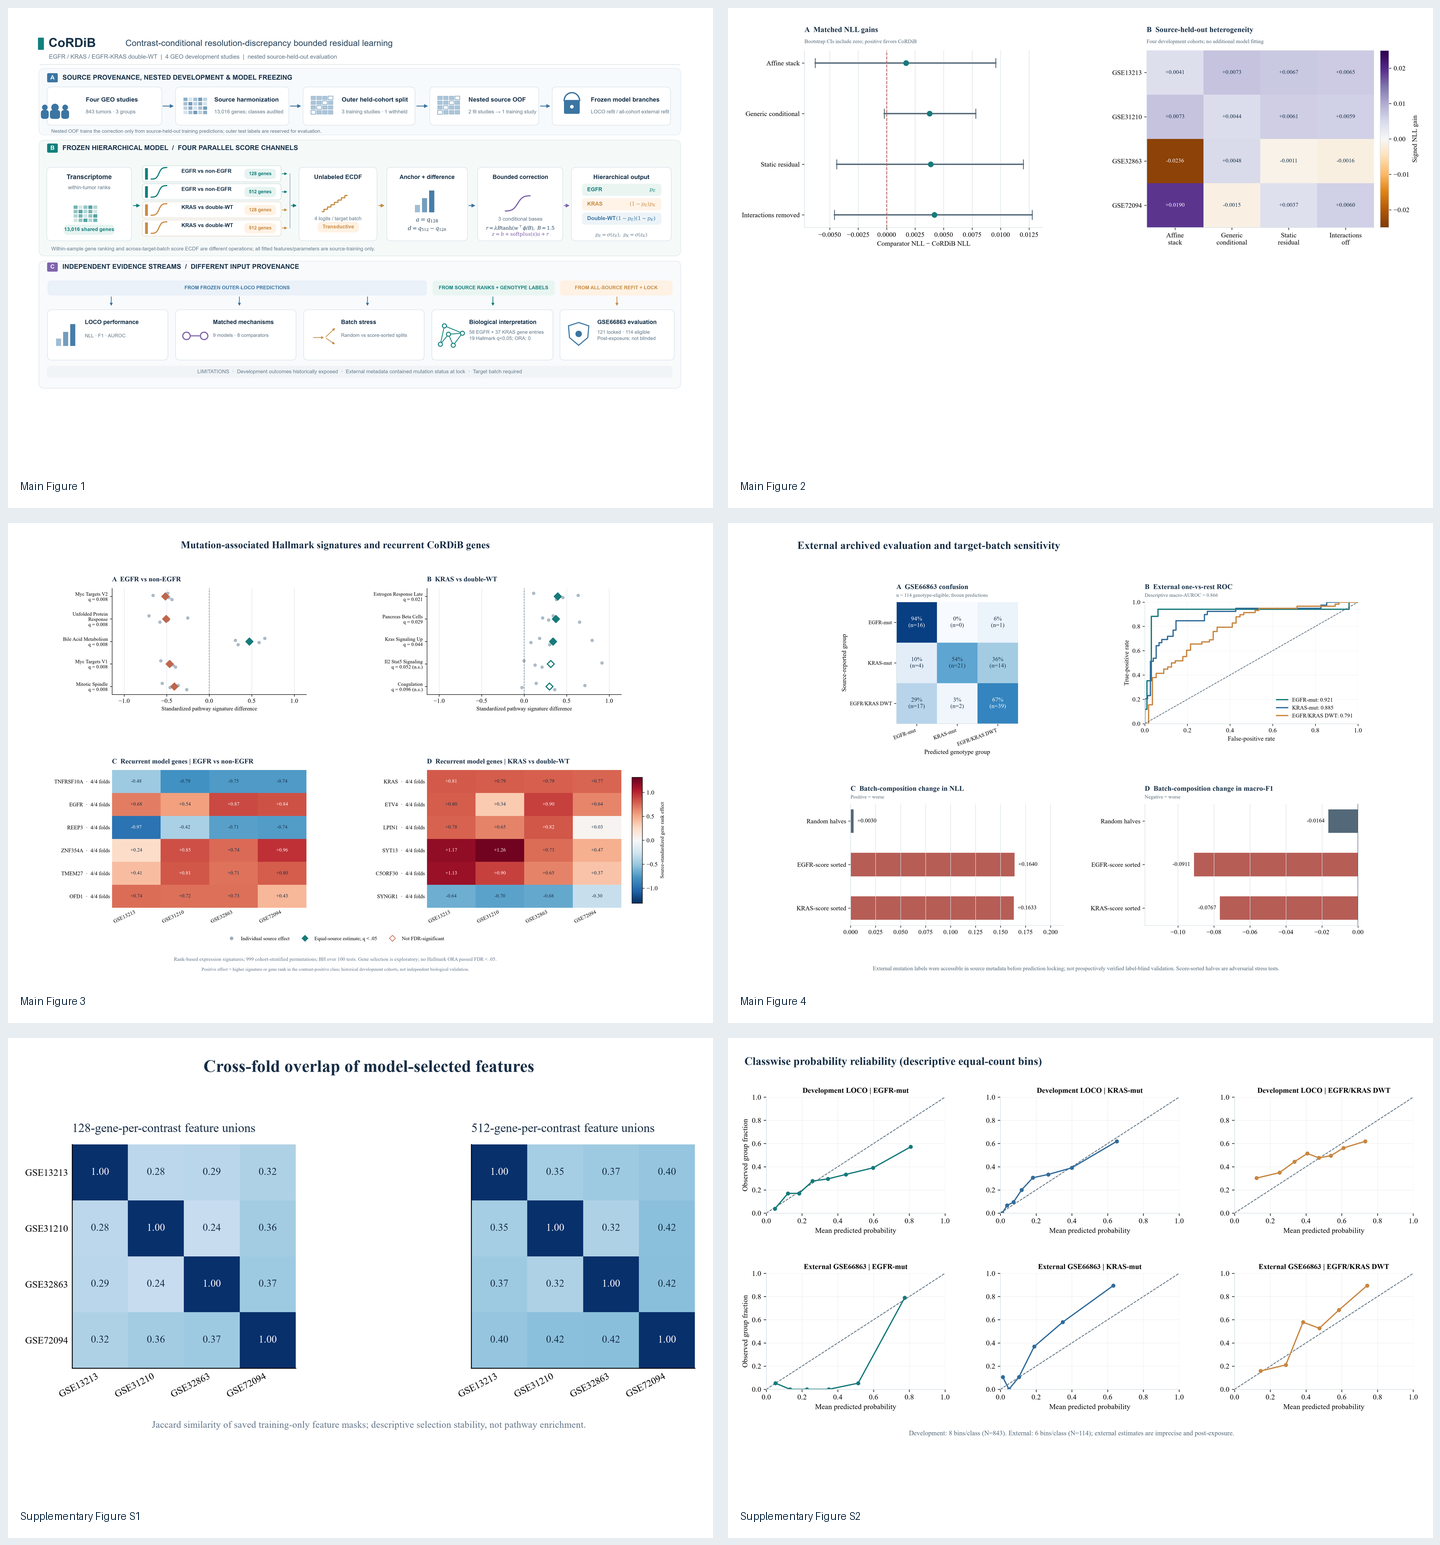

In [26]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import re
import uuid
import xml.etree.ElementTree as ET

import pandas as pd
from PIL import Image, ImageDraw
from IPython.display import display, Image as IPImage

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")

FINAL = (
    ROOT / "33_submission_display_items"
    / "FINAL_4FIG_2TABLE_20261024T203145Z_91ef7c82"
)

FIG1 = (
    ROOT / "33_submission_display_items"
    / "FIG01_SCIENTIFIC_REVISION_20261024T210553Z_475fc9c7"
)

SOURCES = [
    (
        "Main Figure 1",
        FIG1,
        "FIG01_CoRDiB_Method_Framework_Revised"
    ),
    (
        "Main Figure 2",
        FINAL,
        "MAIN_FIG02_Matched_Mechanisms"
    ),
    (
        "Main Figure 3",
        FINAL,
        "MAIN_FIG03_Biological_Interpretation"
    ),
    (
        "Main Figure 4",
        FINAL,
        "MAIN_FIG04_External_and_Batch_Sensitivity"
    ),
    (
        "Supplementary Figure S1",
        FINAL,
        "SUPP_FIG_S1_Gene_Selection_Jaccard"
    ),
    (
        "Supplementary Figure S2",
        FINAL,
        "SUPP_FIG_S2_Classwise_Calibration"
    ),
]

TARGET_WIDTH_MM = 183.0
TARGET_DPI = 300
MIN_PRINT_FONT_PT = 5.0
MAX_PRINT_HEIGHT_MM = 170.0

PRINT_INCH = TARGET_WIDTH_MM / 25.4
TARGET_PIXELS = round(PRINT_INCH * TARGET_DPI)


def sha256(path):
    h = hashlib.sha256()

    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(4 * 1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def inspect_svg_fonts(path):
    root = ET.parse(path).getroot()

    viewbox = root.attrib.get("viewBox", "")

    try:
        svg_width = float(
            viewbox.replace(",", " ").split()[2]
        )
    except (ValueError, IndexError):
        raise ValueError(
            f"Cannot determine SVG viewBox width: {path}"
        )

    if svg_width <= 0:
        raise ValueError(
            f"Invalid SVG width: {path}"
        )

    sizes = []

    for element in root.iter():
        if element.tag.split("}")[-1] != "text":
            continue

        style = element.attrib.get("style", "")

        match = re.search(
            r"font-size\s*:\s*([0-9.]+)px",
            style
        )

        if match is None:
            match = re.search(
                r"font\s*:\s*[^;]*?([0-9.]+)px",
                style
            )

        if match is None:
            direct = element.attrib.get(
                "font-size", ""
            )

            match = re.match(
                r"([0-9.]+)(?:px|pt)?$",
                direct
            )

        if match is not None:
            source_size = float(
                match.group(1)
            )

            final_size = (
                source_size
                * PRINT_INCH
                * 72.0
                / svg_width
            )

            sizes.append(final_size)

    return sorted(sizes), svg_width


missing = []

for _, folder, stem in SOURCES:
    for ext in ("tiff", "svg"):
        path = folder / f"{stem}.{ext}"

        if not path.is_file():
            missing.append(str(path))

if missing:
    raise FileNotFoundError(
        "Missing figure exports:\n"
        + "\n".join(missing)
    )

RUN = (
    ROOT / "34_submission_quality_assurance"
    / (
        "PRINT_SIZE_REVIEW_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

RUN.mkdir(parents=True, exist_ok=False)

records = []
proof_paths = []

for number, (name, folder, stem) in enumerate(
    SOURCES, start=1
):
    tiff = folder / f"{stem}.tiff"
    svg = folder / f"{stem}.svg"

    font_sizes, svg_width = inspect_svg_fonts(svg)

    with Image.open(tiff) as image:
        original_width, original_height = image.size

        source_dpi = image.info.get(
            "dpi", (0, 0)
        )

        effective_dpi = (
            original_width / PRINT_INCH
        )

        print_height_mm = (
            TARGET_WIDTH_MM
            * original_height
            / original_width
        )

        proof_height = round(
            TARGET_PIXELS
            * original_height
            / original_width
        )

        proof = (
            image.convert("RGB")
            .resize(
                (
                    TARGET_PIXELS,
                    proof_height
                ),
                Image.Resampling.LANCZOS
            )
        )

    output = (
        RUN / (
            f"PRINT_PROOF_{number:02d}_"
            + stem + ".png"
        )
    )

    proof.save(
        output,
        dpi=(TARGET_DPI, TARGET_DPI)
    )

    proof_paths.append((name, output))

    total_labels = len(font_sizes)

    below_minimum = sum(
        size < MIN_PRINT_FONT_PT
        for size in font_sizes
    )

    fraction_small = (
        below_minimum / total_labels
        if total_labels else None
    )

    median_font = (
        font_sizes[total_labels // 2]
        if total_labels else None
    )

    font_status = (
        "NO_EDITABLE_TEXT_FOUND"
        if not total_labels
        else (
            "REVIEW_SMALL_TEXT"
            if below_minimum > 0
            else "PASS_5PT_SCREEN"
        )
    )

    geometry_status = (
        "PASS"
        if (
            effective_dpi >= TARGET_DPI
            and print_height_mm <= MAX_PRINT_HEIGHT_MM
        )
        else "REVIEW"
    )

    records.append({
        "figure": name,
        "source_file": str(tiff),
        "print_width_mm": TARGET_WIDTH_MM,
        "print_height_mm": print_height_mm,
        "effective_raster_dpi": effective_dpi,
        "svg_text_elements_with_font": total_labels,
        "minimum_print_font_pt": (
            min(font_sizes)
            if font_sizes else None
        ),
        "median_print_font_pt": median_font,
        "maximum_print_font_pt": (
            max(font_sizes)
            if font_sizes else None
        ),
        "text_elements_below_5pt": below_minimum,
        "fraction_below_5pt": fraction_small,
        "font_status": font_status,
        "geometry_status": geometry_status,
        "tiff_sha256": sha256(tiff),
        "svg_sha256": sha256(svg),
        "proof_file": str(output)
    })

qa = pd.DataFrame(records)

qa.to_csv(
    RUN / "FIGURE_PRINT_READABILITY_AUDIT.csv",
    index=False
)


# Contact sheet for visual inspection

TILE_WIDTH = 720
TILE_HEIGHT = 515
COLUMNS = 2

ROWS = (
    len(proof_paths) + COLUMNS - 1
) // COLUMNS

sheet = Image.new(
    "RGB",
    (
        COLUMNS * TILE_WIDTH,
        ROWS * TILE_HEIGHT
    ),
    "#E8EDF1"
)

draw = ImageDraw.Draw(sheet)

for i, (name, path) in enumerate(proof_paths):
    with Image.open(path) as image:
        thumb = image.convert("RGB")
        thumb.thumbnail(
            (
                TILE_WIDTH - 34,
                TILE_HEIGHT - 76
            ),
            Image.Resampling.LANCZOS
        )

    x0 = (i % COLUMNS) * TILE_WIDTH
    y0 = (i // COLUMNS) * TILE_HEIGHT

    draw.rectangle(
        (
            x0 + 8,
            y0 + 8,
            x0 + TILE_WIDTH - 8,
            y0 + TILE_HEIGHT - 8
        ),
        fill="white"
    )

    x = x0 + (
        TILE_WIDTH - thumb.width
    ) // 2

    y = y0 + 22

    sheet.paste(
        thumb, (x, y)
    )

    draw.text(
        (
            x0 + 20,
            y0 + TILE_HEIGHT - 35
        ),
        name,
        fill="#17324A"
    )

sheet_path = (
    RUN / "SIX_FIGURES_VISUAL_CONTACT_SHEET.png"
)

sheet.save(sheet_path)

manifest = {
    "phase": "34A_PRINT_SIZE_READABILITY",
    "target_width_mm": TARGET_WIDTH_MM,
    "target_dpi": TARGET_DPI,
    "reference_min_font_pt": MIN_PRINT_FONT_PT,
    "figures_inspected": len(SOURCES),
    "figure_geometry_pass": int(
        qa.geometry_status.eq("PASS").sum()
    ),
    "figure_text_warnings": int(
        qa.font_status.ne("PASS_5PT_SCREEN").sum()
    ),
    "scientific_models_modified": False,
    "original_figures_modified": False,
    "visual_approval_automatic": False
}

(
    RUN / "QA_MANIFEST.json"
).write_text(
    json.dumps(
        manifest,
        indent=2
    ),
    encoding="utf-8"
)

print("PHASE34A_PRINT_READABILITY_AUDIT_COMPLETE")

print(
    "FIGURES_INSPECTED:",
    len(qa)
)

print(
    "TARGET_PRINT_WIDTH_MM:",
    TARGET_WIDTH_MM
)

print("PRINT_READABILITY_SUMMARY:")

print(
    qa[
        [
            "figure",
            "print_height_mm",
            "effective_raster_dpi",
            "minimum_print_font_pt",
            "median_print_font_pt",
            "fraction_below_5pt",
            "font_status",
            "geometry_status"
        ]
    ].round(3).to_string(index=False)
)

print("OUTPUT:", RUN)
print("ORIGINAL_FIGURES_MODIFIED: False")

display(
    IPImage(
        filename=str(sheet_path)
    )
)

findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


FINAL_PUBLICATION_ITEMS_COMPLETE
FIGURES: 4 MAIN + 2 SUPPLEMENTARY; INDIVIDUAL TIFF/SVG/PNG
TABLES: 2 MAIN + 2 SUPPLEMENTARY
PRINT_WIDTH_MM: 183.0
PRINT_FONT_QA:
                              figure  min_font_pt_at_183mm  small_text_count  print_height_mm
 MAIN_FIG01_Methodological_Framework                   6.0                 0           127.02
       MAIN_FIG02_Matched_Mechanisms                   5.9                 0            81.30
MAIN_FIG03_Biological_Interpretation                   5.9                 0           147.35
       MAIN_FIG04_External_and_Batch                   5.9                 0           133.38
          SUPP_FIG_S1_Gene_Stability                   6.0                 0            80.03
 SUPP_FIG_S2_Probability_Reliability                   5.9                 0           110.51
EXTERNAL_MACRO_AUROC: 0.865747
MODEL_RETRAINED: False; ORIGINAL_ARCHIVES_MODIFIED: False
OUTPUT: D:\LUAD_DATAFIRST_METHOD_2026\35_final_publication_figures\FINAL_183MM_20261024T211

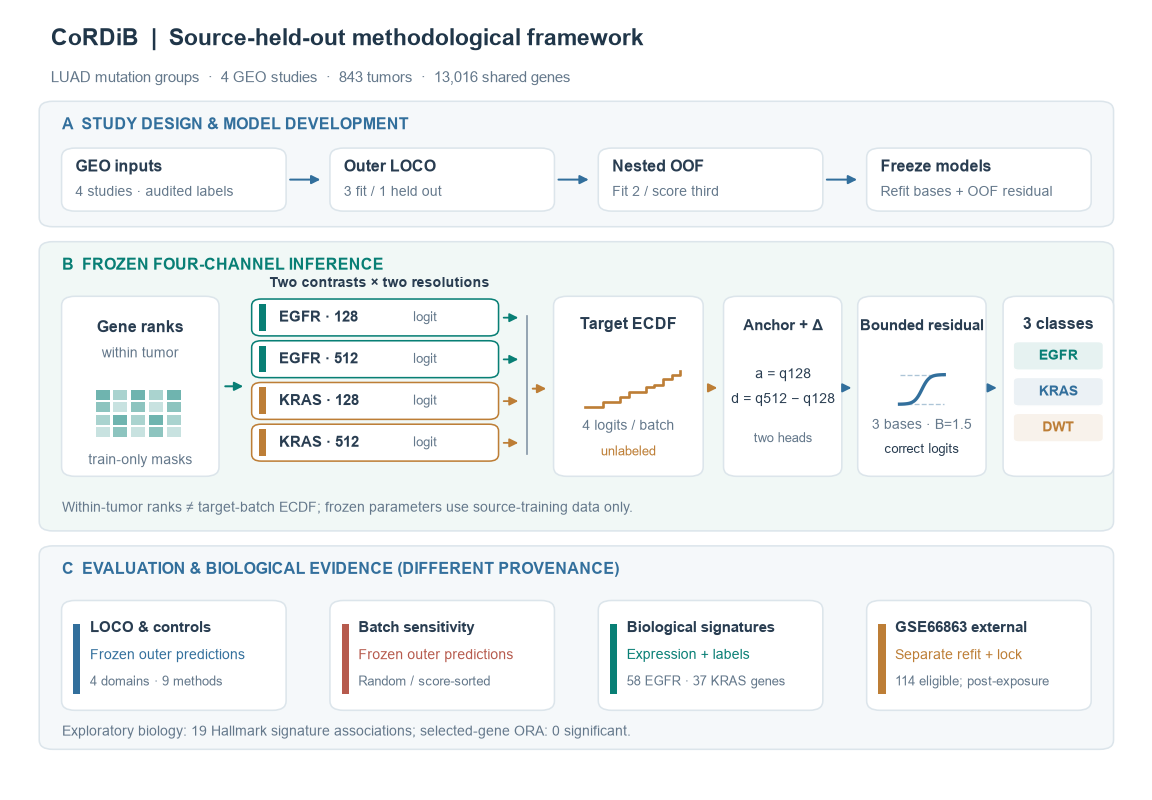

In [27]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import re
import uuid
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from statsmodels.stats.multitest import multipletests
from PIL import Image
from IPython.display import display, Image as IPImage

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")
CMR = Path(r"D:\LUAD_CMR_2026\CELL03_DATA_20261021T090947_420335Z_d6aed8ec\cmr_gene_expression.npz")
P12 = ROOT / "12_multiresolution_ood_evidence" / "20261023T151555Z_638a3c88"
P14 = ROOT / "14_quantile_residual_transfer" / "20261023T160742Z_f9435239"
P24 = ROOT / "24_locked_external_label_validation" / "20261023T201758Z_8a4f4ab4"
P28 = ROOT / "28_matched_mechanism_comparison" / "20261024T062048Z_81cc728e"
P29 = ROOT / "29_manuscript_evidence_consolidation" / "29D_consolidated_evidence_corrected_20261024T193139Z_197e033c"
P32 = ROOT / "32_biological_interpretation" / "BIOLOGY_20261024T201747Z_c879da1d"

COHORTS = ("GSE13213", "GSE31210", "GSE32863", "GSE72094")
CLASSES = ("EGFR", "KRAS", "DWT")
PCOLS = ("p_egfr", "p_kras", "p_dwt")
EXPECTED = {
    "GSE13213": 117,
    "GSE31210": 226,
    "GSE32863": 58,
    "GSE72094": 442
}
CONTRASTS = ("EGFR_vs_nonEGFR", "KRAS_vs_DWT")
COMP = (
    "AFFINE_STACK_6",
    "GENERIC_CONDITIONAL_6",
    "q_static",
    "CORDIB_INTERACTIONS_OFF"
)

INPUTS = {
    "cmr": CMR,
    "cohorts": P29 / "TABLE_01_GEO_LABEL_PROVENANCE.csv",
    "models": P29 / "TABLE_04_MATCHED_MECHANISM_CONTROLS.csv",
    "paired": P29 / "TABLE_07_PAIRED_NLL_COMPARISONS.csv",
    "per_cohort": P28 / "PER_COHORT_PAIRED_COMPARISONS.csv",
    "stress": P29 / "TABLE_05_BATCH_STRESS.csv",
    "development_predictions": P14 / "LOCO_PREDICTIONS.csv",
    "external_predictions": P24 / "SCORED_FROZEN_EXTERNAL_PREDICTIONS.csv",
    "hallmark": P32 / "HALLMARK_COHORT_STRATIFIED_PERMUTATION.csv",
    "ora": P32 / "STABLE_GENES_HALLMARK_ORA.csv",
    "genes": P32 / "STABLE_MODEL_GENE_CANDIDATES.csv",
    "biological_manifest": P32 / "BIOLOGICAL_AUDIT_MANIFEST.json",
    "method_protocol": P14 / "PROTOCOL.json",
}

CHECKPOINTS = [
    P12 / "outer_models" / f"{held}_lr{k}.npz"
    for held in COHORTS
    for k in (128, 512)
]

missing = [
    str(p) for p in list(INPUTS.values()) + CHECKPOINTS
    if not p.is_file()
]

if missing:
    raise FileNotFoundError(
        "Missing archived inputs:\n" + "\n".join(missing)
)


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(
            lambda: handle.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()


def read(name):
    return pd.read_csv(INPUTS[name])


with np.load(CMR, allow_pickle=False) as z:
    cohort_cmr = np.char.upper(
        np.char.strip(z["cohort"].astype(str))
    )
    labels_cmr = np.asarray(z["y"], dtype=int)
    n_genes = len(z["genes"])

if (
    len(labels_cmr) != 843
    or n_genes != 13016
    or set(labels_cmr) != {0, 1, 2}
):
    raise ValueError("Canonical matrix schema mismatch")

if {
    c: int((cohort_cmr == c).sum())
    for c in COHORTS
} != EXPECTED:
    raise ValueError("Canonical cohort sizes changed")

cohort_provenance = read("cohorts")
metrics = read("models")
paired = read("paired")
per_cohort = read("per_cohort")
stress = read("stress")
dev = read("development_predictions")
ext = read("external_predictions")
hallmark = read("hallmark")
ora = read("ora")
genes = read("genes")

with INPUTS["biological_manifest"].open(encoding="utf-8") as f:
    bio_manifest = json.load(f)

with INPUTS["method_protocol"].open(encoding="utf-8") as f:
    protocol = json.load(f)

if not np.isclose(
    float(protocol["correction_cap_per_head"]), 1.5
):
    raise ValueError("Bounded correction protocol mismatch")

if "transductive" not in str(
    protocol.get("mode", "")
).lower():
    raise ValueError("Batch inference protocol mismatch")

if (
    len(metrics) != 9
    or not metrics.model.is_unique
    or len(paired) != 8
    or not paired.comparator.is_unique
):
    raise ValueError("Matched-model archive incomplete")

if (
    len(per_cohort) != 32
    or per_cohort.duplicated(
        ["cohort", "comparator"]
    ).any()
):
    raise ValueError("Cohort-comparator archive incomplete")

if int(cohort_provenance.concordant.sum()) != 843:
    raise ValueError("Source-level genotype concordance changed")

if (
    len(hallmark) != 100
    or len(ora) != 100
    or len(genes) != 95
):
    raise ValueError("Biological results file sizes changed")

if (
    int((hallmark.fdr_bh_all_contrasts < .05).sum()) != 19
    or int((ora.fdr_bh_all_contrasts < .05).sum()) != 0
):
    raise ValueError("Biological FDR results changed")

if bio_manifest.get("stable_gene_counts") != {
    "EGFR_vs_nonEGFR": 58,
    "KRAS_vs_DWT": 37
}:
    raise ValueError("Biological model gene counts changed")

if not np.allclose(
    multipletests(
        hallmark.permutation_p,
        method="fdr_bh"
    )[1],
    hallmark.fdr_bh_all_contrasts,
    atol=1e-10
):
    raise ValueError("Hallmark FDR replay mismatch")

if not np.allclose(
    multipletests(
        ora.hypergeometric_p,
        method="fdr_bh"
    )[1],
    ora.fdr_bh_all_contrasts,
    atol=1e-10
):
    raise ValueError("Hallmark ORA FDR replay mismatch")

models = metrics.set_index("model")
pair = paired.set_index("comparator")

if (
    not set(COMP).issubset(pair.index)
    or not set(COMP).issubset(models.index)
):
    raise ValueError("Main comparator missing")

if not np.isclose(
    float(models.loc["q_residual", "nll"]),
    0.9092707550834408,
    atol=1e-8
):
    raise ValueError("Original CoRDiB metric mismatch")

for name in COMP:
    delta = float(
        per_cohort.loc[
            per_cohort.comparator.eq(name),
            "nll_gain_cordib"
        ].mean()
    )

    expected = float(
        pair.loc[
            name,
            "mean_equal_cohort_nll_gain"
        ]
    )

    if abs(delta - expected) > 1e-10:
        raise ValueError(
            f"Cohort-level model comparison mismatch: {name}"
        )

selection = {}

for c in COHORTS:
    for k in (128, 512):
        path = (
            P12 / "outer_models"
            / f"{c}_lr{k}.npz"
        )

        with np.load(path, allow_pickle=False) as z:
            values = np.asarray(
                z["gene_indices"],
                dtype=int
            )

        if not (
            k <= len(values) <= 2 * k
            and len(np.unique(values)) == len(values)
            and (values >= 0).all()
            and (values < n_genes).all()
        ):
            raise ValueError(
                f"Outer-fold feature-mask integrity: {c}, {k}"
            )

        selection[(c, k)] = set(values.tolist())

dev = dev.loc[
    dev.model.eq("q_residual")
].copy()

dev.held_cohort = (
    dev.held_cohort.astype(str).str.upper().str.strip()
)
dev.gsm = (
    dev.gsm.astype(str).str.upper().str.strip()
)

if (
    len(dev) != 843
    or dev.duplicated(
        ["held_cohort", "gsm"]
    ).any()
    or dev.held_cohort.value_counts().to_dict() != EXPECTED
):
    raise ValueError(
        "Development LOCO prediction roster mismatch"
    )

if (
    len(ext) != 114
    or ext.gsm.astype(str).duplicated().any()
):
    raise ValueError(
        "External eligible prediction roster mismatch"
    )

YDEV = dev.true_class.to_numpy(dtype=int)
PDEV = dev[list(PCOLS)].to_numpy(dtype=float)
YEXT = ext.true_class.to_numpy(dtype=int)
PEXT = ext[list(PCOLS)].to_numpy(dtype=float)

for label, y, p in (
    ("development", YDEV, PDEV),
    ("external", YEXT, PEXT)
):
    if (
        set(y) != {0, 1, 2}
        or not np.isfinite(p).all()
        or (p < 0).any()
        or (p > 1).any()
        or np.max(np.abs(p.sum(axis=1) - 1)) > 1e-6
    ):
        raise ValueError(
            f"{label} probability or label validation failed"
        )

RUN = (
    ROOT
    / "35_final_publication_figures"
    / (
        "FINAL_183MM_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

RUN.mkdir(parents=True, exist_ok=False)

C = {
    "navy": "#203649",
    "ink": "#293D51",
    "muted": "#64788B",
    "border": "#DCE5EB",
    "teal": "#087F75",
    "blue": "#326F9C",
    "amber": "#BD7E36",
    "rust": "#B65A4D",
    "gray": "#8496A6",
    "pale": "#F5F8FA",
    "greenpale": "#F1F8F6",
    "amberpale": "#FBF5EC"
}

COLORS = (C["teal"], C["blue"], C["amber"])

PRINT_WIDTH_MM = 183.0
PRINT_WIDTH_IN = PRINT_WIDTH_MM / 25.4
FONT_MIN = 5.0

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": [
        "Arial", "Liberation Sans", "DejaVu Sans"
    ],
    "font.size": 6.7,
    "axes.titlesize": 8.0,
    "axes.labelsize": 6.6,
    "xtick.labelsize": 6.0,
    "ytick.labelsize": 6.0,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": C["border"],
    "svg.fonttype": "none",
    "savefig.facecolor": "white",
})

files_created = []


def text(
    ax, x, y, value,
    size=6.5,
    weight="normal",
    color=None,
    align="left",
    **kwargs
):
    return ax.text(
        x, y, value,
        fontsize=size,
        fontweight=weight,
        color=color or C["ink"],
        ha=align,
        va="center",
        zorder=5,
        **kwargs
    )


def card(
    ax, x, y, w, h,
    face="white",
    edge=None,
    radius=1.2
):
    p = FancyBboxPatch(
        (x, y), w, h,
        boxstyle=(
            f"round,pad=0.04,rounding_size={radius}"
        ),
        facecolor=face,
        edgecolor=edge or C["border"],
        linewidth=.7,
        zorder=1
    )

    ax.add_patch(p)
    return p


def arrow(
    ax, x1, y1, x2, y2,
    color="gray",
    width=.9
):
    ax.add_patch(
        FancyArrowPatch(
            (x1, y1),
            (x2, y2),
            arrowstyle="-|>",
            mutation_scale=8,
            lw=width,
            color=C.get(color, color),
            zorder=3
        )
    )


def icon_grid(
    ax, x, y, color,
    rows=4,
    cols=5,
    step=1.3
):
    for i in range(rows):
        for j in range(cols):
            ax.add_patch(
                Rectangle(
                    (
                        x + j * step,
                        y + i * step
                    ),
                    step * .78,
                    step * .78,
                    facecolor=color,
                    alpha=.22 + .12 * (
                        (i + j * 2) % 4
                    ),
                    edgecolor="none",
                    zorder=2
                )
            )


def ecdf_glyph(ax, x, y, color):
    xx = np.linspace(0, 8.5, 12)
    yy = np.array([
        .3, .3, 1.0, 1.0, 1.6, 2.3,
        2.3, 2.9, 3.2, 3.9, 4.4, 4.9
    ])

    ax.step(
        x + xx,
        y + yy,
        where="post",
        color=color,
        lw=1.2,
        zorder=3
    )


def bound_glyph(ax, x, y, color):
    u = np.linspace(-3, 3, 55)

    ax.plot(
        x + 4 * (u + 3) / 6,
        y + 1.9 * np.tanh(u),
        color=color,
        lw=1.5,
        zorder=3
    )

    for offset in (1.9, -1.9):
        ax.plot(
            [x, x + 4],
            [y + offset] * 2,
            color=color,
            lw=.6,
            ls="--",
            alpha=.4,
            zorder=2
        )


def svg_print_fonts(path):
    xml = ET.parse(path).getroot()

    viewbox = (
        xml.attrib.get("viewBox", "")
        .replace(",", " ")
        .split()
    )

    if len(viewbox) != 4:
        raise ValueError(
            f"SVG viewBox missing: {path}"
        )

    source_width = float(viewbox[2])
    values = []

    for node in xml.iter():
        if node.tag.split("}")[-1] != "text":
            continue

        style = node.attrib.get("style", "")

        match = (
            re.search(
                r"font-size:\s*([0-9.]+)px",
                style
            )
            or re.search(
                r"\bfont:\s*[^;]*?([0-9.]+)px",
                style
            )
        )

        if match is None:
            match = re.search(
                r"([0-9.]+)(?:px|pt)?",
                node.attrib.get("font-size", "")
            )

        if match:
            values.append(
                float(match.group(1))
                * PRINT_WIDTH_IN
                * 72
                / source_width
            )

    return values


def savefig(fig, stem, placement, caption):
    png = RUN / f"{stem}.png"
    tif = RUN / f"{stem}.tiff"
    svg = RUN / f"{stem}.svg"

    fig.savefig(
        svg,
        facecolor="white"
    )

    fig.savefig(
        tif,
        dpi=300,
        facecolor="white"
    )

    fig.savefig(
        png,
        dpi=160,
        facecolor="white"
    )

    plt.close(fig)

    with Image.open(tif) as im:
        width, height = im.size
        dpi = im.info.get("dpi", (0, 0))

    if (
        any(abs(float(d) - 300) > 2 for d in dpi)
        or not 2000 <= width <= 2200
    ):
        raise RuntimeError(
            f"TIFF print-size validation failed: "
            f"{stem}, width={width}, dpi={dpi}"
        )

    point_sizes = svg_print_fonts(svg)

    if not point_sizes:
        raise RuntimeError(
            f"SVG fonts not inspectable: {stem}"
        )

    files_created.append({
        "figure": stem,
        "placement": placement,
        "min_font_pt_at_183mm": float(
            min(point_sizes)
        ),
        "small_text_count": int(
            sum(pt < FONT_MIN for pt in point_sizes)
        ),
        "print_height_mm": round(
            PRINT_WIDTH_MM * height / width,
            2
        ),
        "caption": caption
    })


# MAIN FIGURE 1

fig, ax = plt.subplots(
    figsize=(PRINT_WIDTH_IN, 5.0)
)

fig.subplots_adjust(
    left=.015,
    right=.985,
    top=.99,
    bottom=.015
)

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis("off")

text(
    ax, 3, 96,
    "CoRDiB  |  Source-held-out methodological framework",
    size=10.3,
    weight="bold",
    color=C["navy"]
)

text(
    ax, 3, 91,
    "LUAD mutation groups  ·  4 GEO studies  ·  "
    "843 tumors  ·  13,016 shared genes",
    size=6.7,
    color=C["muted"]
)

card(
    ax, 2, 72, 96, 16,
    face=C["pale"]
)

text(
    ax, 4, 85,
    "A  STUDY DESIGN & MODEL DEVELOPMENT",
    size=7.4,
    weight="bold",
    color=C["blue"]
)

train_nodes = [
    (
        4,
        "GEO inputs",
        "4 studies · audited labels"
    ),
    (
        28,
        "Outer LOCO",
        "3 fit / 1 held out"
    ),
    (
        52,
        "Nested OOF",
        "Fit 2 / score third"
    ),
    (
        76,
        "Freeze models",
        "Refit bases + OOF residual"
    ),
]

for x, heading, detail in train_nodes:
    card(ax, x, 74, 20, 8)

    text(
        ax, x + 1.2, 79.6,
        heading,
        size=7.0,
        weight="bold"
    )

    text(
        ax, x + 1.2, 76.4,
        detail,
        size=6.1,
        color=C["muted"]
    )

for x in (24, 48, 72):
    arrow(
        ax, x, 78, x + 3.5, 78,
        "blue"
    )

card(
    ax, 2, 33, 96, 37,
    face=C["greenpale"]
)

text(
    ax, 4, 67,
    "B  FROZEN FOUR-CHANNEL INFERENCE",
    size=7.4,
    weight="bold",
    color=C["teal"]
)

card(ax, 4, 40, 14, 23)

text(
    ax, 11, 59,
    "Gene ranks",
    size=7.1,
    weight="bold",
    align="center"
)

text(
    ax, 11, 55.7,
    "within tumor",
    size=6.1,
    align="center",
    color=C["muted"]
)

icon_grid(
    ax, 7, 45,
    C["teal"],
    rows=4,
    cols=5,
    step=1.6
)

text(
    ax, 11, 42.0,
    "train-only masks",
    size=6.1,
    align="center",
    color=C["muted"]
)

arrow(
    ax, 18.2, 51.5,
    20.6, 51.5,
    "teal"
)

text(
    ax, 32.4, 64.7,
    "Two contrasts × two resolutions",
    size=6.4,
    align="center",
    weight="bold"
)

branches = (
    ("EGFR · 128", C["teal"]),
    ("EGFR · 512", C["teal"]),
    ("KRAS · 128", C["amber"]),
    ("KRAS · 512", C["amber"])
)

for i, (label, color) in enumerate(branches):
    y = 58 - i * 5.35

    card(
        ax, 21, y, 22, 4.65,
        face="white",
        edge=color,
        radius=.85
    )

    ax.add_patch(
        Rectangle(
            (21.65, y + .65),
            .55,
            3.4,
            facecolor=color,
            edgecolor="none"
        )
    )

    text(
        ax, 23.4, y + 2.3,
        label,
        size=6.75,
        weight="bold"
    )

    text(
        ax, 35.4, y + 2.3,
        "logit",
        size=6.0,
        color=C["muted"]
    )

    arrow(
        ax,
        43.1, y + 2.3,
        45.2, y + 2.3,
        color,
        width=.8
    )

ax.plot(
    [45.6, 45.6],
    [42.8, 60.5],
    color=C["gray"],
    lw=.75
)

arrow(
    ax,
    45.7, 51.2,
    47.7, 51.2,
    "amber"
)

card(ax, 48, 40, 13.3, 23)

text(
    ax, 54.65, 59.4,
    "Target ECDF",
    size=7,
    weight="bold",
    align="center"
)

ecdf_glyph(
    ax, 50.8, 48.5,
    C["amber"]
)

text(
    ax, 54.65, 46.4,
    "4 logits / batch",
    size=6.1,
    color=C["muted"],
    align="center"
)

text(
    ax, 54.65, 43.1,
    "unlabeled",
    size=6.0,
    color=C["amber"],
    align="center"
)

arrow(
    ax, 61.4, 51.3,
    63, 51.3,
    "amber"
)

card(ax, 63.2, 40, 10.5, 23)

text(
    ax, 68.5, 59.2,
    "Anchor + Δ",
    size=6.8,
    weight="bold",
    align="center"
)

text(
    ax, 68.5, 53.0,
    "a = q128",
    size=6.3,
    align="center"
)

text(
    ax, 68.5, 49.8,
    "d = q512 − q128",
    size=6.15,
    align="center"
)

text(
    ax, 68.5, 44.8,
    "two heads",
    size=6.0,
    align="center",
    color=C["muted"]
)

arrow(
    ax, 73.8, 51.3,
    75, 51.3,
    "blue"
)

card(ax, 75.2, 40, 11.4, 23)

text(
    ax, 80.9, 59.2,
    "Bounded residual",
    size=6.6,
    weight="bold",
    align="center"
)

bound_glyph(
    ax, 78.9, 51.1,
    C["blue"]
)

text(
    ax, 80.9, 46.5,
    "3 bases · B=1.5",
    size=6.1,
    align="center",
    color=C["muted"]
)

text(
    ax, 80.9, 43.4,
    "correct logits",
    size=6.0,
    align="center"
)

arrow(
    ax, 86.8, 51.3,
    88, 51.3,
    "blue"
)

card(ax, 88.2, 40, 9.8, 23)

text(
    ax, 93.1, 59.4,
    "3 classes",
    size=7.1,
    weight="bold",
    align="center"
)

for j, (label, color) in enumerate(
    zip(CLASSES, COLORS)
):
    yy = 53.6 - j * 4.6

    bg_color = tuple(
        np.array(
            plt.matplotlib.colors.to_rgb(color)
        ) * .10 + .90
    )

    card(
        ax, 89.1, yy, 8, 3.6,
        face=bg_color,
        edge="white",
        radius=.5
    )

    text(
        ax, 93.1, yy + 1.8,
        label,
        size=6.5,
        weight="bold",
        color=color,
        align="center"
    )

text(
    ax, 4, 35.9,
    "Within-tumor ranks ≠ target-batch ECDF; "
    "frozen parameters use source-training data only.",
    size=6.1,
    color=C["muted"]
)

card(
    ax, 2, 5, 96, 26,
    face=C["pale"]
)

text(
    ax, 4, 28,
    "C  EVALUATION & BIOLOGICAL EVIDENCE "
    "(DIFFERENT PROVENANCE)",
    size=7.3,
    color=C["blue"],
    weight="bold"
)

readouts = [
    (
        4,
        "LOCO & controls",
        "Frozen outer predictions",
        "4 domains · 9 methods",
        C["blue"]
    ),
    (
        28,
        "Batch sensitivity",
        "Frozen outer predictions",
        "Random / score-sorted",
        C["rust"]
    ),
    (
        52,
        "Biological signatures",
        "Expression + labels",
        "58 EGFR · 37 KRAS genes",
        C["teal"]
    ),
    (
        76,
        "GSE66863 external",
        "Separate refit + lock",
        "114 eligible; post-exposure",
        C["amber"]
    ),
]

for x, heading, source, detail, color in readouts:
    card(ax, x, 10, 20, 14)

    ax.add_patch(
        Rectangle(
            (x + 1, 12),
            .65,
            9,
            facecolor=color,
            edgecolor="none"
        )
    )

    text(
        ax, x + 2.5, 20.5,
        heading,
        size=6.9,
        weight="bold"
    )

    text(
        ax, x + 2.5, 17.0,
        source,
        size=6.1,
        color=color
    )

    text(
        ax, x + 2.5, 13.6,
        detail,
        size=6.0,
        color=C["muted"]
    )

text(
    ax, 4, 7.2,
    "Exploratory biology: 19 Hallmark signature "
    "associations; selected-gene ORA: 0 significant.",
    size=6.1,
    color=C["muted"]
)

cap1 = (
    "CoRDiB study design and transductive architecture. "
    "Training-only gene ranking, two contrasts "
    "(EGFR versus non-EGFR; KRAS versus double-WT), "
    "128/512-resolution base evidence, unlabeled "
    "target-batch quantile normalization, three-basis "
    "bounded residual, and hierarchical three-class output. "
    "Nested OOF training and outer held-cohort evaluation "
    "are kept separate. Biological analysis uses source "
    "expression and labels; the frozen external evaluation "
    "uses a separate all-development refit. External label "
    "blindness was not independently certified. "
    "Icons are conceptual."
)

savefig(
    fig,
    "MAIN_FIG01_Methodological_Framework",
    "MAIN",
    cap1
)


# MAIN FIGURE 2

fig, axs = plt.subplots(
    1, 2,
    figsize=(PRINT_WIDTH_IN, 3.20),
    gridspec_kw={
        "width_ratios": [1.10, 1.00]
    }
)

fig.subplots_adjust(
    left=.20,
    right=.95,
    bottom=.17,
    top=.82,
    wspace=.55
)

ax = axs[0]

names = (
    "Affine stack",
    "Generic conditional",
    "Static residual",
    "Interactions off"
)

for j, comparator in enumerate(COMP):
    row = pair.loc[comparator]

    mid = float(
        row.mean_equal_cohort_nll_gain
    )
    lo = float(row.bootstrap_ci_low)
    hi = float(row.bootstrap_ci_high)

    ax.plot(
        [lo, hi], [j, j],
        color=C["gray"],
        lw=1.8
    )

    ax.plot(
        [lo, lo],
        [j - .09, j + .09],
        color=C["gray"],
        lw=.9
    )

    ax.plot(
        [hi, hi],
        [j - .09, j + .09],
        color=C["gray"],
        lw=.9
    )

    ax.scatter(
        mid, j,
        color=C["teal"],
        s=18,
        zorder=3
    )

ax.axvline(
    0,
    color=C["rust"],
    ls="--",
    lw=.9
)

ax.set_yticks(
    range(4),
    names,
    fontsize=6.5
)

ax.invert_yaxis()

ax.set_xlabel(
    "Comparator NLL − CoRDiB NLL",
    fontsize=6.6
)

ax.set_title(
    "A  Paired NLL gains (95% CI)",
    loc="left",
    fontsize=8.0,
    color=C["navy"],
    pad=10
)

ax.grid(
    axis="x",
    lw=.55,
    color=C["border"]
)

ax.tick_params(
    axis="x",
    labelsize=5.9
)

ax = axs[1]

gain = (
    per_cohort.pivot(
        index="cohort",
        columns="comparator",
        values="nll_gain_cordib"
    )
    .loc[
        list(COHORTS),
        list(COMP)
    ]
)

values = gain.to_numpy(float)

bound = max(
    .025,
    float(np.max(np.abs(values))) * 1.04
)

im = ax.imshow(
    values,
    cmap="PuOr",
    norm=TwoSlopeNorm(
        vmin=-bound,
        vcenter=0,
        vmax=bound
    ),
    aspect="auto"
)

ax.set_xticks(
    range(4),
    [
        "Affine",
        "Generic",
        "Static",
        "No inter."
    ],
    fontsize=6.1,
    rotation=20,
    ha="right"
)

ax.set_yticks(
    range(4),
    COHORTS,
    fontsize=6.1
)

for i in range(4):
    for j in range(4):
        val = float(values[i, j])

        ax.text(
            j, i,
            f"{val:+.3f}",
            ha="center",
            va="center",
            fontsize=6.0,
            color=(
                "white"
                if abs(val) > .6 * bound
                else C["navy"]
            )
        )

ax.set_title(
    "B  Held-cohort NLL heterogeneity",
    loc="left",
    fontsize=8.0,
    color=C["navy"],
    pad=10
)

fig.suptitle(
    "Matched mechanism comparisons",
    x=.08,
    ha="left",
    y=.98,
    fontsize=10.0,
    fontweight="bold",
    color=C["navy"]
)

fig.text(
    .51, .035,
    "Paired within-cohort bootstrap; "
    "four historically exposed development cohorts.",
    ha="center",
    fontsize=6.2,
    color=C["muted"]
)

cap2 = (
    "Four matched comparators: paired equal-cohort "
    "NLL improvements and their exploratory within-cohort "
    "bootstrap intervals (A), plus cohort-specific signed "
    "NLL gains (B). Positive values favor CoRDiB. "
    "All four principal intervals cross zero."
)

savefig(
    fig,
    "MAIN_FIG02_Matched_Mechanisms",
    "MAIN",
    cap2
)


# MAIN FIGURE 3

fig, axes = plt.subplots(
    2, 2,
    figsize=(PRINT_WIDTH_IN, 5.80),
    gridspec_kw={
        "height_ratios": [1, 1.13]
    }
)

fig.subplots_adjust(
    left=.21,
    right=.94,
    top=.89,
    bottom=.14,
    wspace=.90,
    hspace=.63
)

fig.suptitle(
    "Mutation-associated signatures and recurrent "
    "model-selected genes",
    x=.035,
    ha="left",
    y=.98,
    fontsize=9.6,
    fontweight="bold",
    color=C["navy"]
)

chosen_sets = {}
chosen_genes = {}
all_gene_effect = []

for k, contrast in enumerate(CONTRASTS):
    part = hallmark.loc[
        hallmark.contrast.eq(contrast)
    ].copy()

    part["abs_effect"] = (
        part.equal_cohort_standardized_effect.abs()
    )

    part = (
        part.sort_values(
            [
                "fdr_bh_all_contrasts",
                "abs_effect"
            ],
            ascending=[True, False],
            kind="stable"
        )
        .head(4)
        .iloc[::-1]
    )

    chosen_sets[contrast] = part
    ax = axes[0, k]

    for i, (_, row) in enumerate(part.iterrows()):
        effects = [
            float(row[f"{c}_effect"])
            for c in COHORTS
        ]

        ax.scatter(
            effects,
            i + np.linspace(-.11, .11, 4),
            color=C["gray"],
            s=8,
            zorder=2
        )

        mean = float(
            row.equal_cohort_standardized_effect
        )

        significant = (
            float(row.fdr_bh_all_contrasts) < .05
        )

        point_color = (
            C["teal"]
            if mean >= 0
            else C["rust"]
        )

        ax.scatter(
            [mean],
            [i],
            marker="D",
            s=25,
            facecolor=(
                point_color if significant else "white"
            ),
            edgecolor=point_color,
            lw=1,
            zorder=4
        )

    ax.axvline(
        0,
        color=C["gray"],
        lw=.8,
        ls="--"
    )

    names = []

    for _, row in part.iterrows():
        label = (
            row.hallmark
            .replace("HALLMARK_", "")
            .replace("_", " ")
            .title()
        )

        if len(label) > 22:
            label = label[:21] + "…"

        names.append(
            label
            + f"  q={row.fdr_bh_all_contrasts:.3f}"
        )

    ax.set_yticks(
        range(len(part)),
        names,
        fontsize=6.0
    )

    ax.tick_params(
        axis="x",
        labelsize=5.9
    )

    ax.grid(
        axis="x",
        lw=.5,
        color=C["border"]
    )

    ax.set_xlabel(
        "Standardized signature difference",
        fontsize=6.0
    )

    ax.set_title(
        "A  EGFR vs non-EGFR"
        if k == 0
        else "B  KRAS vs DWT",
        fontsize=8.1,
        color=C["navy"],
        loc="left",
        pad=10
    )

    partg = (
        genes.loc[
            genes.contrast.eq(contrast)
        ]
        .sort_values(
            [
                "selected_128_folds",
                "sources_same_effect_direction",
                "median_absolute_128_head_coefficient_including_zero"
            ],
            ascending=[False, False, False],
            kind="stable"
        )
        .head(5)
    )

    chosen_genes[contrast] = partg

    for c in COHORTS:
        all_gene_effect.extend(
            partg[f"{c}_effect"].tolist()
        )

maxabs = max(
    .8,
    float(np.max(np.abs(all_gene_effect))) * 1.04
)

for k, contrast in enumerate(CONTRASTS):
    sub = chosen_genes[contrast]

    mat = sub[
        [f"{c}_effect" for c in COHORTS]
    ].to_numpy(float)

    ax = axes[1, k]

    im = ax.imshow(
        mat,
        cmap="RdBu_r",
        vmin=-maxabs,
        vmax=maxabs,
        aspect="auto",
        interpolation="nearest"
    )

    ax.set_yticks(
        range(len(sub)),
        [
            f"{r.gene}  ({int(r.selected_128_folds)}/4)"
            for _, r in sub.iterrows()
        ],
        fontsize=6.2
    )

    ax.set_xticks(
        range(4),
        COHORTS,
        rotation=24,
        ha="right",
        fontsize=6.0
    )

    for i in range(len(sub)):
        for j in range(4):
            val = float(mat[i, j])

            ax.text(
                j, i,
                f"{val:+.2f}",
                ha="center",
                va="center",
                fontsize=6.0,
                color=(
                    "white"
                    if abs(val) > maxabs * .66
                    else C["navy"]
                )
            )

    ax.tick_params(length=0)

    ax.set_title(
        "C  EGFR recurrent genes"
        if k == 0
        else "D  KRAS recurrent genes",
        fontsize=8.0,
        color=C["navy"],
        loc="left",
        pad=9
    )

barax = fig.add_axes([
    .33, .065, .38, .015
])

cb = fig.colorbar(
    im,
    cax=barax,
    orientation="horizontal"
)

cb.ax.tick_params(
    labelsize=5.9,
    length=2
)

cb.set_label(
    "Source-standardized gene-rank effect",
    fontsize=6.1
)

cap3 = (
    "Exploratory Hallmark expression-signature differences "
    "across four cohorts for EGFR versus non-EGFR and "
    "KRAS versus DWT (A,B); recurrent training-selected "
    "genes and source-specific expression-rank effects "
    "(C,D). Overall 19/100 signature contrasts had "
    "FDR<0.05, but no Hallmark overrepresentation test "
    "of selected genes passed FDR<0.05."
)

savefig(
    fig,
    "MAIN_FIG03_Biological_Interpretation",
    "MAIN",
    cap3
)


# MAIN FIGURE 4

fig, axes = plt.subplots(
    2, 2,
    figsize=(PRINT_WIDTH_IN, 5.25)
)

fig.subplots_adjust(
    left=.14,
    right=.95,
    top=.89,
    bottom=.14,
    wspace=.48,
    hspace=.70
)

fig.suptitle(
    "External prediction evidence and "
    "transductive batch sensitivity",
    x=.04,
    ha="left",
    y=.98,
    fontsize=9.9,
    fontweight="bold",
    color=C["navy"]
)

ax = axes[0, 0]

cm = confusion_matrix(
    YEXT,
    PEXT.argmax(axis=1),
    labels=[0, 1, 2]
)

cmr = cm / np.maximum(
    cm.sum(axis=1, keepdims=True),
    1
)

ax.imshow(
    cmr,
    cmap="Blues",
    vmin=0,
    vmax=1
)

ax.set_xticks(
    range(3),
    CLASSES,
    fontsize=6.1
)

ax.set_yticks(
    range(3),
    CLASSES,
    fontsize=6.1
)

for i in range(3):
    for j in range(3):
        ax.text(
            j, i,
            f"{cmr[i,j]:.0%}\n({cm[i,j]})",
            ha="center",
            va="center",
            fontsize=6.3,
            color=(
                "white"
                if cmr[i, j] > .53
                else C["navy"]
            )
        )

ax.set_xlabel(
    "Predicted",
    fontsize=6.5
)

ax.set_ylabel(
    "True",
    fontsize=6.5
)

ax.set_title(
    "A  GSE66863 confusion (n=114)",
    fontsize=7.8,
    loc="left",
    pad=10,
    color=C["navy"]
)

ax = axes[0, 1]
rocs = []

for j, (name, color) in enumerate(
    zip(CLASSES, COLORS)
):
    fpr, tpr, _ = roc_curve(
        (YEXT == j).astype(int),
        PEXT[:, j]
    )

    auc = float(
        roc_auc_score(
            (YEXT == j).astype(int),
            PEXT[:, j]
        )
    )

    rocs.append(auc)

    ax.plot(
        fpr,
        tpr,
        color=color,
        lw=1.4,
        label=f"{name}: {auc:.3f}"
    )

ax.plot(
    [0, 1],
    [0, 1],
    ls="--",
    color=C["gray"],
    lw=.7
)

ax.set(
    xlim=(0, 1),
    ylim=(0, 1)
)

ax.set_xlabel(
    "False-positive rate",
    fontsize=6.5
)

ax.set_ylabel(
    "True-positive rate",
    fontsize=6.5
)

ax.legend(
    loc="lower right",
    fontsize=6.1,
    frameon=False
)

ax.tick_params(labelsize=6.0)

ax.set_title(
    "B  External classwise ROC",
    fontsize=7.8,
    loc="left",
    pad=10,
    color=C["navy"]
)

scenario_order = (
    "random_half",
    "egfr_sorted_half",
    "kras_sorted_half"
)

st = stress.set_index("scenario").loc[
    list(scenario_order)
]

batch_panels = (
    (
        "equal_cohort_delta_nll",
        "C  ΔNLL (higher=worse)"
    ),
    (
        "equal_cohort_delta_macro_f1",
        "D  Δmacro-F1 (lower=worse)"
    )
)

for j, (field, label) in enumerate(batch_panels):
    ax = axes[1, j]

    vals = st[field].to_numpy(float)

    ax.barh(
        range(3),
        vals,
        height=.58,
        color=[
            C["gray"],
            C["rust"],
            C["rust"]
        ]
    )

    ax.set_yticks(
        range(3),
        [
            "Random halves",
            "EGFR sorted",
            "KRAS sorted"
        ],
        fontsize=6.4
    )

    ax.invert_yaxis()

    ax.axvline(
        0,
        color=C["navy"],
        lw=.7
    )

    for i, v in enumerate(vals):
        ax.annotate(
            f"{v:+.4f}",
            (v, i),
            textcoords="offset points",
            xytext=(
                4 if v >= 0 else -4,
                0
            ),
            va="center",
            ha=(
                "left"
                if v >= 0
                else "right"
            ),
            fontsize=6.2
        )

    ax.margins(x=.34)

    ax.tick_params(
        axis="x",
        labelsize=5.9
    )

    ax.set_title(
        label,
        fontsize=7.8,
        loc="left",
        pad=10,
        color=C["navy"]
    )

    ax.grid(
        axis="x",
        color=C["border"],
        lw=.5
    )

fig.text(
    .53, .040,
    "External scores were frozen before recorded scoring; "
    "historical label blindness is not certified.",
    fontsize=6.0,
    ha="center",
    color=C["muted"]
)

cap4 = (
    "GSE66863 frozen eligible predictions, classwise ROC, "
    "and fixed-model target-batch composition stress. "
    "External mutation-status information was available "
    "in source metadata before the prediction lock; "
    "independence of prospective label blindness cannot "
    "be certified. Score-sorted halves deliberately test "
    "adversarial batch shifts."
)

savefig(
    fig,
    "MAIN_FIG04_External_and_Batch",
    "MAIN",
    cap4
)


# SUPPLEMENTARY FIGURE S1

fig, axes = plt.subplots(
    1, 2,
    figsize=(PRINT_WIDTH_IN, 3.15)
)

fig.subplots_adjust(
    left=.12,
    right=.94,
    bottom=.20,
    top=.82,
    wspace=.32
)

fig.suptitle(
    "Outer-fold selected-gene overlap",
    x=.035,
    y=.97,
    ha="left",
    fontsize=9.7,
    fontweight="bold",
    color=C["navy"]
)

for ax, k in zip(axes, (128, 512)):
    sets = [
        selection[(c, k)]
        for c in COHORTS
    ]

    scores = np.array([
        [
            len(a & b) / len(a | b)
            for b in sets
        ]
        for a in sets
    ])

    ax.imshow(
        scores,
        cmap="Blues",
        vmin=0,
        vmax=1
    )

    ax.set_xticks(
        range(4),
        COHORTS,
        rotation=20,
        ha="right",
        fontsize=6.6
    )

    ax.set_yticks(
        range(4),
        COHORTS,
        fontsize=6.6
    )

    for i in range(4):
        for j in range(4):
            v = float(scores[i, j])

            ax.text(
                j, i,
                f"{v:.2f}",
                ha="center",
                va="center",
                fontsize=6.5,
                color=(
                    "white"
                    if v > .60
                    else C["navy"]
                )
            )

    ax.tick_params(length=0)

    ax.set_title(
        f"{k}-gene-per-contrast union",
        fontsize=8.2,
        color=C["navy"],
        pad=10
    )

fig.text(
    .5, .06,
    "Jaccard similarity; frozen training-derived gene "
    "unions. Descriptive, not independent biomarker validation.",
    ha="center",
    fontsize=6.0,
    color=C["muted"]
)

capS1 = (
    "Jaccard similarities of union-selected genes in the "
    "saved outer-fold feature masks, at 128 and 512 genes "
    "per contrast."
)

savefig(
    fig,
    "SUPP_FIG_S1_Gene_Stability",
    "SUPPLEMENTARY",
    capS1
)


# SUPPLEMENTARY FIGURE S2

fig, axes = plt.subplots(
    2, 3,
    figsize=(PRINT_WIDTH_IN, 4.35)
)

fig.subplots_adjust(
    left=.09,
    right=.97,
    bottom=.14,
    top=.85,
    wspace=.32,
    hspace=.65
)

fig.suptitle(
    "Descriptive classwise probability reliability",
    x=.035,
    y=.98,
    ha="left",
    fontsize=9.8,
    fontweight="bold",
    color=C["navy"]
)

stages = (
    (
        "Development LOCO",
        YDEV,
        PDEV,
        8
    ),
    (
        "External GSE66863",
        YEXT,
        PEXT,
        6
    )
)

for row, (label, y, p, nbins) in enumerate(stages):
    for j, (name, color) in enumerate(
        zip(CLASSES, COLORS)
    ):
        ax = axes[row, j]

        idx = np.argsort(
            p[:, j],
            kind="stable"
        )

        groups = np.array_split(
            idx,
            nbins
        )

        confidence = [
            p[g, j].mean()
            for g in groups
        ]

        prevalence = [
            (y[g] == j).mean()
            for g in groups
        ]

        ax.plot(
            [0, 1],
            [0, 1],
            color=C["gray"],
            ls="--",
            lw=.75
        )

        ax.plot(
            confidence,
            prevalence,
            color=color,
            marker="o",
            ms=2.5,
            lw=1.1
        )

        ax.set(
            xlim=(0, 1),
            ylim=(0, 1)
        )

        ax.set_title(
            f"{label} · {name}",
            fontsize=7.25,
            color=C["navy"],
            pad=8
        )

        ax.tick_params(labelsize=5.9)

        if j == 0:
            ax.set_ylabel(
                "Observed frequency",
                fontsize=6.3
            )

        if row == 1:
            ax.set_xlabel(
                "Predicted probability",
                fontsize=6.3
            )

        ax.grid(
            color=C["border"],
            lw=.4,
            alpha=.9
        )

fig.text(
    .50, .04,
    "Equal-count bins: development 8, external 6. "
    "External curves are small-sample and post-exposure.",
    fontsize=6.0,
    ha="center",
    color=C["muted"]
)

capS2 = (
    "Classwise equal-count reliability plots of archived "
    "development LOCO predictions (n=843) and external "
    "GSE66863 predictions (n=114); descriptive, not "
    "calibrated prospective validation."
)

savefig(
    fig,
    "SUPP_FIG_S2_Probability_Reliability",
    "SUPPLEMENTARY",
    capS2
)


# MAIN TABLE 1

class_counts = pd.crosstab(
    pd.Series(
        cohort_cmr,
        name="cohort"
    ),
    pd.Series(
        labels_cmr,
        name="class"
    )
).reindex(
    index=list(COHORTS),
    columns=[0, 1, 2],
    fill_value=0
)

class_counts.columns = [
    "EGFR_mutant",
    "KRAS_mutant",
    "EGFR_KRAS_double_WT"
]

class_counts["total"] = (
    class_counts.sum(axis=1)
)

class_counts["source_label_concordant"] = (
    cohort_provenance
    .set_index("cohort")
    .loc[
        list(COHORTS),
        "concordant"
    ]
    .to_numpy(dtype=int)
)

class_counts.loc["Total"] = class_counts.sum()

class_counts.reset_index().to_csv(
    RUN / "MAIN_TABLE_01_Cohort_Composition.csv",
    index=False
)


# MAIN TABLE 2

principal = [
    "q_residual",
    *COMP
]

t2 = models.loc[
    principal,
    [
        "nll",
        "macro_f1",
        "macro_ovr_auroc",
        "brier"
    ]
].copy()

for col, key in (
    (
        "paired_nll_gain",
        "mean_equal_cohort_nll_gain"
    ),
    (
        "ci_low",
        "bootstrap_ci_low"
    ),
    (
        "ci_high",
        "bootstrap_ci_high"
    )
):
    t2[col] = [
        np.nan
        if model == "q_residual"
        else float(
            pair.loc[model, key]
        )
        for model in principal
    ]

t2.reset_index().to_csv(
    RUN / "MAIN_TABLE_02_Matched_Performance.csv",
    index=False
)


# SUPPLEMENTARY TABLE S1

s1 = metrics.copy().set_index("model")

for c in COHORTS:
    gains = (
        per_cohort.loc[
            per_cohort.cohort.eq(c)
        ]
        .set_index("comparator")
        .nll_gain_cordib
    )

    s1[f"gain_{c}"] = [
        0.0
        if name == "q_residual"
        else float(gains.loc[name])
        for name in s1.index
    ]

for new, old in (
    (
        "paired_nll_gain",
        "mean_equal_cohort_nll_gain"
    ),
    (
        "bootstrap_ci_low",
        "bootstrap_ci_low"
    ),
    (
        "bootstrap_ci_high",
        "bootstrap_ci_high"
    )
):
    s1[new] = [
        np.nan
        if name == "q_residual"
        else float(
            pair.loc[name, old]
        )
        for name in s1.index
    ]

s1.reset_index().to_csv(
    RUN / "SUPP_TABLE_S1_All_Models_Cohort_Gains.csv",
    index=False
)


# SUPPLEMENTARY TABLE S2

s2 = hallmark.merge(
    ora[
        [
            "contrast",
            "hallmark",
            "observed_overlap",
            "overlap_genes",
            "hypergeometric_p",
            "fdr_bh_all_contrasts"
        ]
    ].rename(
        columns={
            "fdr_bh_all_contrasts": "ora_fdr"
        }
    ),
    on=[
        "contrast",
        "hallmark"
    ],
    validate="one_to_one"
)

s2 = s2.rename(
    columns={
        "fdr_bh_all_contrasts": "signature_fdr"
    }
)

s2.to_csv(
    RUN / "SUPP_TABLE_S2_Biological_Signatures_ORA.csv",
    index=False
)

genes.to_csv(
    RUN / "SOURCE_DATA_Recurrent_Gene_Evidence.csv",
    index=False
)


# CAPTIONS AND AUDIT

captions = [
    (
        f"{row['figure']} ({row['placement']}): "
        f"{row['caption']}"
    )
    for row in files_created
]

(
    RUN / "FIGURE_CAPTIONS.md"
).write_text(
    "\n\n".join(captions) + "\n",
    encoding="utf-8"
)

qa = pd.DataFrame(files_created)

qa[
    [
        "figure",
        "placement",
        "min_font_pt_at_183mm",
        "small_text_count",
        "print_height_mm"
    ]
].to_csv(
    RUN / "PRINT_READABILITY_QA.csv",
    index=False
)

report = {
    "figure_count": 6,
    "main_figures": 4,
    "supplementary_figures": 2,
    "main_tables": 2,
    "supplementary_tables": 2,
    "target_width_mm": PRINT_WIDTH_MM,
    "min_print_font_threshold_pt": FONT_MIN,
    "figure_text_warnings": int(
        (qa.small_text_count > 0).sum()
    ),
    "source_sha256": {
        str(p): sha256(p)
        for p in list(INPUTS.values()) + CHECKPOINTS
    },
    "model_retrained": False,
    "new_inferential_tests": False,
    "original_archives_modified": False,
    "limitations": [
        "Development outcomes historically inspected",
        "External source metadata exposed mutation labels",
        "Target cohort ECDF is transductive",
        "Pathway signature associations exploratory; "
        "no selected-gene Hallmark ORA passed FDR"
    ]
}

(
    RUN / "OUTPUT_MANIFEST.json"
).write_text(
    json.dumps(
        report,
        indent=2
    ),
    encoding="utf-8"
)

(
    RUN / "OUTPUT_SHA256.json"
).write_text(
    json.dumps(
        {
            p.name: sha256(p)
            for p in RUN.iterdir()
            if p.is_file()
        },
        indent=2
    ),
    encoding="utf-8"
)

print("FINAL_PUBLICATION_ITEMS_COMPLETE")

print(
    "FIGURES: 4 MAIN + 2 SUPPLEMENTARY; "
    "INDIVIDUAL TIFF/SVG/PNG"
)

print(
    "TABLES: 2 MAIN + 2 SUPPLEMENTARY"
)

print(
    "PRINT_WIDTH_MM:",
    PRINT_WIDTH_MM
)

print("PRINT_FONT_QA:")

print(
    qa[
        [
            "figure",
            "min_font_pt_at_183mm",
            "small_text_count",
            "print_height_mm"
        ]
    ].round(2).to_string(index=False)
)

print(
    "EXTERNAL_MACRO_AUROC:",
    round(
        float(np.mean(rocs)),
        6
    )
)

print(
    "MODEL_RETRAINED: False; "
    "ORIGINAL_ARCHIVES_MODIFIED: False"
)

print("OUTPUT:", RUN)

display(
    IPImage(
        filename=str(
            RUN / "MAIN_FIG01_Methodological_Framework.png"
        )
    )
)

In [28]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import uuid

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from PIL import Image

ROOT = Path(r"D:\LUAD_DATAFIRST_METHOD_2026")

FINAL = (
    ROOT / "35_final_publication_figures"
    / "FINAL_183MM_20261024T211811Z_f0528cf9"
)

P29 = (
    ROOT / "29_manuscript_evidence_consolidation"
    / "29D_consolidated_evidence_corrected_20261024T193139Z_197e033c"
)

P32 = (
    ROOT / "32_biological_interpretation"
    / "BIOLOGY_20261024T201747Z_c879da1d"
)

P24 = (
    ROOT / "24_locked_external_label_validation"
    / "20261023T201758Z_8a4f4ab4"
)

COHORTS = (
    "GSE13213", "GSE31210",
    "GSE32863", "GSE72094"
)

FIGURES = (
    "MAIN_FIG01_Methodological_Framework",
    "MAIN_FIG02_Matched_Mechanisms",
    "MAIN_FIG03_Biological_Interpretation",
    "MAIN_FIG04_External_and_Batch",
    "SUPP_FIG_S1_Gene_Stability",
    "SUPP_FIG_S2_Probability_Reliability",
)

TABLES = (
    "MAIN_TABLE_01_Cohort_Composition.csv",
    "MAIN_TABLE_02_Matched_Performance.csv",
    "SUPP_TABLE_S1_All_Models_Cohort_Gains.csv",
    "SUPP_TABLE_S2_Biological_Signatures_ORA.csv",
)

INPUTS = {
    "qa": FINAL / "PRINT_READABILITY_QA.csv",
    "manifest": FINAL / "OUTPUT_MANIFEST.json",
    "hashes": FINAL / "OUTPUT_SHA256.json",
    "table1": FINAL / TABLES[0],
    "table2": FINAL / TABLES[1],
    "s1": FINAL / TABLES[2],
    "s2": FINAL / TABLES[3],
    "gene_data": FINAL / "SOURCE_DATA_Recurrent_Gene_Evidence.csv",
    "figure_legends": FINAL / "FIGURE_CAPTIONS.md",
    "hallmark": P32 / "HALLMARK_COHORT_STRATIFIED_PERMUTATION.csv",
    "stress": P29 / "TABLE_05_BATCH_STRESS.csv",
    "external": P24 / "SCORED_FROZEN_EXTERNAL_PREDICTIONS.csv",
}

paths = list(INPUTS.values()) + [
    FINAL / f"{name}.{ext}"
    for name in FIGURES
    for ext in ("svg", "tiff", "png")
]

missing = [
    str(path)
    for path in paths
    if not path.is_file()
]

if missing:
    raise FileNotFoundError(
        "Missing verified outputs:\n"
        + "\n".join(missing)
    )


def digest(path):
    h = hashlib.sha256()

    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


hashes = json.loads(
    INPUTS["hashes"].read_text(encoding="utf-8")
)

for name, expected_hash in hashes.items():
    path = FINAL / name

    if (
        not path.is_file()
        or digest(path) != expected_hash
    ):
        raise ValueError(
            f"Archived output checksum mismatch: {name}"
        )

manifest = json.loads(
    INPUTS["manifest"].read_text(encoding="utf-8")
)

if (
    manifest.get("model_retrained") is not False
    or manifest.get("new_inferential_tests") is not False
    or manifest.get("figure_text_warnings") != 0
):
    raise ValueError(
        "Final output manifest validation failed"
    )

qa = pd.read_csv(INPUTS["qa"])

if not (
    len(qa) == 6
    and set(qa.figure) == set(FIGURES)
    and (qa.min_font_pt_at_183mm >= 5).all()
    and qa.small_text_count.eq(0).all()
    and (qa.print_height_mm <= 170).all()
):
    raise ValueError(
        "183-mm figure readability audit mismatch"
    )

for name in FIGURES:
    with Image.open(
        FINAL / f"{name}.tiff"
    ) as image:
        resolution = image.info.get(
            "dpi", (0, 0)
        )

        if (
            len(resolution) != 2
            or any(
                abs(float(value) - 300) > 2
                for value in resolution
            )
        ):
            raise ValueError(
                f"TIFF DPI verification failed: {name}"
            )

t1 = pd.read_csv(INPUTS["table1"])
t2 = pd.read_csv(INPUTS["table2"])
s1 = pd.read_csv(INPUTS["s1"])
s2 = pd.read_csv(INPUTS["s2"])
genes = pd.read_csv(INPUTS["gene_data"])
hallmark = pd.read_csv(INPUTS["hallmark"])
stress = pd.read_csv(INPUTS["stress"])
external = pd.read_csv(INPUTS["external"])

requirements = (
    (
        t1,
        {
            "cohort", "EGFR_mutant", "KRAS_mutant",
            "EGFR_KRAS_double_WT", "total",
            "source_label_concordant"
        },
        "Table 1"
    ),
    (
        t2,
        {
            "model", "nll", "macro_f1",
            "macro_ovr_auroc", "brier",
            "paired_nll_gain", "ci_low", "ci_high"
        },
        "Table 2"
    ),
    (
        s1,
        {
            "model", "nll", "macro_f1",
            "macro_ovr_auroc", "brier"
        },
        "Table S1"
    ),
    (
        s2,
        {
            "contrast", "hallmark",
            "signature_fdr", "ora_fdr"
        },
        "Table S2"
    ),
    (
        stress,
        {
            "scenario",
            "equal_cohort_delta_nll",
            "equal_cohort_delta_macro_f1"
        },
        "Batch stress"
    ),
    (
        external,
        {
            "gsm", "true_class",
            "p_egfr", "p_kras", "p_dwt"
        },
        "External predictions"
    ),
)

for frame, columns, label in requirements:
    missing_columns = columns - set(frame.columns)

    if missing_columns:
        raise ValueError(
            f"{label}: missing {sorted(missing_columns)}"
        )

counts = t1.set_index("cohort")

if (
    list(t1.cohort) != [*COHORTS, "Total"]
    or counts.loc[
        "Total",
        [
            "EGFR_mutant",
            "KRAS_mutant",
            "EGFR_KRAS_double_WT",
            "total",
            "source_label_concordant"
        ]
    ].astype(int).tolist() != [236, 211, 396, 843, 843]
    or t1.loc[
        t1.cohort.ne("Total"),
        "total"
    ].astype(int).tolist() != [117, 226, 58, 442]
):
    raise ValueError(
        "Development cohort table differs from archived evidence"
    )

principal = (
    "q_residual",
    "AFFINE_STACK_6",
    "GENERIC_CONDITIONAL_6",
    "q_static",
    "CORDIB_INTERACTIONS_OFF"
)

if (
    list(t2.model) != list(principal)
    or len(s1) != 9
    or bool(set(t2.model) - set(s1.model))
):
    raise ValueError(
        "Matched model roster incomplete"
    )

m2 = t2.set_index("model")
m9 = s1.set_index("model")

metrics = [
    "nll",
    "macro_f1",
    "macro_ovr_auroc",
    "brier"
]

for name in principal:
    if not np.allclose(
        m2.loc[name, metrics].astype(float),
        m9.loc[name, metrics].astype(float),
        atol=1e-10,
        rtol=0
    ):
        raise ValueError(
            f"Tables 2 and S1 differ: {name}"
        )

    if name != "q_residual":
        gain = float(
            m2.loc[name, "paired_nll_gain"]
        )

        recomputed = (
            float(m2.loc[name, "nll"])
            - float(
                m2.loc["q_residual", "nll"]
            )
        )

        if abs(gain - recomputed) > 1e-9:
            raise ValueError(
                f"Paired NLL mismatch: {name}"
            )

        if not (
            float(m2.loc[name, "ci_low"]) <= 0
            <= float(m2.loc[name, "ci_high"])
        ):
            raise ValueError(
                f"Unexpected paired CI status: {name}"
            )

if not (
    len(s2) == 100
    and int((s2.signature_fdr < 0.05).sum()) == 19
    and int((s2.ora_fdr < 0.05).sum()) == 0
    and len(genes) == 95
    and set(s2.contrast) == {
        "EGFR_vs_nonEGFR",
        "KRAS_vs_DWT"
    }
):
    raise ValueError(
        "Biological evidence mismatch"
    )

if not (
    len(hallmark) == 100
    and len(stress) == 3
    and len(external) == 114
    and set(stress.scenario) == {
        "random_half",
        "egfr_sorted_half",
        "kras_sorted_half"
    }
):
    raise ValueError(
        "Supporting evidence roster mismatch"
    )

y_external = pd.to_numeric(
    external.true_class
).to_numpy(dtype=int)

p_external = external[
    ["p_egfr", "p_kras", "p_dwt"]
].to_numpy(float)

if not (
    set(y_external) == {0, 1, 2}
    and np.isfinite(p_external).all()
    and (p_external >= 0).all()
    and (p_external <= 1).all()
    and np.max(
        np.abs(
            p_external.sum(axis=1) - 1
        )
    ) < 1e-6
):
    raise ValueError(
        "External probabilities invalid"
    )

external_accuracy = float(
    accuracy_score(
        y_external,
        p_external.argmax(axis=1)
    )
)

external_f1 = float(
    f1_score(
        y_external,
        p_external.argmax(axis=1),
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )
)

external_nll = float(
    -np.log(
        np.clip(
            p_external[
                np.arange(len(y_external)),
                y_external
            ],
            1e-15,
            1
        )
    ).mean()
)

external_auc = float(
    roc_auc_score(
        y_external,
        p_external,
        labels=[0, 1, 2],
        multi_class="ovr",
        average="macro"
    )
)

expected_external = {
    "accuracy": 2 / 3,
    "macro_f1": 0.6554801729532912,
    "nll": 0.7961324339895267,
    "macro_ovr_auroc": 0.8657469410052481,
}

actual_external = {
    "accuracy": external_accuracy,
    "macro_f1": external_f1,
    "nll": external_nll,
    "macro_ovr_auroc": external_auc,
}

for metric, expected in expected_external.items():
    if abs(
        actual_external[metric] - expected
    ) > 1e-5:
        raise ValueError(
            f"External {metric} differs from "
            "frozen validation audit"
        )

bt = stress.set_index("scenario")
static = m2.loc["q_static"]
affine = m2.loc["AFFINE_STACK_6"]
cordib = m2.loc["q_residual"]

significant = hallmark.loc[
    hallmark.fdr_bh_all_contrasts < 0.05
]

significant_counts = (
    significant.groupby("contrast")
    .size()
    .to_dict()
)

if significant_counts != {
    "EGFR_vs_nonEGFR": 16,
    "KRAS_vs_DWT": 3
}:
    raise ValueError(
        "Contrast-specific Hallmark counts changed"
    )

RUN = (
    ROOT / "36_manuscript_assembly"
    / (
        "36A_evidence_locked_draft_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:8]
    )
)

RUN.mkdir(
    parents=True,
    exist_ok=False
)


def fmt(value, digits=4):
    return f"{float(value):.{digits}f}"


def signed(value, digits=4):
    return f"{float(value):+.{digits}f}"


ABSTRACT = f"""
# Abstract

**Background:** Multi-cohort transcriptomic classification of EGFR-mutant, KRAS-mutant and EGFR/KRAS double-wild-type lung adenocarcinoma may be affected by source heterogeneity and discordance between feature resolutions. We examined contrast-conditional bounded residual fusion (CoRDiB) under source-held-out evaluation.

**Methods:** Four GEO cohorts (n=843; 236 EGFR-mutant, 211 KRAS-mutant and 396 EGFR/KRAS double-wild-type tumors) contributed 13,016 harmonized genes. Training-derived 128- and 512-gene contrast-specific logistic scores were evaluated in outer leave-one-cohort-out folds with nested source-held-out predictions for calibration. CoRDiB combined two contrast-specific quantile anchors and cross-resolution discrepancies using a bounded conditional correction. Nine matched model variants were assessed. A previously locked GSE66863 prediction set and exploratory Hallmark analyses were also examined.

**Results:** CoRDiB achieved equal-cohort NLL {fmt(cordib.nll)}, macro-F1 {fmt(cordib.macro_f1)} and macro one-versus-rest AUROC {fmt(cordib.macro_ovr_auroc)}. NLL gain over the static-residual comparator was {signed(static.paired_nll_gain)} (95% bootstrap interval {signed(static.ci_low)} to {signed(static.ci_high)}), and over a six-parameter affine stack {signed(affine.paired_nll_gain)} ({signed(affine.ci_low)} to {signed(affine.ci_high)}); neither interval excluded zero. The eligible GSE66863 set (n=114) achieved macro-F1 {fmt(external_f1)} and macro-AUROC {fmt(external_auc)}, but prospective outcome blindness cannot be certified. Ninety-five recurrent contrast-specific gene entries and 19 FDR-significant Hallmark signature associations were identified; no Hallmark selected-gene overrepresentation test was significant.

**Conclusions:** CoRDiB offers a reproducible, transductive contrast-conditional multi-resolution correction with modest exploratory gains. Consistent superiority over strong comparators, independent prospective generalization and clinical single-sample utility have not been established.
""".strip()

INTRODUCTION = """
# Introduction

EGFR and KRAS genomic alteration groups are molecularly relevant strata in lung adenocarcinoma. Identifying their expression-associated patterns across independent transcriptomic cohorts is difficult because studies differ in cohort composition, platforms, technical distributions and mutation annotation conventions. **[VERIFY AND CITE ORIGINAL STUDIES, CLINICAL CONTEXT AND TRANSCRIPTOMIC GENERALIZATION LITERATURE.]**

Source-held-out evaluation offers a way to examine sensitivity to study-level shifts, but it cannot retrospectively erase model-selection decisions made after development outcomes have been inspected. Multi-resolution models introduce an additional issue: predictions from small and broad feature sets may agree in some samples and diverge in others. A correction that responds to this discrepancy can be compared with static, affine and generic conditional alternatives. **[ADD VERIFIED LITERATURE ON STACKING, CALIBRATION, DOMAIN GENERALIZATION AND RESIDUAL LEARNING; NOVELTY NOT YET CERTIFIED.]**

We evaluated CoRDiB, a bounded contrast-conditional residual method combining two feature resolutions for hierarchical three-class mutation-group prediction. The study emphasizes auditable source-held-out evaluation, matched mechanism controls, sensitivity to target-batch composition, and exploratory transcriptomic biological interpretation. It is a retrospective methodological investigation rather than validation of a clinical molecular diagnostic test.
""".strip()

METHODS = """
# Methods

## Study sources, eligibility and outcomes

The development set comprised four GEO lung adenocarcinoma cohorts (GSE13213, GSE31210, GSE32863 and GSE72094), with 843 study-labelled tumor samples and 13,016 aligned genes. Outcome classes were: (0) EGFR-mutant/KRAS-wild-type, (1) KRAS-mutant/EGFR-wild-type, and (2) EGFR/KRAS double-wild-type. These are source-defined alteration groups rather than independently re-assayed molecular diagnoses. Source-level metadata and supplementary records agreed with all 843 archived group assignments. In GSE31210, 11 samples assigned to the EGFR/KRAS double-wild-type class were explicitly ALK-fusion-positive by the study's alteration grouping. No independent per-gene assay confirmation is claimed for those samples.

## Nested source-held-out development

Four outer leave-one-cohort-out (LOCO) partitions each withheld an entire study for evaluation and used the other three cohorts for training. Within each outer training partition, three source-held-out rounds fitted base models on two studies and predicted the third, yielding out-of-fold (OOF) training evidence for the residual/meta-head. Feature selection and fitted scaling parameters were restricted to their corresponding training sources. Saved outer-fold base checkpoints and nested contrast-resolution logits were independently replayed to numerical tolerance. Historical development labels were nonetheless available during method evolution; the reported LOCO comparisons remain exploratory.

## Contrast-specific multi-resolution evidence

Within each tumor, measured expression values were converted to within-sample gene ranks. Source-aware training-set feature selection produced up to 128 or 512 genes for each of two binary contrasts: EGFR versus non-EGFR, and KRAS versus EGFR/KRAS double-WT. The four base evidence channels comprise EGFR-128, EGFR-512, KRAS-128 and KRAS-512. Training-only centering/scaling and logistic evidence heads generated the two-resolution scores. Archived source protocols and checkpoints contain implementation-level selection and optimization evidence. **[ADD EXACT BASE OPTIMIZER/REGULARIZATION DETAILS FROM ARCHIVED PHASE12 IMPLEMENTATION BEFORE SUBMISSION.]**

## Target-batch quantiles and bounded residual

Each score channel was converted to a quantile logit using an empirical score distribution, with ranks mapped to u=(rank−0.5)/n and transformed as logit(u)/2.5. Held-out inference depends on the unlabeled target batch, so this is transductive batch inference, not a validated single-patient inductive model.

For contrast h in {EGFR, KRAS}, the lower-resolution quantile evidence is anchor a_h=q_(h,128), and the resolution discrepancy is d_h=q_(h,512)−a_h. The three conditional basis terms are [d_h, d_h×tanh(1.5a_h), tanh(2d_h)×(1−tanh(a_h)²)]. Corrected logit z_h=b_h+softplus(s_h)a_h+λB tanh(w_hᵀφ_h/B), with B=1.5 and a saved guard λ.

Let p_E=sigmoid(z_E) and p_K=sigmoid(z_K), where the latter is conditional on non-EGFR. Three-class probabilities are [p_E, (1−p_E)p_K, (1−p_E)(1−p_K)].

## Comparator evaluation and sensitivity

Nine archived matched mechanisms were compared, including CoRDiB, a static residual, an affine stack, a generic conditional model and an interaction-removed variant. Primary development measures were equal-cohort multiclass negative log-likelihood (NLL), macro-F1, macro one-versus-rest AUROC and multiclass Brier score. Paired class-stratified within-cohort bootstrap intervals describe uncertainty conditional on the four observed development domains; they do not estimate uncertainty for an independently sampled future study. Leave-one-study-out aggregation sensitivity quantified cohort influence without refitting. Target-batch composition stress repartitioned held-out cohorts into random or EGFR/KRAS-score-sorted halves with fitted model parameters held constant.

## Historical external prediction-lock evaluation

The archived GSE66863 file contained 121 locked predictions, of which 114 were genotype-eligible. Checksum and file-creation-before-scoring chronology were independently reproduced. Mutation status was available in original source metadata before locking, and the development history later included external outcome inspection. This evaluation is therefore described as post-exposure frozen-score evidence, not independently certified prospective label-blind validation.

## Exploratory biological interpretation

Training-only feature masks were independently reconstructed for both contrasts and resolutions in four outer folds. Candidate gene entries required top-128 selection in at least three folds and concordant signed within-study rank effect in at least three of four development cohorts.

Fifty human MSigDB Hallmark sets were scored using mean within-tumor expression ranks of measured set members. Within each contrast, cohort-standardized differences were aggregated equally across four studies. Two-sided empirical P-values used 999 label permutations within cohorts, preserving class sizes; Benjamini–Hochberg FDR correction covered 100 contrast-by-Hallmark tests. Hypergeometric overrepresentation of selected genes used the 13,016 measured-gene universe. These analyses are retrospective and exploratory.

## Reporting and computational reproducibility

Source annotation crosswalks, held-source-out feature fitting, nested OOF replay, external prediction locking, patient-identity screens and batch-stress replay were audited against immutable archived outputs. Exact cross-cohort expression duplicates were not detected, but biological patient independence across studies cannot be independently certified. **[ADD VERIFIED SOFTWARE VERSIONS, SOURCE EXCLUSION CRITERIA, PUBLIC CODE ARCHIVE, ETHICS AND AUTHOR DECLARATIONS.]**
""".strip()

RESULTS = f"""
# Results

## Cohort composition and provenance

The development set included 843 tumors: 236 EGFR-mutant, 211 KRAS-mutant and 396 EGFR/KRAS double-wild-type tumors. The four cohort sizes were 117, 226, 58 and 442, respectively (Table 1). Original GEO/supplementary mutation-group labels were concordant for all 843 records. This is source-level annotation consistency, not independent genotype re-assay.

## Matched development performance

Frozen CoRDiB predictions yielded equal-cohort NLL {fmt(cordib.nll,6)}, macro-F1 {fmt(cordib.macro_f1,6)}, macro one-versus-rest AUROC {fmt(cordib.macro_ovr_auroc,6)} and multiclass Brier score {fmt(cordib.brier,6)}. CoRDiB had the lowest NLL and highest macro-F1 among nine matched mechanisms but did not attain the highest AUROC (Figure 2; Tables 2 and S1).

Relative to the static residual, paired mean NLL improvement was {signed(static.paired_nll_gain,6)} (95% exploratory bootstrap interval {signed(static.ci_low,6)} to {signed(static.ci_high,6)}). Against the six-parameter affine stack, the improvement was {signed(affine.paired_nll_gain,6)} (interval {signed(affine.ci_low,6)} to {signed(affine.ci_high,6)}). Both intervals included zero; statistically established matched-comparator superiority was not demonstrated. The affine-stack comparison changed direction in two of four single-cohort-omission summaries.

## Batch-composition sensitivity

Random half-batch partitioning changed equal-cohort NLL by {signed(bt.loc["random_half","equal_cohort_delta_nll"],5)} and macro-F1 by {signed(bt.loc["random_half","equal_cohort_delta_macro_f1"],5)}. EGFR-score-sorted halves changed NLL by {signed(bt.loc["egfr_sorted_half","equal_cohort_delta_nll"],5)} and macro-F1 by {signed(bt.loc["egfr_sorted_half","equal_cohort_delta_macro_f1"],5)}; KRAS-score-sorted halves changed NLL by {signed(bt.loc["kras_sorted_half","equal_cohort_delta_nll"],5)} and macro-F1 by {signed(bt.loc["kras_sorted_half","equal_cohort_delta_macro_f1"],5)}. Score-shifted batch compositions caused substantially greater deterioration than random half-batches (Figure 4).

## Archived external evaluation

Among 114 eligible GSE66863 samples from 121 frozen prediction records, classification accuracy was {fmt(external_accuracy,6)}, macro-F1 {fmt(external_f1,6)}, multiclass NLL {fmt(external_nll,6)} and macro one-versus-rest AUROC {fmt(external_auc,6)} (Figure 4). These values reproduce the frozen-score evaluation but do not establish prospectively blinded external validation.

## Biological evidence

There were 58 recurrent EGFR-contrast and 37 recurrent KRAS-contrast gene entries. Across 100 Hallmark-contrast tests, 19 showed BH-FDR < 0.05 (16 EGFR contrast; 3 KRAS contrast). Signature directions and cohort-level effects are presented in Figure 3 and Table S2. Selected-gene Hallmark overrepresentation was nonsignificant after multiple-testing adjustment (zero discoveries).
""".strip()

DISCUSSION = f"""
# Discussion

## Principal findings

CoRDiB provided the lowest aggregate NLL among nine matched mechanisms, with a small absolute improvement of {signed(affine.paired_nll_gain,6)} relative to the affine stack. This supports further investigation but does not establish superiority. Development macro-AUROC {fmt(cordib.macro_ovr_auroc,4)} is an exploratory study-level estimate rather than confirmation of transfer to new clinical sites.

## Cohort dependence and historical exposure

Relative performance varied across development cohorts, with sign reversal in two single-cohort-omission aggregates against the affine comparator. Resampling within existing cohorts cannot characterize variability from recruiting a new study domain. The four development cohorts and their outcomes were historically inspected during method development, creating potential post-selection optimism despite computationally verified source-held-out fitting.

## Biological interpretation

Recurrent contrast-specific genes and 19 Hallmark signature associations demonstrate exploratory expression-rank patterns within these data. The absence of FDR-significant selected-gene overrepresentation is an important negative result. Neither signature association nor gene recurrence establishes causal pathway activation or independently validated biomarkers. The double-wild-type source category includes 11 ALK-positive GSE31210 tumors.

## Inference and external limitations

CoRDiB requires an unlabeled target batch to calculate empirical score distributions. Deliberate score-sorted batches substantially worsened performance, and single-patient deployment without a reference batch has not been assessed. Frozen external predictions were numerically reproducible, but prospective label blindness cannot be certified. Subject identity across all GEO sources also cannot be independently established.

## Implications for future evaluation

Priority should be given to a genuinely new outcome-unseen cohort, full assay-level genotype verification, patient-level source linkage, immutable prespecified model and prediction locking, realistic target-batch composition testing and preregistered comparator evaluation. A dedicated literature analysis is needed to distinguish methodological novelty from performance superiority.

# Conclusions

CoRDiB is an auditable transductive multi-resolution residual framework with modest exploratory gains on historically exposed GEO development cohorts. The available biological associations and external frozen-score evidence do not establish independent generalization or clinical single-sample utility.
""".strip()

DECLARATIONS = """
# Declarations and references pending

**Data availability:** Public GEO cohorts GSE13213, GSE31210, GSE32863, GSE72094 and GSE66863. [VERIFY SOURCE FILE VERSIONS, ACCESSION LINKS AND EXACT REPRODUCIBLE DATA EXTRACTION.]

**Code availability:** [ADD PUBLIC REPOSITORY, VERSIONED COMMIT, EXECUTION ENVIRONMENT AND CHECKPOINT ARCHIVE IF RELEASED.]

**Ethics statement:** [OBTAIN AUTHOR/INSTITUTION-VERIFIED DETERMINATION; DO NOT AUTOMATICALLY CLAIM ETHICS EXEMPTION.]

**Funding, competing interests and author contributions:** [COMPLETE USING VERIFIED INFORMATION.]

**Reporting guidance:** Collins GS et al. TRIPOD+AI statement: updated guidance for reporting clinical prediction models that use regression or machine learning methods. BMJ. 2024;385:e078378. doi:10.1136/bmj-2023-078378.

**References to add:** [ORIGINAL GEO PUBLICATIONS, MSigDB HALLMARK REFERENCE, MODEL STACKING/CALIBRATION LITERATURE, DOMAIN-GENERALIZATION LITERATURE AND MUTATION-CLASSIFICATION STUDIES.]
""".strip()

TITLE = (
    "CoRDiB: Contrast-Conditional Bounded Residual Fusion "
    "of Multi-Resolution Transcriptomic Evidence for "
    "EGFR/KRAS Mutation-Group Classification "
    "in Lung Adenocarcinoma"
)

MANUSCRIPT = "\n\n".join([
    "# " + TITLE,
    "**Evidence-locked working draft — literature, ethics "
    "and methodological novelty review pending.**",
    ABSTRACT,
    INTRODUCTION,
    METHODS,
    RESULTS,
    DISCUSSION,
    DECLARATIONS
])

documents = {
    "MANUSCRIPT_EVIDENCE_LOCKED_DRAFT.md": MANUSCRIPT,
    "ABSTRACT_DRAFT.md": ABSTRACT,
    "INTRODUCTION_DRAFT.md": INTRODUCTION,
    "METHODS_DRAFT.md": METHODS,
    "RESULTS_DRAFT.md": RESULTS,
    "DISCUSSION_DRAFT.md": DISCUSSION,
    "DECLARATIONS_AND_REFERENCES_PENDING.md": DECLARATIONS,
}

for filename, content in documents.items():
    (
        RUN / filename
    ).write_text(
        content + "\n",
        encoding="utf-8"
    )

inventory = []

for name in FIGURES:
    path = FINAL / f"{name}.tiff"

    inventory.append({
        "item": name,
        "type": "figure",
        "placement": (
            "Main"
            if name.startswith("MAIN_")
            else "Supplementary"
        ),
        "path": str(path),
        "sha256": digest(path)
    })

for name in TABLES:
    path = FINAL / name

    inventory.append({
        "item": name,
        "type": "table",
        "placement": (
            "Main"
            if name.startswith("MAIN_")
            else "Supplementary"
        ),
        "path": str(path),
        "sha256": digest(path)
    })

pd.DataFrame(inventory).to_csv(
    RUN / "MANUSCRIPT_DISPLAY_INVENTORY.csv",
    index=False
)

figure_legends = INPUTS[
    "figure_legends"
].read_text(
    encoding="utf-8"
).strip()

table_legends = """
# Table legends

**Table 1.** Development cohort composition and source-level mutation-group annotation concordance. The EGFR/KRAS double-WT class includes 11 GSE31210 source-defined ALK-positive tumors.

**Table 2.** Five principal matched mechanisms with exploratory paired within-cohort bootstrap intervals. NLL difference denotes comparator NLL minus CoRDiB NLL.

**Table S1.** Complete nine-model performance metrics and signed cohort-wise NLL gains.

**Table S2.** Hallmark signature association and selected-gene overrepresentation results, with FDR correction.
""".strip()

(
    RUN / "FIGURE_TABLE_LEGENDS.md"
).write_text(
    figure_legends + "\n\n"
    + table_legends + "\n",
    encoding="utf-8"
)

claims = [
    (
        "Development roster",
        "843 tumors in four GEO cohorts",
        str(INPUTS["table1"]),
        "VERIFIED"
    ),
    (
        "Mutation-group distribution",
        "236 EGFR / 211 KRAS / 396 double-WT",
        str(INPUTS["table1"]),
        "SOURCE_DEFINED"
    ),
    (
        "Matched development performance",
        "NLL, F1, AUROC and Brier",
        str(INPUTS["table2"]),
        "EXPLORATORY_LOCO"
    ),
    (
        "Comparator superiority",
        "Paired confidence intervals include zero",
        str(INPUTS["table2"]),
        "NOT_ESTABLISHED"
    ),
    (
        "Hallmark signatures",
        "19 FDR-significant contrast associations",
        str(INPUTS["s2"]),
        "EXPLORATORY"
    ),
    (
        "Selected-gene enrichment",
        "No FDR-significant Hallmark ORA",
        str(INPUTS["s2"]),
        "NEGATIVE_RESULT"
    ),
    (
        "External predictions",
        "114 eligible; AUROC 0.8657469",
        str(INPUTS["external"]),
        "POST_EXPOSURE"
    ),
    (
        "Clinical single-patient inference",
        "Target-batch empirical distribution required",
        str(FINAL / f"{FIGURES[0]}.svg"),
        "NOT_VALIDATED"
    ),
    (
        "Subject-level independence",
        "Not independently certified",
        "Phase29C identity audit",
        "LIMITATION"
    ),
    (
        "Methodological novelty",
        "Requires literature-level prior-art comparison",
        "Literature review",
        "PENDING"
    ),
    (
        "Ethics and public code",
        "Author verification needed",
        "Author declarations",
        "PENDING"
    ),
]

pd.DataFrame(
    claims,
    columns=[
        "claim",
        "meaning",
        "source",
        "status"
    ]
).to_csv(
    RUN / "SCIENTIFIC_CLAIM_TRACEABILITY.csv",
    index=False
)

reporting = [
    (
        "Title and objective",
        "PARTIAL",
        "Final journal wording and literature citations"
    ),
    (
        "Source cohorts and class definitions",
        "VERIFIED",
        "Source-defined genotype labels"
    ),
    (
        "Predictor processing",
        "PARTIAL",
        "Complete platform and optimizer parameters"
    ),
    (
        "Outer and inner validation design",
        "VERIFIED",
        "Independent checkpoint and OOF replay"
    ),
    (
        "Model parameters",
        "PARTIAL",
        "Versioned executable implementation"
    ),
    (
        "Performance and uncertainty",
        "VERIFIED",
        "Archived metrics and paired intervals"
    ),
    (
        "Calibration",
        "VERIFIED",
        "Descriptive reliability figure"
    ),
    (
        "Cross-study subject linkage",
        "NOT_CERTIFIED",
        "Independent patient identity verification"
    ),
    (
        "External label blindness",
        "NOT_CERTIFIED",
        "Original metadata exposed mutation labels"
    ),
    (
        "Single-patient clinical inference",
        "NOT_VALIDATED",
        "Requires further independent evaluation"
    ),
    (
        "Biological interpretation",
        "EXPLORATORY",
        "Hallmark signatures; negative ORA"
    ),
    (
        "Ethics and funding declarations",
        "PENDING",
        "Author/institution verification"
    ),
    (
        "Prior-art novelty assessment",
        "PENDING",
        "Literature-based mechanism comparison"
    ),
]

pd.DataFrame(
    reporting,
    columns=[
        "reporting_domain",
        "status",
        "work_needed"
    ]
).to_csv(
    RUN / "REPORTING_COMPLETENESS_CHECK.csv",
    index=False
)

audit = {
    "phase": "36A_MANUSCRIPT_ASSEMBLY",
    "status": "EVIDENCE_LOCKED_WORKING_DRAFT",
    "figures": {
        "main": 4,
        "supplementary": 2
    },
    "tables": {
        "main": 2,
        "supplementary": 2
    },
    "minimum_print_font_pt": float(
        qa.min_font_pt_at_183mm.min()
    ),
    "external_metrics_replayed": actual_external,
    "development_metrics": (
        m2.loc["q_residual", metrics]
        .astype(float)
        .to_dict()
    ),
    "significant_hallmark_signatures": 19,
    "significant_selected_gene_ora": 0,
    "model_retrained": False,
    "new_inferential_tests": False,
    "original_archives_modified": False,
    "source_sha256": {
        str(path): digest(path)
        for path in paths
        if path.name != "OUTPUT_SHA256.json"
    }
}

(
    RUN / "MANUSCRIPT_AUDIT_MANIFEST.json"
).write_text(
    json.dumps(audit, indent=2),
    encoding="utf-8"
)

(
    RUN / "OUTPUT_SHA256.json"
).write_text(
    json.dumps(
        {
            p.name: digest(p)
            for p in RUN.iterdir()
            if p.is_file()
        },
        indent=2
    ),
    encoding="utf-8"
)

print("PHASE36A_MANUSCRIPT_ASSEMBLY_COMPLETE")
print("FIGURES: MAIN 4 / SUPPLEMENTARY 2")
print("TABLES: MAIN 2 / SUPPLEMENTARY 2")
print(
    "MIN_PRINT_FONT_PT:",
    round(
        float(qa.min_font_pt_at_183mm.min()),
        2
    )
)
print(
    "EXTERNAL_METRICS_REPLAY:",
    {
        key: round(value, 6)
        for key, value in actual_external.items()
    }
)
print(
    "DEVELOPMENT_CLASSES:",
    counts.loc[
        "Total",
        [
            "EGFR_mutant",
            "KRAS_mutant",
            "EGFR_KRAS_double_WT"
        ]
    ].astype(int).to_dict()
)
print(
    "BIOLOGY: 19 SIGNATURE ASSOCIATIONS; "
    "0 SELECTED-GENE ORA DISCOVERIES"
)
print(
    "MANUSCRIPT: ABSTRACT / INTRODUCTION / "
    "METHODS / RESULTS / DISCUSSION / CONCLUSIONS"
)
print(
    "SUBMISSION_GAPS: LITERATURE, ETHICS, "
    "PUBLIC CODE, EXACT IMPLEMENTATION VERSIONS"
)
print("MODEL_RETRAINED: False")
print("ORIGINAL_ARCHIVES_MODIFIED: False")
print("OUTPUT:", RUN)

PHASE36A_MANUSCRIPT_ASSEMBLY_COMPLETE
FIGURES: MAIN 4 / SUPPLEMENTARY 2
TABLES: MAIN 2 / SUPPLEMENTARY 2
MIN_PRINT_FONT_PT: 5.9
EXTERNAL_METRICS_REPLAY: {'accuracy': 0.666667, 'macro_f1': 0.65548, 'nll': 0.796132, 'macro_ovr_auroc': 0.865747}
DEVELOPMENT_CLASSES: {'EGFR_mutant': 236, 'KRAS_mutant': 211, 'EGFR_KRAS_double_WT': 396}
BIOLOGY: 19 SIGNATURE ASSOCIATIONS; 0 SELECTED-GENE ORA DISCOVERIES
MANUSCRIPT: ABSTRACT / INTRODUCTION / METHODS / RESULTS / DISCUSSION / CONCLUSIONS
SUBMISSION_GAPS: LITERATURE, ETHICS, PUBLIC CODE, EXACT IMPLEMENTATION VERSIONS
MODEL_RETRAINED: False
ORIGINAL_ARCHIVES_MODIFIED: False
OUTPUT: D:\LUAD_DATAFIRST_METHOD_2026\36_manuscript_assembly\36A_evidence_locked_draft_20261024T212540Z_0107b8b0
